In [1]:
from pathlib import Path
import os, re, json, csv, time, hashlib, warnings, subprocess, sys
import pandas as pd
import numpy as np

# Project directories
PROJECT_DIR = Path.cwd()

EXCEL_PATH = PROJECT_DIR / "data" / "metadata" / "cleaned_dataset.xlsx"
PDF_DIR = PROJECT_DIR / "data" / "pdfs"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
LOG_DIR = PROJECT_DIR / "logs"

# Create folders if they don't exist
for folder in [PDF_DIR, ARTIFACT_DIR, LOG_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# Check paths
print("Project root:", PROJECT_DIR.resolve())
print("Excel exists:", EXCEL_PATH.exists())
print("PDF folder exists:", PDF_DIR.exists())

Project root: /Users/macbookair/DAT401_Research_Assistant
Excel exists: True
PDF folder exists: True


### 1. Load and audit the research-paper inventory

The uploaded inventory has 196 records and 11 columns. The initial audit found 193 records marked Pending, one retracted record, one record explicitly marked as a duplicate, and one whitespace variant of Pending. This is metadata status only, not proof of PDF ingestion.

In [2]:
required_columns = [
    "Article_ID", "Title", "Authors", "Year", "Venue", "DOI_or_URL",
    "Source", "Topical_Category", "data_type", "access_license", "Ingestion_status"
]

if not EXCEL_PATH.exists():
    raise FileNotFoundError(f"Place cleaned_dataset.xlsx at: {EXCEL_PATH}")

# Load Excel dataset
data = pd.read_excel(EXCEL_PATH)

# Validate required columns
missing_cols = [c for c in required_columns if c not in data.columns]

if missing_cols:
    raise ValueError(f"Missing required columns: {missing_cols}")

print("Shape:", data.shape)

display(data.head())

print("\nIngestion status:")
display(
    data["Ingestion_status"]
    .astype(str)
    .str.strip()
    .value_counts(dropna=False)
)

Shape: (193, 11)


,Article_ID,Title,Authors,Year,Venue,DOI_or_URL,Source,Topical_Category,data_type,access_license,Ingestion_status
0,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,ScienceDirect (Elsevier),Brain tumor MRI classification and segmentatio...,Brain MRI images (T1-weighted contrast-enhance...,CC BY 4.0 (open access),Pending
1,Article_2,3D MRI reconstruction and brain tumor diagnosi...,Md Rakhibul Hasan; Shrawman Majumder Rudra; Na...,2026,"Expert Systems with Applications, Volume 315 (...",https://doi.org/10.1016/j.eswa.2026.131513,ScienceDirect (Elsevier),"Brain tumor MRI classification, 3D reconstruct...","Brain MRI images from three distinct datasets,...",CC BY 4.0 (open access),Pending
2,Article_3,Multi-Class Brain Tumor Grades Classification ...,Gopal Singh Tandel; Ashish Tiwari; Omprakash G...,2025,"Journal of Imaging Informatics in Medicine, Vo...",https://pmc.ncbi.nlm.nih.gov/articles/PMC12572...,Springer Nature,"Brain tumor MRI classification, multi-class tu...",Brain MRI images from five classification data...,Exclusive licence to the Society for Imaging I...,Pending
3,Article_4,An active learning approach to train a deep le...,Andrew S. Boehringer; Amirhossein Sanaat; Hoss...,2023,"Insights into Imaging, Volume 14, Article 141",https://doi.org/10.1186/s13244-023-01487-6,Springer Nature / Insights into Imaging,Brain tumor MRI segmentation using deep learni...,"Multi-parametric brain MRI images, including p...",CC BY 4.0 (Creative Commons Attribution 4.0 In...,Pending
4,Article_5,Multi-class brain tumor MRI segmentation and c...,Aqib Ali; Xinde Li; Wali Khan Mashwani; Mohamm...,2025,"Cancer Imaging, Volume 25, Article 131",https://doi.org/10.1186/s40644-025-00953-2,Springer Nature / Cancer Imaging,Brain tumor MRI segmentation and multi-class c...,"1,200 DICOM brain tumor MRI images representin...",CC BY-NC-ND 4.0 (Creative Commons Attribution-...,Pending



Ingestion status:


Ingestion_status
Pending    193
Name: count, dtype: int64

### Step 1: Check duplicate DOI/URLs

In [3]:
# Normalize DOI/URL values for comparison
def normalize_doi(value):
    value = str(value).strip().lower()

    value = re.sub(
        r"^https?://(dx\.)?doi\.org/",
        "",
        value
    )

    value = value.split("?")[0].rstrip("/")

    return value

data["DOI_check"] = data["DOI_or_URL"].apply(normalize_doi)

duplicates = data[
    data.duplicated(subset=["DOI_check"], keep=False)
].sort_values("DOI_check")

print("Duplicate DOI records:", len(duplicates))

display(
    duplicates[["Article_ID", "Title", "DOI_or_URL"]]
)

Duplicate DOI records: 10


,Article_ID,Title,DOI_or_URL
81,Article_82,Brain tumor classification from MRI images usi...,https://doi.org/10.1038/s41598-026-36164-3
86,Article_87,Brain tumor classification from MRI images usi...,https://doi.org/10.1038/s41598-026-36164-3
80,Article_81,Brain Tumor Classification Using a Combination...,https://doi.org/10.3390/biomedicines10020223
85,Article_86,Brain Tumor Classification Using a Combination...,https://doi.org/10.3390/biomedicines10020223
82,Article_83,Brain Tumor Classification in MRI Images Using...,https://doi.org/10.3390/jimaging12060233
87,Article_88,Brain Tumor Classification in MRI Images Using...,https://doi.org/10.3390/jimaging12060233
83,Article_84,OneHealth+: An open-source clinical platform f...,https://pdf.sciencedirectassets.com/312019/1-s...
88,Article_89,OneHealth+: An open-source clinical platform f...,https://pdf.sciencedirectassets.com/312019/1-s...
84,Article_85,Deep learning and transfer learning for brain ...,https://watermark02.silverchair.com/bpae080.pd...
89,Article_90,Deep learning and transfer learning for brain ...,https://watermark02.silverchair.com/bpae080.pd...


### Step 2: Check missing and invalid metadata

In [4]:
print("Missing values:")
display(data[required_columns].isnull().sum())

print("\nDuplicate Article IDs:")
print(data["Article_ID"].duplicated().sum())

print("\nInvalid publication years:")
print(
    data[
        ~pd.to_numeric(data["Year"], errors="coerce")
        .between(1900, 2026)
    ][["Article_ID", "Title", "Year"]]
)

Missing values:


Article_ID          0
Title               0
Authors             0
Year                0
Venue               0
DOI_or_URL          0
Source              0
Topical_Category    0
data_type           0
access_license      0
Ingestion_status    0
dtype: int64


Duplicate Article IDs:
0

Invalid publication years:
Empty DataFrame
Columns: [Article_ID, Title, Year]
Index: []


### Step 3: Separate research eligibility from ingestion status

In [5]:
data["Eligibility_status"] = "Eligible"

# Mark known retracted article
data.loc[
    data["Article_ID"] == "Article_32",
    "Eligibility_status"
] = "Retracted"

# Mark known duplicate
data.loc[
    data["Article_ID"] == "Article_37",
    "Eligibility_status"
] = "Duplicate"

In [6]:
# Inspect all duplicate groups
for doi, group in duplicates.groupby("DOI_check"):

    print("\n" + "=" * 80)
    print("DOI/URL:", doi)

    display(
        group[
            [
                "Article_ID",
                "Title",
                "Authors",
                "Year",
                "Venue",
                "Source",
                "access_license"
            ]
        ]
    )


DOI/URL: 10.1038/s41598-026-36164-3


,Article_ID,Title,Authors,Year,Venue,Source,access_license
81,Article_82,Brain tumor classification from MRI images usi...,Longzhang Ke; Guozhen Hu; Min Zhao; Zhi Liu; Z...,2026,"Scientific Reports, 16, Article 6297",Springer Nature / Scientific Reports / PubMed ...,Open access; CC BY-NC-ND 4.0
86,Article_87,Brain tumor classification from MRI images usi...,Longzhang Ke; Guozhen Hu; Min Zhao; Zhi Liu; Z...,2026,"Scientific Reports, 16, Article 6297",Springer Nature / Scientific Reports / PubMed ...,Open access; CC BY-NC-ND 4.0



DOI/URL: 10.3390/biomedicines10020223


,Article_ID,Title,Authors,Year,Venue,Source,access_license
80,Article_81,Brain Tumor Classification Using a Combination...,Bilal Ahmad; Jun Sun; Qi You; Vasile Palade; Z...,2022,"Biomedicines, 10(2), Article 223",MDPI / PubMed Central,Open access; CC BY 4.0
85,Article_86,Brain Tumor Classification Using a Combination...,Bilal Ahmad; Jun Sun; Qi You; Vasile Palade; Z...,2022,"Biomedicines, 10(2), Article 223",MDPI / PubMed Central,Open access; CC BY 4.0



DOI/URL: 10.3390/jimaging12060233


,Article_ID,Title,Authors,Year,Venue,Source,access_license
82,Article_83,Brain Tumor Classification in MRI Images Using...,Maisam Abbas; Muhammad Hassan; Ran-Zan Wang; C...,2026,"Journal of Imaging, 12(6), Article 233",MDPI / Journal of Imaging,Open access; CC BY 4.0
87,Article_88,Brain Tumor Classification in MRI Images Using...,Maisam Abbas; Muhammad Hassan; Ran-Zan Wang; C...,2026,"Journal of Imaging, 12(6), Article 233",MDPI / Journal of Imaging,Open access; CC BY 4.0



DOI/URL: https://pdf.sciencedirectassets.com/312019/1-s2.0-s2352711026x20039/1-s2.0-s2352711026005546/main.pdf


,Article_ID,Title,Authors,Year,Venue,Source,access_license
83,Article_84,OneHealth+: An open-source clinical platform f...,Abdullah Al Shafi; Sumaiya Rahim Suma,2026,"SoftwareX, Article 103063",Elsevier / SoftwareX,Open access; publisher Creative Commons licenc...
88,Article_89,OneHealth+: An open-source clinical platform f...,Abdullah Al Shafi; Sumaiya Rahim Suma,2026,"SoftwareX, Article 103063",Elsevier / SoftwareX,Open access; publisher Creative Commons licenc...



DOI/URL: https://watermark02.silverchair.com/bpae080.pdf


,Article_ID,Title,Authors,Year,Venue,Source,access_license
84,Article_85,Deep learning and transfer learning for brain ...,Faris Rustom; Ezekiel Moroze; Pedram Parva; Ha...,2024,"Biology Methods and Protocols, 9(1), Article b...",Oxford University Press / PubMed Central,Open access in PubMed Central; verify publishe...
89,Article_90,Deep learning and transfer learning for brain ...,Faris Rustom; Ezekiel Moroze; Pedram Parva; Ha...,2024,"Biology Methods and Protocols, 9(1), Article b...",Oxford University Press / PubMed Central,Open access in PubMed Central; verify publishe...


In [7]:

# ============================================
# REMOVE CONFIRMED DUPLICATE RESEARCH PAPERS
# ============================================

# Article IDs to exclude (second copy of each pair)
duplicate_ids = [
    "Article_87",
    "Article_86",
    "Article_88",
    "Article_89",
    "Article_90"
]

# Keep original dataset unchanged
data["Duplicate_review"] = "Unique"

# Mark duplicate records
data.loc[
    data["Article_ID"].astype(str).isin(duplicate_ids),
    "Duplicate_review"
] = "Duplicate - excluded from active dataset"

# Create audit dataset
duplicate_audit = data[
    data["Duplicate_review"] == "Duplicate - excluded from active dataset"
].copy()

# Create active dataset
active_data = data[
    data["Duplicate_review"] != "Duplicate - excluded from active dataset"
].copy()

# Remove temporary comparison columns if present
active_data = active_data.drop(
    columns=["DOI_check"],
    errors="ignore"
)

# ============================================
# VALIDATE RESULTS
# ============================================

print("ORIGINAL DATASET:", len(data))
print("DUPLICATE RECORDS EXCLUDED:", len(duplicate_audit))
print("ACTIVE DATASET:", len(active_data))

print(
    "Remaining duplicate Article IDs:",
    active_data["Article_ID"].duplicated().sum()
)

# Check duplicate URLs again
def normalize_doi(value):
    value = str(value).strip().lower()
    value = re.sub(
        r"^https?://(dx\.)?doi\.org/",
        "",
        value
    )
    return value.split("?")[0].rstrip("/")

active_data["DOI_check"] = (
    active_data["DOI_or_URL"].apply(normalize_doi)
)

print(
    "Remaining duplicate DOI/URLs:",
    active_data["DOI_check"].duplicated().sum()
)

active_data = active_data.drop(columns=["DOI_check"])

# ============================================
# SAVE BOTH DATASETS
# ============================================

OUTPUT_DIR = PROJECT_DIR / "data" / "metadata"

active_path = OUTPUT_DIR / "active_dataset.xlsx"
audit_path = OUTPUT_DIR / "duplicate_audit.xlsx"

active_data.to_excel(active_path, index=False)
duplicate_audit.to_excel(audit_path, index=False)

print("\nFILES SAVED SUCCESSFULLY")
print("Active dataset:", active_path)
print("Duplicate audit:", audit_path)

print("\nFinal active dataset shape:", active_data.shape)

display(active_data.head())


ORIGINAL DATASET: 193
DUPLICATE RECORDS EXCLUDED: 5
ACTIVE DATASET: 188
Remaining duplicate Article IDs: 0
Remaining duplicate DOI/URLs: 0

FILES SAVED SUCCESSFULLY
Active dataset: /Users/macbookair/DAT401_Research_Assistant/data/metadata/active_dataset.xlsx
Duplicate audit: /Users/macbookair/DAT401_Research_Assistant/data/metadata/duplicate_audit.xlsx

Final active dataset shape: (188, 13)


,Article_ID,Title,Authors,Year,Venue,DOI_or_URL,Source,Topical_Category,data_type,access_license,Ingestion_status,Eligibility_status,Duplicate_review
0,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,ScienceDirect (Elsevier),Brain tumor MRI classification and segmentatio...,Brain MRI images (T1-weighted contrast-enhance...,CC BY 4.0 (open access),Pending,Eligible,Unique
1,Article_2,3D MRI reconstruction and brain tumor diagnosi...,Md Rakhibul Hasan; Shrawman Majumder Rudra; Na...,2026,"Expert Systems with Applications, Volume 315 (...",https://doi.org/10.1016/j.eswa.2026.131513,ScienceDirect (Elsevier),"Brain tumor MRI classification, 3D reconstruct...","Brain MRI images from three distinct datasets,...",CC BY 4.0 (open access),Pending,Eligible,Unique
2,Article_3,Multi-Class Brain Tumor Grades Classification ...,Gopal Singh Tandel; Ashish Tiwari; Omprakash G...,2025,"Journal of Imaging Informatics in Medicine, Vo...",https://pmc.ncbi.nlm.nih.gov/articles/PMC12572...,Springer Nature,"Brain tumor MRI classification, multi-class tu...",Brain MRI images from five classification data...,Exclusive licence to the Society for Imaging I...,Pending,Eligible,Unique
3,Article_4,An active learning approach to train a deep le...,Andrew S. Boehringer; Amirhossein Sanaat; Hoss...,2023,"Insights into Imaging, Volume 14, Article 141",https://doi.org/10.1186/s13244-023-01487-6,Springer Nature / Insights into Imaging,Brain tumor MRI segmentation using deep learni...,"Multi-parametric brain MRI images, including p...",CC BY 4.0 (Creative Commons Attribution 4.0 In...,Pending,Eligible,Unique
4,Article_5,Multi-class brain tumor MRI segmentation and c...,Aqib Ali; Xinde Li; Wali Khan Mashwani; Mohamm...,2025,"Cancer Imaging, Volume 25, Article 131",https://doi.org/10.1186/s40644-025-00953-2,Springer Nature / Cancer Imaging,Brain tumor MRI segmentation and multi-class c...,"1,200 DICOM brain tumor MRI images representin...",CC BY-NC-ND 4.0 (Creative Commons Attribution-...,Pending,Eligible,Unique


In [8]:
import pandas as pd

EXCEL_PATH = "data/metadata/active_dataset.xlsx"

data = pd.read_excel(EXCEL_PATH)

print("Total active records:", len(data))

# Check eligibility
print("\nEligibility status:")
print(data["Eligibility_status"].value_counts(dropna=False))

# Check ingestion status
print("\nIngestion status:")
print(data["Ingestion_status"].value_counts(dropna=False))

# Check topical categories
print("\nTopical categories:")
print(data["Topical_Category"].value_counts(dropna=False))

# Check missing values
print("\nMissing values:")
print(data.isnull().sum())

# Display records that need review
review = data[
    data["Eligibility_status"].astype(str).str.contains(
        "review|retracted|exclude|pending", case=False, na=False
    )
]

print("\nRecords requiring eligibility review:")
display(review[[
    "Article_ID",
    "Title",
    "Topical_Category",
    "access_license",
    "Eligibility_status"
]])

Total active records: 188

Eligibility status:
Eligibility_status
Eligible     186
Retracted      1
Duplicate      1
Name: count, dtype: int64

Ingestion status:
Ingestion_status
Pending     187
Pending       1
Name: count, dtype: int64

Topical categories:
Topical_Category
Brain Tumor Detection and Classification                                                                 6
Brain Tumor Detection and Segmentation                                                                   2
Brain tumor MRI classification and segmentation using deep learning                                      1
Brain tumor MRI classification, 3D reconstruction, segmentation, and explainable AI (XAI)                1
Brain tumor MRI classification, multi-class tumor grading, ensemble deep learning, and explainable AI    1
                                                                                                        ..
Brain tumor segmentation; deep learning; federated learning; privacy-preserving med

,Article_ID,Title,Topical_Category,access_license,Eligibility_status
31,Article_32,Brain tumor detection and classification in MR...,Brain Tumor MRI Classification; Hybrid Vision ...,CC BY-NC-ND 4.0,Retracted


In [9]:
# Display all non-eligible records
excluded_records = data[
    data["Eligibility_status"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["retracted", "duplicate"])
]

display(excluded_records[[
    "Article_ID",
    "Title",
    "DOI_or_URL",
    "Eligibility_status"
]])

print("Total excluded records:", len(excluded_records))

,Article_ID,Title,DOI_or_URL,Eligibility_status
31,Article_32,Brain tumor detection and classification in MR...,https://doi.org/10.1038/s41598-024-71893-3,Retracted
36,Article_37,From black box AI to XAI in neuro-oncology: a ...,https://doi.org/10.1007/s44163-025-00247-3,Duplicate


Total excluded records: 2


In [10]:
# Compare the two records
compare_ids = ["Article_37", "Article_41"]

comparison = data[
    data["Article_ID"].isin(compare_ids)
][[
    "Article_ID",
    "Title",
    "Authors",
    "Year",
    "Venue",
    "DOI_or_URL"
]]

display(comparison.to_string(index=False))

'Article_ID                                                                             Title                                                         Authors  Year                                                                                                            Venue                                                                                                                                                                   DOI_or_URL\nArticle_37 From black box AI to XAI in neuro-oncology: a survey on MRI-based tumor detection                                          Asmita; Praveen Mittal  2025                                                           Discover Artificial Intelligence, Volume 5, Article 30                                                                                                                                   https://doi.org/10.1007/s44163-025-00247-3\nArticle_41  Analyzing and Enhancing Visual Learning in LLM-based Radiology Report Generation Zailon

In [11]:
# Restore Article_37 because it is not a duplicate of Article_41
data.loc[
    data["Article_ID"] == "Article_37",
    "Eligibility_status"
] = "Eligible"

# Keep Article_32 excluded because it is retracted
data.loc[
    data["Article_ID"] == "Article_32",
    "Eligibility_status"
] = "Retracted"

# Recreate eligible dataset
eligible_data = data[
    data["Eligibility_status"].str.strip().str.lower() == "eligible"
].copy()

# Save corrected files
data.to_excel(
    "data/metadata/active_dataset.xlsx",
    index=False
)

eligible_data.to_excel(
    "data/metadata/eligible_candidates.xlsx",
    index=False
)

print("Total active records:", len(data))
print("Eligible candidates:", len(eligible_data))
print("Retracted records:", 
      (data["Eligibility_status"] == "Retracted").sum())
print("Duplicate records:", 
      (data["Eligibility_status"] == "Duplicate").sum())

Total active records: 188
Eligible candidates: 187
Retracted records: 1
Duplicate records: 0


## Step 1 — Prepare PDF collection folders

In [12]:
from pathlib import Path
import pandas as pd
import re
import os

# Project directories
PROJECT_DIR = Path.cwd()

METADATA_DIR = PROJECT_DIR / "data" / "metadata"
PDF_DIR = PROJECT_DIR / "data" / "pdfs"
EXTRACTED_DIR = PROJECT_DIR / "data" / "extracted"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"
LOG_DIR = PROJECT_DIR / "logs"

# Create folders if they do not exist
for folder in [
    METADATA_DIR,
    PDF_DIR,
    EXTRACTED_DIR,
    ARTIFACT_DIR,
    LOG_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# Load corrected active dataset
EXCEL_PATH = METADATA_DIR / "active_dataset.xlsx"
data = pd.read_excel(EXCEL_PATH)

# Standardise text in status columns
for column in ["Eligibility_status", "Ingestion_status"]:
    data[column] = (
        data[column]
        .astype(str)
        .str.strip()
    )

# Confirm the corrected eligibility
data.loc[
    data["Article_ID"] == "Article_37",
    "Eligibility_status"
] = "Eligible"

data.loc[
    data["Article_ID"] == "Article_32",
    "Eligibility_status"
] = "Retracted"

# Create eligible candidates
eligible_data = data[
    data["Eligibility_status"].str.lower() == "eligible"
].copy()

print("Project directory:", PROJECT_DIR)
print("Total active records:", len(data))
print("Eligible candidates:", len(eligible_data))
print("PDF folder:", PDF_DIR)
print("Extracted folder:", EXTRACTED_DIR)

Project directory: /Users/macbookair/DAT401_Research_Assistant
Total active records: 188
Eligible candidates: 187
PDF folder: /Users/macbookair/DAT401_Research_Assistant/data/pdfs
Extracted folder: /Users/macbookair/DAT401_Research_Assistant/data/extracted


## Step 2 — Create PDF collection tracker

In [13]:
# Create a separate collection tracker
tracker = eligible_data.copy()

tracker["Relevance_review"] = "Not reviewed"
tracker["PDF_status"] = "Not downloaded"
tracker["PDF_filename"] = ""
tracker["Page_count"] = 0
tracker["Text_extraction_status"] = "Not started"
tracker["Review_notes"] = ""

# Flag records needing extra relevance checks
tracker.loc[
    tracker["Article_ID"] == "Article_84",
    "Relevance_review"
] = "Needs manual relevance check"

# Save tracker
TRACKER_PATH = METADATA_DIR / "pdf_collection_tracker.xlsx"

tracker.to_excel(TRACKER_PATH, index=False)

print("Tracker created successfully!")
print("Total candidate papers:", len(tracker))
print("Saved at:", TRACKER_PATH)

Tracker created successfully!
Total candidate papers: 187
Saved at: /Users/macbookair/DAT401_Research_Assistant/data/metadata/pdf_collection_tracker.xlsx


In [14]:
# Check downloaded PDFs
pdf_files = list(PDF_DIR.glob("*.pdf"))

downloaded_ids = {
    file.stem.strip()
    for file in pdf_files
}

tracker["PDF_filename"] = tracker["Article_ID"].apply(
    lambda article_id: (
        f"{article_id}.pdf"
        if article_id in downloaded_ids
        else ""
    )
)

tracker["PDF_status"] = tracker["Article_ID"].apply(
    lambda article_id: (
        "Downloaded"
        if article_id in downloaded_ids
        else "Not downloaded"
    )
)

print("Eligible candidates:", len(tracker))
print("PDFs found:", len(downloaded_ids))
print("PDFs not yet downloaded:", len(tracker) - len(downloaded_ids))

display(
    tracker[[
        "Article_ID",
        "Title",
        "PDF_status",
        "PDF_filename"
    ]].head(15)
)

tracker.to_excel(TRACKER_PATH, index=False)

Eligible candidates: 187
PDFs found: 187
PDFs not yet downloaded: 0


,Article_ID,Title,PDF_status,PDF_filename
0,Article_1,Robust clinical applicable CNN and U-Net based...,Downloaded,Article_1.pdf
1,Article_2,3D MRI reconstruction and brain tumor diagnosi...,Downloaded,Article_2.pdf
2,Article_3,Multi-Class Brain Tumor Grades Classification ...,Downloaded,Article_3.pdf
3,Article_4,An active learning approach to train a deep le...,Downloaded,Article_4.pdf
4,Article_5,Multi-class brain tumor MRI segmentation and c...,Downloaded,Article_5.pdf
5,Article_6,NeuroNet19: an explainable deep neural network...,Downloaded,Article_6.pdf
6,Article_7,An automated deep learning framework for brain...,Downloaded,Article_7.pdf
7,Article_8,Evaluation of large language models for diagno...,Downloaded,Article_8.pdf
8,Article_9,Automated Classification of Brain Tumors from ...,Downloaded,Article_9.pdf
9,Article_10,A Multi-Stage Deep Learning Framework for Auto...,Downloaded,Article_10.pdf


In [15]:
from pathlib import Path
import pandas as pd

# Load eligible dataset
eligible_data = pd.read_excel(
    "data/metadata/eligible_candidates.xlsx"
)

# Get Article IDs from Excel
eligible_ids = set(
    eligible_data["Article_ID"].astype(str).str.strip()
)

# Get PDF filenames
pdf_files = list(PDF_DIR.glob("*.pdf"))

pdf_ids = [file.stem.strip() for file in pdf_files]
pdf_id_set = set(pdf_ids)

# Compare datasets
matching_ids = eligible_ids.intersection(pdf_id_set)
extra_ids = pdf_id_set - eligible_ids
missing_ids = eligible_ids - pdf_id_set

print("Eligible records:", len(eligible_ids))
print("PDF files:", len(pdf_files))
print("Unique PDF IDs:", len(pdf_id_set))
print("Matching PDFs:", len(matching_ids))
print("Extra PDF IDs:", len(extra_ids))
print("Missing PDF IDs:", len(missing_ids))

print("\n========== EXTRA PDF FILES ==========")
for article_id in sorted(extra_ids):
    print(article_id)

print("\n========== MISSING PDF FILES ==========")
for article_id in sorted(missing_ids):
    print(article_id)

Eligible records: 187
PDF files: 187
Unique PDF IDs: 187
Matching PDFs: 187
Extra PDF IDs: 0
Missing PDF IDs: 0

========== EXTRA PDF FILES ==========

========== MISSING PDF FILES ==========


In [16]:
import shutil
from pathlib import Path

EXCLUDED_PDF_DIR = PROJECT_DIR / "data" / "pdfs_excluded"
EXCLUDED_PDF_DIR.mkdir(parents=True, exist_ok=True)

excluded_ids = [
    "Article_32",
    "Article_86",
    "Article_87",
    "Article_88",
    "Article_89",
    "Article_90"
]

for article_id in excluded_ids:
    source = PDF_DIR / f"{article_id}.pdf"
    destination = EXCLUDED_PDF_DIR / f"{article_id}.pdf"

    if source.exists():
        shutil.move(str(source), str(destination))
        print(f"Moved: {article_id}.pdf")
    else:
        print(f"Not found: {article_id}.pdf")

print("\nRemaining research PDFs:", len(list(PDF_DIR.glob("*.pdf"))))
print("Excluded PDFs preserved:", len(list(EXCLUDED_PDF_DIR.glob("*.pdf"))))

Not found: Article_32.pdf
Not found: Article_86.pdf
Not found: Article_87.pdf
Not found: Article_88.pdf
Not found: Article_89.pdf
Not found: Article_90.pdf

Remaining research PDFs: 187
Excluded PDFs preserved: 6


## Validate all 187 PDFs

In [17]:
import fitz
import pandas as pd
from pathlib import Path

validation_results = []

for _, row in eligible_data.iterrows():

    article_id = str(row["Article_ID"]).strip()
    pdf_path = PDF_DIR / f"{article_id}.pdf"

    result = {
        "Article_ID": article_id,
        "Title": row["Title"],
        "PDF_exists": pdf_path.exists(),
        "PDF_valid": False,
        "Page_count": 0,
        "Extracted_characters": 0,
        "Validation_status": "Not checked"
    }

    if not pdf_path.exists():
        result["Validation_status"] = "PDF missing"

    else:
        try:
            with fitz.open(pdf_path) as doc:

                page_count = len(doc)
                total_chars = sum(
                    len(page.get_text("text").strip())
                    for page in doc
                )

                result["PDF_valid"] = page_count > 0
                result["Page_count"] = page_count
                result["Extracted_characters"] = total_chars

                if page_count == 0:
                    result["Validation_status"] = "Empty PDF"

                elif total_chars < 100:
                    result["Validation_status"] = "Needs OCR review"

                else:
                    result["Validation_status"] = "Readable text"

        except Exception as e:
            result["Validation_status"] = "Error: " + str(e)[:150]

    validation_results.append(result)

# Create validation report
validation_df = pd.DataFrame(validation_results)

VALIDATION_PATH = (
    ARTIFACT_DIR / "pdf_validation_report.xlsx"
)

validation_df.to_excel(VALIDATION_PATH, index=False)

# Display summary
print("Total candidates:", len(validation_df))
print("\nValidation summary:")
print(validation_df["Validation_status"].value_counts())

print("\nReport saved at:", VALIDATION_PATH)

display(validation_df.head(10))

/opt/miniconda3/lib/python3.12/site-packages/fitz/__init__.py:17: FutureWarning: The `fitz` API is deprecated and will be removed in future. Use `import pymupdf` instead.
  warnings.warn(


MuPDF error: library error: FT_New_Memory_Face(EURM10): unknown file format

MuPDF error: syntax error: too many sub-functions in stitching function

MuPDF error: syntax error: too many sub-functions in stitching function

MuPDF error: syntax error: too many sub-functions in stitching function

MuPDF error: syntax error: too many sub-functions in stitching function

MuPDF error: syntax error: too many sub-functions in stitching function

MuPDF error: syntax error: too many sub-functions in stitching function

Total candidates: 187

Validation summary:
Validation_status
Readable text    187
Name: count, dtype: int64

Report saved at: /Users/macbookair/DAT401_Research_Assistant/artifacts/pdf_validation_report.xlsx


,Article_ID,Title,PDF_exists,PDF_valid,Page_count,Extracted_characters,Validation_status
0,Article_1,Robust clinical applicable CNN and U-Net based...,True,True,22,97011,Readable text
1,Article_2,3D MRI reconstruction and brain tumor diagnosi...,True,True,16,79995,Readable text
2,Article_3,Multi-Class Brain Tumor Grades Classification ...,True,True,38,103907,Readable text
3,Article_4,An active learning approach to train a deep le...,True,True,13,47102,Readable text
4,Article_5,Multi-class brain tumor MRI segmentation and c...,True,True,18,63800,Readable text
5,Article_6,NeuroNet19: an explainable deep neural network...,True,True,22,76246,Readable text
6,Article_7,An automated deep learning framework for brain...,True,True,22,91645,Readable text
7,Article_8,Evaluation of large language models for diagno...,True,True,14,69137,Readable text
8,Article_9,Automated Classification of Brain Tumors from ...,True,True,18,58572,Readable text
9,Article_10,A Multi-Stage Deep Learning Framework for Auto...,True,True,37,91154,Readable text


## Extract the research papers page by page

In [18]:
import pymupdf
import pandas as pd
import json
import re
from pathlib import Path

# Project paths
PROJECT_DIR = Path.cwd()
PDF_DIR = PROJECT_DIR / "data" / "pdfs"
EXTRACTED_DIR = PROJECT_DIR / "data" / "extracted"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

EXTRACTED_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Load metadata and validation report
eligible_data = pd.read_excel(
    PROJECT_DIR / "data" / "metadata" / "eligible_candidates.xlsx"
)

validation_df = pd.read_excel(
    ARTIFACT_DIR / "pdf_validation_report.xlsx"
)

print("PyMuPDF version:", pymupdf.__version__)
print("Eligible papers:", len(eligible_data))
print("PDFs to process:", len(validation_df))

PyMuPDF version: 2.1
Eligible papers: 187
PDFs to process: 187


## Extract text from every page

In [19]:
# Store extracted page records
page_records = []
page_reports = []
extraction_errors = []

# Clean extracted text without removing paragraph boundaries
def clean_page_text(text):
    text = text.replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()


for _, row in eligible_data.iterrows():

    article_id = str(row["Article_ID"]).strip()
    pdf_path = PDF_DIR / f"{article_id}.pdf"

    if not pdf_path.exists():
        extraction_errors.append({
            "Article_ID": article_id,
            "Error": "PDF file not found"
        })
        continue

    try:
        with pymupdf.open(str(pdf_path)) as doc:

            extracted_pages = 0

            for page_index, page in enumerate(doc):

                page_number = page_index + 1

                raw_text = page.get_text("text")
                text = clean_page_text(raw_text)

                character_count = len(text)

                # Save page information for the report
                if character_count == 0:
                    page_status = "Empty page"
                elif character_count < 100:
                    page_status = "Short text - review"
                else:
                    page_status = "Extracted"

                page_reports.append({
                    "Article_ID": article_id,
                    "Page_number": page_number,
                    "Character_count": character_count,
                    "Page_status": page_status
                })

                # Keep non-empty pages in the research corpus
                if character_count > 0:

                    page_records.append({
                        "article_id": article_id,
                        "title": str(row["Title"]),
                        "authors": str(row["Authors"]),
                        "year": row["Year"],
                        "venue": str(row["Venue"]),
                        "doi_or_url": str(row["DOI_or_URL"]),
                        "page_number": page_number,
                        "text": text
                    })

                    extracted_pages += 1

            print(
                f"{article_id}: "
                f"{extracted_pages}/{len(doc)} pages extracted"
            )

    except Exception as e:

        extraction_errors.append({
            "Article_ID": article_id,
            "Error": str(e)
        })


# Save page-level corpus
CORPUS_PATH = EXTRACTED_DIR / "research_pages.jsonl"

with open(CORPUS_PATH, "w", encoding="utf-8") as file:

    for record in page_records:
        file.write(
            json.dumps(record, ensure_ascii=False) + "\n"
        )


# Save extraction report
page_report_df = pd.DataFrame(page_reports)

PAGE_REPORT_PATH = (
    ARTIFACT_DIR / "page_extraction_report.xlsx"
)

page_report_df.to_excel(
    PAGE_REPORT_PATH,
    index=False
)


# Save extraction errors
error_df = pd.DataFrame(extraction_errors)

ERROR_PATH = ARTIFACT_DIR / "extraction_errors.xlsx"

error_df.to_excel(
    ERROR_PATH,
    index=False
)


print("\n========== EXTRACTION SUMMARY ==========")
print("Eligible papers:", len(eligible_data))
print("Pages extracted:", len(page_records))
print("Total pages checked:", len(page_report_df))
print("Extraction errors:", len(error_df))

print("\nCorpus saved:", CORPUS_PATH)
print("Page report saved:", PAGE_REPORT_PATH)
print("Error report saved:", ERROR_PATH)

Article_1: 22/22 pages extracted
Article_2: 16/16 pages extracted
Article_3: 38/38 pages extracted
Article_4: 13/13 pages extracted
Article_5: 18/18 pages extracted
Article_6: 22/22 pages extracted
Article_7: 22/22 pages extracted
Article_8: 14/14 pages extracted
Article_9: 18/18 pages extracted
Article_10: 37/37 pages extracted
Article_11: 16/16 pages extracted
Article_12: 20/20 pages extracted
Article_13: 29/29 pages extracted
Article_14: 21/21 pages extracted
Article_15: 27/27 pages extracted
Article_16: 16/16 pages extracted
Article_17: 34/34 pages extracted
Article_18: 23/23 pages extracted
Article_19: 11/11 pages extracted
Article_20: 14/14 pages extracted
Article_21: 18/18 pages extracted
Article_22: 25/25 pages extracted
Article_23: 60/60 pages extracted
MuPDF error: library error: FT_New_Memory_Face(EURM10): unknown file format

Article_24: 20/20 pages extracted
Article_25: 19/19 pages extracted
Article_26: 32/32 pages extracted
Article_27: 15/15 pages extracted
Article_28: 19

## Check the extraction results

In [20]:
# Summary of page extraction
print("Page status summary:")
display(
    page_report_df["Page_status"].value_counts()
)

# Articles with extraction errors
print("\nExtraction errors:")
display(error_df)

# Articles with empty or short pages
review_pages = page_report_df[
    page_report_df["Page_status"] != "Extracted"
]

print("\nPages requiring review:", len(review_pages))
display(review_pages.head(20))

Page status summary:


Page_status
Extracted              3626
Short text - review       5
Name: count, dtype: int64


Extraction errors:


""



Pages requiring review: 5


,Article_ID,Page_number,Character_count,Page_status
582,Article_26,10,74,Short text - review
632,Article_28,13,88,Short text - review
2082,Article_115,10,49,Short text - review
2933,Article_161,10,74,Short text - review
3574,Article_191,17,17,Short text - review


## Inspect an extracted research paper

In [21]:
# Load the first extracted page
with open(CORPUS_PATH, "r", encoding="utf-8") as file:
    first_record = json.loads(file.readline())

print("Article ID:", first_record["article_id"])
print("Title:", first_record["title"])
print("Page number:", first_record["page_number"])

print("\n========== EXTRACTED TEXT ==========\n")
print(first_record["text"][:3000])

Article ID: Article_1
Title: Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor
Page number: 1

========== EXTRACTED TEXT ==========

Contents lists available at ScienceDirect
Expert Systems With Applications
journal homepage: www.elsevier.com/locate/eswa
Robust clinical applicable CNN and U-Net based algorithm for MRI
classification and segmentation for brain tumor
Atika Akter a, Nazeela Nosheen a, Sabbir Ahmed a, Mariom Hossain a, Mohammad Abu Yousuf a,∗,
Mohammad Ali Abdullah Almoyad b, Khondokar Fida Hasan c, Mohammad Ali Moni d,e,∗∗
a Institute of Information Technology, Jahangirnagar University, Savar, Dhaka 1342, Bangladesh
b Department of Basic Medical Sciences, College of Applied Medical Sciences in Khamis Mushyt, King Khalid University, 47 Abha, Mushait, PO Box. 4536, ZIP.
61412, Saudi Arabia
c School of Professional Studies, University of New South Wales (UNSW), 37 Constitution Avenue, Canberra 2606, Australia
d A

## Inspect those five pages before chunking


Article_26 | Page 10

EXTRACTED TEXT:
Article in Press
BioData Mining
https://doi.org/10.1186/s13040-026-00601-w

ORIGINAL PDF PAGE:


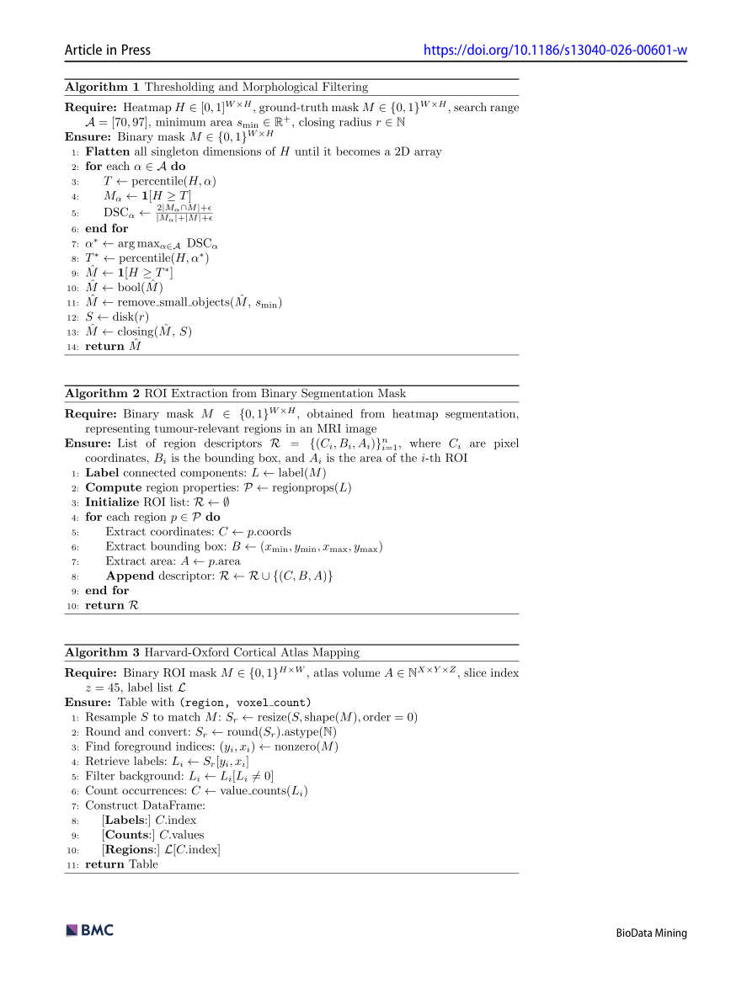


Article_28 | Page 13

EXTRACTED TEXT:
Page 13 of 19
Iftikhar et al. Brain Informatics           (2025) 12:10 
	
Fig. 5  Grad-Cam Results

ORIGINAL PDF PAGE:


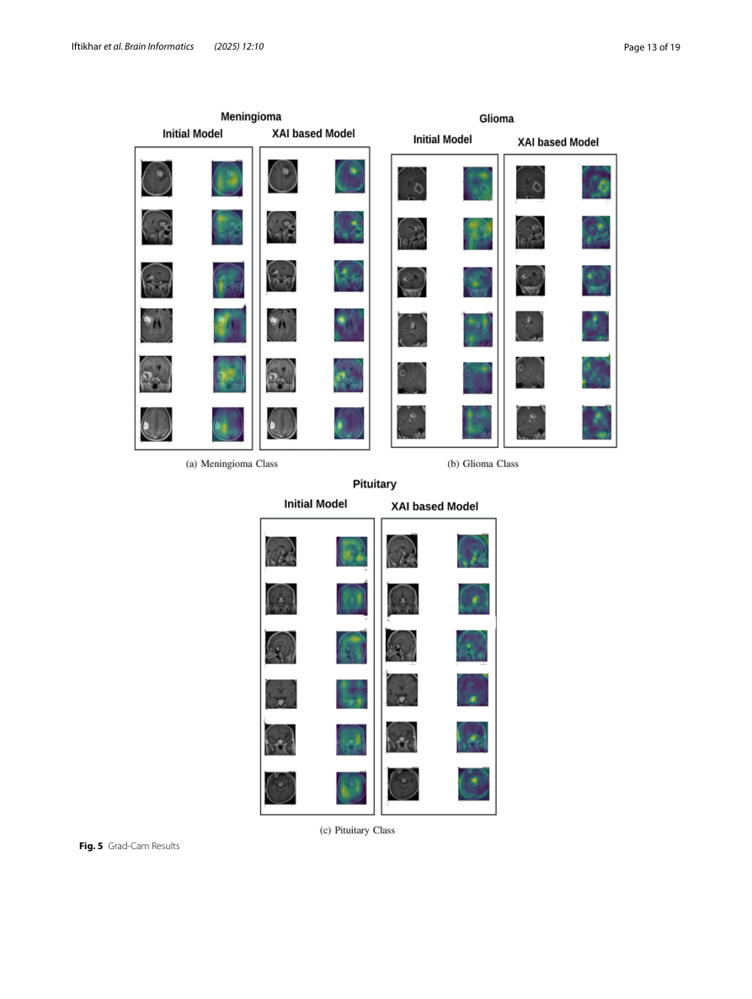


Article_115 | Page 10

EXTRACTED TEXT:
1 3
Neurosurgical Review (2022) 45:2503–2515
2512

ORIGINAL PDF PAGE:


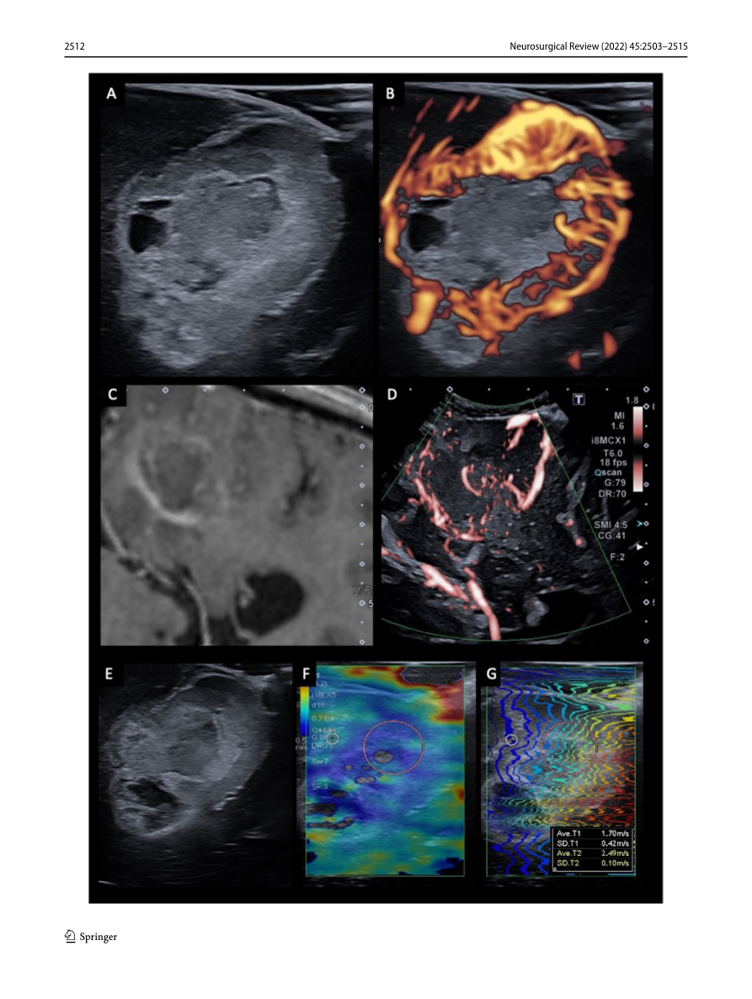


Article_161 | Page 10

EXTRACTED TEXT:
Article in Press
BioData Mining
https://doi.org/10.1186/s13040-026-00601-w

ORIGINAL PDF PAGE:


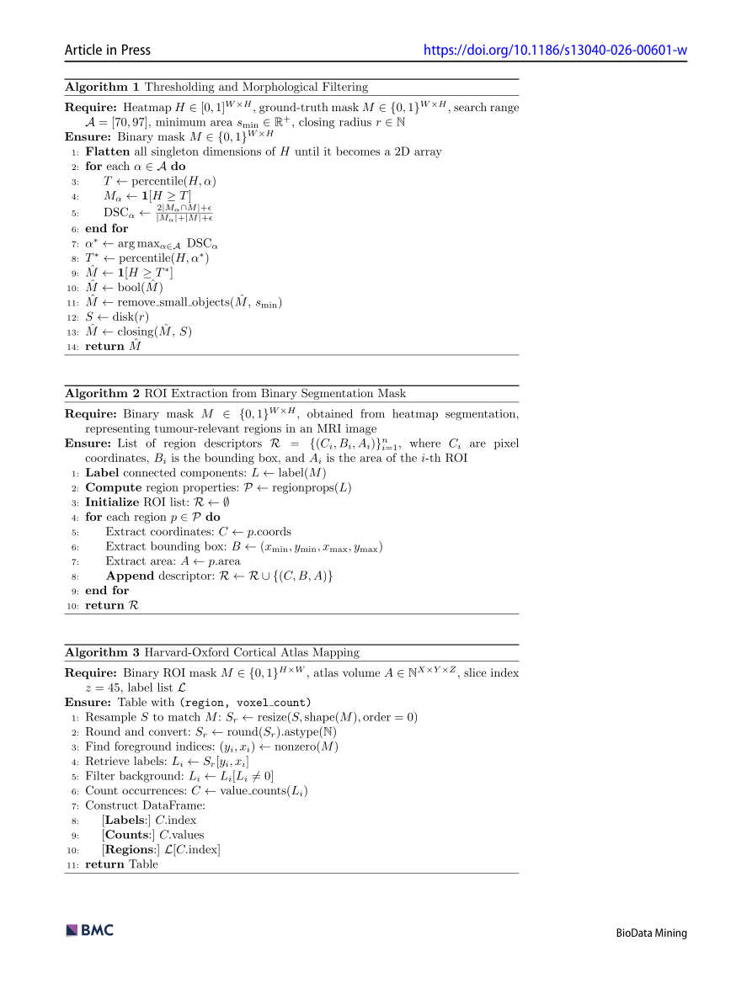


Article_191 | Page 17

EXTRACTED TEXT:
BRATS-MICCAI .
17

ORIGINAL PDF PAGE:


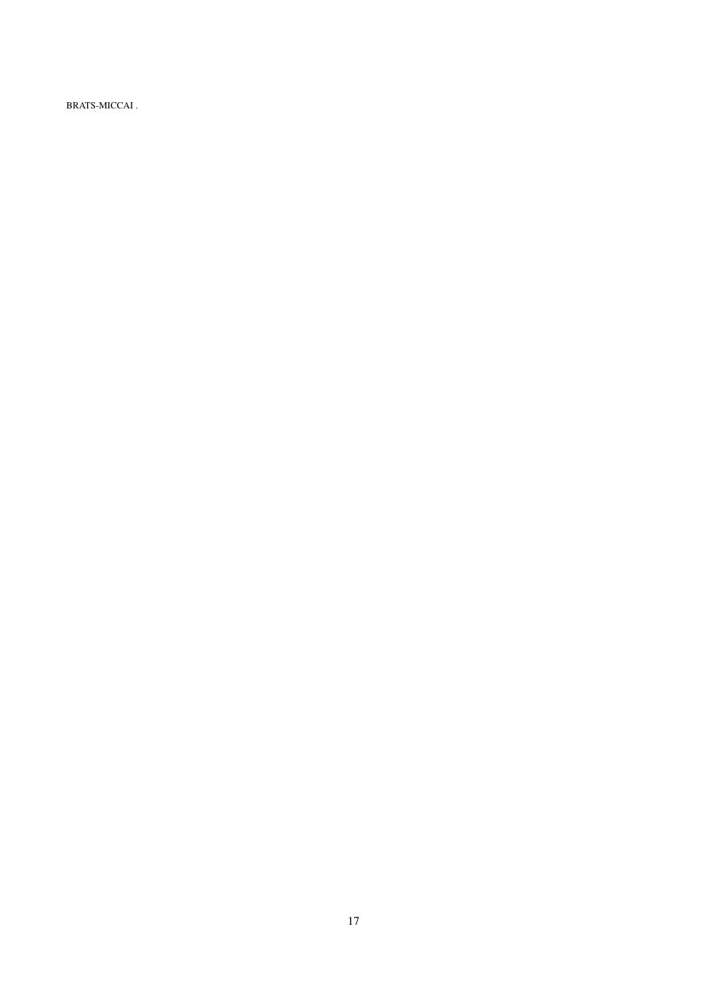

In [22]:
import pymupdf
from pathlib import Path
from PIL import Image
from IPython.display import display

PROJECT_DIR = Path.cwd()
PDF_DIR = PROJECT_DIR / "data" / "pdfs"

pages_to_review = [
    ("Article_26", 10),
    ("Article_28", 13),
    ("Article_115", 10),
    ("Article_161", 10),
    ("Article_191", 17)
]

for article_id, page_number in pages_to_review:

    pdf_path = PDF_DIR / f"{article_id}.pdf"

    print("\n" + "=" * 75)
    print(f"{article_id} | Page {page_number}")
    print("=" * 75)

    with pymupdf.open(pdf_path) as doc:

        page = doc[page_number - 1]

        # Display extracted text
        extracted_text = page.get_text("text").strip()

        print("\nEXTRACTED TEXT:")
        print(extracted_text if extracted_text else "[No text extracted]")

        # Render original PDF page
        pix = page.get_pixmap(
            matrix=pymupdf.Matrix(1.5, 1.5),
            alpha=False
        )

        image = Image.frombytes(
            "RGB",
            [pix.width, pix.height],
            pix.samples
        )

        print("\nORIGINAL PDF PAGE:")
        display(image)

## Create the image extraction folders

In [23]:
from pathlib import Path

PROJECT_DIR = Path.cwd()

PDF_DIR = PROJECT_DIR / "data" / "pdfs"
IMAGE_DIR = PROJECT_DIR / "data" / "images"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

IMAGE_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

print("PDF folder:", PDF_DIR)
print("Image folder:", IMAGE_DIR)
print("Artifact folder:", ARTIFACT_DIR)

PDF folder: /Users/macbookair/DAT401_Research_Assistant/data/pdfs
Image folder: /Users/macbookair/DAT401_Research_Assistant/data/images
Artifact folder: /Users/macbookair/DAT401_Research_Assistant/artifacts


## Extract images from all 187 PDFs

In [24]:
import pymupdf
import pandas as pd
from pathlib import Path
import hashlib

image_inventory = []
extraction_errors = []

eligible_data = pd.read_excel(
    PROJECT_DIR / "data" / "metadata" / "eligible_candidates.xlsx"
)

for _, row in eligible_data.iterrows():

    article_id = str(row["Article_ID"]).strip()
    pdf_path = PDF_DIR / f"{article_id}.pdf"

    article_image_dir = IMAGE_DIR / article_id
    article_image_dir.mkdir(parents=True, exist_ok=True)

    if not pdf_path.exists():
        extraction_errors.append({
            "Article_ID": article_id,
            "Error": "PDF not found"
        })
        continue

    try:
        with pymupdf.open(pdf_path) as doc:

            image_count = 0

            for page_index, page in enumerate(doc):

                page_number = page_index + 1
                images = page.get_images(full=True)

                for image_index, image_info in enumerate(images):

                    xref = image_info[0]

                    try:
                        extracted_image = doc.extract_image(xref)

                        image_bytes = extracted_image["image"]
                        image_extension = extracted_image["ext"]

                        image_hash = hashlib.md5(
                            image_bytes
                        ).hexdigest()

                        image_count += 1

                        image_filename = (
                            f"{article_id}_page_{page_number}_"
                            f"image_{image_index + 1}.{image_extension}"
                        )

                        image_path = article_image_dir / image_filename

                        with open(image_path, "wb") as file:
                            file.write(image_bytes)

                        image_inventory.append({
                            "Article_ID": article_id,
                            "Title": row["Title"],
                            "Page_number": page_number,
                            "Image_number": image_index + 1,
                            "Image_filename": image_filename,
                            "Image_path": str(image_path),
                            "Extension": image_extension,
                            "Width": extracted_image["width"],
                            "Height": extracted_image["height"],
                            "Image_size_KB": round(
                                len(image_bytes) / 1024, 2
                            ),
                            "Image_hash": image_hash
                        })

                    except Exception as image_error:

                        extraction_errors.append({
                            "Article_ID": article_id,
                            "Page_number": page_number,
                            "Error": str(image_error)
                        })

            print(
                f"{article_id}: {image_count} images extracted"
            )

    except Exception as e:

        extraction_errors.append({
            "Article_ID": article_id,
            "Error": str(e)
        })

print("\nIMAGE EXTRACTION COMPLETED")

Article_1: 43 images extracted
Article_2: 20 images extracted
Article_3: 26 images extracted
Article_4: 8 images extracted
Article_5: 12 images extracted
Article_6: 66 images extracted
Article_7: 12 images extracted
Article_8: 10 images extracted
Article_9: 69 images extracted
Article_10: 32 images extracted
Article_11: 8 images extracted
Article_12: 19 images extracted
Article_13: 24 images extracted
Article_14: 15 images extracted
Article_15: 5 images extracted
Article_16: 14 images extracted
Article_17: 101 images extracted
Article_18: 19 images extracted
Article_19: 6 images extracted
Article_20: 5 images extracted
Article_21: 15 images extracted
Article_22: 14 images extracted
Article_23: 13 images extracted
Article_24: 24 images extracted
Article_25: 19 images extracted
Article_26: 110 images extracted
Article_27: 11 images extracted
Article_28: 13 images extracted
Article_29: 9 images extracted
Article_30: 14 images extracted
Article_31: 9 images extracted
Article_33: 16 images 

## Save the image inventory

In [25]:
image_df = pd.DataFrame(image_inventory)

inventory_path = (
    ARTIFACT_DIR / "image_inventory.xlsx"
)

image_df.to_excel(
    inventory_path,
    index=False
)

error_df = pd.DataFrame(extraction_errors)

error_path = (
    ARTIFACT_DIR / "image_extraction_errors.xlsx"
)

error_df.to_excel(
    error_path,
    index=False
)

print("Total images extracted:", len(image_df))
print("Extraction errors:", len(error_df))

print("\nImage inventory saved:", inventory_path)
print("Error report saved:", error_path)

Total images extracted: 4625
Extraction errors: 0

Image inventory saved: /Users/macbookair/DAT401_Research_Assistant/artifacts/image_inventory.xlsx
Error report saved: /Users/macbookair/DAT401_Research_Assistant/artifacts/image_extraction_errors.xlsx


## Check the extraction results

In [26]:
print("Total research papers:", image_df["Article_ID"].nunique())
print("Total extracted images:", len(image_df))

print("\nImages by file type:")
display(image_df["Extension"].value_counts())

print("\nImages by article:")
display(
    image_df.groupby("Article_ID")
    .size()
    .sort_values(ascending=False)
    .head(15)
)

print("\nFirst 10 extracted images:")
display(image_df.head(10))

Total research papers: 187
Total extracted images: 4625

Images by file type:


Extension
png     2532
jpeg    2029
jpx       64
Name: count, dtype: int64


Images by article:


Article_ID
Article_146    648
Article_82     181
Article_92     162
Article_68     132
Article_64     121
Article_161    110
Article_26     110
Article_113    108
Article_17     101
Article_191     81
Article_190     78
Article_99      69
Article_9       69
Article_188     66
Article_6       66
dtype: int64


First 10 extracted images:


,Article_ID,Title,Page_number,Image_number,Image_filename,Image_path,Extension,Width,Height,Image_size_KB,Image_hash
0,Article_1,Robust clinical applicable CNN and U-Net based...,1,1,Article_1_page_1_image_1.png,/Users/macbookair/DAT401_Research_Assistant/da...,png,118,117,0.47,11b3cfe7e572151cdc60d9d141d311df
1,Article_1,Robust clinical applicable CNN and U-Net based...,1,2,Article_1_page_1_image_2.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,238,298,90.50,93d6c0b0e0c2038dad1f08e24b0f2f25
2,Article_1,Robust clinical applicable CNN and U-Net based...,1,3,Article_1_page_1_image_3.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,248,272,88.51,f59ebf23e323dde7797951b02cc0c64f
3,Article_1,Robust clinical applicable CNN and U-Net based...,5,1,Article_1_page_5_image_1.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,1657,2319,272.83,0d8a1810b40ef8c22533730c49b74115
4,Article_1,Robust clinical applicable CNN and U-Net based...,6,1,Article_1_page_6_image_1.png,/Users/macbookair/DAT401_Research_Assistant/da...,png,1584,580,103.33,89b9f0a8604397c27f4826fef986821e
5,Article_1,Robust clinical applicable CNN and U-Net based...,7,1,Article_1_page_7_image_1.png,/Users/macbookair/DAT401_Research_Assistant/da...,png,1301,651,221.00,7f8ec0d9444fe44d3f244a26695574f2
6,Article_1,Robust clinical applicable CNN and U-Net based...,7,2,Article_1_page_7_image_2.png,/Users/macbookair/DAT401_Research_Assistant/da...,png,1301,398,236.03,2f166bcaac7eec337fe6f23b7524b317
7,Article_1,Robust clinical applicable CNN and U-Net based...,8,1,Article_1_page_8_image_1.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,1857,996,312.40,e2f870a53c05e1602083ab5dde362073
8,Article_1,Robust clinical applicable CNN and U-Net based...,8,2,Article_1_page_8_image_2.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,1857,1575,466.98,4f3ed71004ee2a4bbaf4c1978650bc6c
9,Article_1,Robust clinical applicable CNN and U-Net based...,10,1,Article_1_page_10_image_1.jpeg,/Users/macbookair/DAT401_Research_Assistant/da...,jpeg,1856,753,190.82,32075d681b7acf4493f689f6f70c7d1a


## Display sample extracted images

Article_1 | Page 1 | 118 x 117


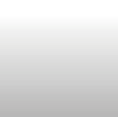

Article_1 | Page 1 | 238 x 298


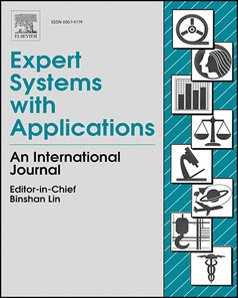

Article_1 | Page 1 | 248 x 272


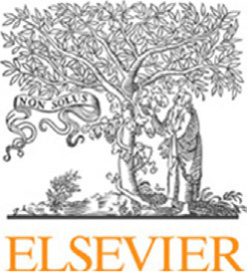

Article_1 | Page 5 | 1657 x 2319


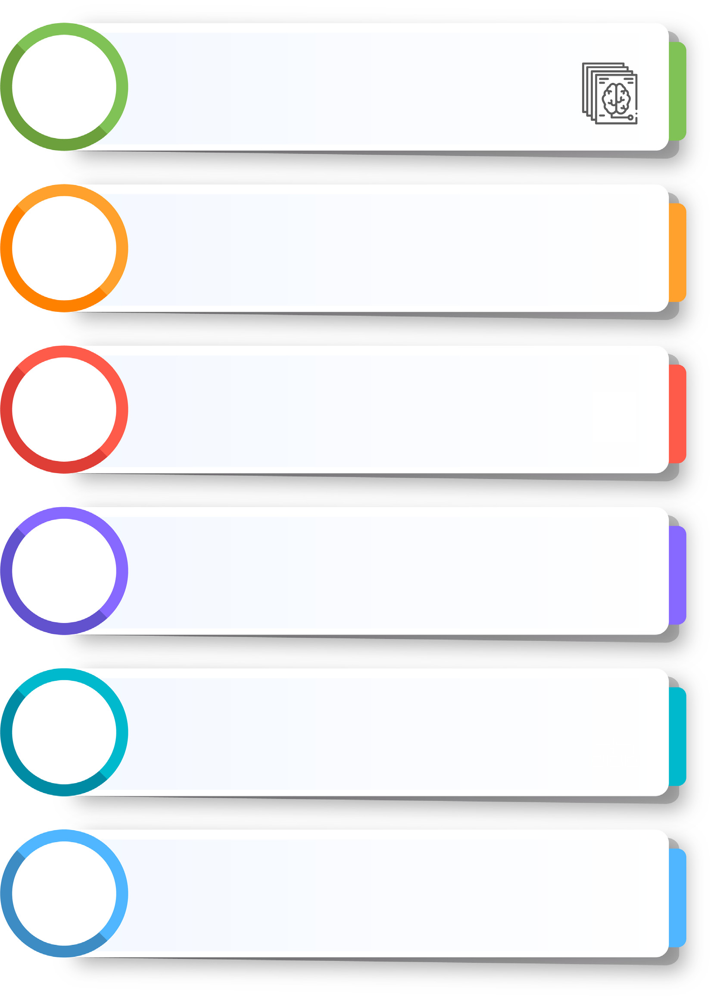

Article_1 | Page 6 | 1584 x 580


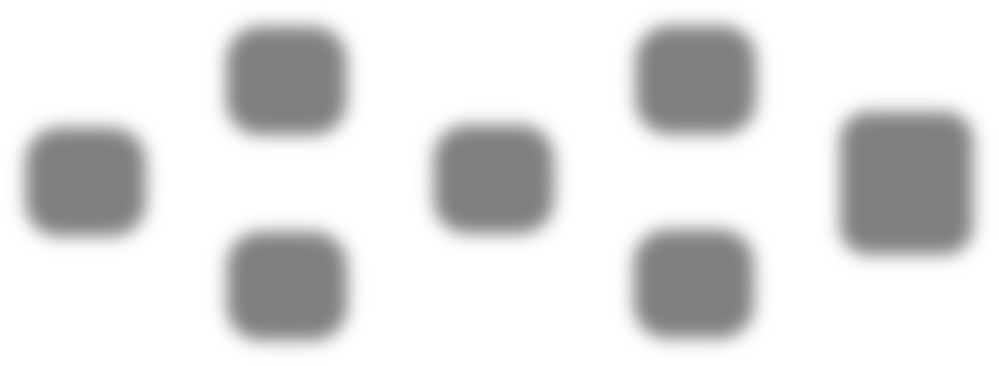

Article_1 | Page 7 | 1301 x 651


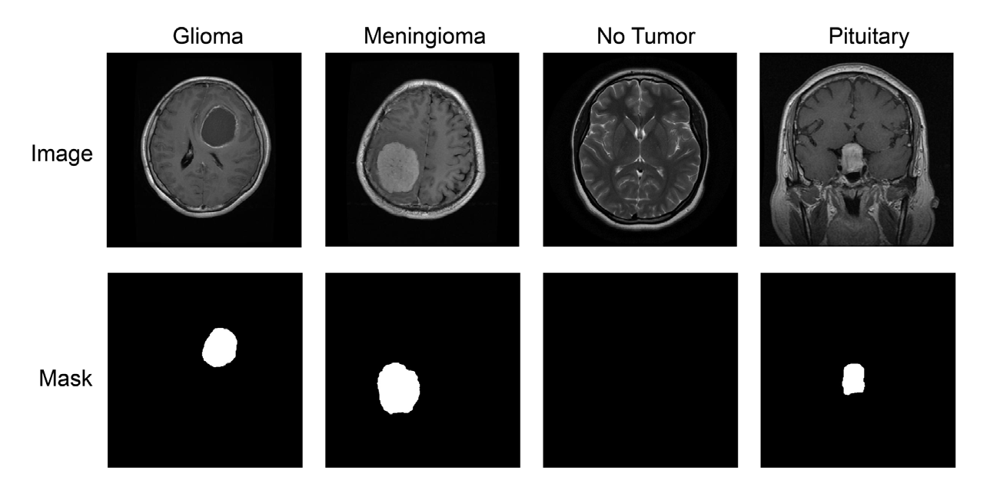

Article_1 | Page 7 | 1301 x 398


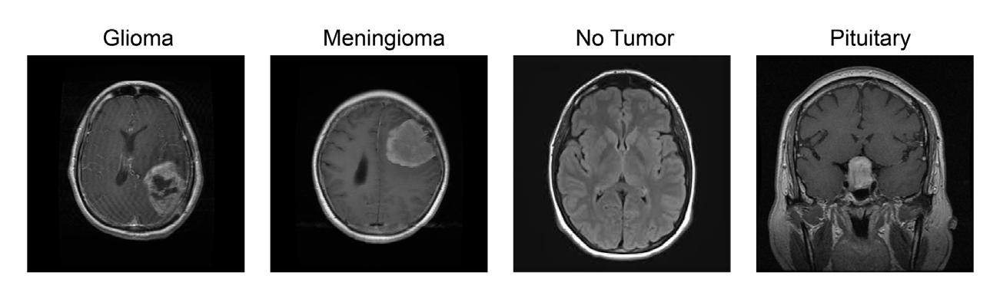

Article_1 | Page 8 | 1857 x 996


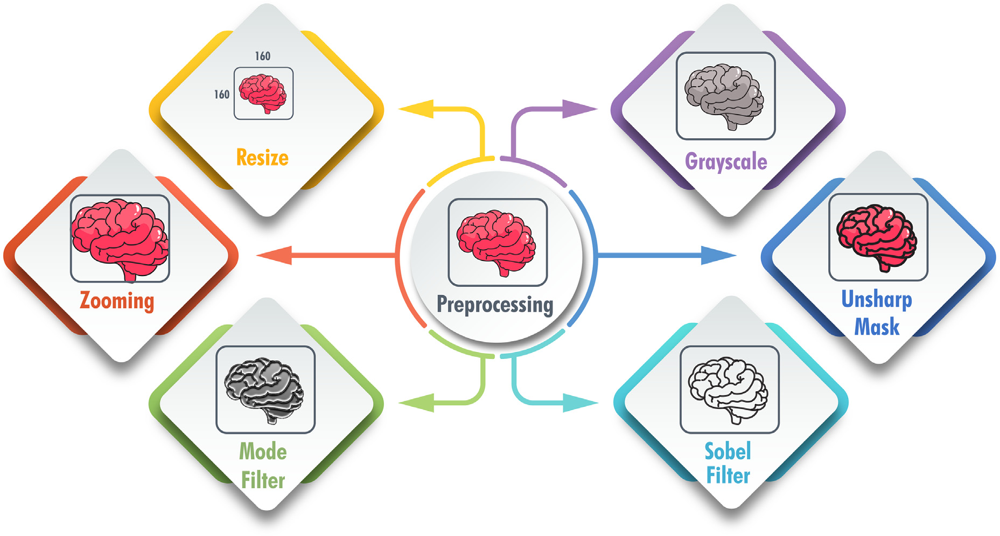

Article_1 | Page 8 | 1857 x 1575


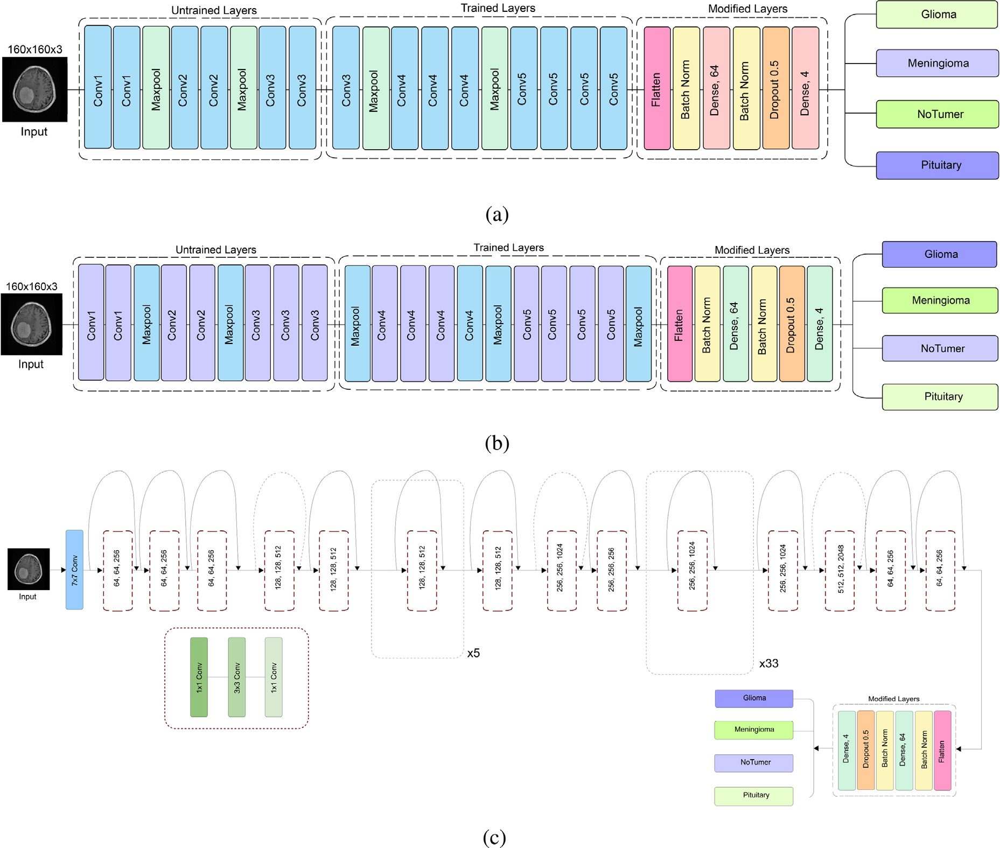

Article_1 | Page 10 | 1856 x 753


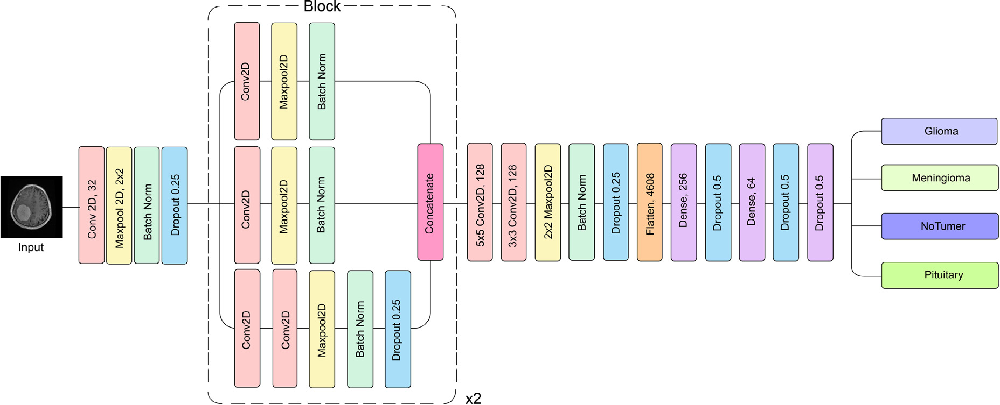

In [27]:
from PIL import Image
from IPython.display import display

sample_images = image_df.head(10)

for _, row in sample_images.iterrows():

    image_path = Path(row["Image_path"])

    try:
        img = Image.open(image_path)

        print(
            f"{row['Article_ID']} | "
            f"Page {row['Page_number']} | "
            f"{row['Width']} x {row['Height']}"
        )

        display(img)

    except Exception as e:
        print("Could not display:", image_path, e)

# Phase 2: Text preprocessing and intelligent chunking

### Load the extracted research corpus

In [28]:
import json
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path.cwd()

CORPUS_PATH = (
    PROJECT_DIR / "data" / "extracted" / "research_pages.jsonl"
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
ARTIFACT_DIR = PROJECT_DIR / "artifacts"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

page_records = []

with open(CORPUS_PATH, "r", encoding="utf-8") as file:

    for line in file:

        if line.strip():
            page_records.append(json.loads(line))

pages_df = pd.DataFrame(page_records)

print("Total extracted page records:", len(pages_df))
print("Unique research papers:", pages_df["article_id"].nunique())

print("\nAvailable columns:")
print(pages_df.columns.tolist())

display(pages_df.head())

Total extracted page records: 3631
Unique research papers: 187

Available columns:
['article_id', 'title', 'authors', 'year', 'venue', 'doi_or_url', 'page_number', 'text']


,article_id,title,authors,year,venue,doi_or_url,page_number,text
0,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,1,Contents lists available at ScienceDirect\nExp...
1,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,2,A. Akter et al.\nirregularly. Normal tissues c...
2,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,3,A. Akter et al.\ninto three classes: meningiom...
3,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,4,A. Akter et al.\nTable 1\nRecent research usin...
4,Article_1,Robust clinical applicable CNN and U-Net based...,Atika Akter; Nazeela Nosheen; Sabbir Ahmed; Ma...,2024,"Expert Systems with Applications, Volume 238, ...",https://doi.org/10.1016/j.eswa.2023.122347,5,A. Akter et al.\nFig. 1. The suggested methodo...


### Perform text quality checks

In [29]:
pages_df["text"] = (
    pages_df["text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

pages_df["character_count"] = (
    pages_df["text"].str.len()
)

print("Total page records:", len(pages_df))

print(
    "Empty text records:",
    (pages_df["character_count"] == 0).sum()
)

print(
    "Short text records (<150 characters):",
    (pages_df["character_count"] < 150).sum()
)

print(
    "Duplicate article-page records:",
    pages_df.duplicated(
        subset=["article_id", "page_number"]
    ).sum()
)

print("\nText length statistics:")
display(pages_df["character_count"].describe())

Total page records: 3631
Empty text records: 0
Short text records (<150 characters): 21
Duplicate article-page records: 0

Text length statistics:


count     3631.000000
mean      3709.979895
std       1974.813222
min         17.000000
25%       2254.500000
50%       3602.000000
75%       4894.000000
max      12763.000000
Name: character_count, dtype: float64

### Clean the extracted text

In [30]:
import re
import unicodedata

def clean_research_text(text):

    if not isinstance(text, str):
        return ""

    # Normalize Unicode characters
    text = unicodedata.normalize("NFKC", text)

    # Remove null characters
    text = text.replace("\x00", " ")

    # Normalize line endings
    text = text.replace("\r\n", "\n")
    text = text.replace("\r", "\n")

    # Remove excessive spaces
    text = re.sub(r"[ \t]+", " ", text)

    # Remove excessive line breaks
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()


pages_df["clean_text"] = (
    pages_df["text"].apply(clean_research_text)
)

print("Text cleaning completed.")

display(
    pages_df[
        ["article_id", "page_number", "clean_text"]
    ].head(5)
)

Text cleaning completed.


,article_id,page_number,clean_text
0,Article_1,1,Contents lists available at ScienceDirect\nExp...
1,Article_1,2,A. Akter et al.\nirregularly. Normal tissues c...
2,Article_1,3,A. Akter et al.\ninto three classes: meningiom...
3,Article_1,4,A. Akter et al.\nTable 1\nRecent research usin...
4,Article_1,5,A. Akter et al.\nFig. 1. The suggested methodo...


### Create the intelligent chunking function

In [31]:
import re

CHUNK_SIZE = 2500
CHUNK_OVERLAP = 400


def split_into_chunks(text):

    text = text.strip()

    if not text:
        return []

    chunks = []

    text_length = len(text)
    start = 0

    while start < text_length:

        target_end = min(
            start + CHUNK_SIZE,
            text_length
        )

        end = target_end

        if target_end < text_length:

            search_start = (
                start + int(CHUNK_SIZE * 0.70)
            )

            # Prefer paragraph boundaries
            paragraph_boundary = text.rfind(
                "\n",
                search_start,
                target_end
            )

            if paragraph_boundary != -1:

                end = paragraph_boundary

            else:

                # Otherwise prefer sentence boundaries
                sentence_matches = list(
                    re.finditer(
                        r'[.!?]\s+',
                        text[search_start:target_end]
                    )
                )

                if sentence_matches:

                    end = (
                        search_start
                        + sentence_matches[-1].end()
                    )

                else:

                    # Otherwise use a word boundary
                    word_boundary = text.rfind(
                        " ",
                        search_start,
                        target_end
                    )

                    if word_boundary != -1:
                        end = word_boundary

        # Ensure forward progress
        if end <= start:
            end = target_end

        chunk_text = text[start:end].strip()

        if chunk_text:

            chunks.append({
                "text": chunk_text,
                "char_start": start,
                "char_end": end
            })

        if end >= text_length:
            break

        # Move forward while retaining overlap
        start = max(
            start + 1,
            end - CHUNK_OVERLAP
        )

    return chunks

### Generate chunks for all 187 papers

In [32]:
chunk_records = []

for _, row in tqdm(
    pages_df.iterrows(),
    total=len(pages_df),
    desc="Regenerating research chunks"
):

    article_id = row["article_id"]
    page_number = int(row["page_number"])

    text = row["clean_text"]

    page_chunks = split_into_chunks(text)

    for chunk_index, chunk in enumerate(
        page_chunks,
        start=1
    ):

        chunk_id = (
            f"{article_id}_P{page_number}_C{chunk_index}"
        )

        chunk_records.append({

            "chunk_id": chunk_id,
            "article_id": article_id,
            "title": row["title"],
            "authors": row["authors"],
            "year": row["year"],
            "venue": row["venue"],
            "doi_or_url": row["doi_or_url"],
            "page_number": page_number,
            "chunk_index": chunk_index,
            "char_start": chunk["char_start"],
            "char_end": chunk["char_end"],
            "character_count": len(chunk["text"]),
            "text": chunk["text"]

        })


chunks_df = pd.DataFrame(chunk_records)

print("Total chunks:", len(chunks_df))
print("Unique papers:", chunks_df["article_id"].nunique())

Regenerating research chunks:   0%|          | 0/3631 [00:00<?, ?it/s]

Total chunks: 7608
Unique papers: 187


### Validate the generated chunks

In [33]:
print("========== FINAL CHUNK VALIDATION ==========")

print("Total chunks:", len(chunks_df))

print(
    "Unique chunk IDs:",
    chunks_df["chunk_id"].nunique()
)

print(
    "Duplicate chunk IDs:",
    chunks_df["chunk_id"].duplicated().sum()
)

print(
    "Empty chunks:",
    (chunks_df["text"].str.strip() == "").sum()
)

print(
    "Chunks above 2500 characters:",
    (chunks_df["character_count"] > CHUNK_SIZE).sum()
)

print(
    "Papers represented:",
    chunks_df["article_id"].nunique()
)

represented_pages = (
    chunks_df[
        ["article_id", "page_number"]
    ]
    .drop_duplicates()
)

original_pages = (
    pages_df[
        ["article_id", "page_number"]
    ]
    .drop_duplicates()
)

missing_pages = (
    original_pages.merge(
        represented_pages,
        on=["article_id", "page_number"],
        how="left",
        indicator=True
    )
)

missing_pages = missing_pages[
    missing_pages["_merge"] == "left_only"
]

print(
    "Pages represented:",
    len(represented_pages)
)

print(
    "Pages missing from chunks:",
    len(missing_pages)
)

display(missing_pages)

========== FINAL CHUNK VALIDATION ==========
Total chunks: 7608
Unique chunk IDs: 7608
Duplicate chunk IDs: 0
Empty chunks: 0
Chunks above 2500 characters: 0
Papers represented: 187
Pages represented: 3631
Pages missing from chunks: 0


,article_id,page_number,_merge


### Save the research chunks

In [34]:
CHUNK_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "research_chunks.jsonl"
)

with open(
    CHUNK_PATH,
    "w",
    encoding="utf-8"
) as file:

    for record in chunk_records:

        file.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )

chunks_df.drop(
    columns=["text"]
).to_excel(
    ARTIFACT_DIR / "chunking_report.xlsx",
    index=False
)

print("Corrected corpus saved:", CHUNK_PATH)

Corrected corpus saved: /Users/macbookair/DAT401_Research_Assistant/data/processed/research_chunks.jsonl


### Analyse chunk distribution

In [35]:
chunk_distribution = (
    chunks_df.groupby("article_id")
    .agg(
        Total_Chunks=("chunk_id", "count"),
        Average_Chunk_Size=("character_count", "mean"),
        Total_Characters=("character_count", "sum")
    )
    .reset_index()
)

chunk_distribution["Average_Chunk_Size"] = (
    chunk_distribution["Average_Chunk_Size"].round(2)
)

display(
    chunk_distribution.sort_values(
        "Total_Chunks",
        ascending=False
    ).head(20)
)

,article_id,Total_Chunks,Average_Chunk_Size,Total_Characters
101,Article_190,119,1718.13,204458
21,Article_118,115,2053.67,236172
91,Article_181,105,2159.11,226707
42,Article_137,105,2159.11,226707
99,Article_189,102,2212.41,225666
109,Article_23,95,1850.23,175772
46,Article_140,89,1984.64,176633
104,Article_193,89,1984.64,176633
35,Article_130,73,2224.88,162416
39,Article_134,72,2049.21,147543


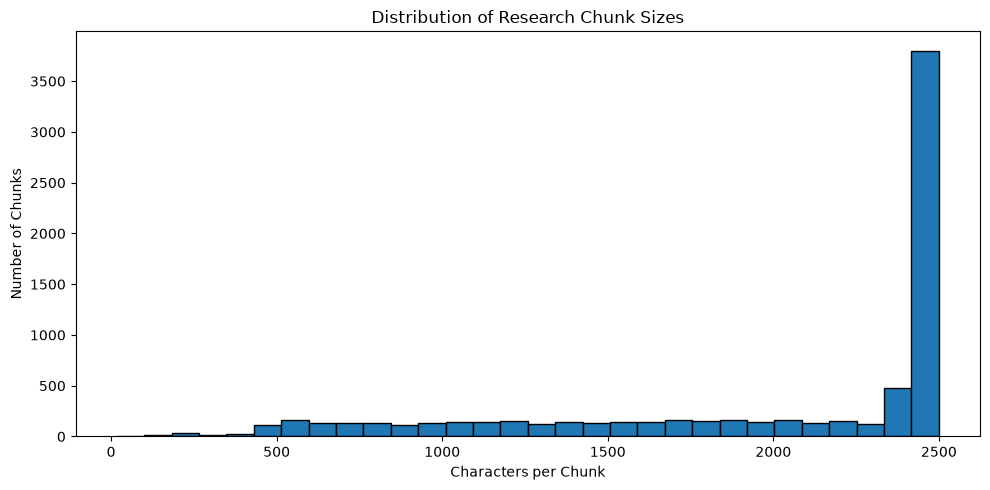

In [36]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    chunks_df["character_count"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Research Chunk Sizes")
plt.xlabel("Characters per Chunk")
plt.ylabel("Number of Chunks")

plt.tight_layout()
plt.show()

### Inspect sample chunks

In [37]:
sample_chunks = chunks_df.sample(
    min(5, len(chunks_df)),
    random_state=42
)

for _, row in sample_chunks.iterrows():

    print("\n" + "=" * 80)

    print("Chunk ID:", row["chunk_id"])
    print("Article:", row["article_id"])
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Chunk size:", row["character_count"])

    print("\nTEXT:")
    print(row["text"][:1200])

    print("\n" + "=" * 80)


Chunk ID: Article_68_P8_C1
Article: Article_68
Title: Brain Tumor Classification Using Res-BRNet
Page: 8
Chunk size: 2470

TEXT:
Biomedicines 2024, 12, 1395
8 of 19
Table 2. Cont.
Symbol
Description
Z
Output feature map
ZAvg
m,n
Output of average pooling
ZMax
m,n
Output of max pooling
Q
Output of dense layer
2.6. Benefits of the Proposed Res-BRNet for Image Content Analysis
Brain MRI scans reveal complex patterns with different intensity levels in distinct
regions. Regional smoothness, textural differences, and edges make the basic structure
of these patterns. In this study, the developed model is significantly improved by com-
bining the convolutional operator (Equation (9)), enhancing the region homogeneity and
boundary-based operations (Equations (10) and (11)), respectively, to differentiate the
healthy instances from the tumor-affected MRI scans. In contrast to the developed model,
the majority of existing CNN designs employ different convolutional combinations with
simply one ty

### Save the corrected corpus

In [38]:
CHUNK_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "research_chunks.jsonl"
)

with open(
    CHUNK_PATH,
    "w",
    encoding="utf-8"
) as file:

    for record in chunk_records:

        file.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )

chunks_df.drop(
    columns=["text"]
).to_excel(
    ARTIFACT_DIR / "chunking_report.xlsx",
    index=False
)

print("Corrected corpus saved:", CHUNK_PATH)

Corrected corpus saved: /Users/macbookair/DAT401_Research_Assistant/data/processed/research_chunks.jsonl


## Phase 3: Second Chunking Strategy – Heading-Aware Chunking

The first strategy uses fixed-size chunks with overlapping text.
The second strategy identifies likely research-paper section headings
and groups the text under those headings before splitting long sections.

Both strategies preserve article-level and page-level metadata.

In [39]:

# ============================================================
# PHASE 3: HEADING-AWARE CHUNKING
# CELL 1: IMPORT LIBRARIES AND CHECK PREREQUISITES
# ============================================================

import re
import pandas as pd
import json
from tqdm.auto import tqdm

# Check that previous phases have been completed
assert "pages_df" in globals(), (
    "pages_df is missing. Run the page preprocessing phase first."
)

assert "split_into_chunks" in globals(), (
    "split_into_chunks is missing. Run the fixed-size chunking phase first."
)

assert "CHUNK_SIZE" in globals(), (
    "CHUNK_SIZE is missing. Run the previous chunking phase first."
)

print("Prerequisites successfully checked.")
print("Total pages available:", len(pages_df))
print("Maximum chunk size:", CHUNK_SIZE)


Prerequisites successfully checked.
Total pages available: 3631
Maximum chunk size: 2500


In [40]:

# ============================================================
# CELL 2: DEFINE RESEARCH SECTION HEADINGS
# ============================================================

KNOWN_HEADINGS = {
    "ABSTRACT",
    "INTRODUCTION",
    "BACKGROUND",
    "THEORETICAL BACKGROUND",
    "RELATED WORK",
    "RELATED STUDIES",
    "LITERATURE REVIEW",
    "MATERIALS AND METHODS",
    "DATA AND METHODS",
    "METHODOLOGY",
    "METHODS",
    "PROPOSED METHOD",
    "EXPERIMENTAL SETUP",
    "EXPERIMENTS",
    "RESULTS",
    "RESULTS AND ANALYSIS",
    "DISCUSSION",
    "GENERAL DISCUSSION",
    "RESULTS AND DISCUSSION",
    "CONCLUSION",
    "CONCLUSIONS",
    "LIMITATIONS",
    "FUTURE WORK",
    "REFERENCES",
    "ACKNOWLEDGEMENTS",
    "ACKNOWLEDGMENTS"
}

print("Recognised research headings:", len(KNOWN_HEADINGS))


Recognised research headings: 26


In [41]:

# ============================================================
# CELL 3: NORMALISE HEADINGS
# ============================================================

def normalise_heading(line):

    # Remove leading/trailing spaces and extra whitespace
    line = re.sub(r"\s+", " ", str(line)).strip()

    if not line:
        return ""

    # Remove common numbering from the beginning of headings
    cleaned = re.sub(
        r"^\s*(?:\d+(?:\.\d+)*\.?|[IVXLCDM]+)[.)]?\s+",
        "",
        line,
        flags=re.IGNORECASE
    ).strip()

    # Compact text to handle headings with spaces between letters
    compact = re.sub(r"\s+", "", cleaned).upper()

    # Match recognised headings
    for heading in KNOWN_HEADINGS:
        if compact == re.sub(r"\s+", "", heading).upper():
            return heading.title()

    # Return a cleaned version of other headings
    return cleaned


In [42]:

# ============================================================
# CELL 4: HEADING DETECTION FUNCTION
# ============================================================

def is_section_heading(line):

    original_line = str(line).strip()
    heading = normalise_heading(original_line)

    if not heading:
        return False

    upper_heading = heading.upper()

    # Reject headings that are too long
    if len(heading) > 100 or len(heading.split()) > 12:
        return False

    # Ignore journal and document metadata
    if re.search(
        r"\b(VOLUME|VOL\.?|ISSUE|PAGES|DOI|ISSN|COPYRIGHT)\b",
        upper_heading
    ):
        return False

    # Ignore mathematical expressions
    if re.search(r"[+=<>]", heading):
        return False

    # 1. Accept recognised research headings
    if upper_heading in KNOWN_HEADINGS:
        return True

    # 2. Check numbered headings, such as:
    #    1 Dataset
    #    2.1 Data Collection
    #    3.2 Experimental Results

    numbered_match = re.match(
        r"^\s*\d+(?:\.\d+)*\.?\s+(.+?)\s*$",
        original_line
    )

    if numbered_match:

        heading_text = numbered_match.group(1).strip()

        # Reject table labels and identifiers
        if "_" in heading_text:
            return False

        if re.search(r"\d", heading_text):
            return False

        # Reject long text and sentence-like lines
        if (
            len(heading_text) > 80
            or len(heading_text.split()) > 10
            or re.search(r"[.!?]", heading_text)
        ):
            return False

        # Require a capital letter at the beginning
        if not heading_text[0].isupper():
            return False

        # Require alphabetic text
        if not re.search(r"[A-Za-z]", heading_text):
            return False

        return True

    return False


print("Heading detection function successfully created.")


Heading detection function successfully created.


In [43]:

# ============================================================
# CELL 5: SPLIT LONG SECTIONS INTO CHUNKS
# ============================================================

def split_long_section(section_text):

    section_text = section_text.strip()

    if not section_text:
        return []

    return split_into_chunks(section_text)


print("Section splitting function successfully created.")


Section splitting function successfully created.


In [44]:

# ============================================================
# CELL 6A: PREPARE HEADER AND METADATA CLEANING
# ============================================================

import re
import pandas as pd

# ------------------------------------------------------------
# 1. IDENTIFY REPEATED AUTHOR HEADERS
# ------------------------------------------------------------

author_header_pattern = re.compile(
    r"^[A-Z][A-Za-z.'’\-]*"
    r"(?:\s+[A-Z][A-Za-z.'’\-]*){0,5}"
    r"\s+(?i:et\s+al\.?)$"
)

author_edge_records = []

for _, row in pages_df.iterrows():

    text = row["clean_text"]

    if not isinstance(text, str) or not text.strip():
        continue

    lines = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    if not lines:
        continue

    edge_lines = [lines[0], lines[-1]]

    for line in set(edge_lines):

        if author_header_pattern.fullmatch(line):

            author_edge_records.append({
                "article_id": str(row["article_id"]),
                "page_number": row["page_number"],
                "line": line
            })


author_edge_df = pd.DataFrame(author_edge_records)

if not author_edge_df.empty:

    author_frequency = (
        author_edge_df
        .groupby(["article_id", "line"])
        .agg(pages_found=("page_number", "nunique"))
        .reset_index()
    )

    confirmed_author_headers = set(
        (
            str(row["article_id"]),
            row["line"].strip().casefold()
        )
        for _, row in author_frequency.iterrows()
        if row["pages_found"] >= 2
    )

else:

    confirmed_author_headers = set()


# ------------------------------------------------------------
# 2. IDENTIFY REPEATED JOURNAL HEADERS
# ------------------------------------------------------------

journal_keywords = [
    "insights into imaging",
    "cancer imaging",
    "brain sci.",
    "computers"
]

journal_header_records = []

for _, row in pages_df.iterrows():

    text = row["clean_text"]

    if not isinstance(text, str) or not text.strip():
        continue

    lines = [
        line.strip()
        for line in text.splitlines()
        if line.strip()
    ]

    edge_lines = lines[:3] + lines[-3:]

    for line in set(edge_lines):

        if any(
            keyword in line.casefold()
            for keyword in journal_keywords
        ):

            journal_header_records.append({
                "article_id": str(row["article_id"]),
                "page_number": row["page_number"],
                "line": line
            })


journal_header_df = pd.DataFrame(journal_header_records)

if not journal_header_df.empty:

    journal_frequency = (
        journal_header_df
        .groupby(["article_id", "line"])
        .agg(pages_found=("page_number", "nunique"))
        .reset_index()
    )

    confirmed_journal_headers = set(
        (
            str(row["article_id"]),
            row["line"].strip().casefold()
        )
        for _, row in journal_frequency.iterrows()
        if row["pages_found"] >= 2
    )

else:

    confirmed_journal_headers = set()


# ------------------------------------------------------------
# 3. DEFINE PUBLISHER METADATA PATTERNS
# ------------------------------------------------------------

publisher_patterns = [

    re.compile(
        r"^page\s+\d+\s+of\s+\d+$",
        re.IGNORECASE
    ),

    re.compile(
        r"^\d+\s+of\s+\d+$",
        re.IGNORECASE
    ),

    re.compile(
        r"^contents lists available at sciencedirect.*$",
        re.IGNORECASE
    ),

    re.compile(
        r"^[A-Za-z][A-Za-z .,&-]*"
        r"\(\d{4}\),\s*\d+\s*,\s*\d+.*$",
        re.IGNORECASE
    )
]


# ------------------------------------------------------------
# 4. CREATE PUBLISHER METADATA CLEANING FUNCTION
# ------------------------------------------------------------

def is_publisher_metadata_line(line):

    line = str(line).strip()

    if not line:
        return False

    return any(
        pattern.fullmatch(line)
        for pattern in publisher_patterns
    )


# ------------------------------------------------------------
# 5. DISPLAY CLEANING SETUP RESULTS
# ------------------------------------------------------------

print("========== HEADER CLEANING SETUP ==========")

print(
    "Confirmed repeated author headers:",
    len(confirmed_author_headers)
)

print(
    "Confirmed repeated journal headers:",
    len(confirmed_journal_headers)
)

print(
    "Publisher metadata patterns:",
    len(publisher_patterns)
)

print(
    "Publisher metadata cleaning function:",
    "Created"
)

print("\nCleaning setup completed successfully.")


========== HEADER CLEANING SETUP ==========
Confirmed repeated author headers: 14
Confirmed repeated journal headers: 8
Publisher metadata patterns: 4
Publisher metadata cleaning function: Created

Cleaning setup completed successfully.


In [45]:

# ============================================================
# CELL 6: FINAL CLEAN HEADING-AWARE CHUNKING
# ============================================================

section_chunk_records = []

# Check that all required cleaning variables exist
assert "confirmed_author_headers" in globals(), \
    "Run Cell 8D cleaning diagnostics first."

assert "confirmed_journal_headers" in globals(), \
    "Run Cell 8I first."

assert "publisher_patterns" in globals(), \
    "Run Cell 8E first."

assert "pages_df" in globals(), \
    "pages_df is missing."

assert "split_long_section" in globals(), \
    "Section splitting function is missing."


# Process each article separately
for article_id, article_pages in tqdm(
    pages_df.groupby("article_id", sort=False),
    desc="Processing articles"
):

    article_pages = article_pages.sort_values(
        "page_number",
        kind="stable"
    )

    # Carry the last detected heading across pages
    current_article_heading = "Unlabelled / Continued Section"

    for _, row in article_pages.iterrows():

        text = row["clean_text"]

        if not isinstance(text, str) or not text.strip():
            continue

        clean_lines = []

        # ----------------------------------------------------
        # REMOVE CONFIRMED HEADERS AND PUBLISHER METADATA
        # ----------------------------------------------------

        for line in text.splitlines():

            line = line.strip()

            if not line:
                continue

            header_key = (
                str(article_id),
                line.casefold()
            )

            # Remove confirmed repeated author headers
            if header_key in confirmed_author_headers:
                continue

            # Remove confirmed repeated journal headers
            if header_key in confirmed_journal_headers:
                continue

            # Remove exact publisher metadata lines
            if is_publisher_metadata_line(line):
                continue

            clean_lines.append(line)

        # Skip pages containing only metadata
        if not clean_lines:
            continue

        # ----------------------------------------------------
        # DETECT SECTIONS
        # ----------------------------------------------------

        sections = []

        current_heading = current_article_heading
        current_content = []

        for line in clean_lines:

            if is_section_heading(line):

                # Save the previous section
                if current_content:

                    sections.append({
                        "heading": current_heading,
                        "text": "\n".join(current_content)
                    })

                # Start a new section
                current_heading = normalise_heading(line)

                current_content = [current_heading]

            else:

                current_content.append(line)

        # Save the final section
        if current_content:

            sections.append({
                "heading": current_heading,
                "text": "\n".join(current_content)
            })

        # Preserve heading for the next page
        current_article_heading = current_heading

        # ----------------------------------------------------
        # GENERATE CHUNKS
        # ----------------------------------------------------

        for section_number, section in enumerate(
            sections,
            start=1
        ):

            section_text = section["text"].strip()

            section_chunks = split_long_section(section_text)

            for chunk_index, chunk in enumerate(
                section_chunks,
                start=1
            ):

                chunk_text = chunk["text"].strip()

                if not chunk_text:
                    continue

                section_chunk_records.append({

                    "chunk_id": (
                        f"{row['article_id']}_P"
                        f"{int(row['page_number'])}_S"
                        f"{section_number}_C{chunk_index}"
                    ),

                    "article_id": row["article_id"],
                    "title": row["title"],
                    "authors": row["authors"],
                    "year": row["year"],
                    "venue": row["venue"],
                    "doi_or_url": row["doi_or_url"],

                    "page_number": int(row["page_number"]),
                    "section_number": section_number,
                    "section_heading": section["heading"],

                    "character_count": len(chunk_text),
                    "text": chunk_text
                })


# ============================================================
# CREATE FINAL HEADING-AWARE DATAFRAME
# ============================================================

section_chunks_df = pd.DataFrame(section_chunk_records)


# ============================================================
# DISPLAY RESULTS
# ============================================================

print("\n========== FINAL CLEAN CHUNKING RESULTS ==========")

print("Total chunks:", len(section_chunks_df))

print(
    "Unique articles:",
    section_chunks_df["article_id"].nunique()
)

print(
    "Unique chunk IDs:",
    section_chunks_df["chunk_id"].nunique()
)

print("\nMost common section headings:")

display(
    section_chunks_df["section_heading"]
    .value_counts()
    .head(20)
)


Processing articles:   0%|          | 0/187 [00:00<?, ?it/s]


========== FINAL CLEAN CHUNKING RESULTS ==========
Total chunks: 9793
Unique articles: 187
Unique chunk IDs: 9793

Most common section headings:


section_heading
References                        1249
Introduction                       787
Unlabelled / Continued Section     538
Discussion                         440
Results                            333
Methodology                        260
Related Work                       238
Conclusion                         225
Materials And Methods              211
Abstract                           209
Methods                            208
Limitations                        128
MRI images                         123
Results And Discussion             119
Literature Review                  111
Conclusions                         96
Proposed Method                     73
Experimental Setup                  63
Acknowledgments                     58
Acknowledgements                    52
Name: count, dtype: int64

In [46]:

# ============================================================
# CELL 7: VALIDATE HEADING-AWARE CHUNKS
# ============================================================

print("========== HEADING-AWARE VALIDATION ==========")

print("Total chunks:", len(section_chunks_df))

print(
    "Duplicate chunk IDs:",
    section_chunks_df["chunk_id"].duplicated().sum()
)

print(
    "Empty chunks:",
    section_chunks_df["text"].fillna("").str.strip().eq("").sum()
)

print(
    "Chunks above maximum size:",
    (section_chunks_df["character_count"] > CHUNK_SIZE).sum()
)

print(
    "Unique articles:",
    section_chunks_df["article_id"].nunique()
)

print(
    "Pages represented:",
    section_chunks_df[
        ["article_id", "page_number"]
    ].drop_duplicates().shape[0]
)

print("\nMost common detected headings:")

display(
    section_chunks_df["section_heading"]
    .value_counts()
    .head(20)
)

print("\nSample heading-aware chunks:")

display(
    section_chunks_df[
        [
            "article_id",
            "page_number",
            "section_heading",
            "character_count",
            "text"
        ]
    ].head(5)
)


========== HEADING-AWARE VALIDATION ==========
Total chunks: 9793
Duplicate chunk IDs: 0
Empty chunks: 0
Chunks above maximum size: 0
Unique articles: 187
Pages represented: 3631

Most common detected headings:


section_heading
References                        1249
Introduction                       787
Unlabelled / Continued Section     538
Discussion                         440
Results                            333
Methodology                        260
Related Work                       238
Conclusion                         225
Materials And Methods              211
Abstract                           209
Methods                            208
Limitations                        128
MRI images                         123
Results And Discussion             119
Literature Review                  111
Conclusions                         96
Proposed Method                     73
Experimental Setup                  63
Acknowledgments                     58
Acknowledgements                    52
Name: count, dtype: int64


Sample heading-aware chunks:


,article_id,page_number,section_heading,character_count,text
0,Article_1,1,Unlabelled / Continued Section,1197,Expert Systems With Applications\njournal home...
1,Article_1,1,Abstract,1537,Abstract\nEarly diagnosis of brain tumors is c...
2,Article_1,1,Introduction,2191,Introduction\nThe most prevalent form of brain...
3,Article_1,2,Introduction,2492,"irregularly. Normal tissues can be compressed,..."
4,Article_1,2,Introduction,2433,. Segmentation methods are used before classi-...


In [47]:

# ============================================================
# FINAL CHUNKING VALIDATION
# ============================================================

# 1. IDENTIFY THE IMPORTANT COLUMNS
required_columns = ["chunk_id", "article_id"]
missing_columns = [
    col for col in required_columns
    if col not in section_chunks_df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

text_col = next(
    (col for col in ["chunk_text", "text", "content"]
     if col in section_chunks_df.columns),
    None
)

if text_col is None:
    raise ValueError(
        "Could not identify the chunk text column. "
        f"Available columns: {section_chunks_df.columns.tolist()}"
    )

# 2. CHECK CHUNK QUALITY
chunk_lengths = section_chunks_df[text_col].fillna("").astype(str).str.len()

total_chunks = len(section_chunks_df)
duplicate_ids = section_chunks_df["chunk_id"].duplicated().sum()
empty_chunks = (chunk_lengths == 0).sum()
oversized_chunks = (chunk_lengths > CHUNK_SIZE).sum()
short_chunks = section_chunks_df[chunk_lengths < 100].copy()

# 3. CHECK REMAINING HEADERS AND PUBLISHER METADATA
remaining_author_headers = 0
remaining_journal_headers = 0
remaining_publisher_lines = 0

for _, row in section_chunks_df.iterrows():
    article_id = str(row["article_id"])
    chunk_text = str(row[text_col])

    for line in chunk_text.splitlines():
        line = line.strip()
        if not line:
            continue

        line_key = (article_id, line.casefold())

        if line_key in confirmed_author_headers:
            remaining_author_headers += 1

        if line_key in confirmed_journal_headers:
            remaining_journal_headers += 1

        if is_publisher_metadata_line(line):
            remaining_publisher_lines += 1

# 4. DISPLAY FINAL RESULTS
print("========== FINAL CHUNKING VALIDATION ==========")
print("Total chunks:", total_chunks)
print("Duplicate chunk IDs:", duplicate_ids)
print("Empty chunks:", empty_chunks)
print("Chunks above maximum size:", oversized_chunks)
print("Unique articles:", section_chunks_df["article_id"].nunique())
print("Pages represented:", len(pages_df))
print("Remaining publisher metadata lines:", remaining_publisher_lines)
print("Remaining confirmed author headers:", remaining_author_headers)
print("Remaining confirmed journal headers:", remaining_journal_headers)
print("Chunks shorter than 100 characters:", len(short_chunks))

# 5. INSPECT SHORT CHUNKS
print("\n========== SHORT CHUNK SAMPLES ==========")

preview_columns = [
    col for col in
    ["chunk_id", "article_id", "section_heading", text_col]
    if col in short_chunks.columns
]

display(short_chunks[preview_columns].head(20))


========== FINAL CHUNKING VALIDATION ==========
Total chunks: 9793
Duplicate chunk IDs: 0
Empty chunks: 0
Chunks above maximum size: 0
Unique articles: 187
Pages represented: 3631
Remaining publisher metadata lines: 0
Remaining confirmed author headers: 0
Remaining confirmed journal headers: 0
Chunks shorter than 100 characters: 433

========== SHORT CHUNK SAMPLES ==========


,chunk_id,article_id,section_heading,text
198,Article_4_P2_S1_C1,Article_4,Abstract,Graphical Abstract
206,Article_4_P5_S1_C1,Article_4,Materials And Methods,"a 2D input, a batch size of 40, and initial le..."
322,Article_7_P3_S2_C1,Article_7,Limitations,Limitations\nComputational\nefficiency\nOthman...
334,Article_7_P3_S14_C1,Article_7,MRI images,MRI images\n93.68% accuracy\nFast training\nLa...
395,Article_8_P3_S3_C1,Article_8,Encephalomalacia,Encephalomalacia
396,Article_8_P3_S4_C1,Article_8,Epidural and subdural hemorrhage,Epidural and subdural hemorrhage
397,Article_8_P3_S5_C1,Article_8,Inflammatory demyelination,Inflammatory demyelination
398,Article_8_P3_S6_C1,Article_8,Normal,Normal
399,Article_8_P3_S7_C1,Article_8,Subarachnoid hemorrhage,Subarachnoid hemorrhage
400,Article_8_P3_S8_C1,Article_8,Subdural effusion,Subdural effusion


In [48]:

# ============================================================
# CELL 9: COMPARE CHUNKING STRATEGIES
# ============================================================

chunk_comparison = pd.DataFrame({

    "Strategy": [
        "Fixed-size with overlap",
        "Heading-aware"
    ],

    "Total_chunks": [
        len(chunks_df),
        len(section_chunks_df)
    ],

    "Unique_articles": [
        chunks_df["article_id"].nunique(),
        section_chunks_df["article_id"].nunique()
    ],

    "Average_chunk_size": [
        chunks_df["character_count"].mean(),
        section_chunks_df["character_count"].mean()
    ],

    "Maximum_chunk_size": [
        chunks_df["character_count"].max(),
        section_chunks_df["character_count"].max()
    ],

    "Minimum_chunk_size": [
        chunks_df["character_count"].min(),
        section_chunks_df["character_count"].min()
    ],

    "Chunks_below_100_characters": [
        (chunks_df["character_count"] < 100).sum(),
        (section_chunks_df["character_count"] < 100).sum()
    ],

    "Duplicate_chunk_IDs": [
        chunks_df["chunk_id"].duplicated().sum(),
        section_chunks_df["chunk_id"].duplicated().sum()
    ],

    "Empty_chunks": [
        chunks_df["text"].fillna("").str.strip().eq("").sum(),
        section_chunks_df["text"].fillna("").str.strip().eq("").sum()
    ]

})

print("========== CHUNKING STRATEGY COMPARISON ==========")

display(chunk_comparison.round(2))


========== CHUNKING STRATEGY COMPARISON ==========


,Strategy,Total_chunks,Unique_articles,Average_chunk_size,Maximum_chunk_size,Minimum_chunk_size,Chunks_below_100_characters,Duplicate_chunk_IDs,Empty_chunks
0,Fixed-size with overlap,7608,187,1980.71,2500,17,5,0,0
1,Heading-aware,9793,187,1477.56,2500,2,433,0,0


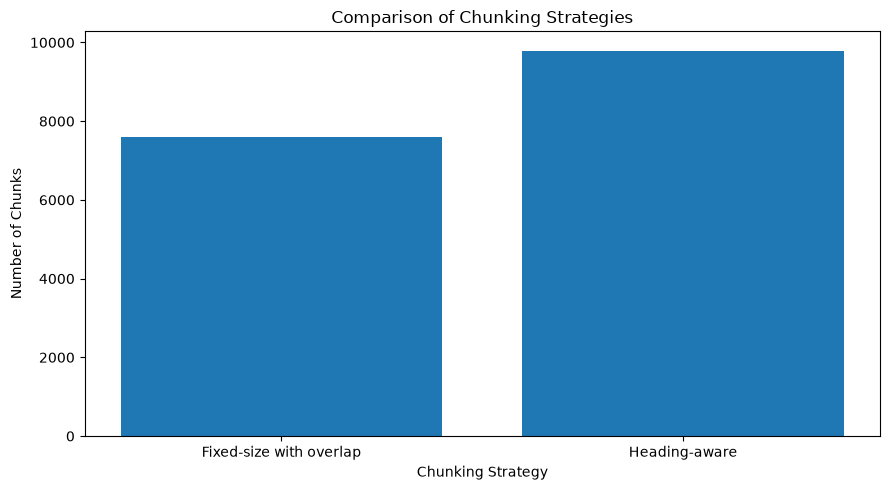

In [49]:

# ============================================================
# CELL 10: VISUALISE CHUNKING COMPARISON
# ============================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    chunk_comparison["Strategy"],
    chunk_comparison["Total_chunks"]
)

plt.title("Comparison of Chunking Strategies")
plt.xlabel("Chunking Strategy")
plt.ylabel("Number of Chunks")

plt.tight_layout()
plt.show()


In [50]:

# ============================================================
# CELL 11: SAVE HEADING-AWARE CHUNKS
# ============================================================

SECTION_CHUNK_PATH = (
    PROJECT_DIR
    / "data"
    / "processed"
    / "research_chunks_heading_aware.jsonl"
)

SECTION_CHUNK_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

with open(
    SECTION_CHUNK_PATH,
    "w",
    encoding="utf-8"
) as file:

    for record in section_chunk_records:

        file.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )


# Save comparison report
chunk_comparison.to_excel(
    ARTIFACT_DIR / "chunking_strategy_comparison.xlsx",
    index=False
)

print("Heading-aware chunks saved:", SECTION_CHUNK_PATH)

print(
    "Comparison report saved:",
    ARTIFACT_DIR / "chunking_strategy_comparison.xlsx"
)


Heading-aware chunks saved: /Users/macbookair/DAT401_Research_Assistant/data/processed/research_chunks_heading_aware.jsonl
Comparison report saved: /Users/macbookair/DAT401_Research_Assistant/artifacts/chunking_strategy_comparison.xlsx


### PHASE 4: RETRIEVAL SYSTEM DEVELOPMENT
The next stage is to build the retrieval system that allows your research assistant to find relevant information from the 187 research articles.

In [51]:

# ============================================================
# PHASE 4: RETRIEVAL SYSTEM DEVELOPMENT
# CELL 1: INSTALL REQUIRED LIBRARIES
# ============================================================

%pip install -q sentence-transformers rank-bm25


Note: you may need to restart the kernel to use updated packages.


In [52]:

# ============================================================
# CELL 2: IMPORT LIBRARIES AND PREPARE DATASET
# ============================================================

import re
import numpy as np
import pandas as pd
import torch

from rank_bm25 import BM25Okapi
from sentence_transformers import SentenceTransformer, CrossEncoder
from tqdm.auto import tqdm

# Use heading-aware chunks as the main retrieval dataset
retrieval_df = section_chunks_df.copy()

# Remove empty text records
retrieval_df = retrieval_df[
    retrieval_df["text"].notna()
].copy()

retrieval_df["text"] = retrieval_df["text"].astype(str)

retrieval_df = retrieval_df[
    retrieval_df["text"].str.strip().ne("")
].reset_index(drop=True)

# Check dataset
print("========== RETRIEVAL DATASET ==========")

print("Total chunks:", len(retrieval_df))

print(
    "Unique articles:",
    retrieval_df["article_id"].nunique()
)

print(
    "Missing article IDs:",
    retrieval_df["article_id"].isna().sum()
)

print(
    "Missing chunk IDs:",
    retrieval_df["chunk_id"].isna().sum()
)

print("\nSample records:")

display(
    retrieval_df[
        [
            "chunk_id",
            "article_id",
            "section_heading",
            "text"
        ]
    ].head(3)
)


W1118 08:33:02.783000 1266 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


========== RETRIEVAL DATASET ==========
Total chunks: 9793
Unique articles: 187
Missing article IDs: 0
Missing chunk IDs: 0

Sample records:


,chunk_id,article_id,section_heading,text
0,Article_1_P1_S1_C1,Article_1,Unlabelled / Continued Section,Expert Systems With Applications\njournal home...
1,Article_1_P1_S2_C1,Article_1,Abstract,Abstract\nEarly diagnosis of brain tumors is c...
2,Article_1_P1_S3_C1,Article_1,Introduction,Introduction\nThe most prevalent form of brain...


In [53]:

# ============================================================
# CELL 3: BM25 KEYWORD RETRIEVAL
# ============================================================

def tokenize_text(text):

    return re.findall(
        r"\b\w+\b",
        str(text).lower()
    )


# Tokenise all document chunks
bm25_corpus = [
    tokenize_text(text)
    for text in tqdm(
        retrieval_df["text"],
        desc="Tokenising documents"
    )
]

# Build BM25 index
bm25_index = BM25Okapi(bm25_corpus)

print("BM25 index successfully created.")
print("Indexed documents:", len(bm25_corpus))


Tokenising documents:   0%|          | 0/9793 [00:00<?, ?it/s]

BM25 index successfully created.
Indexed documents: 9793


In [54]:

# ============================================================
# CELL 4: TEST BM25 RETRIEVAL
# ============================================================

def bm25_search(query, top_k=5):

    query_tokens = tokenize_text(query)

    scores = bm25_index.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = retrieval_df.iloc[top_indices].copy()

    results["retrieval_score"] = scores[top_indices]

    results["rank"] = range(1, len(results) + 1)

    return results


# Example research question
test_query = (
    "What machine learning methods are used "
    "for brain tumour detection?"
)

bm25_results = bm25_search(
    test_query,
    top_k=5
)

display(
    bm25_results[
        [
            "rank",
            "article_id",
            "section_heading",
            "retrieval_score",
            "text"
        ]
    ]
)
# Inspect complete BM25 search results

for _, row in bm25_results.iterrows():
    print("\n" + "=" * 80)
    print("Rank:", row["rank"])
    print("Article:", row["article_id"])
    print("Section:", row["section_heading"])
    print("BM25 Score:", round(row["retrieval_score"], 4))
    print("\nRetrieved text:")
    print(row["text"])

,rank,article_id,section_heading,retrieval_score,text
9368,1,Article_189,Data analysis and results,19.678317,Data analysis and results\nThis section provid...
5231,2,Article_113,Results And Discussion,19.605928,A. H. Abdel-Gawad et al.: Optimized Edge Detec...
2026,3,Article_37,Introduction,18.904585,estions have been formulated:\nRQ1: What are t...
1416,4,Article_24,Related Work,18.843340,"Related Work\nThe realm of medical imaging, es..."
3146,5,Article_60,References,18.419852,"46. [CrossRef]\n48.\nMaqsood, S.; Damasevicius..."



Rank: 1
Article: Article_189
Section: Data analysis and results
BM25 Score: 19.6783

Retrieved text:
Data analysis and results
This section provides a concise summary of each study and a detailed
analysis of its advantages and disadvantages. A summary of each study is
also provided in a tabular format to provide a quick overview of the
investigations and aid the reader in quickly comprehending the most
essential aspects of each study. Examining the strengths and weaknesses
Table 2
The primary research questions and objectives that are analyzed in this review paper.
RQ
Statement of Research Question
Objective
1
Which techniques are now thought to be the most effective for
segmenting brain tumor?
The objective of this investigation is to analysis a technique by deep learning and federated learning
methodologies.
2
What are the performance matrices utilized to assess the effectiveness of
different diagnostic methods for brain tumors?
The aim of this investigation is to evaluate the effic

In [55]:

# ============================================================
# CELL 5: LOAD SENTENCE-BERT MODEL
# ============================================================

EMBEDDING_MODEL_NAME = (
    "sentence-transformers/all-MiniLM-L6-v2"
)

# Select available hardware
if torch.backends.mps.is_available():
    DEVICE = "mps"
else:
    DEVICE = "cpu"

print("Selected device:", DEVICE)

embedding_model = SentenceTransformer(
    EMBEDDING_MODEL_NAME,
    device=DEVICE
)

print("Sentence-BERT model loaded successfully.")


Selected device: mps


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Sentence-BERT model loaded successfully.


In [56]:
# ============================================================
# CELL 6: GENERATE AND SAVE SENTENCE-BERT EMBEDDINGS
# ============================================================

import numpy as np
from pathlib import Path

# Generate embeddings using the Cell 2 retrieval dataset
document_embeddings = embedding_model.encode(
    retrieval_df["text"].tolist(),
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
).astype(np.float32)

# Define save location
RETRIEVAL_DIR = PROJECT_DIR / "artifacts" / "retrieval"
RETRIEVAL_DIR.mkdir(parents=True, exist_ok=True)

EMBEDDINGS_PATH = RETRIEVAL_DIR / "document_embeddings.npy"

# Save embeddings
np.save(EMBEDDINGS_PATH, document_embeddings)

print("Embeddings generated and saved successfully!")
print("Retrieval chunks:", len(retrieval_df))
print("Embedding shape:", document_embeddings.shape)

assert document_embeddings.shape[0] == len(retrieval_df)

print("Dataset and embeddings are aligned!")

Batches:   0%|          | 0/307 [00:00<?, ?it/s]

Embeddings generated and saved successfully!
Retrieval chunks: 9793
Embedding shape: (9793, 384)
Dataset and embeddings are aligned!


In [57]:

# ============================================================
# CELL 7: SENTENCE-BERT DENSE RETRIEVAL
# ============================================================

def dense_search(query, top_k=5):

    # Check that embeddings and retrieval data are aligned
    if len(document_embeddings) != len(retrieval_df):
        raise ValueError(
            "Mismatch between document embeddings and retrieval dataset. "
            "Please regenerate the embeddings."
        )

    # Convert the query into a Sentence-BERT embedding
    query_embedding = embedding_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype(np.float32)

    # Calculate cosine similarity
    scores = document_embeddings @ query_embedding

    # Retrieve the highest-scoring documents
    top_indices = np.argsort(scores)[::-1][:top_k]

    # Get the corresponding document chunks
    results = retrieval_df.iloc[top_indices].copy()

    # Add similarity scores and retrieval ranks
    results["retrieval_score"] = scores[top_indices]
    results["rank"] = range(1, len(results) + 1)

    return results


print("Dense retrieval function successfully created.")


Dense retrieval function successfully created.


In [58]:
# ============================================================
# CELL 8: TEST SENTENCE-BERT RETRIEVAL
# ============================================================

dense_results = dense_search(
    test_query,
    top_k=5
)

display(
    dense_results[
        [
            "rank",
            "article_id",
            "section_heading",
            "retrieval_score",
            "text"
        ]
    ]
)

,rank,article_id,section_heading,retrieval_score,text
320,1,Article_7,Related Work,0.772441,Related Work\nThe classification of brain tumo...
3,2,Article_1,Introduction,0.757083,"irregularly. Normal tissues can be compressed,..."
5323,3,Article_116,Introduction,0.747444,been used to iden-\ntify tumors (such as lung ...
3201,4,Article_62,Related Work,0.745592,"Related Work\nCurrently, the detection of brai..."
5616,5,Article_121,Unlabelled / Continued Section,0.745086,Complex & Intelligent Systems (2022) 8:3161–31...


In [59]:
# Inspect the top 5 SBERT retrieval results

for _, row in dense_results.iterrows():
    print("=" * 80)
    print("Rank:", row["rank"])
    print("Article ID:", row["article_id"])
    print("Section:", row["section_heading"])
    print("Similarity Score:", round(row["retrieval_score"], 4))
    print("\nRetrieved Text:\n")
    print(row["text"])
    print()

Rank: 1
Article ID: Article_7
Section: Related Work
Similarity Score: 0.7724

Retrieved Text:

Related Work
The classification of brain tumors is a significant and well-researched topic in medical image analysis due
to the importance of timely and accurate diagnosis for patient safety and treatment planning. The preferred
method for classifying brain tumors is automated techniques, which are efficient, accurate and require minimal
human involvement. The use of machine learning in the development of automated disease diagnosis systems
has expanded, particularly in the context of newly induced brain tumor categorization techniques. Traditional
machine learning- and deep learning-based methods are the two varieties of machine learning-based methods
that are used to classify brain tumors in MRI images. Preprocessing, localization, feature extraction, and
Scientific Reports | (2025) 15:17593
2
| https://doi.org/10.1038/s41598-025-02209-2
www.nature.com/scientificreports/

Rank: 2
Article ID

In [60]:

# ============================================================
# CELL 9: HYBRID RETRIEVAL USING RRF
# ============================================================

def hybrid_search(query, top_k=5, candidate_k=20, rrf_k=60):

    # Check that all retrieval components use the same dataset
    if len(retrieval_df) != len(document_embeddings):
        raise ValueError("Retrieval dataset and embeddings are not aligned.")

    if len(bm25_corpus) != len(retrieval_df):
        raise ValueError("BM25 corpus and retrieval dataset are not aligned.")

    # 1. Retrieve candidates using BM25
    bm25_results = bm25_search(query, top_k=candidate_k)

    # 2. Retrieve candidates using Sentence-BERT
    dense_results = dense_search(query, top_k=candidate_k)

    # 3. Calculate Reciprocal Rank Fusion scores
    rrf_scores = {}

    for rank, idx in enumerate(bm25_results.index, start=1):
        rrf_scores[idx] = (
            rrf_scores.get(idx, 0) + 1 / (rrf_k + rank)
        )

    for rank, idx in enumerate(dense_results.index, start=1):
        rrf_scores[idx] = (
            rrf_scores.get(idx, 0) + 1 / (rrf_k + rank)
        )

    # 4. Sort documents by combined RRF scores
    ranked_indices = sorted(
        rrf_scores,
        key=rrf_scores.get,
        reverse=True
    )[:top_k]

    # 5. Retrieve final ranked documents
    results = retrieval_df.loc[ranked_indices].copy()

    # 6. Add RRF scores and ranking positions
    results["rrf_score"] = [
        rrf_scores[idx] for idx in ranked_indices
    ]

    results["rank"] = range(1, len(results) + 1)

    # 7. Reset DataFrame index
    results = results.reset_index(drop=True)

    return results


print("Hybrid retrieval function successfully created.")


Hybrid retrieval function successfully created.


In [61]:
# ============================================================
# CELL 10: TEST HYBRID RETRIEVAL
# ============================================================

hybrid_results = hybrid_search(
    test_query,
    top_k=5
)

display(
    hybrid_results[
        [
            "rank",
            "article_id",
            "section_heading",
            "rrf_score",
            "text"
        ]
    ]
)

,rank,article_id,section_heading,rrf_score,text
0,1,Article_24,Related Work,0.029514,"Related Work\nThe realm of medical imaging, es..."
1,2,Article_189,Data analysis and results,0.016393,Data analysis and results\nThis section provid...
2,3,Article_7,Related Work,0.016393,Related Work\nThe classification of brain tumo...
3,4,Article_113,Results And Discussion,0.016129,A. H. Abdel-Gawad et al.: Optimized Edge Detec...
4,5,Article_1,Introduction,0.016129,"irregularly. Normal tissues can be compressed,..."


In [62]:
print(
    hybrid_results[
        ["rank", "article_id", "section_heading", "rrf_score"]
    ].to_string(index=False)
)

 rank  article_id           section_heading  rrf_score
    1  Article_24              Related Work   0.029514
    2 Article_189 Data analysis and results   0.016393
    3   Article_7              Related Work   0.016393
    4 Article_113    Results And Discussion   0.016129
    5   Article_1              Introduction   0.016129


In [63]:
# ============================================================
# CELL 11: LOAD CROSS-ENCODER MODEL
# ============================================================

CROSS_ENCODER_NAME = (
    "cross-encoder/ms-marco-MiniLM-L-6-v2"
)

cross_encoder = CrossEncoder(
    CROSS_ENCODER_NAME,
    device=DEVICE
)

print("Cross-Encoder loaded successfully.")

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

Cross-Encoder loaded successfully.


In [64]:
# ============================================================
# CELL 12: CROSS-ENCODER RERANKING
# ============================================================

def rerank_results(query, candidate_results, top_k=5):

    candidate_results = candidate_results.copy()

    # Prepare query-document pairs
    pairs = [
        (query, text)
        for text in candidate_results["text"]
    ]

    # Calculate relevance scores
    scores = cross_encoder.predict(pairs)

    candidate_results["cross_encoder_score"] = scores

    # Sort by relevance score
    candidate_results = candidate_results.sort_values(
        "cross_encoder_score",
        ascending=False
    ).head(top_k)

    candidate_results = candidate_results.reset_index(
        drop=True
    )

    candidate_results["rank"] = range(
        1,
        len(candidate_results) + 1
    )

    return candidate_results


print("Cross-Encoder reranking function successfully created.")

Cross-Encoder reranking function successfully created.


In [65]:
# ============================================================
# CELL 13: TEST COMPLETE RETRIEVAL PIPELINE
# ============================================================

hybrid_candidates = hybrid_search(
    test_query,
    top_k=10
)

reranked_results = rerank_results(
    test_query,
    hybrid_candidates,
    top_k=5
)

display(
    reranked_results[
        [
            "rank",
            "article_id",
            "section_heading",
            "cross_encoder_score",
            "text"
        ]
    ]
)

,rank,article_id,section_heading,cross_encoder_score,text
0,1,Article_7,Related Work,7.061554,Related Work\nThe classification of brain tumo...
1,2,Article_24,Related Work,6.130361,"Related Work\nThe realm of medical imaging, es..."
2,3,Article_60,References,5.081429,"46. [CrossRef]\n48.\nMaqsood, S.; Damasevicius..."
3,4,Article_37,Introduction,4.881207,estions have been formulated:\nRQ1: What are t...
4,5,Article_121,Unlabelled / Continued Section,4.784492,Complex & Intelligent Systems (2022) 8:3161–31...


In [66]:
# Inspect the final CrossEncoder results

for _, row in reranked_results.iterrows():
    print("=" * 80)
    print("Rank:", row["rank"])
    print("Article:", row["article_id"])
    print("Section:", row["section_heading"])
    print("CrossEncoder Score:", round(
        row["cross_encoder_score"], 4
    ))
    print("\nRetrieved Text:\n")
    print(row["text"])
    print()

Rank: 1
Article: Article_7
Section: Related Work
CrossEncoder Score: 7.0616

Retrieved Text:

Related Work
The classification of brain tumors is a significant and well-researched topic in medical image analysis due
to the importance of timely and accurate diagnosis for patient safety and treatment planning. The preferred
method for classifying brain tumors is automated techniques, which are efficient, accurate and require minimal
human involvement. The use of machine learning in the development of automated disease diagnosis systems
has expanded, particularly in the context of newly induced brain tumor categorization techniques. Traditional
machine learning- and deep learning-based methods are the two varieties of machine learning-based methods
that are used to classify brain tumors in MRI images. Preprocessing, localization, feature extraction, and
Scientific Reports | (2025) 15:17593
2
| https://doi.org/10.1038/s41598-025-02209-2
www.nature.com/scientificreports/

Rank: 2
Article: Ar

In [67]:
# ============================================================
# CELL 14: INSPECT RERANKED RESULTS
# ============================================================

for _, row in reranked_results.iterrows():

    print("\n" + "=" * 80)

    print("Rank:", row["rank"])
    print("Article:", row["article_id"])
    print("Section:", row["section_heading"])

    print(
        "Cross-Encoder Score:",
        round(row["cross_encoder_score"], 4)
    )

    print("\nRetrieved passage:")
    print(row["text"][:1000])

    print()


Rank: 1
Article: Article_7
Section: Related Work
Cross-Encoder Score: 7.0616

Retrieved passage:
Related Work
The classification of brain tumors is a significant and well-researched topic in medical image analysis due
to the importance of timely and accurate diagnosis for patient safety and treatment planning. The preferred
method for classifying brain tumors is automated techniques, which are efficient, accurate and require minimal
human involvement. The use of machine learning in the development of automated disease diagnosis systems
has expanded, particularly in the context of newly induced brain tumor categorization techniques. Traditional
machine learning- and deep learning-based methods are the two varieties of machine learning-based methods
that are used to classify brain tumors in MRI images. Preprocessing, localization, feature extraction, and
Scientific Reports | (2025) 15:17593
2
| https://doi.org/10.1038/s41598-025-02209-2
www.nature.com/scientificreports/


Rank: 2
Articl

In [68]:
# ============================================================
# CELL 15: CHECK CITATION METADATA
# ============================================================

citation_columns = [
    "rank",
    "article_id",
    "title",
    "authors",
    "year",
    "section_heading",
    "page_number",
    "doi_or_url",
    "cross_encoder_score",
    "text"
]

display(
    reranked_results[citation_columns]
)

print("\n========== MISSING METADATA CHECK ==========")

for column in citation_columns[:-1]:

    missing = (
        reranked_results[column].isna()
        | reranked_results[column].astype(str).str.strip().eq("")
    ).sum()

    print(f"{column}: {missing}")

,rank,article_id,title,authors,year,section_heading,page_number,doi_or_url,cross_encoder_score,text
0,1,Article_7,An automated deep learning framework for brain...,Muhammad Aamir; Ziaur Rahman; Uzair Aslam Bhat...,2025,Related Work,2,https://doi.org/10.1038/s41598-025-02209-2,7.061554,Related Work\nThe classification of brain tumo...
1,2,Article_24,Refining neural network algorithms for accurat...,Asma Alshuhail; Arastu Thakur; R Chandramma; T...,2024,Related Work,4,https://doi.org/10.1186/s12880-024-01285-6,6.130361,"Related Work\nThe realm of medical imaging, es..."
2,3,Article_60,Brain Tumor Classification and Detection Using...,Gehad Abdullah Amran; Mohammed Shakeeb Alshara...,2022,References,19,https://doi.org/10.3390/electronics11213457,5.081429,"46. [CrossRef]\n48.\nMaqsood, S.; Damasevicius..."
3,4,Article_37,From black box AI to XAI in neuro-oncology: a ...,Asmita; Praveen Mittal,2025,Introduction,2,https://doi.org/10.1007/s44163-025-00247-3,4.881207,estions have been formulated:\nRQ1: What are t...
4,5,Article_121,Brain tumor detection and classification using...,"Javaria Amin, Muhammad Sharif, Anandakumar Hal...",2022,Unlabelled / Continued Section,1,https://doi.org/10.1007/s40747-021-00563-y,4.784492,Complex & Intelligent Systems (2022) 8:3161–31...



========== MISSING METADATA CHECK ==========
rank: 0
article_id: 0
title: 0
authors: 0
year: 0
section_heading: 0
page_number: 0
doi_or_url: 0
cross_encoder_score: 0


In [69]:
# ============================================================
# CELL 16: SAVE FINAL RETRIEVAL COMPONENTS
# ============================================================

import joblib
import numpy as np

RETRIEVAL_DIR = PROJECT_DIR / "artifacts" / "retrieval"

RETRIEVAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)

np.save(
    RETRIEVAL_DIR / "document_embeddings.npy",
    document_embeddings
)

retrieval_df.to_pickle(
    RETRIEVAL_DIR / "retrieval_chunks.pkl"
)

joblib.dump(
    bm25_index,
    RETRIEVAL_DIR / "bm25_index.joblib"
)

retrieval_config = {
    "embedding_model": EMBEDDING_MODEL_NAME,
    "cross_encoder_model": CROSS_ENCODER_NAME,
    "chunking_strategy": "Heading-aware",
    "total_chunks": len(retrieval_df),
    "unique_articles": retrieval_df["article_id"].nunique()
}

joblib.dump(
    retrieval_config,
    RETRIEVAL_DIR / "retrieval_config.joblib"
)

print("Final retrieval components saved successfully.")

Final retrieval components saved successfully.


In [70]:
# ============================================================
# CELL 17: CHECK ENVIRONMENT FOR LLM INTEGRATION
# ============================================================

import sys
import platform
import importlib.util

print("========== SYSTEM INFORMATION ==========")

print("Python version:", sys.version)
print("Operating system:", platform.system())
print("Machine:", platform.machine())

print("\n========== INSTALLED PACKAGES ==========")

packages = [
    "torch",
    "transformers",
    "sentencepiece",
    "accelerate",
    "safetensors",
    "psutil"
]

for package in packages:

    installed = importlib.util.find_spec(package) is not None

    print(
        package,
        ": Installed" if installed else ": Not installed"
    )

print("\n========== DEVICE INFORMATION ==========")

print("PyTorch version:", torch.__version__)

print("MPS available:", torch.backends.mps.is_available())

print("CUDA available:", torch.cuda.is_available())

try:
    import psutil

    memory = psutil.virtual_memory()

    print("\n========== MEMORY INFORMATION ==========")

    print(
        "Total RAM:",
        round(memory.total / (1024 ** 3), 2),
        "GB"
    )

    print(
        "Available RAM:",
        round(memory.available / (1024 ** 3), 2),
        "GB"
    )

except ImportError:

    print("psutil is not installed. RAM information unavailable.")

========== SYSTEM INFORMATION ==========
Python version: 3.12.14 | packaged by Anaconda, Inc. | (main, Aug 27 2026, 14:38:15) [Clang 20.1.8 ]
Operating system: Darwin
Machine: arm64

========== INSTALLED PACKAGES ==========
torch : Installed
transformers : Installed
sentencepiece : Installed
accelerate : Installed
safetensors : Installed
psutil : Installed

========== DEVICE INFORMATION ==========
PyTorch version: 2.15.0
MPS available: True
CUDA available: False

========== MEMORY INFORMATION ==========
Total RAM: 8.0 GB
Available RAM: 1.83 GB


In [71]:
# ============================================================
# CELL 18: LOAD FLAN-T5-SMALL LANGUAGE MODEL
# ============================================================

import torch

from transformers import (
    AutoTokenizer,
    AutoModelForSeq2SeqLM
)

# Model name
LLM_MODEL_NAME = "google/flan-t5-small"

# Select device
LLM_DEVICE = (
    "mps" if torch.backends.mps.is_available()
    else "cpu"
)

print("Loading language model...")
print("Model:", LLM_MODEL_NAME)
print("Device:", LLM_DEVICE)

# Load tokenizer
llm_tokenizer = AutoTokenizer.from_pretrained(
    LLM_MODEL_NAME
)

# Load language model
llm_model = AutoModelForSeq2SeqLM.from_pretrained(
    LLM_MODEL_NAME,
    low_cpu_mem_usage=True
)

# Move model to selected device
llm_model = llm_model.to(LLM_DEVICE)

# Set evaluation mode
llm_model.eval()

print("\nFLAN-T5-Small loaded successfully!")

print("Model device:", next(llm_model.parameters()).device)

Loading language model...
Model: google/flan-t5-small
Device: mps


Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.



FLAN-T5-Small loaded successfully!
Model device: mps:0


In [72]:
# ============================================================
# CELL 19: TEST LANGUAGE MODEL
# ============================================================

test_prompt = (
    "Answer the following question in one sentence: "
    "What is machine learning?"
)

inputs = llm_tokenizer(
    test_prompt,
    return_tensors="pt",
    truncation=True,
    max_length=256
).to(LLM_DEVICE)

with torch.no_grad():

    outputs = llm_model.generate(
        **inputs,
        max_new_tokens=80,
        do_sample=False
    )

test_answer = llm_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("Test question:", test_prompt)
print("\nGenerated answer:", test_answer)

Test question: Answer the following question in one sentence: What is machine learning?

Generated answer: Machine learning is a process of learning to learn.


In [73]:
# CELL 20: IMPROVED RAG ANSWER GENERATION

import pandas as pd
import torch

def generate_rag_answer(query, top_k=3, candidate_k=20):

    # Retrieve and rerank evidence
    candidates = hybrid_search(
        query,
        top_k=candidate_k,
        candidate_k=candidate_k
    )

    ranked_results = rerank_results(
        query,
        candidates,
        top_k=top_k
    )

    if ranked_results.empty:
        return {
            "answer": "INSUFFICIENT EVIDENCE",
            "sources": [],
            "retrieved_passages": ranked_results
        }

    evidence_sections = []
    sources = []

    for i, (_, row) in enumerate(ranked_results.iterrows(), start=1):

        title = str(row.get("title", "Unknown title"))
        year = row.get("year", "Not available")
        page = row.get("page_number", None)
        article_id = row.get("article_id", "Not available")
        passage = str(row.get("text", ""))[:1000]

        if pd.isna(year):
            year = "Not available"

        if pd.isna(page):
            page_label = "Page not available"
        else:
            page_label = f"Page {page}"

        evidence_sections.append(
            f"Source [{i}]\n"
            f"Article: {title}\n"
            f"Year: {year}\n"
            f"{page_label}\n"
            f"Passage: {passage}"
        )

        sources.append({
            "source_number": i,
            "article_id": article_id,
            "title": title,
            "year": year,
            "page": page_label,
            "passage": passage
        })

    evidence = "\n\n".join(evidence_sections)

    prompt = f"""
You are an academic research assistant.

Answer the question using only the evidence below.

Rules:
1. Identify the specific methods, techniques, or findings mentioned.
2. Explain them briefly and clearly.
3. Do not give a vague answer.
4. Do not add information that is not in the evidence.
5. If the evidence does not answer the question, write:
INSUFFICIENT EVIDENCE.
6. Do not invent citations.

Evidence:
{evidence}

Question:
{query}

Write a specific answer in 2 to 4 sentences.
Answer:
"""

    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=1024
    ).to(LLM_DEVICE)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=120,
            do_sample=False,
            num_beams=3
        )

    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    ).strip()

    return {
        "answer": answer,
        "sources": sources,
        "retrieved_passages": ranked_results
    }

In [74]:
# CELL 21: TEST IMPROVED RAG

test_question = (
    "What machine learning methods are used "
    "for brain tumour detection?"
)

rag_result = generate_rag_answer(test_question)

print("QUESTION:")
print(test_question)

print("\nANSWER:")
print(rag_result["answer"])

print("\nSOURCE ARTICLES:")

for source in rag_result["sources"]:
    print(
        f"[{source['source_number']}] "
        f"{source['title']} ({source['year']}), "
        f"{source['page']}"
    )

print("\nSUPPORTING EVIDENCE:")

for source in rag_result["sources"]:
    print(f"\n[{source['source_number']}] {source['passage'][:400]}")

QUESTION:
What machine learning methods are used for brain tumour detection?

ANSWER:
Early machine learning techniques

SOURCE ARTICLES:
[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM (2022), Page 2
[2] An automated deep learning framework for brain tumor classification using MRI imagery (2025), Page 2
[3] Refining neural network algorithms for accurate brain tumor classification in MRI imagery (2024), Page 4

SUPPORTING EVIDENCE:

[1] uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree

[2] Related Work
The classification of brain tumors is a significant and well-researched topic in medical image analysis 

In [75]:
# CELL 22: INSPECT TOP 10 RETRIEVED PASSAGES

inspection_question = (
    "What machine learning methods are used "
    "for brain tumour detection?"
)

# Retrieve more candidate passages
candidates = hybrid_search(
    inspection_question,
    top_k=30,
    candidate_k=30
)

# Rerank the candidates
inspection_results = rerank_results(
    inspection_question,
    candidates,
    top_k=10
)

# Display important information
for rank, (_, row) in enumerate(
    inspection_results.iterrows(),
    start=1
):

    print("\n" + "=" * 80)
    print("RANK:", rank)
    print("ARTICLE:", row["article_id"])
    print("TITLE:", row["title"])
    print("SECTION:", row["section_heading"])
    print("PAGE:", row["page_number"])

    if "rerank_score" in row.index:
        print("RERANK SCORE:", row["rerank_score"])

    print("\nPASSAGE:")
    print(str(row["text"])[:1500])


RANK: 1
ARTICLE: Article_59
TITLE: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
SECTION: Introduction
PAGE: 2

PASSAGE:
uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree
(DT). The CNN implementation is very simple and requires less computational and spatial
complexity. In general, these classifiers have received significant research attention due to

RANK: 2
ARTICLE: Article_7
TITLE: An automated deep learning framework for brain tumor classification using MRI imagery
SECTION: Related Work
PAGE: 2

PASSAGE:
Related Work
The classification of brain tumors is a significant and well-researched topic in medical

In [76]:
# CELL 23: CHECK METHOD-RELATED TERMS

method_keywords = [
    "CNN",
    "convolutional neural network",
    "U-Net",
    "SVM",
    "support vector machine",
    "random forest",
    "KNN",
    "k-nearest neighbors",
    "decision tree",
    "deep learning",
    "machine learning",
    "ANN",
    "artificial neural network",
    "ResNet",
    "VGG",
    "YOLO",
    "transformer"
]

for rank, (_, row) in enumerate(
    inspection_results.iterrows(),
    start=1
):

    passage = str(row["text"]).lower()

    found_methods = [
        keyword
        for keyword in method_keywords
        if keyword.lower() in passage
    ]

    print(f"\nRank {rank}: {row['title']}")
    print("Methods mentioned:", found_methods)


Rank 1: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Methods mentioned: ['CNN', 'convolutional neural network', 'SVM', 'support vector machine', 'random forest', 'KNN', 'decision tree', 'machine learning']

Rank 2: An automated deep learning framework for brain tumor classification using MRI imagery
Methods mentioned: ['deep learning', 'machine learning', 'ANN']

Rank 3: DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Methods mentioned: ['CNN', 'convolutional neural network', 'SVM', 'support vector machine', 'deep learning', 'machine learning']

Rank 4: Refining neural network algorithms for accurate brain tumor classification in MRI imagery
Methods mentioned: ['CNN', 'SVM', 'k-nearest neighbors', 'decision tree', 'deep learning', 'machine learning']

Rank 5: Deep Brain Net: An Optimized Deep Learning Model for Brain Tumor Detection in MRI Images Using 

In [77]:

# CELL 24: FILTER REFERENCE-ONLY PASSAGES

import re

def is_reference_only(text):
    text = str(text).strip()

    if not text:
        return True

    lines = [line.strip() for line in text.splitlines() if line.strip()]

    if not lines:
        return True

    # Detect passages dominated by numbered reference entries
    reference_lines = sum(
        bool(re.match(r"^\d+[\.\)]\s+[A-Z]", line))
        for line in lines
    )

    reference_ratio = reference_lines / len(lines)

    # Detect common bibliography headings
    reference_heading = bool(
        re.search(
            r"^(references|bibliography|reference list)\s*$",
            text,
            re.IGNORECASE
        )
    )

    return reference_heading or (
        len(lines) >= 2 and reference_ratio >= 0.5
    )


print("Reference filter function created.")


Reference filter function created.


In [78]:

# CELL 25: FILTER AND INSPECT RETRIEVED RESULTS

filtered_candidates = inspection_results[
    ~inspection_results["text"].apply(is_reference_only)
].copy()

print("Original results:", len(inspection_results))
print("After filtering:", len(filtered_candidates))

for rank, (_, row) in enumerate(
    filtered_candidates.iterrows(),
    start=1
):
    print("\n" + "=" * 80)
    print("RANK:", rank)
    print("ARTICLE:", row["article_id"])
    print("TITLE:", row["title"])
    print("SECTION:", row["section_heading"])
    print("PAGE:", row["page_number"])
    print("\nPASSAGE:")
    print(str(row["text"])[:1000])


Original results: 10
After filtering: 10

RANK: 1
ARTICLE: Article_59
TITLE: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
SECTION: Introduction
PAGE: 2

PASSAGE:
uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree
(DT). The CNN implementation is very simple and requires less computational and spatial
complexity. In general, these classifiers have received significant research attention due to

RANK: 2
ARTICLE: Article_7
TITLE: An automated deep learning framework for brain tumor classification using MRI imagery
SECTION: Related Work
PAGE: 2

PASSAGE:
Related Work
The classification of brain tumors is a signifi

In [79]:
import re

def is_reference_only(row):
    text = str(row["text"]).strip()
    heading = str(row["section_heading"]).strip()

    # Detect reference-related section headings
    heading_is_reference = bool(
        re.search(
            r"^(references|reference|bibliography|reference list)$",
            heading,
            re.IGNORECASE
        )
    )

    # Detect numbered bibliography entries
    starts_like_reference = bool(
        re.match(
            r"^\s*\d{1,3}[\.\)]\s+[A-Z][A-Za-z-]+",
            text
        )
    )

    # Detect bibliography-style passages
    publication_years = len(
        re.findall(r"\b(?:19|20)\d{2}\b", text)
    )

    doi_links = len(
        re.findall(
            r"\bdoi\b|https?://doi\.org",
            text,
            re.IGNORECASE
        )
    )

    bibliography_pattern = (
        publication_years >= 2
        and (doi_links >= 1 or len(text) < 1200)
    )

    return (
        heading_is_reference
        or starts_like_reference
        or bibliography_pattern
    )


print("Improved reference detection function created.")

Improved reference detection function created.


In [80]:

# CELL 27: CHECK REFERENCE DETECTION

for rank, (_, row) in enumerate(
    inspection_results.iterrows(),
    start=1
):
    flagged = is_reference_only(row)

    print(
        f"Rank {rank}: "
        f"{row['article_id']} | "
        f"Reference only: {flagged}"
    )


Rank 1: Article_59 | Reference only: False
Rank 2: Article_7 | Reference only: False
Rank 3: Article_138 | Reference only: False
Rank 4: Article_24 | Reference only: False
Rank 5: Article_47 | Reference only: True
Rank 6: Article_72 | Reference only: True
Rank 7: Article_75 | Reference only: False
Rank 8: Article_24 | Reference only: True
Rank 9: Article_34 | Reference only: False
Rank 10: Article_185 | Reference only: True


In [81]:

# CELL 28: REMOVE REFERENCE-ONLY PASSAGES

clean_inspection_results = inspection_results[
    ~inspection_results.apply(is_reference_only, axis=1)
].copy()

clean_inspection_results = clean_inspection_results.reset_index(drop=True)

clean_inspection_results["rank"] = range(
    1, len(clean_inspection_results) + 1
)

print("Original passages:", len(inspection_results))
print("Remaining passages:", len(clean_inspection_results))
print("Removed passages:", 
      len(inspection_results) - len(clean_inspection_results))

display(
    clean_inspection_results[
        ["rank", "article_id", "title", "section_heading", "page_number"]
    ]
)


Original passages: 10
Remaining passages: 6
Removed passages: 4


,rank,article_id,title,section_heading,page_number
0,1,Article_59,Multi-Modal Brain Tumor Detection Using Deep N...,Introduction,2
1,2,Article_7,An automated deep learning framework for brain...,Related Work,2
2,3,Article_138,DDFC: deep learning approach for deep feature ...,Literature Review,2
3,4,Article_24,Refining neural network algorithms for accurat...,Related Work,4
4,5,Article_75,Transfer learning for accurate brain tumor cla...,Introduction,2
5,6,Article_34,Deep learning driven interpretable and informe...,Unlabelled / Continued Section,1


In [82]:

# CELL 29: INSPECT CLEAN EVIDENCE

for _, row in clean_inspection_results.iterrows():
    print("\n" + "=" * 80)
    print("RANK:", row["rank"])
    print("ARTICLE:", row["article_id"])
    print("TITLE:", row["title"])
    print("SECTION:", row["section_heading"])
    print("PAGE:", row["page_number"])
    print("\nPASSAGE:")
    print(str(row["text"])[:1200])



RANK: 1
ARTICLE: Article_59
TITLE: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
SECTION: Introduction
PAGE: 2

PASSAGE:
uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree
(DT). The CNN implementation is very simple and requires less computational and spatial
complexity. In general, these classifiers have received significant research attention due to

RANK: 2
ARTICLE: Article_7
TITLE: An automated deep learning framework for brain tumor classification using MRI imagery
SECTION: Related Work
PAGE: 2

PASSAGE:
Related Work
The classification of brain tumors is a significant and well-researched topic in medical

In [83]:

# CELL 30: CLEAN HYBRID RETRIEVAL WITH RERANKING

def clean_hybrid_search(query, top_k=5, candidate_k=30):

    # Step 1: Retrieve candidate passages
    candidates = hybrid_search(
        query,
        top_k=candidate_k,
        candidate_k=candidate_k
    )

    # Step 2: Rerank all retrieved candidates
    reranked = rerank_results(
        query,
        candidates,
        top_k=len(candidates)
    )

    # Step 3: Remove reference-only passages
    clean_results = reranked[
        ~reranked.apply(is_reference_only, axis=1)
    ].copy()

    # Step 4: Return the best remaining passages
    clean_results = clean_results.head(top_k).copy()

    clean_results = clean_results.reset_index(drop=True)
    clean_results["rank"] = range(1, len(clean_results) + 1)

    return clean_results


print("Clean hybrid retrieval function created.")


Clean hybrid retrieval function created.


In [84]:

# CELL 31: TEST CLEAN HYBRID RETRIEVAL

test_question = (
    "What machine learning methods are used "
    "for brain tumour detection?"
)

improved_results = clean_hybrid_search(
    test_question,
    top_k=5,
    candidate_k=30
)

for _, row in improved_results.iterrows():

    print("\n" + "=" * 80)
    print("RANK:", row["rank"])
    print("ARTICLE:", row["article_id"])
    print("TITLE:", row["title"])
    print("SECTION:", row["section_heading"])
    print("PAGE:", row["page_number"])

    if "rerank_score" in row.index:
        print("RERANK SCORE:", row["rerank_score"])

    print("\nEVIDENCE:")
    print(str(row["text"])[:1200])



RANK: 1
ARTICLE: Article_59
TITLE: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
SECTION: Introduction
PAGE: 2

EVIDENCE:
uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree
(DT). The CNN implementation is very simple and requires less computational and spatial
complexity. In general, these classifiers have received significant research attention due to

RANK: 2
ARTICLE: Article_7
TITLE: An automated deep learning framework for brain tumor classification using MRI imagery
SECTION: Related Work
PAGE: 2

EVIDENCE:
Related Work
The classification of brain tumors is a significant and well-researched topic in medic

In [85]:

# CELL 32: IDENTIFY METHOD-RELATED EVIDENCE

method_keywords = [
    "support vector machine",
    "svm",
    "random forest",
    "decision tree",
    "k-nearest neighbors",
    "knn",
    "convolutional neural network",
    "cnn",
    "deep learning",
    "machine learning",
    "resnet",
    "vgg",
    "alexnet",
    "mobilenet",
    "googlenet",
    "u-net",
    "unet",
    "transformer",
    "recurrent neural network",
    "rnn",
    "fuzzy c-means",
    "transfer learning"
]

def contains_method(text):
    text = str(text).lower()

    return any(
        keyword in text
        for keyword in method_keywords
    )


print("Method evidence detection function created.")


Method evidence detection function created.


In [86]:

# CELL 33: FILTER AND INSPECT METHOD-RELATED PASSAGES

method_results = improved_results[
    improved_results["text"].apply(contains_method)
].copy()

print("Retrieved passages:", len(improved_results))
print("Method-related passages:", len(method_results))

for _, row in method_results.iterrows():

    print("\n" + "=" * 80)
    print("ARTICLE:", row["article_id"])
    print("TITLE:", row["title"])
    print("PAGE:", row["page_number"])

    passage = str(row["text"]).lower()

    found = [
        keyword for keyword in method_keywords
        if keyword in passage
    ]

    print("Methods detected:", found)


Retrieved passages: 5
Method-related passages: 5

ARTICLE: Article_59
TITLE: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
PAGE: 2
Methods detected: ['support vector machine', 'svm', 'random forest', 'decision tree', 'knn', 'convolutional neural network', 'cnn', 'machine learning']

ARTICLE: Article_7
TITLE: An automated deep learning framework for brain tumor classification using MRI imagery
PAGE: 2
Methods detected: ['deep learning', 'machine learning']

ARTICLE: Article_138
TITLE: DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
PAGE: 2
Methods detected: ['support vector machine', 'svm', 'convolutional neural network', 'cnn', 'deep learning', 'machine learning']

ARTICLE: Article_24
TITLE: Refining neural network algorithms for accurate brain tumor classification in MRI imagery
PAGE: 4
Methods detected: ['svm', 'decision tree', 'k-nearest neighbors', 'c

In [87]:

# CELL 34: EVIDENCE-GROUNDED ANSWER GENERATION

def generate_grounded_answer(query, top_k=5):

    # Step 1: Retrieve and rerank evidence
    results = clean_hybrid_search(
        query,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return {
            "answer": "Insufficient evidence was found to answer this question.",
            "sources": results
        }

    # Step 2: Prepare evidence with source numbers
    evidence_parts = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"])[:450]

        evidence_parts.append(
            f"[{i}] Article: {row['title']}\n"
            f"Page: {row['page_number']}\n"
            f"Evidence: {passage}"
        )

    evidence_text = "\n\n".join(evidence_parts)

    # Step 3: Build the grounded prompt
    prompt = f"""
Answer the question using only the research evidence below.

Give a clear and specific answer.
Mention the machine learning methods identified in the evidence.
Do not invent information.
If the evidence does not answer the question, say:
Insufficient evidence to answer the question.
Include source numbers such as [1] or [2] in your answer.

Question: {query}

Research evidence:
{evidence_text}

Answer:
"""

    # Step 4: Generate the answer
    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(LLM_DEVICE)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False
        )

    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return {
        "answer": answer,
        "sources": results
    }


print("Evidence-grounded answer function created.")


Evidence-grounded answer function created.


In [88]:

# CELL 35: TEST EVIDENCE-GROUNDED RAG

question = (
    "What machine learning methods are used "
    "for brain tumour detection?"
)

rag_result = generate_grounded_answer(question, top_k=5)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(rag_result["answer"])

print("\nSOURCE ARTICLES:")

for i, (_, row) in enumerate(
    rag_result["sources"].iterrows(),
    start=1
):
    print(f"\n[{i}] {row['title']}")
    print("Article ID:", row["article_id"])
    print("Page:", row["page_number"])


QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
brain tumors, is the realm of medical imaging.

SOURCE ARTICLES:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Article ID: Article_59
Page: 2

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Article ID: Article_7
Page: 2

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Article ID: Article_138
Page: 2

[4] Refining neural network algorithms for accurate brain tumor classification in MRI imagery
Article ID: Article_24
Page: 4

[5] Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics
Article ID: Article_75
Page: 2


In [89]:

# CELL 36: TEST FLAN-T5 WITH SIMPLE EVIDENCE

test_prompt = """
Answer the question using the evidence.

Evidence:
Support Vector Machines (SVM), Random Forest classifiers,
and Convolutional Neural Networks (CNNs) are used
for brain tumour detection.

Question:
What machine learning methods are used for brain tumour detection?

Answer:
"""

inputs = llm_tokenizer(
    test_prompt,
    return_tensors="pt"
).to(LLM_DEVICE)

with torch.no_grad():
    outputs = llm_model.generate(
        **inputs,
        max_new_tokens=80,
        num_beams=2,
        do_sample=False
    )

test_answer = llm_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("TEST ANSWER:")
print(test_answer)


TEST ANSWER:
Support Vector Machines (SVM), Random Forest classifiers, and Convolutional Neural Networks (CNNs)


In [90]:

# CELL 37: FIXED RAG ANSWER GENERATION

def generate_grounded_answer_v2(query, top_k=3):

    # Step 1: Retrieve relevant evidence
    results = clean_hybrid_search(
        query,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return "Insufficient evidence to answer the question.", results

    # Step 2: Prepare short evidence passages
    evidence_parts = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):
        passage = str(row["text"])[:300]

        evidence_parts.append(
            f"[{i}] {passage}"
        )

    evidence_text = "\n".join(evidence_parts)

    # Step 3: Put the question FIRST
    prompt = f"""
Question: {query}

Use the following research evidence to answer the question.
Give a direct answer in one or two sentences.
Only mention methods supported by the evidence.
Include source numbers in your answer.

Research evidence:
{evidence_text}

Answer:
"""

    # Step 4: Generate answer
    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(LLM_DEVICE)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=100,
            num_beams=2,
            do_sample=False
        )

    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, results


print("Improved RAG answer function created.")


Improved RAG answer function created.


In [91]:

# CELL 38: TEST IMPROVED RAG ANSWER

question = "What machine learning methods are used for brain tumour detection?"

answer, sources = generate_grounded_answer_v2(question)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(answer)

print("\nSUPPORTING RESEARCH PAPERS:")

for i, (_, row) in enumerate(sources.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("Article ID:", row["article_id"])


QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Machine learning-based classifiers.

SUPPORTING RESEARCH PAPERS:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Article ID: Article_59

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
Article ID: Article_7

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2
Article ID: Article_138


In [92]:
# Cell 39: Inspect the evidence used by the RAG system

results = clean_hybrid_search(
    "What machine learning methods are used for brain tumour detection?",
    top_k=3,
    candidate_k=30
)

for i, (_, row) in enumerate(results.iterrows(), start=1):
    print("=" * 80)
    print(f"SOURCE [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("\nACTUAL RETRIEVED TEXT:\n")
    print(row["text"])
    print()

SOURCE [1]
Title: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Section: Introduction

ACTUAL RETRIEVED TEXT:

uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB),
K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree
(DT). The CNN implementation is very simple and requires less computational and spatial
complexity. In general, these classifiers have received significant research attention due to

SOURCE [2]
Title: An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
Section: Related Work

ACTUAL RETRIEVED TEXT:

Related Work
The classification of brain tumors is a significant and well-researched topic in medical ima

In [93]:
def generate_grounded_answer_v3(query, top_k=3):

    results = clean_hybrid_search(
        query,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return "Insufficient evidence to answer the question.", results

    evidence_parts = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"])[:1200]

        evidence_parts.append(
            f"Source [{i}]:\n{passage}"
        )

    evidence_text = "\n\n".join(evidence_parts)

    prompt = f"""
Answer the question using all relevant information from the research evidence.

Question:
{query}

Research evidence:
{evidence_text}

Instructions:
1. Identify the different methods mentioned in the evidence.
2. Combine relevant information from the sources.
3. Do not focus on only one method.
4. Give a clear and complete answer in 2 to 3 sentences.
5. Do not include information that is not supported by the evidence.

Answer:
"""

    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(LLM_DEVICE)

    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False
        )

    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, results

In [94]:
question = "What machine learning methods are used for brain tumour detection?"

answer, sources = generate_grounded_answer_v3(question)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(answer)

print("\nSUPPORTING RESEARCH PAPERS:")

for i, (_, row) in enumerate(sources.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("Article ID:", row["article_id"])

QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Machine learning-based classifiers have been utilized for the brain tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Nave Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT). The use of machine learning in the development of automated disease diagnosis systems has expanded, particularly in the context of newly induced brain tumor categor

SUPPORTING RESEARCH PAPERS:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Article ID: Article_59

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
Article ID: Article_7

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system

In [95]:
# Cell 42: Extract relevant sentences from retrieved evidence

import re

def extract_relevant_evidence(results, max_sentences=6):

    evidence_parts = []

    keywords = [
        "support vector machine",
        "svm",
        "random forest",
        "convolutional neural network",
        "cnn",
        "deep learning",
        "traditional machine learning",
        "transfer learning",
        "resnet",
        "vgg",
        "alexnet",
        "mobilenet",
        "googlenet"
    ]

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        text = str(row["text"])

        # Remove unnecessary line breaks and extra spaces
        text = re.sub(r"\s+", " ", text)

        # Split the passage into sentences
        sentences = re.split(r"(?<=[.!?])\s+", text)

        selected_sentences = []

        for sentence in sentences:

            sentence_lower = sentence.lower()

            if any(keyword in sentence_lower for keyword in keywords):
                selected_sentences.append(sentence.strip())

        # Keep at most two relevant sentences per source
        selected_sentences = selected_sentences[:2]

        if selected_sentences:

            evidence_parts.append(
                f"Source [{i}]: " + " ".join(selected_sentences)
            )

    return "\n".join(evidence_parts)

In [96]:
# Cell 43: Inspect the shortened evidence

question = "What machine learning methods are used for brain tumour detection?"

results = clean_hybrid_search(
    question,
    top_k=3,
    candidate_k=30
)

compressed_evidence = extract_relevant_evidence(results)

print("COMPRESSED RESEARCH EVIDENCE:\n")
print(compressed_evidence)

# Check the number of tokens
test_prompt = f"""
Question: {question}

Research evidence:
{compressed_evidence}

Answer using the evidence:
"""

token_count = len(
    llm_tokenizer(
        test_prompt,
        truncation=False
    )["input_ids"]
)

print("\nPROMPT TOKEN COUNT:", token_count)
print("MODEL TOKEN LIMIT: 512")

COMPRESSED RESEARCH EVIDENCE:

Source [1]: Numerous machine learning-based classifiers have been utilized for the brain tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT). The CNN implementation is very simple and requires less computational and spatial complexity.
Source [2]: Traditional machine learning- and deep learning-based methods are the two varieties of machine learning-based methods that are used to classify brain tumors in MRI images.
Source [3]: Artificial intelligence (AI) techniques particularly machine learning (ML) and deep learning (DL)-based computer-aided diagnosis (CAD) systems play important roles in the detection of critical diseases. To tackle the accurate detection problem of brain tumors various researchers proposed different methods using machine learning deep 

In [97]:
# Cell 44: RAG answer generation using compressed evidence

def generate_grounded_answer_v4(query, top_k=3):

    # Step 1: Retrieve relevant research passages
    results = clean_hybrid_search(
        query,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return "Insufficient evidence to answer the question.", results

    # Step 2: Compress the retrieved evidence
    compressed_evidence = extract_relevant_evidence(results)

    if not compressed_evidence.strip():
        return "Insufficient evidence to answer the question.", results

    # Step 3: Construct a concise prompt
    prompt = f"""
Answer the question using the research evidence below.

Question: {query}

Research evidence:
{compressed_evidence}

Instructions:
- Identify all relevant methods mentioned in the evidence.
- Combine information from the different sources.
- Give a clear answer in 2 to 3 sentences.
- Do not invent information.
- Use only the research evidence.

Answer:
"""

    # Step 4: Tokenize the prompt
    inputs = llm_tokenizer(
        prompt,
        return_tensors="pt",
        truncation=True,
        max_length=512
    ).to(LLM_DEVICE)

    # Step 5: Generate the answer
    with torch.no_grad():
        outputs = llm_model.generate(
            **inputs,
            max_new_tokens=120,
            num_beams=4,
            do_sample=False
        )

    # Step 6: Decode the generated answer
    answer = llm_tokenizer.decode(
        outputs[0],
        skip_special_tokens=True
    )

    return answer, results

In [98]:
# Cell 45: Test the final RAG answer-generation function

question = "What machine learning methods are used for brain tumour detection?"

answer, sources = generate_grounded_answer_v4(question)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(answer)

print("\nSUPPORTING RESEARCH PAPERS:")

for i, (_, row) in enumerate(sources.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("Article ID:", row["article_id"])

QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Give a clear answer in 2 to 3 sentences.

SUPPORTING RESEARCH PAPERS:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Article ID: Article_59

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
Article ID: Article_7

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2
Article ID: Article_138


In [99]:
# Cell 46: Test FLAN-T5 with compressed research evidence

question = "What machine learning methods are used for brain tumour detection?"

results = clean_hybrid_search(
    question,
    top_k=3,
    candidate_k=30
)

compressed_evidence = extract_relevant_evidence(results)

prompt = f"""
Research information:
{compressed_evidence}

Question: {question}

Answer:
"""

inputs = llm_tokenizer(
    prompt,
    return_tensors="pt",
    truncation=True,
    max_length=512
).to(LLM_DEVICE)

with torch.no_grad():
    outputs = llm_model.generate(
        **inputs,
        max_new_tokens=100,
        num_beams=2,
        do_sample=False
    )

test_answer = llm_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("QUESTION:")
print(question)

print("\nCOMPRESSED EVIDENCE:")
print(compressed_evidence)

print("\nMODEL ANSWER:")
print(test_answer)

QUESTION:
What machine learning methods are used for brain tumour detection?

COMPRESSED EVIDENCE:
Source [1]: Numerous machine learning-based classifiers have been utilized for the brain tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT). The CNN implementation is very simple and requires less computational and spatial complexity.
Source [2]: Traditional machine learning- and deep learning-based methods are the two varieties of machine learning-based methods that are used to classify brain tumors in MRI images.
Source [3]: Artificial intelligence (AI) techniques particularly machine learning (ML) and deep learning (DL)-based computer-aided diagnosis (CAD) systems play important roles in the detection of critical diseases. To tackle the accurate detection problem of brain tumors various

In [100]:
# Cell 47: Test whether FLAN-T5 can combine multiple methods

prompt = """
Evidence:
Traditional machine learning methods include Support Vector Machines
and Random Forest. Deep learning methods include Convolutional
Neural Networks. Transfer learning is also used for brain tumour
detection.

Question:
What machine learning methods are used for brain tumour detection?

Answer:
"""

inputs = llm_tokenizer(
    prompt,
    return_tensors="pt"
).to(LLM_DEVICE)

with torch.no_grad():
    outputs = llm_model.generate(
        **inputs,
        max_new_tokens=100,
        num_beams=2,
        do_sample=False
    )

answer_test = llm_tokenizer.decode(
    outputs[0],
    skip_special_tokens=True
)

print("MODEL ANSWER:")
print(answer_test)

MODEL ANSWER:
Transfer learning


In [101]:
# Cell 48: Check available system memory

import psutil

memory = psutil.virtual_memory()

print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("Used RAM:", round(memory.used / (1024**3), 2), "GB")

print("\nCurrent LLM:", LLM_MODEL_NAME)
print("Current device:", LLM_DEVICE)

Total RAM: 8.0 GB
Available RAM: 1.08 GB
Used RAM: 4.13 GB

Current LLM: google/flan-t5-small
Current device: mps


In [102]:
# Cell 49: Release memory used by FLAN-T5

import gc
import torch
import psutil

# Remove the old language model from memory
del llm_model

# Run garbage collection
gc.collect()

# Clear unused Apple Silicon GPU memory
if torch.backends.mps.is_available():
    torch.mps.empty_cache()

# Check available memory again
memory = psutil.virtual_memory()

print("MEMORY AFTER UNLOADING FLAN-T5")
print("--------------------------------")
print("Total RAM:", round(memory.total / (1024**3), 2), "GB")
print("Available RAM:", round(memory.available / (1024**3), 2), "GB")
print("Used RAM:", round(memory.used / (1024**3), 2), "GB")

MEMORY AFTER UNLOADING FLAN-T5
--------------------------------
Total RAM: 8.0 GB
Available RAM: 0.97 GB
Used RAM: 4.38 GB


In [103]:
# Cell 50: Check quantization support

import importlib.util
import platform

print("Python architecture:", platform.machine())

print("\nQuantization libraries:")

libraries = [
    "llama_cpp",
    "ctransformers",
    "torch",
    "transformers"
]

for library in libraries:
    available = importlib.util.find_spec(library) is not None
    print(f"{library}: {'Installed' if available else 'Not installed'}")

Python architecture: arm64

Quantization libraries:
llama_cpp: Installed
ctransformers: Not installed
torch: Installed
transformers: Installed


In [104]:
# Cell 51: Check Python environment and available disk space

import sys
import platform
import shutil

print("PYTHON ENVIRONMENT")
print("------------------")
print("Python version:", platform.python_version())
print("Python executable:", sys.executable)
print("Architecture:", platform.machine())

print("\nDISK SPACE")
print("-----------")

disk = shutil.disk_usage("/")

print("Total disk:", round(disk.total / (1024**3), 2), "GB")
print("Free disk:", round(disk.free / (1024**3), 2), "GB")

PYTHON ENVIRONMENT
------------------
Python version: 3.12.14
Python executable: /opt/miniconda3/bin/python
Architecture: arm64

DISK SPACE
-----------
Total disk: 228.27 GB
Free disk: 29.72 GB


In [105]:
from llama_cpp import Llama
import llama_cpp

print("llama-cpp-python installed successfully!")
print("Version:", llama_cpp.__version__)

llama-cpp-python installed successfully!
Version: 0.3.37


In [106]:

# Cell 53: Check system resources before loading the LLM

import platform
import shutil
import subprocess

# Check Mac architecture
print("System architecture:", platform.machine())

# Check total RAM 
ram_bytes = int(
    subprocess.check_output(["sysctl", "-n", "hw.memsize"]).decode().strip()
)
ram_gb = ram_bytes / (1024 ** 3)
print(f"Total RAM: {ram_gb:.2f} GB")

# Check available disk space
disk = shutil.disk_usage(PROJECT_DIR)
print(f"Free disk space: {disk.free / (1024 ** 3):.2f} GB")

print("\nSystem resource check completed.")


System architecture: arm64
Total RAM: 8.00 GB
Free disk space: 29.72 GB

System resource check completed.


In [107]:

# Cell 54: Download Qwen2.5-0.5B-Instruct

from pathlib import Path
from huggingface_hub import hf_hub_download

# Create a models folder inside the project
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Download only the Q4_K_M model file
MODEL_PATH = hf_hub_download(
    repo_id="Qwen/Qwen2.5-0.5B-Instruct-GGUF",
    filename="qwen2.5-0.5b-instruct-q4_k_m.gguf",
    local_dir=str(MODEL_DIR)
)

print("Qwen model downloaded successfully!")
print("Model location:", MODEL_PATH)
print(f"Model size: {Path(MODEL_PATH).stat().st_size / (1024**2):.2f} MB")


Qwen model downloaded successfully!
Model location: /Users/macbookair/DAT401_Research_Assistant/models/qwen2.5-0.5b-instruct-q4_k_m.gguf
Model size: 468.64 MB


In [108]:

# Cell 55: Load the Qwen language model

llm = Llama(
    model_path=str(MODEL_PATH),
    n_ctx=1024,
    n_batch=128,
    n_threads=4,
    n_gpu_layers=0,
    verbose=False
)

print("Qwen model loaded successfully!")
print("Context window:", 1024)
print("Model ready for answer generation.")


Qwen model loaded successfully!
Context window: 1024
Model ready for answer generation.


In [109]:

# Cell 56: Test basic Qwen answer generation

test_response = llm.create_chat_completion(
    messages=[
        {
            "role": "system",
            "content": "You are a helpful research assistant. Answer clearly and accurately."
        },
        {
            "role": "user",
            "content": "What is machine learning? Explain in two simple sentences."
        }
    ],
    max_tokens=100,
    temperature=0.2
)

test_answer = test_response["choices"][0]["message"]["content"]

print("Question: What is machine learning?")
print("\nQwen's Answer:")
print(test_answer)


Question: What is machine learning?

Qwen's Answer:
Machine learning is a subset of artificial intelligence that involves algorithms and statistical models that enable computers to learn from and make predictions or decisions based on data.


In [110]:

# Cell 57: Inspect the existing hybrid retrieval system

print("Checking retrieval functions...")

print("Hybrid search available:", callable(hybrid_search))
print("Clean hybrid search available:", callable(clean_hybrid_search))
print("Reranking function available:", callable(rerank_results))

# Test the existing retrieval system
test_query = "What machine learning methods are used for brain tumour detection?"

test_results = clean_hybrid_search(
    test_query,
    top_k=5,
    candidate_k=30
)

print("\nRetrieved results:", len(test_results))
print("\nAvailable columns:")
print(test_results.columns.tolist())

print("\nTop retrieved research passages:")

display(
    test_results[
        ["title", "page_number", "section_heading", "text"]
    ].head(3)
)


Checking retrieval functions...
Hybrid search available: True
Clean hybrid search available: True
Reranking function available: True

Retrieved results: 5

Available columns:
['chunk_id', 'article_id', 'title', 'authors', 'year', 'venue', 'doi_or_url', 'page_number', 'section_number', 'section_heading', 'character_count', 'text', 'rrf_score', 'rank', 'cross_encoder_score']

Top retrieved research passages:


,title,page_number,section_heading,text
0,Multi-Modal Brain Tumor Detection Using Deep N...,2,Introduction,"uiring knowledge of numerous parameters, train..."
1,An automated deep learning framework for brain...,2,Related Work,Related Work\nThe classification of brain tumo...
2,DDFC: deep learning approach for deep feature ...,2,Literature Review,Literature Review\nThe brain tumor’s accurate ...


In [111]:

# Cell 58: Create the evidence-grounded RAG answer function

def answer_research_question(question, top_k=3):

    # Step 1: Retrieve relevant research passages
    results = clean_hybrid_search(
        question,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return {
            "answer": "Insufficient evidence was found in the research collection.",
            "sources": []
        }

    # Step 2: Prepare evidence for Qwen
    evidence_parts = []
    sources = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"]).strip()[:550]

        source = {
            "reference": f"[{i}]",
            "title": row["title"],
            "page": row["page_number"],
            "text": passage
        }

        sources.append(source)

        evidence_parts.append(
            f"[{i}] Article: {source['title']}\n"
            f"Page: {source['page']}\n"
            f"Evidence: {passage}"
        )

    evidence = "\n\n".join(evidence_parts)

    # Step 3: Prepare the prompt
    prompt = f"""
You are a research assistant.

Answer the question using ONLY the research evidence below.

Instructions:
- Give a clear and direct answer.
- Do not add information that is not supported by the evidence.
- Include source references such as [1] or [2].
- If the evidence does not answer the question, say:
  "Insufficient evidence in the available research papers."

Research evidence:
{evidence}

Question:
{question}

Answer:
"""

    # Step 4: Generate the answer using Qwen
    response = llm.create_chat_completion(
        messages=[
            {
                "role": "user",
                "content": prompt
            }
        ],
        max_tokens=180,
        temperature=0.1
    )

    answer = response["choices"][0]["message"]["content"].strip()

    # Step 5: Return answer and source information
    return {
        "answer": answer,
        "sources": sources
    }


print("RAG answer-generation function created successfully!")


RAG answer-generation function created successfully!


In [112]:

# Cell 59: Test the RAG system with a research question

question = "What machine learning methods are used for brain tumour detection?"

rag_result = answer_research_question(question)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(rag_result["answer"])

print("\nRESEARCH SOURCES:")

for source in rag_result["sources"]:
    print(f"\n{source['reference']} {source['title']}")
    print(f"Page: {source['page']}")
    print(f"Evidence: {source['text'][:250]}...")


QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Machine learning methods are used for brain tumor detection. The evidence provided states that numerous machine learning-based classifiers have been utilized for brain tumor classification and detection, including Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT).

RESEARCH SOURCES:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Evidence: uiring knowledge of numerous parameters, training methods, and
topologies. Numerous machine learning-based classifiers have been utilized for the brain
tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest
(RF), fuzzy ...

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
Evi

In [113]:

# Cell 60: Verify whether the retrieved passages support the answer

import re

audit_results = clean_hybrid_search(
    question,
    top_k=5,
    candidate_k=30
)

keywords = [
    "support vector machine",
    "svm",
    "random forest",
    "convolutional neural network",
    "cnn",
    "transfer learning"
]

print("EVIDENCE VERIFICATION")
print("=" * 60)

for _, row in audit_results.iterrows():

    text = re.sub(r"\s+", " ", str(row["text"]))

    sentences = re.split(r"(?<=[.!?])\s+", text)

    matching_sentences = [
        sentence for sentence in sentences
        if any(keyword in sentence.lower() for keyword in keywords)
    ]

    if matching_sentences:
        print(f"\nArticle: {row['title']}")
        print(f"Page: {row['page_number']}")
        print("Relevant evidence:")

        for sentence in matching_sentences[:4]:
            print("-", sentence)


EVIDENCE VERIFICATION

Article: Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
Relevant evidence:
- Numerous machine learning-based classifiers have been utilized for the brain tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT).
- The CNN implementation is very simple and requires less computational and spatial complexity.

Article: DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2
Relevant evidence:
- Haq et al.4 proposed a new automated diagnostic framework for accurate brain cancer diagnosis, utilizing deep learning techniques in an intelligent integrated model (CNN-LSTM) on BTDS, MBNDS, and BMIDS datasets.
- ­Methil5 introduces a novel met

In [114]:

# Cell 61: Improve RAG answer generation with explicit citations

def answer_research_question(question, top_k=3):

    results = clean_hybrid_search(
        question,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return {
            "answer": "Insufficient evidence in the available research papers.",
            "sources": []
        }

    evidence_parts = []
    sources = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"]).strip()[:900]

        sources.append({
            "reference": f"[{i}]",
            "title": row["title"],
            "page": row["page_number"],
            "text": passage
        })

        evidence_parts.append(
            f"[{i}] Title: {row['title']}\n"
            f"Page: {row['page_number']}\n"
            f"Evidence: {passage}"
        )

    evidence = "\n\n".join(evidence_parts)

    messages = [
        {
            "role": "system",
            "content": (
                "You are an evidence-grounded research assistant. "
                "Answer only using the supplied research evidence. "
                "Cite claims using the exact source numbers provided, "
                "such as [1] or [2]. Never invent citations. "
                "If the evidence is insufficient, clearly say so."
            )
        },
        {
            "role": "user",
            "content": (
                f"Research evidence:\n{evidence}\n\n"
                f"Question: {question}\n\n"
                "Give a concise but complete answer. "
                "Include citations for the claims."
            )
        }
    ]

    response = llm.create_chat_completion(
        messages=messages,
        max_tokens=220,
        temperature=0.1
    )

    answer = response["choices"][0]["message"]["content"].strip()

    return {
        "answer": answer,
        "sources": sources
    }


print("Updated evidence-grounded answer function created!")


Updated evidence-grounded answer function created!


In [115]:

# Cell 62: Test improved answer generation and citations

question = "What machine learning methods are used for brain tumour detection?"

improved_result = answer_research_question(question)

print("QUESTION:")
print(question)

print("\nIMPROVED ANSWER:")
print(improved_result["answer"])

print("\nSOURCE REFERENCES:")

for source in improved_result["sources"]:
    print(
        f"\n{source['reference']} {source['title']}"
        f"\nPage: {source['page']}"
    )


QUESTION:
What machine learning methods are used for brain tumour detection?

IMPROVED ANSWER:
The research evidence provided states that various machine learning-based classifiers have been utilized for brain tumor detection, including Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT).

SOURCE REFERENCES:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2


In [116]:

# Cell 63: Verify evidence in the retrieved sources

import re

keywords = [
    "support vector machine",
    "svm",
    "random forest",
    "convolutional neural network",
    "cnn",
    "transfer learning",
    "fine-tuning",
    "fine tuning"
]

for source in improved_result["sources"]:

    text = re.sub(r"\s+", " ", source["text"])
    sentences = re.split(r"(?<=[.!?])\s+", text)

    matching_sentences = [
        sentence for sentence in sentences
        if any(keyword in sentence.lower() for keyword in keywords)
    ]

    print("\n" + "=" * 70)
    print(source["reference"], source["title"])
    print("Page:", source["page"])

    if matching_sentences:
        for sentence in matching_sentences:
            print("-", sentence)
    else:
        print("No matching method keywords found in this passage.")



[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2
- Numerous machine learning-based classifiers have been utilized for the brain tumor classification and detection, i.e., Support Vector Machine (SVM), Random Forest (RF), fuzzy C-mean (FCM), Convolutional Neural Network (CNN), Naïve Bayes (NB), K-Nearest Neighbor (KNN), Sequential Minimal Optimization (SMO), and Decision Tree (DT).
- The CNN implementation is very simple and requires less computational and spatial complexity.

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
No matching method keywords found in this passage.

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2
No matching method keywords found in this passage.


In [117]:

# Cell 64: Evidence-focused RAG answer generation

def answer_research_question(question, top_k=3):

    results = clean_hybrid_search(
        question,
        top_k=top_k,
        candidate_k=30
    )

    if results.empty:
        return {
            "answer": "Insufficient evidence in the available research papers.",
            "sources": []
        }

    evidence_parts = []
    sources = []

    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"]).strip()[:900]

        sources.append({
            "reference": f"[{i}]",
            "title": row["title"],
            "page": row["page_number"],
            "text": passage
        })

        evidence_parts.append(
            f"[{i}] Title: {row['title']}\n"
            f"Page: {row['page_number']}\n"
            f"Evidence: {passage}"
        )

    evidence = "\n\n".join(evidence_parts)

    messages = [
        {
            "role": "system",
            "content": (
                "You are an academic research assistant. "
                "Answer using only information explicitly supported "
                "by the supplied research passages. "
                "Do not introduce general textbook explanations. "
                "Do not invent methods or claims. "
                "Cite every method using its correct source number. "
                "If evidence is insufficient, say so clearly."
            )
        },
        {
            "role": "user",
            "content": (
                f"Research evidence:\n{evidence}\n\n"
                f"Question: {question}\n\n"
                "List the machine learning methods explicitly mentioned "
                "in the evidence. Keep the answer concise. "
                "Include citations such as [2] and [3]."
            )
        }
    ]

    response = llm.create_chat_completion(
        messages=messages,
        max_tokens=300,
        temperature=0.1
    )

    answer = response["choices"][0]["message"]["content"].strip()

    return {
        "answer": answer,
        "sources": sources
    }


print("Evidence-focused RAG function updated successfully!")


Evidence-focused RAG function updated successfully!


In [118]:

# Cell 65: Test evidence-focused answer generation

question = "What machine learning methods are used for brain tumour detection?"

final_result = answer_research_question(question)

print("QUESTION:")
print(question)

print("\nGENERATED ANSWER:")
print(final_result["answer"])

print("\nSOURCE REFERENCES:")

for source in final_result["sources"]:
    print(f"\n{source['reference']} {source['title']}")
    print(f"Page: {source['page']}")


QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
The machine learning methods used for brain tumour detection are:

1. Support Vector Machine (SVM)
2. Random Forest (RF)
3. Convolutional Neural Network (CNN)
4. Naïve Bayes (NB)
5. K-Nearest Neighbor (KNN)
6. Sequential Minimal Optimization (SMO)
7. Decision Tree (DT)

SOURCE REFERENCES:

[1] Multi-Modal Brain Tumor Detection Using Deep Neural Network and Multiclass SVM
Page: 2

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2

[3] DDFC: deep learning approach for deep feature extraction and classification of brain tumors using magnetic resonance imaging in E-healthcare system
Page: 2


In [119]:

# Cell 66: Test abstention when evidence is unavailable

unanswerable_question = (
    "What is the population of Bhutan according to the "
    "research papers in this collection?"
)

abstention_result = answer_research_question(
    unanswerable_question
)

print("QUESTION:")
print(unanswerable_question)

print("\nGENERATED ANSWER:")
print(abstention_result["answer"])

print("\nRETRIEVED SOURCES:")
print("Number of sources:", len(abstention_result["sources"]))


QUESTION:
What is the population of Bhutan according to the research papers in this collection?

GENERATED ANSWER:
The population of Bhutan is not mentioned in the research papers in this collection. The research papers focus on the use of deep learning models in MRI-based tumor detection and diagnosis. The population is not provided in the evidence.

RETRIEVED SOURCES:
Number of sources: 3


In [120]:

# Cell 67: Inspect retrieved evidence for comparison

comparison_question = (
    "How do traditional machine learning methods and "
    "deep learning approaches differ in brain tumour detection?"
)

comparison_results = clean_hybrid_search(
    comparison_question,
    top_k=5,
    candidate_k=30
)

keywords = [
    "support vector machine",
    "svm",
    "random forest",
    "feature extraction",
    "feature selection",
    "convolutional neural network",
    "cnn",
    "deep learning",
    "traditional machine learning",
    "transfer learning",
    "pre-trained",
    "manual feature"
]

import re

for i, (_, row) in enumerate(comparison_results.iterrows(), start=1):

    text = re.sub(r"\s+", " ", str(row["text"]))
    sentences = re.split(r"(?<=[.!?])\s+", text)

    matching_sentences = [
        sentence for sentence in sentences
        if any(keyword in sentence.lower() for keyword in keywords)
    ]

    print("\n" + "=" * 80)
    print(f"[{i}] {row['title']}")
    print("Page:", row["page_number"])

    if matching_sentences:
        for sentence in matching_sentences[:5]:
            print("-", sentence)
    else:
        print("No matching comparison evidence found.")



[1] From black box AI to XAI in neuro-oncology: a survey on MRI-based tumor detection
Page: 8
- Deep learning models automatically learn hierarchical features directly from raw data through multiple layers, whereas traditional machine learning methods typically depend on manually engineered features.
- 4.1.1 Traditional machine learning approach Machine learning (ML), a branch of artificial intelligence (AI), allows computers to learn from data and make decisions without explicit programming.
- The process typically involves image preprocessing, feature extraction, feature selection, and classification—each step playing a crucial role in improving accuracy.
- Several ML classifiers, including Support Vector Machines (SVM), Random Forest (RF), K-Nearest Neighbors (KNN), and Decision Trees (DT), are commonly used for brain tumor detection.
- • Support Vector Machines (SVM): SVM is a widely used machine learning algorithm for classification and regression, including medical image analys

## Stage 5: System Comparison and Evaluation

### 5.1 Introduction

This stage evaluates the effectiveness of different question-answering configurations by comparing their ability to retrieve relevant research information and generate accurate, evidence-based answers.

Four system configurations are implemented using the same Qwen2.5-0.5B-Instruct language model. Each configuration uses a different retrieval strategy to investigate how access to research evidence affects answer quality.

The four configurations are:

- **Configuration A – Standalone LLM:** Generates answers directly using the language model without retrieving research documents.
- **Configuration B – BM25 + LLM:** Uses keyword-based retrieval (BM25) to find relevant research passages before generating an answer.
- **Configuration C – Dense Retrieval + LLM:** Uses semantic search with sentence embeddings to retrieve relevant passages.
- **Configuration D – Hybrid Retrieval + Cross-Encoder + LLM:** Combines keyword-based and semantic retrieval using Reciprocal Rank Fusion (RRF), followed by Cross-Encoder reranking before generating an answer.

All four configurations will be tested using the same evaluation questions and language model to ensure a fair comparison.

The evaluation will examine answer correctness, relevance, faithfulness to research evidence, citation validity, abstention behaviour and response time. Retrieval performance will also be assessed using Recall@5 and nDCG@10 or MRR@10.

### 5.3 Configuration A: Standalone Large Language Model

The first configuration serves as the baseline for the experiment. It uses Qwen2.5-0.5B-Instruct to generate answers directly from user questions without accessing the research paper collection.

This configuration helps determine how well the language model performs using its pretrained knowledge alone. Its results will be compared with retrieval-augmented configurations to evaluate whether providing research evidence improves answer quality and reliability.

In [121]:

# Configuration A: Standalone LLM
# Purpose: Generate an answer without retrieving research papers.

def answer_without_retrieval(question):

    # Send the question directly to Qwen.
    # No BM25, dense retrieval or hybrid search is used.
    response = llm.create_chat_completion(
        messages=[
            {
                "role": "system",
                "content": (
                    "You are a helpful academic assistant. "
                    "Answer clearly and concisely."
                )
            },
            {
                "role": "user",
                "content": question
            }
        ],
        max_tokens=180,
        temperature=0.1
    )

    # Extract the generated answer from Qwen's response.
    answer = response["choices"][0]["message"]["content"].strip()

    return answer


# Confirm that the function has been created.
print("Configuration A: Standalone LLM created successfully!")

Configuration A: Standalone LLM created successfully!


In [122]:

# Test Configuration A using a research question.

test_question = (
    "What machine learning methods are used for brain tumour detection?"
)

# Generate an answer without retrieving research papers.
baseline_answer = answer_without_retrieval(test_question)

# Display the question and generated answer.
print("CONFIGURATION A: STANDALONE LLM")
print("=" * 60)

print("\nQUESTION:")
print(test_question)

print("\nGENERATED ANSWER:")
print(baseline_answer)


CONFIGURATION A: STANDALONE LLM

QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Brain tumour detection using machine learning methods typically involves several approaches:

1. **Image Processing and Computer Vision**: Techniques like deep learning, convolutional neural networks (CNNs), and support vector machines (SVMs) are commonly used to analyze brain images. These methods can identify patterns and features in brain tissue that are characteristic of brain tumours.

2. **Machine Learning Models**: Models like Random Forests, Support Vector Machines (SVMs), and Neural Networks are trained on large datasets of brain images to classify tumours from normal brain tissue. These models can learn to recognize specific features that are associated with brain tumours.

3. **Deep Learning**: Deep learning models, such as Convolutional Neural Networks (CNNs), are trained to recognize patterns in brain tissue that are associated with brain tumours

### 5.4 Configuration B: BM25 Retrieval with LLM

The second configuration combines BM25 keyword-based retrieval with the Qwen language model.

BM25 (Best Matching 25) is a lexical retrieval algorithm that identifies relevant research passages based on the occurrence and importance of query terms within documents.

In this configuration, the user's question is first processed by the BM25 retrieval system, which selects the most relevant research passages from the indexed collection. These passages are then provided to Qwen as supporting evidence to generate an answer.

Unlike Configuration A, this system has access to the research collection. This experiment helps evaluate whether keyword-based retrieval improves the relevance and factual grounding of generated answers.

In [123]:

# Configuration B: BM25 Retrieval + LLM
# Purpose: Retrieve relevant research passages using keywords
# and provide them to Qwen for answer generation.

def answer_with_bm25(question, top_k=3):

    # Step 1: Retrieve relevant research passages using BM25.
    results = bm25_search(question, top_k=top_k)

    # Step 2: Check whether any evidence was retrieved.
    if results.empty:
        return {
            "answer": "Insufficient evidence in the available research papers.",
            "sources": []
        }

    evidence_parts = []
    sources = []

    # Step 3: Prepare the retrieved passages and references.
    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"]).strip()[:250]

        sources.append({
            "reference": f"[{i}]",
            "title": row["title"],
            "page": row["page_number"],
            "text": passage
        })

        evidence_parts.append(
            f"[{i}] Title: {row['title']}\n"
            f"Page: {row['page_number']}\n"
            f"Evidence: {passage}"
        )

    evidence = "\n\n".join(evidence_parts)

    # Step 4: Send the question and evidence to Qwen.
    response = llm.create_chat_completion(
        messages=[
            {
                "role": "system",
                "content": (
                    "You are an academic research assistant. "
                    "Answer using only the supplied research evidence. "
                    "Do not invent information. "
                    "Include citations such as [1] or [2]. "
                    "If evidence is insufficient, say so."
                )
            },
            {
                "role": "user",
                "content": (
                    f"Research evidence:\n{evidence}\n\n"
                    f"Question: {question}\n\n"
                    "Provide a concise and complete answer with citations."
                )
            }
        ],
        max_tokens=180,
        temperature=0.1
    )

    # Step 5: Extract the generated answer.
    answer = response["choices"][0]["message"]["content"].strip()

    return {
        "answer": answer,
        "sources": sources
    }


print("Configuration B: BM25 + LLM created successfully!")


Configuration B: BM25 + LLM created successfully!


In [124]:

# Test Configuration B using the same question as Configuration A.

bm25_result = answer_with_bm25(test_question, top_k=3)

print("CONFIGURATION B: BM25 + LLM")
print("=" * 60)

print("\nQUESTION:")
print(test_question)

print("\nGENERATED ANSWER:")
print(bm25_result["answer"])

print("\nRETRIEVED RESEARCH SOURCES:")

for source in bm25_result["sources"]:
    print(f"\n{source['reference']} {source['title']}")
    print(f"Page: {source['page']}")


CONFIGURATION B: BM25 + LLM

QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
Machine learning methods are used for brain tumor detection in MRI. The research evidence provided highlights several machine learning techniques that are commonly employed for brain tumor detection in MRI. These methods include:

1. Deep learning: This is a subset of machine learning that involves training artificial neural networks on large datasets to learn patterns and make predictions. Deep learning models are particularly effective for image processing tasks like MRI, as they can learn complex features and relationships between different image components.

2. Convolutional Neural Networks (CNNs): CNNs are a type of deep learning model that are designed to capture spatial features of images. They are particularly effective for image segmentation tasks like brain tumor detection, as they can learn to identify and separate different brain structures from the b

### 5.4.1 Initial Observation of Configuration B

Configuration B successfully retrieved research passages using BM25 keyword-based retrieval and generated an answer using Qwen.

The retrieved papers covered brain tumour detection, deep learning, federated learning and edge detection. However, the generated answer included several methods whose supporting evidence had not yet been verified.

This indicates that keyword-based retrieval can identify relevant research documents, but the language model may still introduce unsupported information. Therefore, retrieved evidence and generated claims must be checked to assess answer faithfulness.

### 5.5 Configuration C: Dense Retrieval with LLM

Configuration C combines dense retrieval with the Qwen language model.

Dense retrieval uses sentence embeddings to represent research passages and user questions as numerical vectors. It retrieves passages based on semantic similarity rather than relying only on exact keyword matches.

In this configuration, the user's question is converted into an embedding and compared with the indexed research passages. The most relevant passages are then provided to Qwen to generate an answer.

This experiment evaluates whether semantic retrieval improves the relevance of retrieved evidence and the quality of generated answers compared with BM25.

In [125]:

# Cell 79: Configuration C - Dense Retrieval + LLM

def answer_with_dense(question, top_k=3):

    # Retrieve the most relevant research passages using dense retrieval.
    results = dense_search(question, top_k=top_k)

    sources = []
    evidence = []

    # Prepare the retrieved passages for the language model.
    for i, (_, row) in enumerate(results.iterrows(), start=1):

        reference = f"[{i}]"

        sources.append({
            "reference": reference,
            "title": row["title"],
            "page": row["page_number"],
            "text": row["text"]
        })

        evidence.append(
            f"{reference} {row['title']} "
            f"(Page {row['page_number']}): "
            f"{row['text'][:250]}"
        )

    # Abstain if no research evidence is retrieved.
    if not evidence:
        return {
            "answer": "Insufficient research evidence was retrieved.",
            "sources": sources
        }

    context = "\n\n".join(evidence)

    # Generate an answer using only the retrieved research evidence.
    response = llm.create_chat_completion(
        messages=[
            {
                "role": "system",
                "content": (
                    "You are an academic research assistant. "
                    "Answer the question using only the supplied evidence. "
                    "Do not introduce unsupported methods or facts. "
                    "If the evidence is insufficient, clearly say so. "
                    "Include source references such as [1] or [2]."
                )
            },
            {
                "role": "user",
                "content": (
                    f"Research evidence:\n{context}\n\n"
                    f"Question: {question}\n\n"
                    "Provide a concise answer supported by the evidence."
                )
            }
        ],
        max_tokens=180,
        temperature=0.1
    )

    answer = response["choices"][0]["message"]["content"].strip()

    return {
        "answer": answer,
        "sources": sources
    }


print("Configuration C: Dense Retrieval + LLM created successfully!")


Configuration C: Dense Retrieval + LLM created successfully!


In [126]:

# Cell 80: Test Configuration C using the same question

dense_result = answer_with_dense(test_question, top_k=3)

print("CONFIGURATION C: DENSE RETRIEVAL + LLM")
print("=" * 60)

print("\nQUESTION:")
print(test_question)

print("\nGENERATED ANSWER:")
print(dense_result["answer"])

print("\nRETRIEVED RESEARCH SOURCES:")

for source in dense_result["sources"]:
    print(f"\n{source['reference']} {source['title']}")
    print(f"Page: {source['page']}")


CONFIGURATION C: DENSE RETRIEVAL + LLM

QUESTION:
What machine learning methods are used for brain tumour detection?

GENERATED ANSWER:
The machine learning methods used for brain tumor detection are convolutional deep learning methods and chosen machine learning techniques.

RETRIEVED RESEARCH SOURCES:

[1] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2

[2] Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor
Page: 2

[3] MRI-based brain tumor detection using convolutional deep learning methods and chosen machine learning techniques
Page: 2


In [127]:

# Cell 81: Verify evidence retrieved by dense retrieval

import re

keywords = [
    "deep learning",
    "machine learning",
    "cnn",
    "convolutional neural network",
    "u-net",
    "svm",
    "support vector machine",
    "random forest",
    "classification",
    "feature extraction"
]

print("DENSE RETRIEVAL EVIDENCE VERIFICATION")
print("=" * 70)

for source in dense_result["sources"]:

    text = re.sub(r"\s+", " ", source["text"])
    sentences = re.split(r"(?<=[.!?])\s+", text)

    matching_sentences = [
        sentence for sentence in sentences
        if any(keyword in sentence.lower() for keyword in keywords)
    ]

    print("\n" + "=" * 70)
    print(source["reference"], source["title"])
    print("Page:", source["page"])

    if matching_sentences:
        for sentence in matching_sentences:
            print("-", sentence)
    else:
        print("No matching method keywords found.")


DENSE RETRIEVAL EVIDENCE VERIFICATION

[1] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 2
- Related Work The classification of brain tumors is a significant and well-researched topic in medical image analysis due to the importance of timely and accurate diagnosis for patient safety and treatment planning.
- The use of machine learning in the development of automated disease diagnosis systems has expanded, particularly in the context of newly induced brain tumor categorization techniques.
- Traditional machine learning- and deep learning-based methods are the two varieties of machine learning-based methods that are used to classify brain tumors in MRI images.
- Preprocessing, localization, feature extraction, and Scientific Reports | (2025) 15:17593 2 | https://doi.org/10.1038/s41598-025-02209-2 www.nature.com/scientificreports/

[2] Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain t

In [128]:

# Cell 82: Inspect the complete evidence from the second dense retrieval result

source = dense_result["sources"][1]

print("RESEARCH EVIDENCE FOR GOLD ANSWER")
print("=" * 70)

print("\nARTICLE TITLE:")
print(source["title"])

print("\nPAGE NUMBER:")
print(source["page"])

print("\nCOMPLETE RETRIEVED PASSAGE:")
print(source["text"])


RESEARCH EVIDENCE FOR GOLD ANSWER

ARTICLE TITLE:
Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor

PAGE NUMBER:
2

COMPLETE RETRIEVED PASSAGE:
irregularly. Normal tissues can be compressed, infiltrated, or destroyed
by these tumors. The most common variety of malignant brain tumors
is noted to be gliomas. Gliomas account for approximately 33% of all
brain tumors. They rarely develop in the spine or other organs of the
body, but they can develop quickly and can invade healthy tissues in
the surrounding area (Irmak, 2021a). Since brain tumors are a life-
threatening disease, initial detection of brain tumors can be fruitful in
saving a patient’s life by delivering optimal treatment. However, it can
take some time because a patient may need to undergo various brain
tumor diagnosis measures.
Machine learning can be advantageous in determining the presence
and type of brain tumors; however, additional human intervention
is nec

### 5.6 Evaluation Dataset Preparation

An evaluation dataset is required to compare the performance of the four retrieval configurations.

The dataset will contain 80 manually verified questions divided into four categories: factual questions, conceptual questions, multi-paper comparison and synthesis questions, and unanswerable questions.

Each question will include a reference answer, an answerability label, and supporting research article and page references where applicable.

The same questions and reference answers will be used across all four configurations to ensure a fair comparison.

In [129]:

# Cell 84: Create the initial evaluation dataset

import pandas as pd

# Store the first manually verified evaluation question.
evaluation_questions = [
    {
        "question_id": "Q001",
        "category": "Factual",
        "question": "What machine learning methods are used for brain tumour detection?",
        "gold_answer": (
            "Research on brain tumour detection uses traditional machine "
            "learning methods such as Support Vector Machines (SVM) and "
            "backpropagation neural networks, as well as deep learning "
            "approaches. Other studies use Inception architectures for "
            "feature extraction and softmax classifiers. Particle Swarm "
            "Optimization has also been used to optimize extracted feature vectors."
        ),
        "answerable": True,
        "supporting_sources": [
            {
                "title": (
                    "Robust clinical applicable CNN and U-Net based algorithm "
                    "for MRI classification and segmentation for brain tumor"
                ),
                "page": 2
            }
        ]
    }
]

# Display the evaluation dataset.
evaluation_df = pd.DataFrame(evaluation_questions)

print("INITIAL EVALUATION DATASET")
print("=" * 60)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("\nTotal verified questions:", len(evaluation_df))


INITIAL EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True



Total verified questions: 1


In [130]:

# Cell 85: Retrieve evidence for the second factual question

question_2 = (
    "What deep learning architectures are used for brain tumour "
    "classification and segmentation?"
)

evidence_2 = dense_search(question_2, top_k=3)

print("EVIDENCE FOR QUESTION Q002")
print("=" * 70)

for i, (_, row) in enumerate(evidence_2.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q002

[1] Deep Learning for Brain Tumor Segmentation: A Survey of State-of-the-Art
Page: 4

Evidence:
Deep Learning
Deep learning is a class of machine learning algorithms that uses multiple layers
to learn a hierarchy of increasingly complex presentations directly from the raw input.
Machine learning models are all about finding appropriate representations for their input
data. In this section, we will describe the building blocks, and recent techniques and
architectures of deep learning algorithms for brain tumor segmentation that we found in
papers surveyed in this work, as summarized in Figure 2.
Figure 2. Building blocks, architectures and techniques for deep learning algorithms for brain
tumor segmentation.
----------------------------------------------------------------------

[2] Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor
Page: 2

Evidence:
. Segmentation methods are used before classi-


In [131]:

# Cell 86: Add the second verified question to the evaluation dataset

new_question = {
    "question_id": "Q002",
    "category": "Factual",
    "question": (
        "What deep learning architectures are used for brain tumour "
        "classification and segmentation?"
    ),
    "gold_answer": (
        "Convolutional Neural Networks (CNNs) are used for brain "
        "tumour classification, while U-Net architectures are used "
        "for segmenting tumour regions in MRI images."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Robust clinical applicable CNN and U-Net based algorithm "
                "for MRI classification and segmentation for brain tumor"
            ),
            "page": 2
        }
    ]
}

# Append Q002 to the existing evaluation dataset.
evaluation_questions.append(new_question)

# Update the DataFrame.
evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 60)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True



Total verified questions: 2


In [132]:

# Cell 87: Retrieve evidence for the third factual question

question_3 = (
    "What types of MRI images or MRI sequences are used "
    "for brain tumour detection and classification?"
)

evidence_3 = dense_search(question_3, top_k=3)

print("EVIDENCE FOR QUESTION Q003")
print("=" * 70)

for i, (_, row) in enumerate(evidence_3.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q003

[1] A Deep Learning Approach for Brain Tumor Classification and Segmentation Using a Multiscale Convolutional Neural Network
Page: 1

Evidence:
Introduction
Automatic segmentation and classification of medical images play an important
role in diagnostics, growth prediction, and treatment of brain tumors. An early tumor
brain diagnosis implies a faster response in treatment, which helps to improve patients’
survival rate. Location and classification of brain tumors in large medical images databases,
taken in routine clinical tasks by manual procedures, have a high cost both in effort
and time. An automatic detection, location, and classification procedure is desirable and
worthwhile [1].
There are several medical imaging techniques used to acquire information about
tumors (tumor type, shape, size, location, etc.), which are needed for their diagnosis [2].
The most important techniques are Computed Tomography (CT), Single-Photon-Emission
Computed Tomography (S

In [133]:

# Cell 88: Add the third verified factual question

new_question = {
    "question_id": "Q003",
    "category": "Factual",
    "question": (
        "What type of MRI images was used to collect the "
        "meningioma and glioma data in the study?"
    ),
    "gold_answer": (
        "The study used spin-echo-weighted MRI images to collect "
        "meningioma and glioma data from Nanfang Hospital and "
        "General Hospital, Tianjin Medical University, China."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 60)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True



Total verified questions: 3


In [134]:

# Cell 89: Retrieve evidence for the fourth factual question

question_4 = (
    "How many brain tumor categories were included in the "
    "multiclass MRI dataset, and what are their names?"
)

evidence_4 = dense_search(question_4, top_k=3)

print("EVIDENCE FOR QUESTION Q004")
print("=" * 70)

for i, (_, row) in enumerate(evidence_4.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q004

[1] Explainable artificial intelligence for brain tumor classification via fine-tuned transfer learning
Page: 10

Evidence:
Dataset description
This subsection provides a detailed description of the datasets utilized in this study.
Three multiclass brain tumor MRI datasets, summarized in Table 1, are used to evaluate
the proposed model, each providing comprehensive brain views that contain MRI scans
in axial, coronal, and sagittal planes. Additionally, the datasets encompass a wide vari­
ety of brain tumor types gathered from multiple patients, encompassing various tumor
grades, racial backgrounds, and age groups. Figure 1 illustrates representative samples
----------------------------------------------------------------------

[2] Multi-class brain tumor MRI segmentation and classification using deep learning and machine learning approaches
Page: 4

Evidence:
Materials And Methods
This study collected magnetic resonance (MR) images to
evaluate and classify 

In [135]:

# Cell 90: Add the fourth verified factual question

new_question = {
    "question_id": "Q004",
    "category": "Factual",
    "question": (
        "How many brain tumour categories were included in the "
        "multiclass MRI dataset, and what are their names?"
    ),
    "gold_answer": (
        "The dataset included six brain tumour categories: "
        "meningioma, schwannoma, neurofibromatosis, glioma, "
        "chondrosarcoma, and chordoma. It contained 200 patients "
        "per category, giving a total of 1,200 MRI images."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 70)
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)
print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True



Total verified questions: 4


In [136]:

# Cell 91: Retrieve evidence for the fifth factual question

question_5 = (
    "What classification accuracy did the proposed CNN model "
    "achieve for brain tumor classification?"
)

evidence_5 = dense_search(question_5, top_k=3)

print("EVIDENCE FOR QUESTION Q005")
print("=" * 70)

for i, (_, row) in enumerate(evidence_5.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q005

[1] Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI
Page: 3

Evidence:
the first dataset, they classify
tumor images into three grades: meningioma, glioma and
pituitary. Gliomas are classified into grades in the second
dataset: Grade II, III and IV. For the datasets mentioned
above, the suggested CNN produced accuracy results of
96.13% and 98.7%, respectively.
For brain tumor classification, the following research-
ers used pre-trained CNN models using a TL approach.
Alnazi et al. [21] presented a study for brain tumor clas-
sification among three grades. In this method, a CNN was
first trained from scratch on brain tumor data. Further, the
Fig. 1 The idea of a brain tumor grading system
----------------------------------------------------------------------

[2] Efficient brain tumor grade classification using ensemble deep learning models
Page: 4

Evidence:
s, the mo

In [137]:

# Cell 92: Add the fifth verified factual question

new_question = {
    "question_id": "Q005",
    "category": "Factual",
    "question": (
        "What classification accuracy did the suggested CNN "
        "achieve on the two datasets used for brain tumour grading?"
    ),
    "gold_answer": (
        "The suggested CNN achieved 96.13% accuracy on the first "
        "dataset and 98.7% accuracy on the second dataset."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-Class Brain Tumor Grades Classification "
                "Using a Deep Learning-Based Majority Voting "
                "Algorithm and Its Validation Using Explainable-AI"
            ),
            "page": 3
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 70)
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)
print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True



Total verified questions: 5


In [138]:

# Cell 93: Retrieve evidence for the sixth factual question

question_6 = (
    "How many MRI images were included in the brain tumour "
    "dataset used by the proposed CNN and U-Net study?"
)

evidence_6 = dense_search(question_6, top_k=3)

print("EVIDENCE FOR QUESTION Q006")
print("=" * 70)

for i, (_, row) in enumerate(evidence_6.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q006

[1] Brain Tumor Classification Using Dense Efficient-Net
Page: 3

Evidence:
Axioms 2022, 11, 34
technique: Hashemzehi et al. [14] evaluated the detection of brain cancers from MRI images
using a hybrid model CNN and NADE. They used 3064 T1-weighted contrast-enhanced
images. They evaluated in order to identify three distinct kinds of brain cancers with a
96 percent accuracy rate. Diaz-Pernas et al. [15] presented a completely automated brain tu-
mor segmentation and classification algorithm based on MRI scans of meningioma, glioma,
and pituitary tumors. They utilized CNN to implement the idea of a multi-scale approach
inherent in human functioning. They achieved 97 percent accuracy on a 3064-slice imaging
collection from 233 patients. Sultan et al. [16] utilized a CNN structure comprising 16
convolution layers, pooling and normalizing, and a dropout layer before the fully linked
layer. They discovered a 96 percent accuracy rate when 68 percent of the pictures

In [139]:

# Cell 95: Retrieve evidence about brain tumour segmentation performance

question_6 = (
    "What segmentation performance metrics were used to "
    "evaluate the proposed brain tumor segmentation model?"
)

evidence_6 = dense_search(question_6, top_k=3)

print("EVIDENCE FOR QUESTION Q006")
print("=" * 70)

for i, (_, row) in enumerate(evidence_6.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q006

[1] A review on brain tumor segmentation based on deep learning methods with federated learning techniques
Page: 18

Evidence:
Summary
Performance in brain tumor segmentation is influenced by diverse
characteristics and techniques. After analyzing the performance of
various models in Table 8, several key observations have been made.
----------------------------------------------------------------------

[2] The Multimodal Brain Tumor Image Segmentation Benchmark (BRATS)
Page: 21

Evidence:
both pre- and postoperative images, are important directions for future work along with
further algorithmic developments.
VI. Summary and Conclusion
In this paper we presented the BRATS brain tumor segmentation benchmark. We generated
the largest public dataset available for this task and evaluated a large number of state-of-the-
art brain tumor segmentation methods. Our results indicate that, while brain tumor
segmentation is difficult even for human raters, currently ava

In [140]:

# Cell 96: Add the sixth verified factual question

new_question = {
    "question_id": "Q006",
    "category": "Factual",
    "question": (
        "How many MRI observations are included in the Figshare "
        "brain tumour dataset, and which three tumour types "
        "does it contain?"
    ),
    "gold_answer": (
        "The Figshare dataset contains 3,064 T1-weighted enhanced "
        "MRI observations covering three tumour types: gliomas, "
        "pituitary tumours and meningiomas."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "A review on brain tumor segmentation based on "
                "deep learning methods with federated learning techniques"
            ),
            "page": 19
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 70)
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)
print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True



Total verified questions: 6


In [141]:

# Cell 97: Retrieve evidence for the seventh factual question

question_7 = (
    "What MRI perspectives or anatomical planes were used "
    "to capture images in the Figshare brain tumor dataset?"
)

evidence_7 = dense_search(question_7, top_k=3)

print("EVIDENCE FOR QUESTION Q007")
print("=" * 70)

for i, (_, row) in enumerate(evidence_7.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q007

[1] A review on brain tumor segmentation based on deep learning methods with federated learning techniques
Page: 19

Evidence:
Figshare dataset
Figshare is an open directory (brain tumor dataset, 2023). It consists
of 3064 T1-weighted enhanced magnetic resonance imaging (MRI) ob­
servations. The data from 233 patients was collected and analyzed from
healthcare facilities and medical centers. The dataset includes three
forms of brain tumors: gliomas, pituitary tumors, and meningiomas.
Sagittal, axial, and coronal perspectives are used to capture datasets.
There are 1426 glioma specimens, 930 pituitary specimens, and 708
meningioma specimens. The images have a resolution of 512 × 512 and
are stored in the ".mat" format. In a binary mask image, each tumor
border, its corresponding reference locations, and the ground truth are
presented.
----------------------------------------------------------------------

[2] 3D MRI reconstruction and brain tumor diagnosis us

In [142]:

# Cell 98: Add the seventh verified factual question

new_question = {
    "question_id": "Q007",
    "category": "Factual",
    "question": (
        "Which four MRI sequences were used to acquire images "
        "in the BraTS 2018 and 2019 datasets?"
    ),
    "gold_answer": (
        "The datasets used T1-weighted, T1-weighted with "
        "gadolinium contrast enhancement (T1ce), T2-weighted, "
        "and fluid-attenuated inversion recovery (FLAIR) "
        "MRI sequences."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "A review on brain tumor segmentation based on "
                "deep learning methods with federated learning techniques"
            ),
            "page": 20
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

print("UPDATED EVALUATION DATASET")
print("=" * 70)
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)
print("\nTotal verified questions:", len(evaluation_df))


UPDATED EVALUATION DATASET


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True



Total verified questions: 7


In [143]:

# Retrieve evidence for Q008

question_8 = (
    "How many high-grade glioma and low-grade glioma cases "
    "were included in the BraTS 2018 dataset?"
)

evidence_8 = dense_search(question_8, top_k=3)

print("EVIDENCE FOR QUESTION Q008")
print("=" * 70)

for i, (_, row) in enumerate(evidence_8.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q008

[1] Development and Validation of a Deep Learning Model for Brain Tumor Diagnosis and Classification Using Magnetic Resonance Imaging
Page: 14

Evidence:
Glioma and its
10659
69
0
18
169
294
subtypes
----------------------------------------------------------------------

[2] Intra-axial primary brain tumor differentiation: comparing large language models on structured MRI reports vs. radiologists on images
Page: 9

Evidence:
High-grade glioma
----------------------------------------------------------------------

[3] The Multimodal Brain Tumor Image Segmentation Benchmark (BRATS)
Page: 1

Evidence:
Introduction
Gliomas are the most frequent primary brain tumors in adults, presumably originating from
glial cells and infiltrating the surrounding tissues [1]. Despite considerable advances in
glioma research, patient diagnosis remains poor. The clinical population with the more
Correspondence to: Bjoern H. Menze.
M. Reyes and K. Van Leemput contributed equally.


In [144]:

# Add Q008 to the evaluation dataset

new_question = {
    "question_id": "Q008",
    "category": "Factual",
    "question": (
        "How many MRI scans were used in the study comparing "
        "AlexNet, MobileNetV2, and GoogleNet for brain tumour classification?"
    ),
    "gold_answer": (
        "The study used 4,517 MRI scans: 1,129 glioma images, "
        "1,134 meningioma images, 1,138 pituitary tumour images, "
        "and 1,116 normal brain images."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Transfer learning for accurate brain tumor "
                "classification in MRI: a step forward in "
                "medical diagnostics"
            ),
            "page": 1
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True


Total verified questions: 8


In [145]:

# Retrieve evidence for Q009

question_9 = (
    "Which pretrained deep learning models were compared "
    "for brain tumor classification in the study "
    "Transfer learning for accurate brain tumor classification in MRI?"
)

evidence_9 = dense_search(question_9, top_k=3)

print("EVIDENCE FOR QUESTION Q009")
print("=" * 70)

for i, (_, row) in enumerate(evidence_9.iterrows(), start=1):

    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)


EVIDENCE FOR QUESTION Q009

[1] Advanced Brain Tumor Classification in MR Images Using Transfer Learning and Pre-Trained Deep CNN Models
Page: 7

Evidence:
Cancers 2025, 17, 121
In this study, transfer learning was applied to brain tumor classification by utilizing pre-
trained models [18,33]. These models, initially trained on large datasets such as ImageNet,
were fine-tuned to the specific task of brain tumor classification. This approach allowed the
models to utilize pre-learned weights. Through the application of transfer learning with
pre-trained models, the study effectively adapted features learned from large-scale datasets
for brain tumor classification [20,25,34].
----------------------------------------------------------------------

[2] A deep transfer learning and ensemble learning framework for brain tumor detection and classification in MRI images
Page: 9

Evidence:
Transfer learning model evaluation
Transfer learning (TL) adapts pre-trained models to new tasks [27] and i

In [146]:

# Find the model details in the relevant transfer-learning paper

question_9_refined = (
    "Advanced Brain Tumor Classification in MR Images "
    "Using Transfer Learning and Pre-Trained Deep CNN Models: "
    "What pretrained CNN architectures were evaluated or compared?"
)

evidence_9_refined = dense_search(question_9_refined, top_k=5)

for i, (_, row) in enumerate(evidence_9_refined.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Brain Tumor Classification in MRI Images Using Combined Transfer Learning and Convolutional Neural Networks
Page: 4

Evidence:
Materials And Methods
This section outlines the methodology for brain tumor classification in MRI images
using combined transfer learning and Custom CNNs. The process begins with data prepro-
cessing, including resizing and normalization of MRI images to ensure consistent input for
model training.
We employed six pre-trained CNN architectures (InceptionV3, EfficientNetV2L,
ResNet152V2, Xception, VGG16, and MobileNetV2) utilizing transfer learning to adapt
them for our specific classification task. These models were fine-tuned to address class
https://doi.org/10.3390/jimaging12060233
----------------------------------------------------------------------

[2] Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach
Page: 11

Evidence:
Transfer learning
Transfer learning was incorporated alongside CNN models to
leverage pre-t

In [147]:

# Add Q009 to the evaluation dataset

new_question = {
    "question_id": "Q009",
    "category": "Factual",
    "question": (
        "Which pretrained deep learning architectures were evaluated "
        "for brain tumour classification in the study "
        "Explainable AI-driven MRI-based brain tumor classification: "
        "a novel deep learning approach?"
    ),
    "gold_answer": (
        "The study evaluated DenseNet50, VGG19, InceptionV3, "
        "and Xception for brain tumour classification."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 11
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True


Total verified questions: 9


In [148]:

# Retrieve evidence for Q010

question_10 = (
    "What classification accuracy did DenseNet50, VGG19, "
    "InceptionV3, and Xception achieve in the study "
    "Explainable AI-driven MRI-based brain tumor classification?"
)

evidence_10 = dense_search(question_10, top_k=5)

for i, (_, row) in enumerate(evidence_10.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] A denoising autoencoder–enhanced ResNet 50 framework for explainable brain tumor classification using MRI
Page: 1

Evidence:
pretrained ResNet-50 network to label MRI scans with four clinically relevant
classes. The experimental assessment of a publicly available benchmark dataset
shows that the framework has a test accuracy of 98.93% and the precision, recall,
and F1-scores are high in all classes. Furthermore, the gradient mapping tech-
nique (Grad-CAM) is used to provide visual explainability of the model predictions
by highlighting image regions that influence the classification outcomes. These
results show the potential of the proposed framework as an explainable AI-
assisted decision-support approach for brain tumor MRI classification. Further
validation using external and multi-center clinical datasets is required before
clinical deployment.
KEYWORDS
brain tumors, deep learning, digital health, explainable artificial intelligence, MRI
Frontiers in Oncology
frontiersin.org
0

In [149]:

# Add Q010 to the evaluation dataset

new_question = {
    "question_id": "Q010",
    "category": "Factual",
    "question": (
        "What classification accuracy did the proposed XAI-based "
        "CNN achieve for brain tumour classification?"
    ),
    "gold_answer": (
        "The proposed XAI-based CNN achieved 99% "
        "classification accuracy."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable CNN for brain tumor detection and "
                "classification through XAI based key features identification"
            ),
            "page": 17
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 10


In [150]:

# Retrieve evidence for Q011

question_11 = (
    "Which explainable artificial intelligence techniques "
    "were used to interpret the proposed brain tumor "
    "classification model?"
)

evidence_11 = dense_search(question_11, top_k=5)

for i, (_, row) in enumerate(evidence_11.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Bridging the Gap: Exploring Interpretability in Deep Learning Models for Brain Tumor Detection and Diagnosis from MRI Images
Page: 7

Evidence:
Method
This paper proposes a comprehensive framework for brain tumor classification while
integrating the model’s explainability. This approach comprises two phases: phase (a) for
classification and phase (b) for explainability, as illustrated in Figure 1.
----------------------------------------------------------------------

[2] An Interpretable Deep Learning Approach for Brain Tumor Classification Using a Bangladeshi Brain MRI Dataset
Page: 4

Evidence:
Methodology
In this section, the architecture and working of the proposed brain tumor classification
framework are described. Figure 1 represents the architecture of the whole system.
----------------------------------------------------------------------

[3] Explainable artificial intelligence for brain tumor classification via fine-tuned transfer learning
Page: 3

Evidence:
Houssein et

In [151]:

# Retrieve specific explainability methods from the paper

question_11_refined = (
    "In the paper Explainable CNN for brain tumor detection "
    "and classification through XAI based key features identification, "
    "which XAI methods were applied, such as Grad-CAM, SHAP, or LIME?"
)

evidence_11_refined = dense_search(question_11_refined, top_k=5)

for i, (_, row) in enumerate(evidence_11_refined.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Explainable CNN for brain tumor detection and classification through XAI based key features identification
Page: 1

Evidence:
Iftikhar et al. Brain Informatics (2025) 12:10
https://doi.org/10.1186/s40708-025-00257-y
RESEARCH
Explainable CNN for brain tumor detection
and classification through XAI based key
features identification
Shagufta Iftikhar1, Nadeem Anjum1, Abdul Basit Siddiqui1, Masood Ur Rehman2 and Naeem Ramzan3*
----------------------------------------------------------------------

[2] Deep Learning Meets Explainability in MRI Brain Tumor Analysis: A Review and Future Research Framework
Page: 12

Evidence:
XAI in Brain Tumor Classification
The existing studies provided detailed explanations of
widely used AI approaches for brain tumor classification. If
a feature-relevant diagnosis is required, it means that Grad-
CAM approaches are efficient. Improved Grad-CAM can
be used for visualized outcomes. Likewise, all other SHAP,
LIME and LRP approaches should be chosen based

In [152]:

# Add Q011 to the evaluation dataset

new_question = {
    "question_id": "Q011",
    "category": "Factual",
    "question": (
        "Which explainable AI techniques were used with the "
        "proposed CNN model for brain tumour classification?"
    ),
    "gold_answer": (
        "The proposed CNN model used Grad-CAM, SHAP, and LIME "
        "to explain its classification predictions."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable CNN for brain tumor detection and "
                "classification through XAI based key features identification"
            ),
            "page": 17
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 11


In [153]:

# Retrieve evidence for Q012

question_12 = (
    "How many MRI images were used in the dataset "
    "for the proposed XAI-based CNN brain tumor "
    "classification study?"
)

evidence_12 = dense_search(question_12, top_k=5)

for i, (_, row) in enumerate(evidence_12.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Utilizing Customized CNN for Brain Tumor Prediction with Explainable AI
Page: 14

Evidence:
Conclusion
This research represents a significant breakthrough in the field of brain tumor detection using a specialized CNN model enhanced
with XAI techniques. The ability of the model to correctly identify brain tumors from MRI images has been proven through a detailed
evaluation and review. By employing Grad-CAM, LIME, and SHAP, the model achieved outstanding performance metrics, including a
remarkable accuracy of 100 % and a validation of 98.67 %, underscoring its ability to accurately identify all tumor cases in the dataset.
This high accuracy was complemented by a robust F1 Score of 98.50 %, indicating balanced precision and recall in tumor predictions.
Additionally, the model demonstrates strong generalizability, with a validation accuracy of 98.67 %, highlighting its effectiveness in
handling new, unseen MRI data. These results advance the capabilities of medical imaging and pave th

In [154]:

# Add Q012 to the evaluation dataset

new_question = {
    "question_id": "Q012",
    "category": "Factual",
    "question": (
        "How many T1-weighted contrast-enhanced MRI images "
        "were included in the dataset used by the DGXAINet study?"
    ),
    "gold_answer": (
        "The dataset contained 3,064 T1-weighted contrast-enhanced "
        "MRI images from 233 patients."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Attention Deep Feature Extraction from Brain MRIs "
                "in Explainable Mode: DGXAINet"
            ),
            "page": 5
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 12


In [155]:

# Retrieve evidence for Q013

question_13 = (
    "Which three MRI image orientations were included "
    "in the DGXAINet brain tumor dataset?"
)

evidence_13 = dense_search(question_13, top_k=5)

for i, (_, row) in enumerate(evidence_13.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Brain Tumor Classification in MRI Scans Using Edge Computing and a Shallow Attention-Guided CNN
Page: 8

Evidence:
Datasets
2.3.1. Dataset 1
The Cheng et al. [10] dataset (https://figshare.com/articles/dataset/brain_tumor_
dataset/1512427 accessed on 1 June 2024) contains 3064 2D T1-weighted contrast-enhanced
MRI image scans. This dataset was collected from 2005 to 2010 from Nanfang Hospital
in Guangzhou, China, and General Hospital at Tianjing Medical University, China. Each
slice information is provided in a .mat (MATLAB) format, containing the patient ID, image
array, classification label, tumor border array, and tumor mask. The dataset was collected
from 233 patients and the labels consist of three types of primary brain tumors, such as
meningioma (708 slices), glioma (1426 slices), and pituitary tumor (930 slices). Samples
are collected in axial, coronal, and sagittal orientations. Most images have a resolution of
512 × 512 pixels, but there are also some images of 256 × 256 

In [156]:

# Find the DGXAINet article and inspect its relevant passages

target_title = (
    "Attention Deep Feature Extraction from Brain MRIs "
    "in Explainable Mode: DGXAINet"
)

dgxainet_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "DGXAINet",
        case=False,
        na=False
    )
]

print("Matching chunks:", len(dgxainet_rows))

for _, row in dgxainet_rows.iterrows():
    print("\nPage:", row["page_number"])
    print(row["text"])
    print("-" * 70)


Matching chunks: 54

Page: 1
Citation: Ta ̧scı, B. Attention Deep
Feature Extraction from Brain MRIs
in Explainable Mode: DGXAINet.
Diagnostics 2023, 13, 859.
https://doi.org/10.3390/
diagnostics13050859
Academic Editor: Luca Massimi
Received: 24 January 2023
Revised: 9 February 2023
Accepted: 17 February 2023
Published: 23 February 2023
Copyright:
© 2023 by the author.
Licensee MDPI, Basel, Switzerland.
This article is an open access article
distributed
under
the
terms
and
conditions of the Creative Commons
Attribution (CC BY) license (https://
creativecommons.org/licenses/by/
4.0/).
diagnostics
Article
Attention Deep Feature Extraction from Brain MRIs in
Explainable Mode: DGXAINet
Burak Ta ̧scı
Vocational School of Technical Sciences, Firat University, Elazig 23119, Turkey; btasci@firat.edu.tr
Abstract: Artificial intelligence models do not provide information about exactly how the predictions
are reached. This lack of transparency is a major drawback. Particularly in medical applica

In [157]:

# Check available variables related to retrieval and chunks

for name in ["retrieval_df", "retrieval_chunks", "cleaned_chunks", "final_chunks"]:
    print(name, "exists:", name in globals())


retrieval_df exists: True
retrieval_chunks exists: False
cleaned_chunks exists: False
final_chunks exists: False


In [158]:

# Add Q013 to the evaluation dataset

new_question = {
    "question_id": "Q013",
    "category": "Factual",
    "question": (
        "Which three MRI image orientations were included "
        "in the Figshare dataset used by the DGXAINet study?"
    ),
    "gold_answer": (
        "The three MRI image orientations were axial, "
        "coronal, and sagittal."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Attention Deep Feature Extraction from Brain MRIs "
                "in Explainable Mode: DGXAINet"
            ),
            "page": 5
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 13


In [159]:

# Retrieve evidence for Q014

question_14 = (
    "Which layer of DenseNet201 was used to extract "
    "deep features in the DGXAINet study?"
)

evidence_14 = dense_search(question_14, top_k=5)

for i, (_, row) in enumerate(evidence_14.iterrows(), start=1):
    print(f"\n[{i}] {row['title']}")
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(row["text"])
    print("-" * 70)



[1] Bridging the Gap: Exploring Interpretability in Deep Learning Models for Brain Tumor Detection and Diagnosis from MRI Images
Page: 7

Evidence:
Information 2024, 15, 182
3.2.7. DenseNet121
The DenseNet model was proposed in [57]. Its primary components are the DenseBlock
(DB), transition layer, and growth rate. DenseNet121 has the advantage of requiring fewer
parameters, allowing for the training of deeper models during computation. Additionally,
the fully connected layer of the model also has a regularization effect, which can help
prevent overfitting on smaller datasets.
----------------------------------------------------------------------

[2] An automated deep learning framework for brain tumor classification using MRI imagery
Page: 8

Evidence:
able
for BTC task. In contrast to traditional CNN, DenseNet creates direct connections among layers, facilitating
feature reuse and ensuring a consistent gradient flow. This design emphasizes intricate features in MRI scans,
minimizin

In [160]:

# Inspect the DGXAINet feature extraction section (page 9)

dgxainet_page9 = retrieval_df[
    (retrieval_df["title"].str.contains(
        "DGXAINet",
        case=False,
        na=False
    ))
    & (retrieval_df["page_number"] == 9)
]

print("Matching passages:", len(dgxainet_page9))

for _, row in dgxainet_page9.iterrows():
    print("\nSection:", row["section_heading"])
    print(row["text"])
    print("-" * 70)


Matching passages: 3

Section: Preprocessing
Diagnostics 2023, 13, 859
Glioma Tumor
Meningioma Tumor
No Tumor
Pituitary Tumor
Figure 5. Examples of ROI and hot map images.
----------------------------------------------------------------------

Section: Feature Extraction
Feature Extraction
A deep feature extraction model has been presented in this work. Patch-based deep
feature extraction has been used to provide a high classification ability of the patch-based
model in our model. To create a feature engineering model, we need a feature extraction
function. We have used a deep feature extraction function, and this deep feature extraction
function is the created pretrained DenseNet201. We have used the global average pooling
layer to extract features; by using this layer, 1920 features have been extracted from a patch.
The steps of our proposed feature extraction model have been listed below.
1: Resize ROIs to 224 × 224 sized images.
2: Apply the fixed-size patch division and obtain 64 

In [161]:

# Add Q014 to the evaluation dataset

new_question = {
    "question_id": "Q014",
    "category": "Factual",
    "question": (
        "Which layer of the pretrained DenseNet201 was used "
        "to extract deep features in the DGXAINet study?"
    ),
    "gold_answer": (
        "The global average pooling layer of the pretrained "
        "DenseNet201 was used to extract deep features."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Attention Deep Feature Extraction from Brain MRIs "
                "in Explainable Mode: DGXAINet"
            ),
            "page": 9
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 14


In [162]:

# Inspect the DGXAINet feature selection section (page 9)

dgxainet_page9_selection = retrieval_df[
    (retrieval_df["title"].str.contains(
        "DGXAINet",
        case=False,
        na=False
    ))
    & (retrieval_df["page_number"] == 9)
    & (retrieval_df["section_heading"].str.contains(
        "Feature Selection",
        case=False,
        na=False
    ))
]

for _, row in dgxainet_page9_selection.iterrows():
    print("Section:", row["section_heading"])
    print(row["text"])
    print("-" * 70)


Section: Feature Selection
Feature Selection
The k-NN technique was the foundation for developing a non-parametric and embed-
ded method known as the Neighboring Component Analysis (NCA). The NCA algorithm’s
primary objective is to learn the feature weighing vector by optimizing the classification
accuracy with an optimum editing parameter. This is accomplished through the learning
process. NCA provides information on essential qualities in addition to ranking those
features is one of the advantages of using NCA [43]. NCA is a particularly useful feature
selection model among the many different feature selection methods. However, it cannot
calculate the optimum number of features to include. Because of this, a variant of neigh-
borhood component analysis (NCA) called iterative neighborhood component analysis
(INCA) [44] was utilized. This is the form of NCA that can count the number of features.
INCA can perform an iterative feature selection procedure in conjunction with an error
calc

In [163]:

# Add Q015 to the evaluation dataset

new_question = {
    "question_id": "Q015",
    "category": "Factual",
    "question": (
        "Which feature selection method was used in the "
        "DGXAINet study to automatically determine the "
        "optimum number of features?"
    ),
    "gold_answer": (
        "Iterative Neighbourhood Component Analysis (INCA) "
        "was used. It performs iterative feature selection "
        "with an error calculator to automatically determine "
        "the optimum number of features."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Attention Deep Feature Extraction from Brain MRIs "
                "in Explainable Mode: DGXAINet"
            ),
            "page": 9
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 15


In [164]:

# Inspect the multi-class brain tumour paper

target_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "Multi-class brain tumor MRI segmentation",
        case=False,
        na=False
    )
]

print("Matching chunks:", len(target_rows))

for _, row in target_rows.iterrows():
    print("\nPage:", row["page_number"])
    print("Section:", row["section_heading"])
    print(row["text"])
    print("-" * 70)


Matching chunks: 41

Page: 1
Section: Unlabelled / Continued Section
RESEARCH
Open Access
© The Author(s) 2025. Open Access This article is licensed under a Creative Commons Attribution-NonCommercial-NoDerivatives 4.0
International License, which permits any non-commercial use, sharing, distribution and reproduction in any medium or format, as long as you
give appropriate credit to the original author(s) and the source, provide a link to the Creative Commons licence, and indicate if you modified the
licensed material. You do not have permission under this licence to share adapted material derived from this article or parts of it. The images or
other third party material in this article are included in the article’s Creative Commons licence, unless indicated otherwise in a credit line to the
material. If material is not included in the article’s Creative Commons licence and your intended use is not permitted by statutory regulation or
exceeds the permitted use, you will need to obtain p

In [165]:

# Add Q016 to the evaluation dataset

new_question = {
    "question_id": "Q016",
    "category": "Factual",
    "question": (
        "Which feature selection approach was used to reduce "
        "the feature space in the multi-class brain tumour "
        "MRI classification study?"
    ),
    "gold_answer": (
        "The study used Correlation-Based Feature Selection "
        "(CFS) combined with Best First Search (BFS) to "
        "select relevant features and reduce the feature space."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and "
                "machine learning approaches"
            ),
            "page": 10
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 16


In [166]:

# Inspect the individual tumour classification accuracies

paper_rows = retrieval_df[
    (retrieval_df["title"].str.contains(
        "Multi-class brain tumor MRI segmentation",
        case=False,
        na=False
    ))
    & (retrieval_df["page_number"] == 14)
]

for _, row in paper_rows.iterrows():
    print(row["text"])
    print("-" * 70)


brain tumors, namely chondrosarcoma, chordoma, gli­
oma, meningioma, neurofibromatosis, and schwannoma,
are highlighted in the CM. The accuracy percentages
for these tumor types were observed as 98.33%, 98.66%,
98.33%, 99.16%, 99.33%, and 97.83%, respectively, as
shown in Fig. 9.
This study applied DL, NN, and ML classifiers to
classify brain tumors from MRI datasets. While these
approaches showed promising results, they exhibited
distinct performance and computational efficiency
characteristics. DL, NN classifiers, such as RNN, DL4J,
WiSARD, and MLP, demonstrated high classification
accuracy, with MLP achieving the highest accuracy of
98.05% on the pre-optimized dataset. DL classifiers gen­
erally performed well in precision and recall, achieving
consistently high scores. However, these models are com­
putationally intensive and take longer to train, particu­
larly on large datasets, as demonstrated by the relatively
high training times observed with MLP (54.85 s).
On the other hand, 

In [167]:

# Add Q017 to the evaluation dataset

new_question = {
    "question_id": "Q017",
    "category": "Factual",
    "question": (
        "Which brain tumour type achieved the highest "
        "individual classification accuracy in the "
        "multi-class brain tumour MRI study, and what "
        "was its accuracy?"
    ),
    "gold_answer": (
        "Neurofibromatosis achieved the highest individual "
        "classification accuracy of 99.33%."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and "
                "machine learning approaches"
            ),
            "page": 14
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 17


In [168]:
results = dense_search(
    "brain tumour MRI dataset number of patients image samples training testing split",
    top_k=5
)

for i, row in results.iterrows():
    print(f"\nResult {i + 1}")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:", row["text"])
    print("-" * 80)


Result 6555
Title: Explainable Hybrid Deep Learning Framework Integrating MobileNetV2, EfficientNetV2B0, and KNN for MRI-Based Brain Tumor Classification
Page: 4
Evidence: Methods
Dataset and Splits
The dataset comprises of 7,023 brain MRI images from
three public sources (Figshare, SARTAJ, and Br35H;
Table 1 Distribution of MR images across different classes
Class
Number of Images
Training Data
Validation Data
Testing Data
Glioma
1056
265
300
Meningioma
1071
268
306
Notumor
1276
319
405
Pituitary
1165
292
300
Fig. 3 Feature Fusion Detail
1 3
40
--------------------------------------------------------------------------------

Result 2902
Title: Transfer Learning Architectures with Fine-Tuning for Brain Tumor Classification Using Magnetic Resonance Imaging
Page: 3
Evidence: Dataset description and splitting
For our model, we used the brain tumor dataset from Kaggle [37],
which contains brain MRI pictures of 7023 patients, both healthy
individuals and those with brain tumors. The pituit

In [169]:
target_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "Explainable Hybrid Deep Learning Framework",
        case=False,
        na=False
    )
]

print("Matching chunks:", len(target_rows))

for _, row in target_rows.iterrows():
    print("\nPage:", row["page_number"])
    print(row["text"])
    print("-" * 80)

Matching chunks: 36

Page: 1
ORIGINAL RESEARCH
Cellular and Molecular Neurobiology (2026) 46:40
https://doi.org/10.1007/s10571-025-01660-z
--------------------------------------------------------------------------------

Page: 1
Introduction
Brain tumors remain a major cause of neurological morbid­
ity and mortality, and timely, accurate categorization is criti­
cal for treatment planning. MRI is the modality of choice for
brain tumor assessment because of its superior soft‐tissue
contrast and multi‐sequence capability, enabling noninva­
sive visualization of tumor extent and peritumoral changes
(Illimoottil and Ginat 2023). Clinically, tumors are graded
and characterized along multiple axes (location, texture,
shape, size), with three common diagnostic categories in
routine practice; Glioma, Meningioma, and Pituitary lesions
and Notumor cases (Saddique 2014; Varuna 2018; ul Haq
et al. 2022; Ullah et al. 2023; Tanaka et al. 2024). Despite
advances, manual interpretation is time‐consumi

In [170]:

# Add Q018 to the evaluation dataset

new_question = {
    "question_id": "Q018",
    "category": "Factual",
    "question": (
        "How many MRI images were included in the dataset "
        "used by the hybrid MobileNetV2 and EfficientNetV2B0 "
        "brain tumour classification study, and which "
        "three sources provided the images?"
    ),
    "gold_answer": (
        "The dataset contained 7,023 MRI images collected "
        "from Figshare, SARTAJ, and BR35H."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable Hybrid Deep Learning Framework "
                "Integrating MobileNetV2, EfficientNetV2B0, "
                "and KNN for MRI-Based Brain Tumor Classification"
            ),
            "page": 1
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 18


In [171]:

# Add Q019 to the evaluation dataset

new_question = {
    "question_id": "Q019",
    "category": "Factual",
    "question": (
        "What dimensions were the MRI images resized to "
        "before being used as input to MobileNetV2 and "
        "EfficientNetV2B0?"
    ),
    "gold_answer": (
        "All MRI images were resized to 224 × 224 pixels."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable Hybrid Deep Learning Framework "
                "Integrating MobileNetV2, EfficientNetV2B0, "
                "and KNN for MRI-Based Brain Tumor Classification"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 19


In [172]:

# Add Q020 to the evaluation dataset

new_question = {
    "question_id": "Q020",
    "category": "Factual",
    "question": (
        "Which image augmentation techniques were applied "
        "to improve the robustness of the brain tumour "
        "classification model?"
    ),
    "gold_answer": (
        "The techniques were random rotation, random scaling, "
        "horizontal flipping, random brightness and contrast "
        "adjustments, random translation, and random zoom."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable Hybrid Deep Learning Framework "
                "Integrating MobileNetV2, EfficientNetV2B0, "
                "and KNN for MRI-Based Brain Tumor Classification"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)
evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 20


## Stage 6: Evaluation Dataset – Conceptual Questions (Q021–Q040)

In [173]:

# Q021: Retrieve evidence about INCA feature selection
# Research paper: Attention Deep Feature Extraction from Brain MRIs in Explainable Mode: DGXAINet

target_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "Attention Deep Feature Extraction from Brain MRIs in Explainable Mode",
        case=False,
        na=False
    )
]

# Display the relevant passage from page 9
for _, row in target_rows.iterrows():
    if row["page_number"] == 9:
        print("Article:", row["title"])
        print("Page:", row["page_number"])
        print("Section:", row["section_heading"])
        print("\nSupporting Evidence:")
        print(row["text"])
        print("-" * 80)


Article: Attention Deep Feature Extraction from Brain MRIs in Explainable Mode: DGXAINet
Page: 9
Section: Preprocessing

Supporting Evidence:
Diagnostics 2023, 13, 859
Glioma Tumor
Meningioma Tumor
No Tumor
Pituitary Tumor
Figure 5. Examples of ROI and hot map images.
--------------------------------------------------------------------------------
Article: Attention Deep Feature Extraction from Brain MRIs in Explainable Mode: DGXAINet
Page: 9
Section: Feature Extraction

Supporting Evidence:
Feature Extraction
A deep feature extraction model has been presented in this work. Patch-based deep
feature extraction has been used to provide a high classification ability of the patch-based
model in our model. To create a feature engineering model, we need a feature extraction
function. We have used a deep feature extraction function, and this deep feature extraction
function is the created pretrained DenseNet201. We have used the global average pooling
layer to extract features; by using this 

In [174]:

# ============================================================
# Q021: Conceptual Question – Understanding INCA
# Research paper: Attention Deep Feature Extraction from
# Brain MRIs in Explainable Mode: DGXAINet
# ============================================================

new_question = {
    "question_id": "Q021",
    "category": "Conceptual",
    "question": (
        "Why did the researchers use Iterative Neighbourhood "
        "Component Analysis (INCA) instead of standard "
        "Neighbourhood Component Analysis (NCA) for feature selection?"
    ),
    "gold_answer": (
        "Standard NCA can learn feature weights and rank important "
        "features, but it cannot determine the optimum number of "
        "features automatically. The researchers used INCA because "
        "it performs iterative feature selection with an error "
        "calculator to automatically identify the optimum number "
        "of features, helping improve classification accuracy."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Attention Deep Feature Extraction from Brain MRIs "
                "in Explainable Mode: DGXAINet"
            ),
            "page": 9
        }
    ]
}

# Append Q021 without modifying the previous 20 questions
evaluation_questions.append(new_question)

# Refresh the evaluation DataFrame
evaluation_df = pd.DataFrame(evaluation_questions)

# Display the updated evaluation questions
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

# Check the total number of questions
print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    len(evaluation_df[evaluation_df["category"] == "Conceptual"])
)


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 21
Conceptual questions: 1


In [175]:

# ============================================================
# Q022: Retrieve evidence about data augmentation
# Research paper: Explainable Hybrid Deep Learning Framework
# Integrating MobileNetV2, EfficientNetV2B0, and KNN
# ============================================================

target_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "Explainable Hybrid Deep Learning Framework",
        case=False,
        na=False
    )
]

# Display the methodology passage from page 4
for _, row in target_rows.iterrows():
    if row["page_number"] == 4:
        print("Article:", row["title"])
        print("Page:", row["page_number"])
        print("Section:", row["section_heading"])
        print("\nSupporting Evidence:")
        print(row["text"])
        print("-" * 80)


Article: Explainable Hybrid Deep Learning Framework Integrating MobileNetV2, EfficientNetV2B0, and KNN for MRI-Based Brain Tumor Classification
Page: 4
Section: Literature Review

Supporting Evidence:
Cellular and Molecular Neurobiology (2026) 46:40
Kaggle mirrors). Images are categorized into four classes:
Glioma, Meningioma, Pituitary, and Notumor.
20% of images form a stratified test set; from the remain­
ing 80%, 20% serve as validation, producing 64/16/20 train/
val/test proportions. Splits use class‐level stratification at
the image level due to missing subject IDs. Class counts per
split are shown in Table 1.
Preprocessing and Data Augmentation
This is an essential procedure that adjusts the dataset to
suit the model during training better and enhances its gen­
eralization capability. This study applied several data aug­
mentation techniques to introduce variability and improve
the model’s robustness. All images got resized to 224 × 224
pixels to match the input dimensions of th

In [176]:

# ============================================================
# Q022: Conceptual Question – Purpose of Data Augmentation
# Research paper: Explainable Hybrid Deep Learning Framework
# ============================================================

new_question = {
    "question_id": "Q022",
    "category": "Conceptual",
    "question": (
        "Why did the researchers apply data augmentation "
        "to the brain MRI images during model training?"
    ),
    "gold_answer": (
        "The researchers applied data augmentation to introduce "
        "variability into the training images, improve the model's "
        "robustness to variations in orientation, scale, brightness, "
        "contrast and position, and enhance its generalization "
        "capability when classifying MRI images."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable Hybrid Deep Learning Framework "
                "Integrating MobileNetV2, EfficientNetV2B0, "
                "and KNN for MRI-Based Brain Tumor Classification"
            ),
            "page": 4
        }
    ]
}

# Append Q022 without replacing previous evaluation questions
evaluation_questions.append(new_question)

# Update the evaluation DataFrame
evaluation_df = pd.DataFrame(evaluation_questions)

# Display the updated evaluation dataset
display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

# Check evaluation dataset progress
print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    len(evaluation_df[evaluation_df["category"] == "Conceptual"])
)


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 22
Conceptual questions: 2


In [177]:

# ============================================================
# Q023: Retrieve evidence about transfer learning
# Research paper: Transfer learning for accurate brain tumor
# classification in MRI: a step forward in medical diagnostics
# ============================================================

target_rows = retrieval_df[
    retrieval_df["title"].str.contains(
        "Transfer learning for accurate brain tumor classification",
        case=False,
        na=False
    )
]

# Display the relevant methodology and explanation
for _, row in target_rows.iterrows():
    print("Article:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("\nSupporting Evidence:")
    print(row["text"])
    print("-" * 80)


Article: Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics
Page: 1
Section: Unlabelled / Continued Section

Supporting Evidence:
Vol.:(0123456789)
Discover Oncology (2025) 16:1040
| https://doi.org/10.1007/s12672-025-02671-4
Discover Oncology
Analysis
Transfer learning for accurate brain tumor classification in MRI: a step
forward in medical diagnostics
Muhammad Adnan Khan1 · Muhammad Zahid Hussain2 · Shahid Mehmood3 · Muhammad Farhan Khan4 ·
Munir Ahmad5 · Tehseen Mazhar6,9 · Tariq Shahzad7 · Mamoon M. Saeed8
Received: 18 December 2024 / Accepted: 12 May 2025
© The Author(s) 2025
OPEN
--------------------------------------------------------------------------------
Article: Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics
Page: 1
Section: Abstract

Supporting Evidence:
Abstract
Brain tumor classification is critical for therapeutic applications that benefit from computer-aided d

In [178]:
# ============================================================
# Replace Q023: Transfer Learning
# ============================================================

new_question = {
    "question_id": "Q023",
    "category": "Conceptual",
    "question": (
        "Why did the researchers use transfer learning instead "
        "of training the brain tumour classification models "
        "entirely from scratch?"
    ),
    "gold_answer": (
        "Transfer learning allows researchers to use knowledge "
        "learned from previously trained models. By using "
        "pretrained network weights, the researchers can "
        "accelerate training on a new dataset and reduce the "
        "computational resources required."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Transfer learning for accurate brain tumor "
                "classification in MRI: a step forward in "
                "medical diagnostics"
            ),
            "page": 8
        },
        {
            "title": (
                "Transfer learning for accurate brain tumor "
                "classification in MRI: a step forward in "
                "medical diagnostics"
            ),
            "page": 14
        }
    ]
}

# Replace Q023 without changing the other questions
for i, question in enumerate(evaluation_questions):
    if question["question_id"] == "Q023":
        evaluation_questions[i] = new_question
        break

evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 22
Conceptual questions: 2


In [179]:
# Search for evidence about cross-validation
query = (
    "Why do researchers use cross-validation "
    "when evaluating machine learning models?"
)

results = clean_hybrid_search(
    query,
    top_k=3,
    candidate_k=30
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("Evidence:")
    print(row["text"][:1500])
    print("-" * 80)


--- Result 1 ---
Title: Explainable ensemble deep learning-based model for brain tumor detection and classification
Page: 10
Section: Evaluation using cross-validation
Evidence:
Evaluation using cross-validation
We used the stratified k-fold cross-validation method for
further evaluation, which splits the data into k numbers of
folds. At each iteration, the model will be trained on k-1
folds and the remaining fold for validation. A stratified
k-fold guarantees that each fold will have the same ratio of
samples for each class, whereas a standard k-fold does not.
To make the evaluation more challenging, we evaluated the
model using stratified k-fold cross-validation with five
folds against only the training data for training and vali-
dation. In contrast, the test data was used for the final
evaluation. Figure 9 shows the division of the data into
training, validation, and testing.
The models DenseNet121, InceptionV3, and Ensemble
were evaluated for five iterations. The models were trai

In [180]:
# Q023 – Conceptual: Cross-validation

new_question = {
    "question_id": "Q023",
    "category": "Conceptual",
    "question": (
        "Why did the researchers use cross-validation when "
        "evaluating their brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used cross-validation to evaluate model "
        "performance across multiple data splits rather than "
        "relying on a single split. This helps assess model "
        "consistency and robustness, reduce the risk of "
        "overfitting, and provide a more reliable estimate "
        "of how well the model generalizes to unseen data."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 11
        },
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 11
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 23
Conceptual questions: 3


In [181]:
query = (
    "Why do researchers use explainable artificial intelligence "
    "techniques in brain tumour classification models?"
)

results = clean_hybrid_search(
    query,
    top_k=3,
    candidate_k=30
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("Evidence:")
    print(row["text"][:1500])
    print("-" * 80)


--- Result 1 ---
Title: Deep learning driven interpretable and informed decision making model for brain tumour prediction using explainable AI
Page: 2
Section: Literature Review
Evidence:
Literature Review
Numerous researchers have focused on leveraging artificial intelligence, particularly deep learning, for medical
diagnostics due to its ability to analyze complex medical data with exceptional precision. Studies have extensively
explored its applications in brain Tumour detection, with an emphasis on enhancing diagnostic accuracy and
efficiency. Furthermore, the growing incorporation of Explainable AI (XAI) addresses the critical need for
model transparency, fostering trust and interpretability in clinical decision-making.
In21, the authors proposed a diagnostic approach based on transfer learning from a set of pre-trained CNN
models, including VGG19, InceptionV3, and ResNet-50. These models obtained features from MRI images and
were further trained through fully connected layers fo

In [182]:
query = (
    "Explainable AI methods such as Grad-CAM SHAP and LIME "
    "help interpret brain tumor classification predictions "
    "identify important image regions and improve model transparency"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach
Page: 24
Section: Comparative study of the XAI methods
Evidence:
Comparative study of the XAI methods
In the context of Explainable AI (XAI) for brain tumor
classification, Gradient-weighted Class Activation Mapping (Grad-
CAM) and Local Interpretable Model-agnostic Explanations (LIME)
serve as two widely used techniques for visualizing model decision-
making. Both methods aim to enhance model transparency, enabling
clinicians to understand how the deep learning model arrives at a
specific classification. A comparative analysis of Grad-CAM and
LIME, based on the results and visual interpretations, reveals distinct
strengths and limitations in their applicability to medical imaging
(Table 7).
Grad-CAM generates class-specific heatmaps by computing the
gradient of the predicted class score concerning the final convolutional
layer, highlighting salient regions in the image t

In [183]:
# Q024 – Conceptual: Explainable AI

new_question = {
    "question_id": "Q024",
    "category": "Conceptual",
    "question": (
        "Why did researchers use Explainable Artificial Intelligence "
        "(XAI) techniques in brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used XAI techniques to make deep learning "
        "model predictions more understandable and transparent. "
        "These techniques highlight important regions of MRI images "
        "that influence the model's predictions, helping clinicians "
        "understand the model's decisions, verify whether it focuses "
        "on tumour regions, and improve trustworthiness."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 24
        },
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 11
        },
        {
            "title": (
                "Utilizing Customized CNN for Brain Tumor Prediction "
                "with Explainable AI"
            ),
            "page": 6
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 24
Conceptual questions: 4


In [184]:
query = (
    "Why do researchers use class weighting when training "
    "brain tumour classification models with imbalanced datasets?"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Classification of brain tumours in MR images using deep spatiospatial models
Page: 9
Section: Discussion
Evidence:
Discussion
The F1 scores of all the models in classifying healthy brains were very close to one, as segregating healthy brains
from brains with pathology is comparatively a simpler task than classifying the grade of the tumour. Furthermore,
using two different datasets for healthy and pathological brain, MRIs could have also introduced a dataset bias.
In classifying the grade of the tumour, the pre-trained ResNet Mixed Convolution model performed best, while
in classifying healthy brains, all the three pre-trained models performed similarly. For comparing the models
based on consolidated scores, macro and weighted F1 scores were used. However, the macro F1 score is to be
given more importance as the dataset was imbalanced. Both of the metrics declared the pre-trained ResNet
Mixed Convolution as the clear winner.
One interesting observation that can

In [185]:
# Q025 – Conceptual: Class Weighting

new_question = {
    "question_id": "Q025",
    "category": "Conceptual",
    "question": (
        "Why did the researchers use class weighting when "
        "training their brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used class weighting to address class "
        "imbalance in the dataset. By assigning higher weights "
        "to minority classes, the model pays more attention "
        "to underrepresented tumour classes during training, "
        "helping reduce biased learning."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Transfer learning for accurate brain tumor "
                "classification in MRI: a step forward in "
                "medical diagnostics"
            ),
            "page": 6
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 25
Conceptual questions: 5


In [186]:
query = (
    "Why did researchers keep a separate testing dataset "
    "to evaluate the final brain tumour classification model?"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Section:", row["section_heading"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Brain Tumor Detection Based on Deep Learning Approaches and Magnetic Resonance Imaging
Page: 9
Section: Dataset Collection
Evidence:
Cancers 2023, 15, 4172
The dataset was split into a training set and a testing set according to MRI view and
class to ensure objective model evaluation. The efficacy of the models can then be tested
on data they have never seen before, thanks to this separation into training and testing
sets. This method is used to evaluate the models’ generalizability and performance in
detecting brain tumor by testing them on data that has not been used in training. Testing
set samples are selected blindly using stochastic collection to eliminate the possibility of
bias or selection bias. This eliminates the possibility of introducing biases that might slant
the evaluation results in favor of a particular model or set of assumptions.
Table 1. Brain tumor dataset and its specification.
Brain Tumor Dataset
Axial
Coronal
Sagittal
Total
Glioma
864
8

In [187]:
query = (
    "independent test set unseen data evaluate generalization "
    "model performance training data brain tumor MRI "
    "classification testing set"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Promptable diffusion-enhanced foundation framework for explainable brain tumor segmentation and classification
Page: 27
Evidence:
Cross-dataset generalization analysis
In order to assess the generalization capability of the proposed Promptable Diffusion-Enhanced Foundation
Framework, cross dataset experiments are performed with external datasets of brain tumor MRIs such as Figshare
Brain MRI and BraTS subsets. The framework was learned from the BRISC 2025 dataset then tested on datasets
that were not seen. Results of comparative evaluation across the datasets are shown in Table 7.
To provide an independent assessment of generalization, the final model trained and selected exclusively using
the BRISC 2025 training and validation sets was evaluated on two external collections. The first was the complete
Figshare Brain Tumor Dataset, comprising 3064 contrast-enhanced T1-weighted MRI images from 233 patients,
including 708 meningioma, 1426 glioma, and 930 pituitary

In [188]:
# Q026 – Conceptual: Independent Testing

new_question = {
    "question_id": "Q026",
    "category": "Conceptual",
    "question": (
        "Why did the researchers reserve a separate test set "
        "for the final evaluation of their brain tumour "
        "classification model?"
    ),
    "gold_answer": (
        "Researchers reserved a separate test set to evaluate "
        "the final model on data that was not used during training "
        "or model selection. This provides an independent assessment "
        "of the model's performance on unseen data and helps assess "
        "its ability to generalize."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Promptable diffusion-enhanced foundation framework "
                "for explainable brain tumor segmentation and "
                "classification"
            ),
            "page": 18
        },
        {
            "title": (
                "A Multi-Stage Deep Learning Framework for Automated "
                "Brain Tumor Diagnosis and Clinical Report Generation"
            ),
            "page": 8
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


Total verified questions: 26
Conceptual questions: 6


In [189]:
query = (
    "why transfer learning used brain tumor MRI classification "
    "pretrained models computational efficiency training time "
    "limited medical image datasets"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach
Page: 11
Evidence:
Transfer learning
Transfer learning was incorporated alongside CNN models to
leverage pre-trained architectures that have been trained on large-
scale image datasets, allowing for improved feature extraction with
limited medical imaging data. Unlike CNN models trained from
scratch, transfer learning enables the use of pre-learned
representations, significantly reducing training time and mitigating
overfitting. Given the high-dimensional nature of MRI scans and the
relatively small dataset, fine-tuning pre-trained networks was essential
for capturing tumor-specific patterns while maintaining computational
efficiency. The models selected—DenseNet50, VGG19, InceptionV3,
and Xception—were evaluated for their ability to classify brain tumors
into four categories, considering factors such as accuracy, loss stability,
and overfitting tendencies. The experiment

In [190]:
# Q027 – Conceptual: Transfer Learning

new_question = {
    "question_id": "Q027",
    "category": "Conceptual",
    "question": (
        "Why did researchers use transfer learning "
        "for brain tumour classification?"
    ),
    "gold_answer": (
        "Researchers used transfer learning to take advantage "
        "of pretrained models that had already learned useful "
        "features from large image datasets. This helps improve "
        "feature extraction when medical imaging data is limited, "
        "reduces training time, mitigates overfitting, and improves "
        "computational efficiency and generalization."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 11
        },
        {
            "title": (
                "Deep Brain Net: An Optimized Deep Learning Model "
                "for Brain Tumor Detection in MRI Images Using "
                "EfficientNetB0 and ResNet50 with Transfer Learning"
            ),
            "page": 2
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

Total verified questions: 27
Conceptual questions: 7


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [191]:
query = (
    "why dropout regularization used in convolutional neural "
    "network brain tumor MRI classification reduce overfitting "
    "generalization"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach
Page: 7
Evidence:
Convolution neural networks
The proposed CNN model of 3-conv-128-nodes-2-dense-2
dropout demonstrates superior performance in brain tumor
classification
by
balancing
precision,
generalization,
and
computational efficiency. Unlike shallower architectures such as
3-conv-64-nodes-3-dense which exhibited lower validation accuracies
due to insufficient feature extraction, the selected model optimally
captures tumor-specific patterns while mitigating overfitting through
L2 regularization and dropout. The experimental results confirm that
this model achieves a validation accuracy of 92.76%, outperforming
deeper architectures such as 5-conv-128-nodes-3-dense-2-dropout,
which, despite achieving 91.96%, showed marginally higher validation
loss, suggesting potential overfitting.
However, a more refined architecture, the 4-conv-128-nodes-
1-dense-1-dropout CNN model

In [192]:
# Q028 – Conceptual: Dropout

new_question = {
    "question_id": "Q028",
    "category": "Conceptual",
    "question": (
        "Why did researchers use dropout in their "
        "brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used dropout to reduce overfitting and "
        "improve the model's ability to generalize to unseen data. "
        "During training, dropout randomly deactivates a fraction "
        "of neurons, encouraging the network to learn more robust "
        "features instead of relying too heavily on particular neurons."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 11
        },
        {
            "title": (
                "Explainable AI and vision transformers for detection "
                "and classification of brain tumor: a comprehensive survey"
            ),
            "page": 14
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

Total verified questions: 28
Conceptual questions: 8


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [193]:
query = (
    "why L2 regularization used in CNN brain tumor MRI "
    "classification prevent overfitting penalize large weights "
    "improve generalization"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Improving Effectiveness of Different Deep Transfer Learning-Based Models for Detecting Brain Tumors From MR Images
Page: 6
Evidence:
S. Asif et al.: Improving Effectiveness of Different Deep Transfer Learning-Based Models for Detecting Brain Tumors
TABLE 3. Characteristics of the deep CNN architectures with top 5 error
rate considered for this work.
usually not feasible to train the model from scratch using
randomly initialized weights. Therefore, to avoid these
problems, we use the TL technique because our MRI
dataset is not very large. For the source task, we use four
network architectures, namely: Xception, NasNet Large,
DenseNet121, and InceptionResNetV2. We extract the deep
features of the brain MRI dataset using the fixed weights of
each model pre-trained on the large ImageNet dataset. The
pre-trained models mentioned above are initialized with their
pre-trained weights on the ImageNet dataset. After the feature
extraction block, the extracted deep featur

In [194]:
# Q029 – Conceptual: L2 Regularization

new_question = {
    "question_id": "Q029",
    "category": "Conceptual",
    "question": (
        "Why did researchers use L2 regularization in their "
        "brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used L2 regularization to prevent the model "
        "from becoming too complex and reduce overfitting. It "
        "penalizes large model weights, helping the model learn "
        "more effectively and generalize better to unseen data."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 11
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

Total verified questions: 29
Conceptual questions: 9


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [195]:
# Remove duplicate question IDs, keeping the first occurrence
seen_ids = set()
unique_questions = []

for question in evaluation_questions:
    if question["question_id"] not in seen_ids:
        unique_questions.append(question)
        seen_ids.add(question["question_id"])

evaluation_questions = unique_questions

# Rebuild the evaluation DataFrame
evaluation_df = pd.DataFrame(evaluation_questions)

print("Total unique questions:", len(evaluation_df))
print("Duplicate IDs:", evaluation_df[
    evaluation_df["question_id"].duplicated()
]["question_id"].tolist())

print("\nCategory counts:")
print(evaluation_df["category"].value_counts())

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ]
)

Total unique questions: 29
Duplicate IDs: []

Category counts:
category
Factual       20
Conceptual     9
Name: count, dtype: int64


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [196]:
query = (
    "why early stopping used during training brain tumor "
    "classification deep learning models validation loss "
    "prevent overfitting improve generalization"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 7
Evidence:
Fig. 5. Architecture of the proposed classification model.
the representational capacity, the Transition Layer reduces complexity,
and the SE Block emphasizes informative channels. The final dense-
softmax layers perform multiclass classification across tumor categories.
3.3.4.3. Training Strategy.
The models were trained for a maximum of 30 epochs with a batch size
of 16. Early stopping was employed with a patience of three epochs,
monitoring the validation loss to prevent overfitting, and ensuring that
training stopped once convergence was achieved. To further enhance
the convergence stability, a ReduceLROnPlateau learning rate sched-
uler was used, which dynamically reduced the learning rate when the
validation loss plateaued. Additional regularization techniques, includ-
ing dropout layers, data augmentation, and histogram equalization,
were applied to 

In [197]:
# Q030 - Conceptual: Early stopping

new_question = {
    "question_id": "Q030",
    "category": "Conceptual",
    "question": (
        "Why did researchers use early stopping when training "
        "their brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used early stopping to prevent overfitting "
        "and improve the model's ability to generalize to unseen data. "
        "It monitors validation loss during training and stops the "
        "process when the loss no longer improves, rather than "
        "continuing unnecessary training."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 7
        },
        {
            "title": (
                "Explainable artificial intelligence for brain tumor "
                "classification via fine-tuned transfer learning"
            ),
            "page": 20
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total questions:", len(evaluation_df))
print("\nCategory counts:")
print(evaluation_df["category"].value_counts())

display(
    evaluation_df.tail(3)[
        ["question_id", "category", "question", "answerable"]
    ]
)

Total questions: 30

Category counts:
category
Factual       20
Conceptual    10
Name: count, dtype: int64


,question_id,category,question,answerable
27,Q028,Conceptual,Why did researchers use dropout in their brain...,True
28,Q029,Conceptual,Why did researchers use L2 regularization in t...,True
29,Q030,Conceptual,Why did researchers use early stopping when tr...,True


In [198]:
# Verify Q030
q030 = evaluation_df[
    evaluation_df["question_id"] == "Q030"
]

print(q030[
    ["question_id", "answerable", "gold_answer", "supporting_sources"]
].to_string(index=False))

print("\nDuplicate question IDs:")
print(
    evaluation_df[
        evaluation_df["question_id"].duplicated(keep=False)
    ]["question_id"].tolist()
)

question_id  answerable                                                                                                                                                                                                                                                           gold_answer                                                                                                                                                                                                                              supporting_sources
       Q030        True Researchers used early stopping to prevent overfitting and improve the model's ability to generalize to unseen data. It monitors validation loss during training and stops the process when the loss no longer improves, rather than continuing unnecessary training. [{'title': '3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI', 'page': 7}, {'title': 'Explainable artificial intelligence for brain tumor classificat

In [199]:
query = (
    "why learning rate scheduler used during brain tumor "
    "classification deep learning training reduce learning rate "
    "validation loss plateau convergence"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 7
Evidence:
Fig. 5. Architecture of the proposed classification model.
the representational capacity, the Transition Layer reduces complexity,
and the SE Block emphasizes informative channels. The final dense-
softmax layers perform multiclass classification across tumor categories.
3.3.4.3. Training Strategy.
The models were trained for a maximum of 30 epochs with a batch size
of 16. Early stopping was employed with a patience of three epochs,
monitoring the validation loss to prevent overfitting, and ensuring that
training stopped once convergence was achieved. To further enhance
the convergence stability, a ReduceLROnPlateau learning rate sched-
uler was used, which dynamically reduced the learning rate when the
validation loss plateaued. Additional regularization techniques, includ-
ing dropout layers, data augmentation, and histogram equalization,
were applied to 

In [200]:
# Q031 - Conceptual: Learning rate scheduler

new_question = {
    "question_id": "Q031",
    "category": "Conceptual",
    "question": (
        "Why did researchers use a learning rate scheduler when "
        "training their brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used a learning rate scheduler to improve "
        "training stability and help the model converge more effectively. "
        "It automatically reduces the learning rate when validation "
        "loss stops improving. This allows the optimizer to take smaller "
        "steps towards minimizing the loss function and can make the "
        "optimization process more efficient."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 7
        },
        {
            "title": (
                "Automated Classification of Brain Tumors from "
                "Magnetic Resonance Imaging Using Deep Learning"
            ),
            "page": 8
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total questions:", len(evaluation_df))
print("\nCategory counts:")
print(evaluation_df["category"].value_counts())

print("\nDuplicate IDs:")
print(
    evaluation_df[
        evaluation_df["question_id"].duplicated()
    ]["question_id"].tolist()
)

display(evaluation_df.tail(3)[
    ["question_id", "category", "question", "answerable"]
])

Total questions: 31

Category counts:
category
Factual       20
Conceptual    11
Name: count, dtype: int64

Duplicate IDs:
[]


,question_id,category,question,answerable
28,Q029,Conceptual,Why did researchers use L2 regularization in t...,True
29,Q030,Conceptual,Why did researchers use early stopping when tr...,True
30,Q031,Conceptual,Why did researchers use a learning rate schedu...,True


In [201]:
# Display all evaluation questions in table format

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 31
Conceptual questions: 11


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [202]:
# Q032 - Evidence retrieval: Batch normalization

query = (
    "why batch normalization used in brain tumor classification "
    "deep learning CNN models improve training stability "
    "speed convergence reduce internal covariate shift"
)

results = clean_hybrid_search(
    query,
    top_k=5,
    candidate_k=40
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:1800])
    print("-" * 80)


--- Result 1 ---
Title: Brain tumor classification using MRI images and deep learning techniques
Page: 17
Evidence:
PLOS One | https://doi.org/10.1371/journal.pone.0322624 May 9, 2025
17 / 19
The impact of normalization and rescaling extends beyond the specific CNN model used in this study and is relevant
to a variety of DL algorithms. In CNNs, normalization is essential for standardizing input data, which helps to stabilize and
expedite the training process. Similarly, fully connected neural networks also benefit from normalization, as it prevents
issues like exploding or vanishing gradients by keeping the inputs within a suitable range. The preprocessing steps of data
augmentation, normalization, and rescaling were crucial in improving the model’s performance and generalization ability.
These techniques not only enhanced the accuracy and robustness of the brain tumor classification model used in this
study but also have broad applicability and benefits across various DL algorithms a

In [203]:
query = (
    '"batch normalization" "brain tumor" '
    'MRI model training CNN layer normalization '
    'internal covariate shift training stability'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: An interpretable CNN framework for multi-class brain tumor classification with visual explanation in MRI scans
Page: 5
Evidence:
Fig. 4. Architecture of the proposed lightweight CNN model.
batch normalization, max-pooling, and a 25% dropout layer. The third,
fourth, and fifth blocks include three Conv2D layers at each block with
256 filters, followed by batch normalization and max-pooling, and a
dropout of 30% was used at the deeper level for regularization.
The convolutional layers take complex features from the images [43,
44]. The training stability is enhanced through batch normalization,
while max-pooling decreases spatial dimensionality and computational
cost by emphasizing the most salient features [45]. Dropout layers
were employed to reduce overfitting by randomly deactivating neurons
during training.
Following the convolutional feature extraction stages, the model
adds a GlobalAveragePooling2D layer that reduces the size of the
feature maps, which als

In [204]:
# Q032 - Conceptual: Batch normalization

new_question = {
    "question_id": "Q032",
    "category": "Conceptual",
    "question": (
        "Why did researchers include batch normalization layers "
        "in their brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers included batch normalization layers as part "
        "of their CNN architectures to help optimize model performance "
        "and improve generalization during brain tumour classification."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 4
        },
        {
            "title": (
                "Robust clinical applicable CNN and U-Net based "
                "algorithm for MRI classification and segmentation "
                "for brain tumor"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 32
Conceptual questions: 12


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [205]:
# Q033 - Evidence retrieval: Image normalization

query = (
    '"image normalization" MRI brain tumor '
    'preprocessing pixel intensity range '
    'classification model purpose'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: Transparent brain tumor detection using DenseNet169 and LIME
Page: 4
Evidence:
Methodology
Data acquisition & preprocessing
Data acquisition required for brain tumor classification using MRI involved collecting datasets from publicly
available sources or through hospitals to have diverse and comprehensive datasets for model training. Raw
images from MRI show quite a bit of variation in intensity, resolution, and noise. Preprocessing increases the
performance of these models. Normalization was implemented on pixel intensity values to have consistency
across the images. Certain augmentation techniques such as rotation, flipping, adjusting contrast, thus help
us increase data samples and increase model generalization. Filtering techniques for noise removal helped to
remove unwanted artifacts from images, thus facilitating clarity in images. Along with those, resizing all images
into a particular fixed dimension helped to be compatible with the deep learning model 

In [206]:
# Q033 - Conceptual: Image normalization

new_question = {
    "question_id": "Q033",
    "category": "Conceptual",
    "question": (
        "Why did researchers apply image normalization "
        "during brain MRI preprocessing?"
    ),
    "gold_answer": (
        "Researchers applied image normalization to standardize "
        "pixel intensity values across MRI images and reduce variations "
        "caused by different imaging conditions. This improves input "
        "consistency and supports more stable and reliable model training. "
        "In one study, the Min-Max method rescaled pixel intensities "
        "to a range of 0 to 1."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "An automated deep learning framework for brain tumor "
                "classification using MRI imagery"
            ),
            "page": 12
        },
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 7
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 33
Conceptual questions: 13


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [207]:
# Q034 - Evidence retrieval: Contrast enhancement

query = (
    '"contrast enhancement" brain MRI tumor '
    'preprocessing improve visibility tumor regions '
    'image clarity classification'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 4
Evidence:
Contrast limited adaptive histogram equalization
Contrast Limited Adaptive Histogram Equalization (CLAHE) is ap-
plied as a preprocessing technique to enhance image quality and im-
prove the visibility of tumor regions in MRI scans. CLAHE works by
equalizing the histogram in localized sections of an image, rather than
globally, effectively enhancing contrast without amplifying noise in ho-
mogeneous areas. By limiting contrast amplification to small regions,
CLAHE highlights subtle features in MRI images that are essential for
accurate tumor detection, particularly in low-contrast areas. This en-
hancement step contributes to more robust model training and improved
segmentation accuracy.
--------------------------------------------------------------------------------

--- Result 2 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learnin

In [208]:
# Q034 - Conceptual: Contrast enhancement using CLAHE

new_question = {
    "question_id": "Q034",
    "category": "Conceptual",
    "question": (
        "Why did researchers use Contrast Limited Adaptive "
        "Histogram Equalization (CLAHE) during brain MRI preprocessing?"
    ),
    "gold_answer": (
        "Researchers used CLAHE to improve MRI image contrast and "
        "make tumour regions more visible. It enhances contrast in "
        "local image regions while limiting noise amplification in "
        "homogeneous areas. This helps highlight subtle tumour features "
        "and supports more accurate tumour detection and segmentation."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 4
        },
        {
            "title": (
                "An automated deep learning framework for brain "
                "tumor classification using MRI imagery"
            ),
            "page": 6
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 34
Conceptual questions: 14


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [209]:
# Q035 - Evidence retrieval: Image denoising

query = (
    '"image denoising" brain MRI tumor '
    'noise removal preprocessing preserve features '
    'classification accuracy'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: A denoising autoencoder–enhanced ResNet 50 framework for explainable brain tumor classification using MRI
Page: 18
Evidence:
like the one suggested by Kumar and Mankame (32), which
achieved a high classification accuracy of 96.3 but did not explicitly
suppress noise and explain the results with Grad-CAM.
The proposed method, in comparison to recent CNN-based
methods including the image-enhancement-assisted framework
developed by Rasheed et al. (33) with a classification accuracy of
97.84 per cent on a four-class brain tumor MRI dataset, performs
better besides the addition of a specific denoising autoencoder stage
to remove noise. In contrast to (33) which depends on traditional
methods of enhancement (Gaussian sharpening and CLAHE), the
given framework uses learned feature-level denoising, leading to a
higher resistance to acquisition noise and a higher ability to
generalize to tumor categories.
The proposed framework is significantly better compared to the
en

In [210]:
# Q035 - Conceptual: Image denoising

new_question = {
    "question_id": "Q035",
    "category": "Conceptual",
    "question": (
        "Why did researchers use image denoising before "
        "brain tumour classification?"
    ),
    "gold_answer": (
        "Researchers used image denoising to suppress unwanted noise "
        "and improve MRI image quality before classification. Noise "
        "and imaging variations can negatively affect feature extraction "
        "and reduce model robustness. Removing noise helps the model "
        "learn more reliable features, improves resistance to variations "
        "in MRI acquisition, and supports better classification performance."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "A denoising autoencoder–enhanced ResNet 50 framework "
                "for explainable brain tumor classification using MRI"
            ),
            "page": 3
        },
        {
            "title": (
                "A denoising autoencoder–enhanced ResNet 50 framework "
                "for explainable brain tumor classification using MRI"
            ),
            "page": 2
        },
        {
            "title": (
                "A denoising autoencoder–enhanced ResNet 50 framework "
                "for explainable brain tumor classification using MRI"
            ),
            "page": 18
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 35
Conceptual questions: 15


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [211]:
# Q036 - Evidence retrieval: Image segmentation

query = (
    '"brain tumor" MRI image segmentation '
    'why segmentation identify tumor regions '
    'separate tumor from surrounding brain tissue'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: A Survey of Brain Tumor Segmentation and Classification Algorithms
Page: 9
Evidence:
J. Imaging 2021, 7, 179
In region growing brain tumor segmentation, tissues including tumorous regions are
partitioned based on certain similarity criterion, such as homogeneity, texture, sharpness,
and gray levels. The technique starts by selecting an initial seed based on predefined
methods. Then, the neighboring pixels are added progressively to the seed pixel [57]. The
region growing based segmentation can properly segment regions with similar properties
and spatially separated regions. However, it is sensitive to noise and influenced by the
similarity criterion [57]. Therefore, it may end up with disconnected regions and results
in a hole in the segmented region. Furthermore, finding a good initial seed is not an easy
task [57]. Region growing and conventional unsupervised machine learning based brain
tumor segmentation techniques proposed in literature are summarized in T

In [212]:
# Q036 - Targeted evidence: Purpose of brain tumour segmentation

query = (
    '"brain tumor segmentation" '
    'delineate tumor boundaries identify tumor region '
    'separate tumor tissue from healthy brain tissue '
    'segmentation mask clinical diagnosis'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: BTReport: A Framework for Brain Tumor Radiology Report Generation with Clinically Relevant Features
Page: 6
Evidence:
Segmentation Statistics
BTReport Inputs:
For a given case, inputs to the BTReport framework include their
T1 sequence and corresponding tumor segmentation masks. Tumor segmentation masks
are derived from manual annotation or automated segmentation, and tumor sub-region
annotations (necrotic core, edema, enhancing tumor) follow BraTS convention.
Robust Anatomical Segmentations & Volumetric Statistics:
Anatomical segmen-
tations provide tumor-ROI relational context by localizing tumors with respect to critical
brain structures. However, many automated methods assume near-normal anatomy and
can fail when large tumors deform tissue and obscure boundaries. Prior work improves
tumor-robust segmentations either by training with synthetic tumor-mask augmentation
(Lei et al., 2024), or by synthesizing pseudo-healthy structural images that suppress tumor


In [213]:
# Q036 - Conceptual: Tumour boundary detection

new_question = {
    "question_id": "Q036",
    "category": "Conceptual",
    "question": (
        "Why is accurate tumour boundary detection important "
        "in brain MRI segmentation?"
    ),
    "gold_answer": (
        "Accurate tumour boundary detection is important because "
        "brain tumours can have blurred edges and irregular shapes, "
        "making it difficult to identify their exact boundaries. "
        "Proper segmentation helps identify the tumour region more "
        "precisely and supports the assessment of tumour growth "
        "and response to treatment."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Automatic brain MRI tumors segmentation based on "
                "deep fusion of weak edge and context features"
            ),
            "page": 3
        },
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 27
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_questions))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 36
Conceptual questions: 16


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [214]:
# Q037 - Evidence retrieval: Model generalization

query = (
    '"brain tumor classification" model generalization '
    'unseen MRI data different datasets imaging protocols '
    'robustness overfitting generalize'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: Deep Brain Net: An Optimized Deep Learning Model for Brain Tumor Detection in MRI Images Using EfficientNetB0 and ResNet50 with Transfer Learning
Page: 8
Evidence:
Conclusion
In conclusion, the developed model demonstrates
strong performance in classifying brain tumors from
MRI images, achieving high accuracy and reliable
generalization to unseen data. The combination of
ResNet50 and EfficientNetB0 architectures, along with
data augmentation techniques, has proven effective
in improving the robustness of the model. Although
DeepBrainNet is promising, incorporating a larger and
more diverse dataset, as well as integrating multimodal
imaging data, could further enhance its performance.
This work highlights the potential of deep learning
in medical imaging, establishing and interpreting 88%
accurately and lays the foundation for future research
to improve AI-driven brain tumor diagnosis.
A. Discussion and Analysis
This study demonstrates the effectiveness of deep


In [215]:
# Q037 - Conceptual: Patient-level data splitting

new_question = {
    "question_id": "Q037",
    "category": "Conceptual",
    "question": (
        "Why did researchers use patient-level data splitting "
        "when evaluating brain tumour classification models?"
    ),
    "gold_answer": (
        "Researchers used patient-level data splitting to prevent "
        "MRI images from the same patient from appearing in both "
        "training and testing sets. This reduces data leakage and "
        "prevents the model from learning patient-specific features. "
        "It provides a more realistic evaluation of how well the model "
        "generalizes to previously unseen patients."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 7
        },
        {
            "title": (
                "An explainable hybrid CNN–vision transformer "
                "framework for brain tumor detection and "
                "classification using MRI"
            ),
            "page": 13
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 37
Conceptual questions: 17


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [216]:
# Q038 - Evidence retrieval: Data augmentation and generalization

query = (
    '"brain tumor MRI" data augmentation '
    'variations in image orientation rotation scaling '
    'improve model generalization unseen images'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 3
Evidence:
Image augmentation
Image augmentation is a crucial preprocessing step in brain tumor
detection. This involves the application of various transformations to
MRI images, such as rotations, crops, flips, zooms, and shifts. These
transformations artificially expand the dataset, enhance the model’s
generalization ability, and reduce the risk of overfitting. By increasing
Expert Systems With Applications 315 (2026) 131513
3
--------------------------------------------------------------------------------

--- Result 2 ---
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 3
Evidence:
Image augmentation
Image augmentation is a crucial preprocessing step in brain tumor
detection. This involves the application of various transformations to
MRI images, such as rotations, crops, flips, zooms, and shifts. These
transform

In [217]:
# Q038 - Conceptual: Handling MRI image variations

new_question = {
    "question_id": "Q038",
    "category": "Conceptual",
    "question": (
        "How do rotation and brightness adjustment during "
        "data augmentation help brain tumour classification "
        "models handle variations in MRI images?"
    ),
    "gold_answer": (
        "Rotation introduces variations in image orientation, "
        "helping the model recognize tumours even when MRI images "
        "are differently aligned. Brightness adjustment simulates "
        "differences in image intensity caused by imaging equipment "
        "or protocols. These transformations help the model adapt "
        "to variations in MRI images and improve its ability to "
        "generalize to different imaging conditions."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable AI-driven MRI-based brain tumor "
                "classification: a novel deep learning approach"
            ),
            "page": 5
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 38
Conceptual questions: 18


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [218]:
# Q039 - Evidence retrieval: Skull stripping

query = (
    '"brain tumor MRI" skull stripping purpose '
    'remove skull non-brain tissues improve segmentation '
    'classification preprocessing'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: Deep Learning Meets Explainability in MRI Brain Tumor Analysis: A Review and Future Research Framework
Page: 16
Evidence:
Skull Stripping
Skull stripping is one of the most common techniques in
medical imaging, particularly brain imaging using MRI
scans. The technique is extracted from head images to isolate
non-brain tissues and concentrate only on the brain struc­
ture. Some of the techniques used are thresholding, where
the boundaries of brain and non-brain tissue are defined;
watershed segmentation is done to demarcate clearly dif­
ferentiated regions within an image; and morphological
operations can be carried out to improve further on the
segmentations. These methods have significantly enhanced
MRI data interpretation and evaluation, as well as the treat­
ment of patients with brain tumors [79].
--------------------------------------------------------------------------------

--- Result 2 ---
Title: From segmentation to explanation: Generating textual rep

In [219]:
# Q039 - Targeted retrieval: Purpose of skull stripping

query = (
    '"skull stripping" OR "brain extraction" '
    'remove skull scalp non-brain tissues MRI '
    'improve brain tumor segmentation classification'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Deep Learning Meets Explainability in MRI Brain Tumor Analysis: A Review and Future Research Framework
Page: 16
Evidence:
Skull Stripping
Skull stripping is one of the most common techniques in
medical imaging, particularly brain imaging using MRI
scans. The technique is extracted from head images to isolate
non-brain tissues and concentrate only on the brain struc­
ture. Some of the techniques used are thresholding, where
the boundaries of brain and non-brain tissue are defined;
watershed segmentation is done to demarcate clearly dif­
ferentiated regions within an image; and morphological
operations can be carried out to improve further on the
segmentations. These methods have significantly enhanced
MRI data interpretation and evaluation, as well as the treat­
ment of patients with brain tumors [79].
--------------------------------------------------------------------------------

--- Result 2 ---
Title: rain Tumor Identification and Classification of MRI Imag

In [220]:
# Q039 - Conceptual: Skull stripping

new_question = {
    "question_id": "Q039",
    "category": "Conceptual",
    "question": (
        "Why did researchers use skull stripping during "
        "brain MRI preprocessing?"
    ),
    "gold_answer": (
        "Researchers used skull stripping to remove the skull "
        "portion and other non-brain structures from MRI images. "
        "This helps isolate the brain region for analysis, allowing "
        "image segmentation and classification methods to focus "
        "on relevant brain tissues and tumour regions."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Multi-Class Brain Tumor Grades Classification Using "
                "a Deep Learning-Based Majority Voting Algorithm "
                "and Its Validation Using Explainable-AI"
            ),
            "page": 25
        },
        {
            "title": (
                "Brain tumor detection and classification using "
                "machine learning: a comprehensive survey"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 39
Conceptual questions: 19


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [221]:
# Q040 - Evidence retrieval: Purpose of tumour segmentation

query = (
    '"brain tumor MRI" segmentation before classification '
    'tumor region extraction focus relevant features '
    'reduce background improve classification'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2200])
    print("-" * 80)


--- Result 1 ---
Title: Advanced Brain Tumor Classification in MR Images Using Transfer Learning and Pre-Trained Deep CNN Models
Page: 5
Evidence:
Data Preprocessing
In this study, several preprocessing and data cleaning steps were applied to the brain
tumor MRI images in order to enhance the quality of the data and improve the accuracy and
robustness of the deep learning models [1,24,25]. Initially, all images in the dataset were
converted to grayscale. This step was necessary to reduce the computational complexity by
eliminating the color channels, as the key features for classification are contained in the
intensity variations, not in the color information [1,24]. After converting to grayscale, the
images were subjected to a blurring process, typically achieved through Gaussian filtering,
to reduce high-frequency noise. This preprocessing step helps the model focus on relevant
features and minimizes the impact of minor variations and irrelevant details [20,25].
To further enhance t

In [222]:
# Q040 - Conceptual: Purpose of tumour segmentation

new_question = {
    "question_id": "Q040",
    "category": "Conceptual",
    "question": (
        "Why did researchers perform tumour segmentation "
        "before brain MRI classification?"
    ),
    "gold_answer": (
        "Researchers performed tumour segmentation to isolate "
        "the tumour regions from the surrounding MRI image. "
        "This allows the classification model to focus on "
        "relevant tumour features instead of processing the "
        "entire image. As a result, it can reduce computational "
        "time and cost while supporting more focused classification."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Robust clinical applicable CNN and U-Net based "
                "algorithm for MRI classification and segmentation "
                "for brain tumor"
            ),
            "page": 11
        },
        {
            "title": (
                "Multi-class brain tumor MRI segmentation and "
                "classification using deep learning and machine "
                "learning approaches"
            ),
            "page": 1
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Conceptual questions:",
    (evaluation_df["category"] == "Conceptual").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 40
Conceptual questions: 20


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [223]:
# Q041 - Evidence retrieval: Traditional ML vs deep learning

query = (
    'brain tumor MRI classification comparison '
    'traditional machine learning versus deep learning '
    'manual feature extraction automatically learned features '
    'advantages limitations'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Brain Tumor Classification in MRI Images Using Combined Transfer Learning and Convolutional Neural Networks
Page: 3
Evidence:
Traditional Machine Learning Approaches and Their Limitations
Early investigations in automated brain tumor detection predominantly relied on con-
ventional machine learning techniques with manual feature extraction. Faragallah et al. [19]
pioneered Otsu binarization with K-means clustering for tumor segmentation, employing
DWT and PCA for feature extraction and dimensionality reduction, utilizing SVM for
classification. Similarly, Ahmed et al. [20] implemented GLCM and DWT-based feature
extraction with probabilistic neural networks, achieving approximately 100% accuracy
in distinguishing normal and abnormal tissues. These traditional methodologies were
inherently constrained by their dependence on hand-crafted feature engineering, proving
to be both time-consuming and susceptible to human error [21]. The reliance on manually
designed fe

In [224]:
# Q041 - Multi-paper comparison: Traditional ML vs deep learning

new_question = {
    "question_id": "Q041",
    "category": "Multi-paper Comparison",
    "question": (
        "How do traditional machine learning and deep learning "
        "approaches differ in extracting features for brain "
        "tumour classification?"
    ),
    "gold_answer": (
        "Traditional machine learning approaches generally rely "
        "on manually designed features extracted from MRI images, "
        "such as texture, shape, intensity, wavelet, and GLCM "
        "features. These features are then provided to classifiers "
        "such as Support Vector Machines (SVM), Random Forest, "
        "and k-Nearest Neighbors (k-NN). In contrast, deep learning "
        "approaches, particularly Convolutional Neural Networks "
        "(CNNs), automatically learn hierarchical features directly "
        "from MRI images without requiring manual feature extraction. "
        "This makes CNNs particularly useful for learning complex "
        "patterns in high-dimensional medical images. However, the "
        "effectiveness of either approach depends on the dataset "
        "and model design."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "An automated deep learning framework for brain "
                "tumor classification using MRI imagery"
            ),
            "page": 4
        },
        {
            "title": (
                "3D MRI reconstruction and brain tumor diagnosis "
                "using deep learning with explainable AI"
            ),
            "page": 2
        },
        {
            "title": (
                "A denoising autoencoder–enhanced ResNet 50 framework "
                "for explainable brain tumor classification using MRI"
            ),
            "page": 3
        },
        {
            "title": (
                "Refining neural network algorithms for accurate "
                "brain tumor classification in MRI imagery"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 41
Multi-paper comparison questions: 1


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [225]:
# Q042 - Evidence retrieval: Classification accuracy comparison

query = (
    'brain tumor MRI classification model '
    'reported test accuracy percentage '
    'CNN transfer learning traditional machine learning '
    'different studies comparative performance'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Utilizing customized CNN for brain tumor prediction with explainable AI
Page: 10
Evidence:
Fig. 6 shows the comparative analysis of the accuracy rates achieved by various machine learning models used for tumor detection
in MRI images, as reported across different research papers. Each model’s bar reflects the top accuracy reported in the respective
studies. On the left, models such as "ARMNet" and "Neuronet19" perform admirably, with "Neuronet19" particularly standing out with
an accuracy of 99.3 %. "VGG16" follows closely, showcasing a high accuracy rate of 97.33 %. Notably, "Modified Resnet50" appears to
be less effective than its counterparts, with an 88 % accuracy rate, which is the lowest on the chart, yet still a significant achievement.
As it moves to the right, the chart shows "CNN with GNN" and "TECNN" with accuracy rates above 95 %. The "EfficientNetB0" model
scores remarkably well with an accuracy just shy of 99 %. "CNN" comes in a tad lower at 94.6 

In [226]:
# Q042 - Multi-paper comparison: Reported classification accuracy

new_question = {
    "question_id": "Q042",
    "category": "Multi-paper Comparison",
    "question": (
        "What classification accuracy did three different "
        "research studies report for their proposed brain "
        "tumour classification models?"
    ),
    "gold_answer": (
        "Three research studies reported the following "
        "classification results:\n"
        "1. Deep learning-driven brain tumor classification "
        "and segmentation using non-contrast MRI reported "
        "98.3% classification accuracy.\n"
        "2. Empowering Brain Tumor Diagnosis through "
        "Explainable Deep Learning reported 98.7% accuracy "
        "for its proposed Modified ResNet-50 model.\n"
        "3. Utilizing Customized CNN for Brain Tumor "
        "Prediction with Explainable AI reported 100% "
        "training accuracy and 98.67% validation accuracy.\n"
        "These results demonstrate that deep learning models "
        "can achieve high classification performance. However, "
        "the percentages should be interpreted cautiously "
        "because the studies may use different datasets, class "
        "distributions, and evaluation settings."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Deep learning-driven brain tumor classification "
                "and segmentation using non-contrast MRI"
            ),
            "page": 20
        },
        {
            "title": (
                "Empowering Brain Tumor Diagnosis through "
                "Explainable Deep Learning"
            ),
            "page": 29
        },
        {
            "title": (
                "Utilizing Customized CNN for Brain Tumor "
                "Prediction with Explainable AI"
            ),
            "page": 9
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 42
Multi-paper comparison questions: 2


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [227]:
# Q043 - Evidence retrieval: Comparison of pretrained architectures

query = (
    'brain tumor MRI classification comparison '
    'pretrained architectures AlexNet MobileNetV2 GoogleNet '
    'ResNet DenseNet VGG accuracy performance '
    'advantages computational efficiency'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: An Interpretable Deep Learning Approach for Brain Tumor Classification Using a Bangladeshi Brain MRI Dataset
Page: 11
Evidence:
Comparative Evaluation of Model Performance and Detailed Classification Metrics
As shown in Table 4, all SE-enhanced models achieved strong classification perfor-
mance, confirming the effectiveness of channel attention mechanisms in brain tumor MRI
analysis. EfficientNetB3 achieved the highest overall performance, with an accuracy of
98.70%, weighted precision of 98.77, weighted recall of 98.70, and weighted F1-score of
98.70. Such a high performance suggests that EfficientNetB3 is the most efficient model for
learning discriminative and strong feature representations from MRI images. DenseNet201
was also very successful, with an accuracy of 98.05% and a weighted F1-score of 98.05%,
indicating its strong ability to propagate and reuse features. MobileNetV3-Large was also
very good, achieving 97.40% accuracy and a 97.40% weighted F1-sc

In [228]:
# Q043 - Multi-paper comparison: ViT vs DenseNet

new_question = {
    "question_id": "Q043",
    "category": "Multi-paper Comparison",
    "question": (
        "What classification accuracies did the researchers "
        "report for Vision Transformer and DenseNet-based "
        "approaches evaluated on the Figshare brain tumour "
        "MRI dataset?"
    ),
    "gold_answer": (
        "Two studies reported the following results:\n"
        "1. The ViT study evaluated four pretrained Vision "
        "Transformer models using 3,064 labelled MRI images "
        "from the Figshare dataset. Its best individual model, "
        "ViT-L/32, achieved 98.2% test accuracy, while the "
        "ensemble of all four ViT models achieved 98.7%.\n"
        "2. The DenseNet study evaluated DenseNet, ResNet, "
        "EfficientNet and MobileNet using the Figshare dataset. "
        "DenseNet achieved the highest test accuracy among "
        "these models at 96%, followed by MobileNet at 93%, "
        "ResNet at 91% and EfficientNet at 91%.\n"
        "Although the ViT ensemble reported higher accuracy, "
        "these results come from separate studies and "
        "experimental setups, so they do not establish a "
        "definitive head-to-head winner."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Explainable CNN for brain tumor detection and "
                "classification through XAI based key features "
                "identification"
            ),
            "page": 5
        },
        {
            "title": (
                "Explainable AI in medical imaging: an "
                "interpretable and collaborative federated "
                "learning model for brain tumor classification"
            ),
            "page": 14
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 43
Multi-paper comparison questions: 3


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [229]:
# Q044 - Evidence retrieval: Classification vs segmentation

query = (
    'brain tumor MRI classification versus segmentation '
    'CNN FCN U-Net classification accuracy Dice score '
    'model performance comparison tumor detection '
    'segmentation results'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Deep learning-driven brain tumor classification and segmentation using non-contrast MRI
Page: 6
Evidence:
of 70%, 10%, and 20%, respectively. The performance of the CNN models is evaluated using key classification
metrics, including accuracy, sensitivity, specificity, positive predictive value (PPV), and negative predictive value
(NPV).
The final classification results are based on the CNN models’ predictive performance, providing insights into
their effectiveness in distinguishing brain tumor presence from non-tumor cases. The workflow for MRI brain
image classification using CNN models is summarized in Fig. 3, detailing the step-by-step process from image
loading and preprocessing to training, evaluation, and result interpretation.
The FCN models for MRI image segmentation
This study employs Fully Convolutional Networks (FCNs) for MRI brain tumor segmentation using non-
contrast T1-weighted (T1w) and T2-weighted (T2w) sequences. The dataset includes MRI scans

In [230]:
# Q044 - Multi-paper comparison: Tumour segmentation Dice scores

new_question = {
    "question_id": "Q044",
    "category": "Multi-paper Comparison",
    "question": (
        "What Dice scores did two research studies report "
        "for their brain tumour segmentation models?"
    ),
    "gold_answer": (
        "Two studies reported the following segmentation results:\n"
        "1. Deep learning-driven brain tumor classification "
        "and segmentation using non-contrast MRI reported a "
        "Dice coefficient of 0.839 for the Whole Tumour (WT) "
        "region using a Fully Convolutional Network (FCN).\n"
        "2. A Multi-Stage Deep Learning Framework for Automated "
        "Brain Tumor Diagnosis and Clinical Report Generation "
        "reported a Dice score of 0.7835 for its U-Net "
        "segmentation model. Its improved U-Net++ model "
        "achieved a slightly higher Dice score of 0.7846.\n"
        "The first study reported a higher Dice score than the "
        "second. However, the studies used different datasets "
        "and experimental settings, so this difference does "
        "not establish that one model is generally better."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Deep learning-driven brain tumor classification "
                "and segmentation using non-contrast MRI"
            ),
            "page": 15
        },
        {
            "title": (
                "A Multi-Stage Deep Learning Framework for "
                "Automated Brain Tumor Diagnosis and Clinical "
                "Report Generation"
            ),
            "page": 28
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 44
Multi-paper comparison questions: 4


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [231]:
# Q045 - Evidence retrieval: Model performance across datasets

query = (
    'brain tumor MRI classification same proposed model '
    'performance accuracy across different datasets '
    'individual datasets merged dataset external validation '
    'generalization results'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Promptable diffusion-enhanced foundation framework for explainable brain tumor segmentation and classification
Page: 27
Evidence:
Cross-dataset generalization analysis
In order to assess the generalization capability of the proposed Promptable Diffusion-Enhanced Foundation
Framework, cross dataset experiments are performed with external datasets of brain tumor MRIs such as Figshare
Brain MRI and BraTS subsets. The framework was learned from the BRISC 2025 dataset then tested on datasets
that were not seen. Results of comparative evaluation across the datasets are shown in Table 7.
To provide an independent assessment of generalization, the final model trained and selected exclusively using
the BRISC 2025 training and validation sets was evaluated on two external collections. The first was the complete
Figshare Brain Tumor Dataset, comprising 3064 contrast-enhanced T1-weighted MRI images from 233 patients,
including 708 meningioma, 1426 glioma, and 930 pituitary

In [232]:
query = (
    'brain tumor MRI classification '
    'independent external test dataset '
    'unseen dataset cross-dataset evaluation '
    'generalization performance accuracy'
)

results = clean_hybrid_search(
    query,
    top_k=8,
    candidate_k=60
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Promptable diffusion-enhanced foundation framework for explainable brain tumor segmentation and classification
Page: 27
Evidence:
Cross-dataset generalization analysis
In order to assess the generalization capability of the proposed Promptable Diffusion-Enhanced Foundation
Framework, cross dataset experiments are performed with external datasets of brain tumor MRIs such as Figshare
Brain MRI and BraTS subsets. The framework was learned from the BRISC 2025 dataset then tested on datasets
that were not seen. Results of comparative evaluation across the datasets are shown in Table 7.
To provide an independent assessment of generalization, the final model trained and selected exclusively using
the BRISC 2025 training and validation sets was evaluated on two external collections. The first was the complete
Figshare Brain Tumor Dataset, comprising 3064 contrast-enhanced T1-weighted MRI images from 233 patients,
including 708 meningioma, 1426 glioma, and 930 pituitary

In [233]:
# Q045 - Multi-paper comparison: Generalization evaluation

new_question = {
    "question_id": "Q045",
    "category": "Multi-paper Comparison",
    "question": "How did two research studies prevent data leakage when evaluating the generalization of their brain tumour classification models?",
    "gold_answer": (
        "The DAE–ResNet50 study used five-fold stratified cross-validation, "
        "training the model on four folds and testing it on the remaining "
        "unseen fold. It also trained the denoising autoencoder separately "
        "within each fold to prevent information leakage. The second study "
        "used patient-level data splitting, ensuring that MRI images from "
        "the same patient did not appear in both training and testing sets. "
        "Both approaches help provide a more reliable assessment of model "
        "generalization."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "A denoising autoencoder–enhanced ResNet 50 framework for explainable brain tumor classification using MRI",
            "page": 11
        },
        {
            "title": "Multi-class brain tumor MRI segmentation and classification using deep learning and machine learning approaches",
            "page": 7
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 45
Multi-paper comparison questions: 5


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [234]:
# Q046 - Evidence retrieval: Explainability methods comparison

query = (
    'brain tumor MRI classification explainable artificial intelligence '
    'Grad-CAM LIME SHAP Grad-CAM++ comparison '
    'explainability methods proposed models research studies'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: A deep transfer learning and ensemble learning framework for brain tumor detection and classification in MRI images
Page: 27
Evidence:
Grad-CAM explainable artificial intelligence
Explainable AI (XAI) [29] is essential for transparency in AI systems, especially in health­
care where model decisions directly affect patient outcomes [108]. In brain tumor clas­
sification, methods like CAM, Grad-CAM, LIME, SHAP, and Attention Maps improve
deep learning model interpretability [31]. We incorporated XAI into our proposed
model to provide insight into its decision-making process and enhance clinical trust.
Fig. 17 Visual representation of brain tumor detection and classification from MRI images
--------------------------------------------------------------------------------

--- Result 2 ---
Title: A Web-Deployed, Explainable AI System for Comprehensive Brain Tumor Diagnosis
Page: 19
Evidence:
Discussion
The current study proposes an end-to-end, complete acquired brai

In [235]:
# Q046 - Multi-paper comparison: Explainability techniques

new_question = {
    "question_id": "Q046",
    "category": "Multi-paper Comparison",
    "question": (
        "Which explainable AI techniques were used in the customized "
        "CNN study and the 3D MRI reconstruction study for brain "
        "tumour classification?"
    ),
    "gold_answer": (
        "The customized CNN study used three explainable AI techniques: "
        "SHAP, LIME, and Grad-CAM. In comparison, the 3D MRI reconstruction "
        "study used Grad-CAM and LIME to explain its model predictions. "
        "Therefore, both studies used Grad-CAM and LIME, while SHAP was "
        "additionally used in the customized CNN study."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Utilizing Customized CNN for Brain Tumor Prediction with Explainable AI",
            "page": 1
        },
        {
            "title": "3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI",
            "page": 2
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 46
Multi-paper comparison questions: 6


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [236]:
# Q047 - Evidence retrieval: MRI dataset comparison

query = (
    'brain tumor MRI classification research studies '
    'dataset source number of images dataset size '
    'Figshare Kaggle BR35H BraTS comparison'
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: A Multi-Stage Deep Learning Framework for Automated Brain Tumor Diagnosis and Clinical Report Generation
Page: 8
Evidence:
Classification Dataset
The brain tumor classification dataset was sourced from Kaggle and contains different
combinations of the Figshare, SARTAJ, and Br35H datasets [29]. In total, the dataset has
7023 T1-weighted contrast-enhanced MRI images which are categorized into four classes
including glioma (1621), meningioma (1645), pituitary tumor (1757), and no tumor (2000),
as shown in Figure 2. The training set originally provided in the dataset was entirely used
to train our models, while the test set was further partitioned using stratified sampling
per class. Particularly, 20% of the images from each class in the test set were sampled
for validation purposes, and the rest were used as the final test set.Dataset splitting was
performed at the image level, as the Kaggle Brain Tumor MRI Dataset [32] does not provide
patient-level identifiers o

In [237]:
# Q047 - Multi-paper comparison: MRI dataset sizes and sources

new_question = {
    "question_id": "Q047",
    "category": "Multi-paper Comparison",
    "question": (
        "How did the dataset sizes and sources differ between the "
        "studies reported in Empowering Brain Tumor Diagnosis through "
        "Explainable Deep Learning and Multi-class brain tumor MRI "
        "segmentation and classification using deep learning and "
        "machine learning approaches?"
    ),
    "gold_answer": (
        "The study Empowering Brain Tumor Diagnosis through Explainable "
        "Deep Learning used 7,023 MRI images from a combined Kaggle "
        "dataset integrating Figshare, SARTAJ, and Br35H. In comparison, "
        "the Multi-class brain tumor MRI segmentation and classification "
        "study used 1,200 MRI images from hospital repositories and "
        "Radiopaedia, covering six tumour types. Therefore, the first "
        "study used a substantially larger dataset, while the second "
        "included a wider range of six tumour categories."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Empowering Brain Tumor Diagnosis through Explainable Deep Learning",
            "page": 5
        },
        {
            "title": "Multi-class brain tumor MRI segmentation and classification using deep learning and machine learning approaches",
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 47
Multi-paper comparison questions: 7


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [238]:
# Q048 - Evidence retrieval: architecture comparison

query = (
    "brain tumor MRI classification research studies "
    "proposed deep learning architecture CNN ResNet "
    "DenseNet EfficientNet Vision Transformer model architecture"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Transparent brain tumor detection using DenseNet169 and LIME
Page: 2
Evidence:
contribute to a given classification conclusion5. By integrating LIME, the work would attempt to link bridge
a gap between high-performance deep learning models and clinical adoption in providing interpretable
and reliable results.Deep learning, especially Convolutional Neural Networks (CNNs), has revolutionized
medical image analysis by enabling automatic feature extraction from raw images, reducing reliance on
handcrafted features. CNNs have proven effective in recognizing complex spatial patterns and anatomical
structures in MRI. Moreover, the emergence of transformer-based architectures offers improved modeling of
global dependencies and attention mechanisms, enhancing classification accuracy in high-resolution medical
imaging. However, their computational cost and lack of interpretability often hinder clinical deployment.
This research proposes an easy-to-use and interpretable b

In [239]:
# Q048 - Multi-paper comparison: Deep learning architectures

new_question = {
    "question_id": "Q048",
    "category": "Multi-paper Comparison",
    "question": (
        "Which deep learning architectures were evaluated in the "
        "DAE-ResNet50 study and the Multi-Stage Deep Learning "
        "Framework study for brain tumour MRI classification?"
    ),
    "gold_answer": (
        "The DAE-ResNet50 study evaluated a denoising autoencoder "
        "combined with ResNet50 and compared it with DenseNet201, "
        "EfficientNet-B0, MobileNetV2, ViT-Tiny-16 and a U-Net-style "
        "classifier. The Multi-Stage Deep Learning Framework study "
        "evaluated four networks: a basic CNN, ResNet50, Xception "
        "and EfficientNet-B3. Both studies included ResNet50, but "
        "they evaluated different additional architectures."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "A denoising autoencoder–enhanced ResNet 50 framework for explainable brain tumor classification using MRI",
            "page": 14
        },
        {
            "title": "A Multi-Stage Deep Learning Framework for Automated Brain Tumor Diagnosis and Clinical Report Generation",
            "page": 17
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 48
Multi-paper comparison questions: 8


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [240]:
# Q049 - Evidence retrieval: XAI comparison

query = (
    "brain tumor MRI classification research studies "
    "Grad-CAM LIME SHAP explainable artificial intelligence "
    "visual explanations heatmaps interpretability comparison"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach
Page: 24
Evidence:
Comparative study of the XAI methods
In the context of Explainable AI (XAI) for brain tumor
classification, Gradient-weighted Class Activation Mapping (Grad-
CAM) and Local Interpretable Model-agnostic Explanations (LIME)
serve as two widely used techniques for visualizing model decision-
making. Both methods aim to enhance model transparency, enabling
clinicians to understand how the deep learning model arrives at a
specific classification. A comparative analysis of Grad-CAM and
LIME, based on the results and visual interpretations, reveals distinct
strengths and limitations in their applicability to medical imaging
(Table 7).
Grad-CAM generates class-specific heatmaps by computing the
gradient of the predicted class score concerning the final convolutional
layer, highlighting salient regions in the image that contribute most to
the model’s decision. T

In [241]:
# Q049 - Multi-paper comparison: XAI methods

new_question = {
    "question_id": "Q049",
    "category": "Multi-paper Comparison",
    "question": (
        "How did two research studies compare the strengths of "
        "Grad-CAM and LIME when explaining brain tumour MRI "
        "classification predictions?"
    ),
    "gold_answer": (
        "The DAE-ResNet50 study found that Grad-CAM achieved the "
        "highest Focus Ratio of 0.678 and produced more spatially "
        "coherent explanations than LIME and SHAP. However, LIME "
        "achieved a slightly higher deletion score drop. In comparison, "
        "the Explainable AI-driven MRI classification study described "
        "Grad-CAM as more suitable for global interpretation because "
        "it highlights broader important regions, while LIME provides "
        "local, superpixel-based explanations that help identify "
        "specific features influencing individual predictions. "
        "Together, these findings suggest that Grad-CAM is useful "
        "for understanding broader model attention, whereas LIME "
        "provides more detailed explanations for individual predictions."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "A denoising autoencoder–enhanced ResNet 50 framework for explainable brain tumor classification using MRI",
            "page": 16
        },
        {
            "title": "Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach",
            "page": 24
        },
        {
            "title": "Explainable AI-driven MRI-based brain tumor classification: a novel deep learning approach",
            "page": 25
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 49
Multi-paper comparison questions: 9


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [242]:
# Q050 - Evidence retrieval: Classification and segmentation comparison

query = (
    "brain tumor MRI research studies classification and segmentation "
    "combined framework CNN U-Net segmentation classification "
    "different models tasks architecture"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Promptable diffusion-enhanced foundation framework for explainable brain tumor segmentation and classification
Page: 29
Evidence:
Discussion
The experimental results show the proposed Promptable Diffusion-Enhanced Foundation Framework’s effec­
tiveness on various tasks of brain tumor MRI analysis, including classification, segmentation, robustness, and
explainability. By combining these components, the framework can overcome multiple challenges that traditional
CNN and transformer-based medical imaging models encounter, such as ambiguous object boundaries, noisy or
corrupted input data, and uncertainty regarding what to focus on.
The proposed framework shows superior explainability performance, semantic localization capability and seg­
mentation consistency when compared to the existing literature. It has been recently observed that the traditional
CNN architecture-based segmentation models tend to fail in capturing the irregular boundaries of the tumor, low
co

In [243]:
# Q050 - Multi-paper comparison: Model architecture strategies

new_question = {
    "question_id": "Q050",
    "category": "Multi-paper Comparison",
    "question": (
        "How did the BT-Net study and the Robust CNN and U-Net study "
        "differ in their architectural approaches to brain tumour "
        "classification and segmentation?"
    ),
    "gold_answer": (
        "The BT-Net study proposed an integrated multi-task architecture "
        "that performs tumour classification, segmentation, and "
        "localization within a single framework using different task "
        "branches. In contrast, the Robust CNN and U-Net study used a "
        "CNN-based model for tumour classification and a U-Net-based "
        "model for segmentation. It also investigated how applying "
        "segmentation affects classification performance. Therefore, "
        "BT-Net combines multiple tasks within one architecture, while "
        "the other study uses separate classification and segmentation "
        "models."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "BT-Net: An end-to-end multi-task architecture for brain tumor classification, segmentation, and localization from MRI images",
            "page": 2
        },
        {
            "title": "Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor",
            "page": 1
        },
        {
            "title": "Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor",
            "page": 2
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 50
Multi-paper comparison questions: 10


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [244]:
# Q051 - Evidence retrieval: Classification accuracy with and without segmentation

query = (
    "brain tumor MRI classification accuracy with segmentation "
    "without segmentation comparison CNN U-Net accuracy "
    "segmented images whole MRI classification results"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor
Page: 17
Evidence:
Comparison with state-of-the-art papers
A number of State-of-the-Art studies have been compared to the
proposed work. Glioblastoma and glioma classes are binary classified
by Rajinikanth, Kadry, and Nam (2021). This study seeks to categorize
tumors using a segmentation approach. Whereas our segmentation
classification accuracy is 98.8%, their classification accuracy is 98%.
With our suggested model’s segmentation strategy, the accuracy is
greater. In addition, our suggested model has an accuracy of 98.7%
when classifying tumors into four unique classes without segmenting
the MRI data. Using a combination of CNN and AlexNet models, Badjie
and Ülker (2022) conducted binary classification between normal MRIs
and tumor MRIs. Although their model classified the MRIs with greater
accuracy, they did not segment the MRIs. This was a concer

In [245]:
# Q051 - Multi-paper comparison: Effect of segmentation on accuracy

new_question = {
    "question_id": "Q051",
    "category": "Multi-paper Comparison",
    "question": (
        "How did the classification accuracy differ when brain tumour "
        "MRI images were classified with and without segmentation "
        "in the Robust CNN and U-Net study?"
    ),
    "gold_answer": (
        "The Robust CNN and U-Net study reported 98.7% classification "
        "accuracy without segmentation and 98.8% with segmentation. "
        "Therefore, segmentation improved accuracy by only 0.1 "
        "percentage points. However, the segmentation approach "
        "required more training time because it involved training "
        "both a U-Net segmentation model and a classification model. "
        "The results suggest that segmentation provided a small "
        "accuracy improvement at a higher computational cost."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor",
            "page": 17
        },
        {
            "title": "Robust clinical applicable CNN and U-Net based algorithm for MRI classification and segmentation for brain tumor",
            "page": 20
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 51
Multi-paper comparison questions: 11


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [246]:
# Q052 - Evidence retrieval: U-Net and Swin-UNETR comparison

query = (
    "brain tumor MRI segmentation U-Net Swin-UNETR architecture "
    "encoder decoder skip connections shifted window self attention "
    "comparison performance Dice score advantages limitations"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: A Multi-Stage Deep Learning Framework for Automated Brain Tumor Diagnosis and Clinical Report Generation
Page: 5
Evidence:
Brain Tumor Segmentation
U-Net [22] still remains one of the most commonly used deep learning frame-
works in brain tumor segmentations due to its encoder-decoder architecture and skip
connections, allowing highly accurate localization with a small number of training
images. The problem with the use of only convolutional operations lies in its restricted
receptive field, leading to incorrect tumor borders segmentation, especially in cases of
diffused and irregular boundaries.
Vision Transformer [23], a newer architecture, have also been used for tumor seg-
mentation tasks, yielding competitive accuracy; however, ViT architectures’ ability to
globally analyze input images via their attention layers is countered by the need for
large datasets of labeled images, which is impractical due to the shortage of clinical
annotations in MRI scans.
The

In [247]:
# Q052 - Multi-paper comparison: U-Net and Swin-UNETR

new_question = {
    "question_id": "Q052",
    "category": "Multi-paper Comparison",
    "question": (
        "How do U-Net and Swin-UNETR differ in their architectural "
        "approaches to brain tumour MRI segmentation?"
    ),
    "gold_answer": (
        "U-Net uses a convolutional encoder-decoder architecture "
        "with skip connections to preserve spatial information and "
        "support accurate tumour localization. Swin-UNETR replaces "
        "the U-Net encoder with a Swin Transformer that uses "
        "shifted-window self-attention to capture long-range spatial "
        "relationships. Swin-UNETR reported Dice scores of 91.95% "
        "for whole tumour, 82.80% for tumour core, and 81.70% for "
        "enhancing tumour on BraTS 2020. However, it requires "
        "substantial computational resources and training time. "
        "These results illustrate the different architectural "
        "approaches, rather than proving that one model is generally "
        "better than the other."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "A Multi-Stage Deep Learning Framework for Automated Brain Tumor Diagnosis and Clinical Report Generation",
            "page": 5
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 52
Multi-paper comparison questions: 12


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [248]:
# Q053 - Evidence retrieval: 2D and 3D MRI segmentation

query = (
    "brain tumor MRI segmentation comparison 2D and 3D approaches "
    "2D CNN 3D CNN volumetric MRI slices spatial information "
    "advantages limitations segmentation"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: Explainable hybrid vision transformers and convolutional network for multimodal glioma segmentation in brain MRI
Page: 8
Evidence:
Materials And Methods
The overall proposed gradient-based justification hybrid CNN-Transformer architecture for explainable brain
lesion segmentation is depicted in Figure 4. It is a two-step approach, which combines a deep network for tumor
segmentation, and an explainability generator. The first step is to segment the brain tumor boundaries from
multimodal MRI data using a combined neural network with Transformer. The second step is a justification
generator that is employed to provide 2D visual feature explanations. Our decision to use 2D axial slices is rooted
in the pragmatic need to balance computational efficiency with clinical efficacy. Axial slices are a staple in clini-
cal practice, providing clear views of anatomical landmarks, which is crucial for glioma boundary delineation.
The following subsections describe the datab

In [249]:
# Q053 - Targeted evidence retrieval: 2D vs 3D U-Net segmentation

query = (
    "brain tumor MRI segmentation direct comparison "
    "2D U-Net versus 3D U-Net segmentation accuracy "
    "Dice score performance 2D 3D same dataset "
    "advantages limitations volumetric segmentation"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: A Multi-Stage Deep Learning Framework for Automated Brain Tumor Diagnosis and Clinical Report Generation
Page: 28
Evidence:
Comparison with Brain Tumor Segmentation
To further evaluate the segmentation component of the proposed framework, a com-
parative analysis was conducted against related benchmark methods using available Kaggle
notebooks that performed brain tumor segmentation on the same dataset. As presented
in Table 11, the key metrics and characteristics of each approach alongside the proposed
integrated U-Net module.
It can be observed from Table 11 that the proposed model obtains the highest Dice
Score of 0.7835 amongst all other benchmark experiments segmentation benchmarks based
on our experiments, which obtained Dice Scores between 0.3499 and 0.7682. The key
difference between the proposed framework and the existing models lies in the fact that
while the existing literature only considers standalone segmentation models for brain tumor
detection an

In [250]:
# Q053 - Multi-paper comparison: 2D and 3D MRI approaches

new_question = {
    "question_id": "Q053",
    "category": "Multi-paper Comparison",
    "question": (
        "How did the reviewed studies differ in their use of "
        "2D and 3D approaches for brain tumour MRI analysis?"
    ),
    "gold_answer": (
        "The studies describe different approaches to analysing "
        "brain MRI data. One reviewed approach used approximately "
        "5,000 2D MRI slices and 484 3D volumes, reporting 98.09% "
        "classification accuracy for its 2D approach and Dice "
        "scores of 68–70% for its 3D segmentation approach. "
        "Another study discussed a 3D CNN-based segmentation "
        "approach combining U-Net and GLCM feature extraction, "
        "which reported a mean accuracy of 99.40%, precision of "
        "99.41%, and F-score of 99.40%. These results illustrate "
        "different uses of 2D and 3D approaches, but they should "
        "not be treated as a direct performance comparison because "
        "the studies used different methods and evaluation settings."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "A Multi-Stage Deep Learning Framework for "
                "Automated Brain Tumor Diagnosis and Clinical "
                "Report Generation"
            ),
            "page": 6
        },
        {
            "title": (
                "A brain tumor segmentation enhancement in MRI "
                "images using U-Net and transfer learning"
            ),
            "page": 4
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 53
Multi-paper comparison questions: 13


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [251]:
# Q054 - Evidence retrieval: single-modal vs multimodal MRI

query = (
    "brain tumor MRI single modality versus multimodal MRI "
    "T1 T2 FLAIR T1ce multiple sequences segmentation classification "
    "advantages limitations performance comparison"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Page: 3
Evidence:
Synergy of multi-modal MRI sequences
Multimodality is an intrinsic quality of brain tumor analysis
with MRI. For example, T1-weighted (T1), T1 contrast-enhanced
(T1c), T2-weighted (T2), and fluid attenuated inversion recovery
(FLAIR) images are indispensable in order to have an adequate
characterization of a tumor. More specifically, FLAIR is more
prone to detecting peritumoral edema, whereas T1c images
are more informative in identifying the core and necrosis
of enhancing tumors. Thus, contemporary trustworthy neuro-
oncology systems tend to incorporate image fusion approaches into
their algorithms.
Frontiers in Artificial Intelligence
03
frontiersin.org
--------------------------------------------------------------------------------

--- Result 2 ---
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Pag

In [252]:
# Q054 - Multi-paper comparison: single-modal vs multimodal MRI

new_question = {
    "question_id": "Q054",
    "category": "Multi-paper Comparison",
    "question": (
        "What advantages did researchers report when combining "
        "multiple MRI sequences compared with using individual "
        "MRI sequences for brain tumour diagnosis?"
    ),
    "gold_answer": (
        "Individual MRI sequences provide different types of "
        "information. T1CE images help identify tumour boundaries "
        "and blood-brain barrier changes, T2 images highlight "
        "tumour-related oedema, and FLAIR images improve lesion "
        "detection near fluid-rich regions. Combining these "
        "complementary sequences provides a more comprehensive "
        "assessment and can improve diagnostic accuracy and "
        "segmentation reliability. One study found that its "
        "T1CE-based radiomics model performed better than its "
        "individual T1WI- and T2WI-based models, while its "
        "multimodal radiomics model achieved an AUC of 0.94."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "Exploring the value of peritumoral brain zone "
                "for classification of two malignant brain tumors "
                "based on the MRI interpretable models"
            ),
            "page": 11
        },
        {
            "title": (
                "From black box AI to XAI in neuro-oncology: "
                "a survey on MRI-based tumor detection"
            ),
            "page": 16
        },
        {
            "title": (
                "Automated Radiological Reporting for Brain Tumor "
                "Using Deep Learning and LLMs"
            ),
            "page": 3
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 54
Multi-paper comparison questions: 14


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [253]:
# Q055 - Evidence retrieval: missing MRI modalities

query = (
    "brain tumor MRI missing modalities incomplete MRI sequences "
    "hetero-modal learning missing T1 T2 FLAIR T1ce "
    "model robustness segmentation classification"
)

results = clean_hybrid_search(
    query,
    top_k=10,
    candidate_k=80
)

for i, row in results.iterrows():
    print(f"\n--- Result {i+1} ---")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("Evidence:")
    print(row["text"][:2500])
    print("-" * 80)


--- Result 1 ---
Title: CMDA-Net: Auditable SHAP-based brain-tumor MRI classification, with a cross-modal dynamic-attention design for modality-robust segmentation
Page: 8
Evidence:
Modality-specific stem and modality dropout
Different MRI sequences carry distinct contrast properties:
T1 captures anatomical structure, T1ce highlights blood-
brain-barrier disruption around enhancing tumor, T2 empha-
sizes water content typical of cysts and edema, while FLAIR
suppresses cerebrospinal fluid to better visualize peritumoral
edema. To prevent these complementary low-level cues from
being prematurely averaged out by an early-concatenation
stem, we adopt a Modality-Specific Stem (MSS) that pro-
cesses each modality through an independent shallow 3D
branch. Concretely, for each modality m ∈{1, . . . , M}
a dedicated stem Sm first applies a 3×3×3 convolution,
instance normalization and a leaky ReLU activation, and then
a residual block, producing
F(0)
m
= Sm

X:,m,:,:,:

∈RB×C0×D×H×W.
(1)
Eac

In [254]:
# Q055 - Multi-paper comparison: handling missing MRI modalities

new_question = {
    "question_id": "Q055",
    "category": "Multi-paper Comparison",
    "question": (
        "How did researchers address the problem of missing "
        "MRI modalities in brain tumour analysis, and why is "
        "this important in clinical settings?"
    ),
    "gold_answer": (
        "Researchers addressed missing MRI modalities by using "
        "methods that allow models to work even when some MRI "
        "sequences are unavailable. The CMDA-Net study introduced "
        "ModalityDropout during training, randomly dropping "
        "individual MRI modalities with a 15% probability while "
        "ensuring that at least one modality remained available. "
        "This encouraged the model to handle incomplete inputs "
        "and remain robust when modalities were missing during "
        "clinical use. Another study discussed hetero-modal "
        "segmentation methods that allow models to function with "
        "missing or incomplete MRI sequences. This is important "
        "because real clinical settings may not always provide "
        "every MRI sequence for every patient."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "CMDA-Net: Auditable SHAP-based brain-tumor MRI "
                "classification, with a cross-modal dynamic-attention "
                "design for modality-robust segmentation"
            ),
            "page": 8
        },
        {
            "title": (
                "Automated Radiological Reporting for Brain Tumor "
                "Using Deep Learning and LLMs"
            ),
            "page": 3
        }
    ]
}

evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 55
Multi-paper comparison questions: 15


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [255]:

# Q056 - Evidence retrieval: Traditional ML vs Deep Learning

question_56 = (
    "How do traditional machine learning approaches and deep learning "
    "approaches differ in brain tumour detection and classification?"
)

evidence_56 = clean_hybrid_search(
    question_56,
    top_k=10,
    candidate_k=80
)

print("Q056 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_56.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q056 - Retrieved Research Evidence

Source [1]
Title: From black box AI to XAI in neuro-oncology: a survey on MRI-based tumor detection
Page: 8

Evidence:
Vol:.(1234567890)
Review
Discover Artificial Intelligence (2025) 5:30
| https://doi.org/10.1007/s44163-025-00247-3
these approaches lies in how they extract and utilize the features. Deep learning models automatically learn hierarchical
features directly from raw data through multiple layers, whereas traditional machine learning methods typically depend
on manually engineered features.
4.1.1 Traditional machine learning approach
Machine learning (ML), a branch of artificial intelligence (AI), allows computers to learn from data and make decisions
without explicit programming. In recent years, magnetic resonance imaging (MRI) has been widely used in medical image
analysis, particularly to detect and classify brain tumors by identifying key imaging features. ML algorithms generally fall
into two categories: supervised and unsupervised

In [256]:

# Q056 - Multi-paper comparison: Traditional ML vs Deep Learning

new_question = {
    "question_id": "Q056",
    "category": "Multi-paper Comparison",
    "question": (
        "How do traditional machine learning approaches and deep learning "
        "approaches differ in brain tumour detection and classification?"
    ),
    "gold_answer": (
        "Traditional machine learning approaches generally depend on "
        "manually extracted and selected features, such as texture, shape "
        "and intensity, before applying classifiers such as Support Vector "
        "Machines (SVM), Random Forest, K-Nearest Neighbours and Decision "
        "Trees. In contrast, deep learning approaches, particularly "
        "Convolutional Neural Networks (CNNs), automatically learn "
        "hierarchical features directly from MRI images, reducing the "
        "need for manual feature extraction. Traditional approaches can "
        "be faster, but manual feature engineering can be time-consuming "
        "and susceptible to human error. One study reported better "
        "classification accuracy using deep learning than conventional "
        "machine learning approaches."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": (
                "From black box AI to XAI in neuro-oncology: "
                "a survey on MRI-based tumor detection"
            ),
            "page": 8
        },
        {
            "title": (
                "Brain Tumor Classification in MRI Images Using "
                "Combined Transfer Learning and Convolutional "
                "Neural Networks"
            ),
            "page": 3
        },
        {
            "title": (
                "VGG-SCNet: A VGG Net-Based Deep Learning Framework "
                "for Brain Tumor Detection on MRI Images"
            ),
            "page": 2
        },
        {
            "title": "A Survey of Brain Tumor Segmentation and Classification Algorithms",
            "page": 14
        }
    ]
}

# Avoid adding Q056 twice if the cell is executed again
if not any(q["question_id"] == "Q056" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)


Total verified questions: 56
Multi-paper comparison questions: 16


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [257]:

# Q057 - Evidence retrieval: MRI preprocessing techniques

question_57 = (
    "What preprocessing techniques did different research studies "
    "apply to MRI images before brain tumour classification, "
    "and what purposes did these techniques serve?"
)

evidence_57 = clean_hybrid_search(
    question_57,
    top_k=10,
    candidate_k=80
)

print("Q057 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_57.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q057 - Retrieved Research Evidence

Source [1]
Title: Empowering Brain Tumor Diagnosis through Explainable Deep Learning
Page: 7

Evidence:
Preprocessing Techniques for the Brain Tumor MRI Dataset
Effective image preprocessing is crucial in enhancing the performance of deep learning
models, particularly in medical imaging tasks. This study systematically applied several
preprocessing techniques to the Brain Tumor MRI Dataset to prepare the images for training
and improve model accuracy. The preprocessing steps include image cropping, noise
removal, colormap application, and resizing. Each step plays a significant role in refining
the images, ensuring that the learning algorithms can focus on the most relevant features
and standardizing the dataset for consistent input into the model.
--------------------------------------------------------------------------------

Source [2]
Title: 3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI
Page: 3

Evidence

In [258]:

# Q057 - Multi-paper comparison: MRI preprocessing techniques

new_question = {
    "question_id": "Q057",
    "category": "Multi-paper Comparison",
    "question": (
        "What preprocessing techniques did different research studies "
        "apply to MRI images before brain tumour classification, "
        "and what purposes did these techniques serve?"
    ),
    "gold_answer": (
        "Different studies applied various preprocessing techniques "
        "to improve MRI image quality and prepare images for "
        "classification. These included image cropping, noise removal, "
        "colormap application and resizing to refine images and "
        "standardise model inputs. Another study used data augmentation, "
        "resizing and Contrast Limited Adaptive Histogram Equalization "
        "(CLAHE) to improve image clarity and focus on tumour regions. "
        "Other techniques included grayscale conversion, adaptive "
        "contrast enhancement and skull stripping. These techniques "
        "helped increase dataset diversity, improve the signal-to-noise "
        "ratio, remove unnecessary noise and non-brain tissues, and "
        "make the images more suitable for model training and "
        "classification. However, preprocessing requirements varied "
        "between studies, with one automated CNN approach requiring "
        "little preprocessing."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Empowering Brain Tumor Diagnosis through Explainable Deep Learning",
            "page": 7
        },
        {
            "title": "3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI",
            "page": 3
        },
        {
            "title": "Brain Tumor Identification and Classification of MRI Images Using Deep Learning Techniques",
            "page": 4
        },
        {
            "title": "Brain tumor classification using MRI images and deep learning techniques",
            "page": 11
        },
        {
            "title": "Classification of Brain Tumor Images Using CNN",
            "page": 2
        }
    ]
}

# Avoid adding Q057 twice if the cell is executed again
if not any(q["question_id"] == "Q057" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)


Total verified questions: 57
Multi-paper comparison questions: 17


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [259]:

# Q058 - Evidence retrieval: Handling class imbalance

question_58 = (
    "How did different research studies handle class imbalance "
    "in brain tumour MRI datasets, and what techniques did they use?"
)

evidence_58 = clean_hybrid_search(
    question_58,
    top_k=10,
    candidate_k=80
)

print("Q058 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_58.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q058 - Retrieved Research Evidence

Source [1]
Title: Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics
Page: 4

Evidence:
achieved 97.86% accuracy with ResNet34.
Second, our study employs advanced preprocessing techniques, including data augmentation and class balancing, to
address the challenges of limited dataset size and class imbalance. These techniques ensure that the model is exposed to
diverse training examples, improving its ability to generalize to unseen data. Additionally, we provide a comprehensive evalu-
ation of the models using multiple performance metrics (accuracy, precision, recall, F1-score, specificity, and misclassification
rate), offering a more holistic view of their performance than studies focusing solely on accuracy.
Finally, our work distinguishes itself by comparing multiple architectures (AlexNet, MobileNetV2, and GoogleNet) to pro-
vide insights into how different model complexities and efficiencies pe

In [260]:

# Q058 - Multi-paper comparison: Handling class imbalance

new_question = {
    "question_id": "Q058",
    "category": "Multi-paper Comparison",
    "question": (
        "How did different research studies address class imbalance "
        "in brain tumour MRI datasets, and what techniques did they use?"
    ),
    "gold_answer": (
        "Different research studies used several approaches to address "
        "class imbalance in brain tumour MRI datasets. One study applied "
        "class balancing together with data augmentation to provide "
        "more diverse training examples. Another study discussed "
        "cost-sensitive techniques to handle imbalanced datasets. "
        "Other researchers used resampling and data augmentation to "
        "address class imbalance and improve model training. Data "
        "augmentation was also used in another study to increase the "
        "number of training images. Additionally, one study used nearly "
        "equal numbers of normal and abnormal MRI images to reduce "
        "class imbalance. These approaches aim to reduce bias towards "
        "majority classes and improve the reliability of classification."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics",
            "page": 4
        },
        {
            "title": "Transfer Learning and Explainable AI for Brain Tumor Classification: A Study Using MRI Data from Bangladesh",
            "page": 3
        },
        {
            "title": "Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI",
            "page": 25
        },
        {
            "title": "Brain Tumor Classification Using a Combination of Variational Autoencoders and Generative Adversarial Networks",
            "page": 5
        },
        {
            "title": "Accurate Brain Tumor Detection Using Deep Convolutional Neural Network",
            "page": 11
        }
    ]
}

# Avoid adding Q058 twice if the cell is executed again
if not any(q["question_id"] == "Q058" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)


Total verified questions: 58
Multi-paper comparison questions: 18


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [261]:

# Q059 - Evidence retrieval: Model generalisation and validation

question_59 = (
    "How did different research studies evaluate the generalisation "
    "ability and reliability of their brain tumour classification models?"
)

evidence_59 = clean_hybrid_search(
    question_59,
    top_k=10,
    candidate_k=80
)

print("Q059 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_59.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q059 - Retrieved Research Evidence

Source [1]
Title: Explainable CNN for brain tumor detection and classification through XAI based key features identification
Page: 14

Evidence:
entifying each category.
To test the model’s generalization ability, we
evaluated its performance on an unseen dataset. Our
proposed model achieved a notable accuracy of 94.72%
on the new dataset as displayed in Table 5 and Fig. 8
(b). These results indicate that the model has efficiently
learned the distinctive critical features for accurate
classification of brain tumors. The model’s reliability
is demonstrated by its efficiency in generalizing well
to unseen data, which makes it valuable for practical
medical applications where new and diverse data are
frequently encountered.
To further evaluate the model’s performance we created
learning curves for both the initial and proposed models
shown in Fig. 9. These learning curves reveal how the
models’ accuracy evolves over successive epochs. These
curves indic

In [262]:
new_question = {
    "question_id": "Q059",
    "category": "Multi-paper Comparison",
    "question": "How did different research studies evaluate the generalisation ability and reliability of their brain tumour classification models?",
    "gold_answer": (
        "Different research studies evaluated the generalisation and reliability "
        "of brain tumour classification models using several approaches. One study "
        "tested its model on an unseen dataset and achieved 94.72% accuracy, while "
        "also examining learning curves and validation performance. Another study "
        "used two different datasets and five-fold cross-validation to assess its "
        "transfer learning models. Researchers in another study validated their "
        "model using six publicly available datasets. A separate study used a "
        "70% training and 30% testing split to evaluate different deep learning "
        "models. Studies also assessed reliability using multiple performance "
        "metrics, including accuracy, precision, recall, F1-score, specificity, "
        "misclassification rate, and ROC values. These approaches help assess "
        "whether models perform consistently beyond their training data. However, "
        "differences in datasets and experimental conditions can make direct "
        "comparisons between studies difficult."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Explainable CNN for brain tumor detection and classification through XAI based key features identification",
            "page": 14
        },
        {
            "title": "Brain tumor classification using fine-tuned transfer learning models on magnetic resonance imaging (MRI) images",
            "page": 2
        },
        {
            "title": "Efficient brain tumor grade classification using ensemble deep learning models",
            "page": 20
        },
        {
            "title": "Deep learning driven interpretable and informed decision making model for brain tumour prediction using explainable AI",
            "page": 14
        },
        {
            "title": "Transfer learning for accurate brain tumor classification in MRI: a step forward in medical diagnostics",
            "page": 4
        }
    ]
}

if not any(q["question_id"] == "Q059" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 59
Multi-paper comparison questions: 19


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True


In [263]:
# Q060 - Evidence retrieval: Explainable AI and model interpretability

question_60 = (
    "How did different research studies use Explainable AI techniques "
    "to interpret brain tumour classification models and support "
    "clinical decision-making?"
)

evidence_60 = clean_hybrid_search(
    question_60,
    top_k=10,
    candidate_k=80
)

print("Q060 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_60.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)

Q060 - Retrieved Research Evidence

Source [1]
Title: Explainable AI and vision transformers for detection and classification of brain tumor: a comprehensive survey
Page: 31

Evidence:
Explainable AI
Deep learning models lack transparency in decision-making, making them opaque. In recent
years, researchers have widely used explainable techniques to interpret the model results
and answer the question, "Why did the model obtain these results?". Therefore, brain tumor
studies utilized various interpretability approaches (LIME, SHAP, and Grad-CAM) to high­
light the significant features and achieve high confidence in this crucial task. LIME (Ribeiro
et al. 2016) obtains local explanations by perturbing the input image to generate similar
versions by masking some parts. A simple interpretable model is trained on these perturbed
instances and the model predictions, which help observe how the predictions change and
track the relevant features. SHAP (Lundberg 2017) feeds the model with an inpu

In [264]:
new_question = {
    "question_id": "Q060",
    "category": "Multi-paper Comparison",
    "question": "How did different research studies use Explainable AI techniques to interpret brain tumour classification models and support clinical decision-making?",
    "gold_answer": (
        "Different research studies used Explainable AI (XAI) techniques to "
        "make brain tumour classification models more transparent and "
        "understandable. Several studies used Grad-CAM to highlight important "
        "regions of MRI images that influenced model predictions. LIME was "
        "used to provide local explanations of individual predictions, while "
        "SHAP helped identify features that positively or negatively influenced "
        "the model's decisions. Another study combined Grad-CAM with saliency "
        "maps to show important image regions and pixel-level contributions. "
        "These visual explanations help clinicians understand which tumour "
        "regions or features influenced predictions, verify the model's focus, "
        "and develop greater confidence in AI-assisted diagnosis. Overall, "
        "XAI supports transparency, interpretability, and more informed "
        "clinical decision-making."
    ),
    "answerable": True,
    "supporting_sources": [
        {
            "title": "Explainable AI and vision transformers for detection and classification of brain tumor: a comprehensive survey",
            "page": 31
        },
        {
            "title": "Deep learning driven interpretable and informed decision making model for brain tumour prediction using explainable AI",
            "page": 1
        },
        {
            "title": "3D MRI reconstruction and brain tumor diagnosis using deep learning with explainable AI",
            "page": 2
        },
        {
            "title": "Boosting brain tumor detection with an optimized ResNet and explainability via Grad-CAM and LIME",
            "page": 17
        },
        {
            "title": "Explainable AI in medical imaging: an interpretable and collaborative federated learning model for brain tumor classification",
            "page": 3
        }
    ]
}

if not any(q["question_id"] == "Q060" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Multi-paper comparison questions:",
    (evaluation_df["category"] == "Multi-paper Comparison").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 60
Multi-paper comparison questions: 20


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
5,Q006,Factual,How many MRI observations are included in the ...,True
6,Q007,Factual,Which four MRI sequences were used to acquire ...,True
7,Q008,Factual,How many MRI scans were used in the study comp...,True
8,Q009,Factual,Which pretrained deep learning architectures w...,True
9,Q010,Factual,What classification accuracy did the proposed ...,True



## Stage 5.6: Evaluation Dataset Preparation

### Current Progress

The evaluation dataset contains 60 manually verified questions out of the planned 80 questions (75% completed).

| Question Range | Category | Status |
|---|---|---|
| Q001–Q020 | Factual | Completed |
| Q021–Q040 | Conceptual | Completed |
| Q041–Q060 | Multi-paper Comparison | Completed |
| Q061–Q080 | Unanswerable | Pending |

### Next Step: Unanswerable Questions (Q061–Q080)

The next task is to prepare 20 unanswerable questions. These questions will test whether the research assistant can recognise when the available research collection does not contain sufficient evidence to answer a question.

For each question:
1. Formulate a question that may not be answerable from the research collection.
2. Retrieve relevant passages using the hybrid retrieval system.
3. Examine the retrieved evidence to determine whether the answer is available.
4. Record the question, reference answer, answerability status, and supporting sources.
5. Add the verified question to the evaluation dataset.

### Starting Point

- Completed questions: 60/80
- Remaining questions: 20
- Next question: Q061
- Current task: Evidence retrieval and verification for the first unanswerable question.

**Note:** A question will only be labelled unanswerable after checking that the research collection does not provide sufficient evidence to answer it.


In [265]:

# Q061 - Revised Evidence Retrieval: Unanswerable Question

question_61 = (
    "What was the five-year survival rate of brain tumour "
    "patients in Bhutan, according to the research studies "
    "in this collection?"
)

evidence_61 = clean_hybrid_search(
    question_61,
    top_k=10,
    candidate_k=80
)

print("Q061 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_61.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q061 - Retrieved Research Evidence

Source [1]
Title: Overcoming the bloodâ€“brain barrier for the therapy of malignant brain tumor: current status and prospects of drug delivery approaches
Page: 2

Evidence:
Introduction
At the present moment, brain tumors hold the first
place among all the primary central nervous system
(CNS) tumors (85–90%). In 2020, more than 300,000
new cases of patients with brain tumors were diagnosed
worldwide, out of which more than 250,000 deaths
were registered [1]. Moreover, in 2020, the 5-year and
10-year survival rate for malignant brain tumors, which
demonstrates the percentage of people who live at least
5 and 10 years after the tumor is diagnosed, were esti-
mated to be around 36% and 31%, respectively [2]. For
comparison, in 2000, these numbers were lower, 12%
(5 years) and 9% (10 years). Despite the improvements
in treatment opportunities for patients with malignant
brain tumors, their survival rate is still low compared to
other types of cancer (Tab

In [266]:

# Q061 - Add Unanswerable Question

new_question = {
    "question_id": "Q061",
    "category": "Unanswerable",
    "question": (
        "What was the five-year survival rate of brain tumor "
        "patients in Bhutan, according to the research studies "
        "in this collection?"
    ),
    "gold_answer": (
        "The research collection does not provide a five-year "
        "survival rate specifically for brain tumor patients in "
        "Bhutan. Although some studies report general or "
        "population-specific survival statistics, Bhutan-specific "
        "data are not available in the retrieved evidence."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q061" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)


Total verified questions: 61
Unanswerable questions: 1


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
56,Q057,Multi-paper Comparison,What preprocessing techniques did different re...,True
57,Q058,Multi-paper Comparison,How did different research studies address cla...,True
58,Q059,Multi-paper Comparison,How did different research studies evaluate th...,True
59,Q060,Multi-paper Comparison,How did different research studies use Explain...,True


In [267]:

# Q062 - Evidence Retrieval: Unanswerable Question

question_62 = (
    "How many patients were diagnosed with brain tumors in "
    "Bhutan in 2025, according to the research studies "
    "in this collection?"
)

evidence_62 = clean_hybrid_search(
    question_62,
    top_k=10,
    candidate_k=80
)

print("Q062 - Retrieved Research Evidence")
print("=" * 80)

for i, (_, row) in enumerate(evidence_62.iterrows(), start=1):
    print(f"\nSource [{i}]")
    print("Title:", row["title"])
    print("Page:", row["page_number"])
    print("\nEvidence:")
    print(str(row["text"])[:2500])
    print("-" * 80)


Q062 - Retrieved Research Evidence

Source [1]
Title: Overcoming the bloodâ€“brain barrier for the therapy of malignant brain tumor: current status and prospects of drug delivery approaches
Page: 2

Evidence:
Introduction
At the present moment, brain tumors hold the first
place among all the primary central nervous system
(CNS) tumors (85–90%). In 2020, more than 300,000
new cases of patients with brain tumors were diagnosed
worldwide, out of which more than 250,000 deaths
were registered [1]. Moreover, in 2020, the 5-year and
10-year survival rate for malignant brain tumors, which
demonstrates the percentage of people who live at least
5 and 10 years after the tumor is diagnosed, were esti-
mated to be around 36% and 31%, respectively [2]. For
comparison, in 2000, these numbers were lower, 12%
(5 years) and 9% (10 years). Despite the improvements
in treatment opportunities for patients with malignant
brain tumors, their survival rate is still low compared to
other types of cancer (Tab

In [268]:

# Q062 - Add Unanswerable Question

new_question = {
    "question_id": "Q062",
    "category": "Unanswerable",
    "question": (
        "How many patients were diagnosed with brain tumors in "
        "Bhutan in 2025, according to the research studies "
        "in this collection?"
    ),
    "gold_answer": (
        "The research collection does not provide the number "
        "of brain tumor patients diagnosed in Bhutan in 2025. "
        "Although it contains global and country-specific "
        "statistics, Bhutan-specific figures for 2025 are "
        "not available in the retrieved evidence."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q062" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)


Total verified questions: 62
Unanswerable questions: 2


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
57,Q058,Multi-paper Comparison,How did different research studies address cla...,True
58,Q059,Multi-paper Comparison,How did different research studies evaluate th...,True
59,Q060,Multi-paper Comparison,How did different research studies use Explain...,True
60,Q061,Unanswerable,What was the five-year survival rate of brain ...,False


In [269]:
# Q063 - Display Retrieved Evidence Correctly

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 10

PASSAGE 1
Title: CMDA-Net: Auditable SHAP-based brain-tumor MRI classification, with a cross-modal dynamic-attention design for modality-robust segmentation
Year: 2026
Page: 8
Section: Modality-specific stem and modality dropout

Text:
Modality-specific stem and modality dropout
Different MRI sequences carry distinct contrast properties:
T1 captures anatomical structure, T1ce highlights blood-
brain-barrier disruption around enhancing tumor, T2 empha-
sizes water content typical of cysts and edema, while FLAIR
suppresses cerebrospinal fluid to better visualize peritumoral
edema. To prevent these complementary low-level cues from
being prematurely averaged out by an early-concatenation
stem, we adopt a Modality-Specific Stem (MSS) that pro-
cesses each modality through an independent shallow 3D
branch. Concretely, for each modality m ∈{1, . . . , M}
a dedicated stem Sm first applies a 3×3×3 convolution,
instance normalization and a leaky ReLU activation

In [270]:
# Q063 - Add Unanswerable Question

new_question = {
    "question_id": "Q063",
    "category": "Unanswerable",
    "question": (
        "Which hospital in Bhutan provided the MRI scans used "
        "to develop the brain tumour classification models "
        "discussed in this collection?"
    ),
    "gold_answer": (
        "The research collection does not identify a hospital "
        "in Bhutan that provided MRI scans for the brain tumour "
        "classification models discussed."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q063" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 63
Unanswerable questions: 3


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
58,Q059,Multi-paper Comparison,How did different research studies evaluate th...,True
59,Q060,Multi-paper Comparison,How did different research studies use Explain...,True
60,Q061,Unanswerable,What was the five-year survival rate of brain ...,False
61,Q062,Unanswerable,How many patients were diagnosed with brain tu...,False


In [271]:
# Q064 - Retrieve Evidence for Unanswerable Question

question = (
    "What was the total financial cost of developing and "
    "training all the brain tumour classification models "
    "discussed in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 10

PASSAGE 1
Title: Brain tumor classification using MRI images and deep learning techniques
Year: 2025
Page: 5
Section: Methods

Text:
PLOS One | https://doi.org/10.1371/journal.pone.0322624 May 9, 2025
5 / 19
Process overview
This research comprised three primary phases: training and validation, testing, and implementation of the brain tumor
classification model. Fig 1 provides a detailed flowchart outlining the fundamental steps of the proposed methodology.
First, all necessary libraries were identified and imported, as shown in Fig 1. These libraries included Keras, numpy,
matplotlib, sklearn, and os. Following the import of libraries, the dataset was prepared, organizing training images, valida­
tion images, and testing images. The dataset was then split into training, validation, and testing sets in the ratio of 8:1:1.
A pretrained VGG16 model was employed as the base model, with all its layers frozen to retain pre-learned features.
The DL model was

In [272]:
# Q064 - Add Unanswerable Question

new_question = {
    "question_id": "Q064",
    "category": "Unanswerable",
    "question": (
        "What was the total financial cost of developing and "
        "training all the brain tumour classification models "
        "discussed in this collection?"
    ),
    "gold_answer": (
        "The research collection does not report the total "
        "financial cost of developing and training all the "
        "brain tumour classification models discussed."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q064" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 64
Unanswerable questions: 4


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
59,Q060,Multi-paper Comparison,How did different research studies use Explain...,True
60,Q061,Unanswerable,What was the five-year survival rate of brain ...,False
61,Q062,Unanswerable,How many patients were diagnosed with brain tu...,False
62,Q063,Unanswerable,Which hospital in Bhutan provided the MRI scan...,False


In [273]:
# Q065 - Retrieve Evidence for Unanswerable Question

question = (
    "Which medical expert or neurologist supervised the "
    "development and validation of all the brain tumour "
    "classification models discussed in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 10

PASSAGE 1
Title: Promptable diffusion-enhanced foundation framework for explainable brain tumor segmentation and classification
Year: 2026
Page: 16
Section: Dataset description

Text:
Dataset description
The proposed Promptable Diffusion-Enhanced Foundation Framework was tested on the recently released expert-
annotated brain tumor segmentation and multiclass classification benchmark dataset named BRISC 2025. Some
of the most prominent shortcomings in earlier brain tumor MRI data sets were inconsistency in the way they
were annotated, lack of tumor diversity, class imbalance, and poor tumor segmentation quality, all of which were
addressed by the development of this data set. The BRISC 2025 database offers high-quality MRI scans along
with pixel-level tumor masks and multiclass diagnostic labels, which is ideal for assessing explainable dual-task
medical AI approaches.
The official BRISC 2025 partition contains 5000 training images and 1000 independent

In [274]:
# Q065 - Add Unanswerable Question

new_question = {
    "question_id": "Q065",
    "category": "Unanswerable",
    "question": (
        "Which medical expert or neurologist supervised the "
        "development and validation of all the brain tumour "
        "classification models discussed in this collection?"
    ),
    "gold_answer": (
        "The collection does not identify a single medical expert "
        "or neurologist who supervised the development and validation "
        "of all the brain tumour classification models. Although "
        "individual studies mention medical experts or expert "
        "annotations, no common supervisor is identified."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q065" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 65
Unanswerable questions: 5


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
60,Q061,Unanswerable,What was the five-year survival rate of brain ...,False
61,Q062,Unanswerable,How many patients were diagnosed with brain tu...,False
62,Q063,Unanswerable,Which hospital in Bhutan provided the MRI scan...,False
63,Q064,Unanswerable,What was the total financial cost of developin...,False


In [275]:
# Q066 - Retrieve Evidence for Unanswerable Question

question = (
    "What was the average age of brain tumour patients "
    "across all the studies included in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 10

PASSAGE 1
Title: Deep learning-driven brain tumor classification and segmentation using non-contrast MRI
Year: 2025
Page: 4
Section: Unlabelled / Continued Section

Text:
The enrolled samples
Table 2 presents a summary of brain tumor case demographics, categorizing participants by gender, case counts,
and average age. The study includes 203 individuals who underwent MRI brain imaging using T1-weighted
(T1w) and T2-weighted (T2w) sequences, with 100 individuals having no tumors and 103 diagnosed with
brain tumors. The dataset used in this study consists of 3,038 2D MRI images for each T1w and T2w sequence,
comprising 2,238 images without brain tumors and 800 images with tumors for each modality.
The average age of individuals without tumors was 53.2 years, with females averaging 54.9 years and males
52.3 years. In contrast, the average age of individuals with tumors was 57.7 years, with females averaging 55.9
years and males 59.5 years. Among the differ

In [276]:
# Q066 - Add Unanswerable Question

new_question = {
    "question_id": "Q066",
    "category": "Unanswerable",
    "question": (
        "What was the average age of brain tumour patients "
        "across all the studies included in this collection?"
    ),
    "gold_answer": (
        "The collection does not report a combined average age "
        "of brain tumour patients across all included studies. "
        "Individual studies report different average ages for "
        "their respective patient populations."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q066" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 66
Unanswerable questions: 6


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
61,Q062,Unanswerable,How many patients were diagnosed with brain tu...,False
62,Q063,Unanswerable,Which hospital in Bhutan provided the MRI scan...,False
63,Q064,Unanswerable,What was the total financial cost of developin...,False
64,Q065,Unanswerable,Which medical expert or neurologist supervised...,False


In [277]:
# Q067 - Retrieve Evidence for Unanswerable Question

question = (
    "Which brain tumour classification model achieved the "
    "highest accuracy across all studies in the collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 10

PASSAGE 1
Title: Deep learning-driven brain tumor classification and segmentation using non-contrast MRI
Year: 2025
Page: 19
Section: Methods

Text:
class differentiation among glioma, meningioma, and pituitary tumors, as well as binary classification between
tumor and non-tumor cases. Sample sizes vary across studies, ranging from 3,038 to 5,712 MRI images. A variety
of deep learning approaches have been employed, including transfer learning-based CNNs, vision transformer
architectures, and hybrid models combining convolutional features. Reported classification accuracies are
consistently high across studies. Notably, B. Vimala et al. achieved the highest reported accuracy of 0.991 using
a transfer learning-based model. The current study also demonstrates competitive performance, achieving an
accuracy of 0.983 using a transfer learning-based DL approach for binary classification between tumor and non-
tumor cases.
The results highlight the effectivene

In [278]:
# Q067 - Further Evidence Verification

question = (
    "What brain tumour classification model achieved the highest "
    "overall classification accuracy, and what was its reported accuracy? "
    "Compare the reported model accuracy values across the studies."
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:4000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 20

PASSAGE 1
Title: An Interpretable Deep Learning Approach for Brain Tumor Classification Using a Bangladeshi Brain MRI Dataset
Year: 2026
Page: 11
Section: Comparative Evaluation of Model Performance and Detailed Classification Metrics

Text:
Comparative Evaluation of Model Performance and Detailed Classification Metrics
As shown in Table 4, all SE-enhanced models achieved strong classification perfor-
mance, confirming the effectiveness of channel attention mechanisms in brain tumor MRI
analysis. EfficientNetB3 achieved the highest overall performance, with an accuracy of
98.70%, weighted precision of 98.77, weighted recall of 98.70, and weighted F1-score of
98.70. Such a high performance suggests that EfficientNetB3 is the most efficient model for
learning discriminative and strong feature representations from MRI images. DenseNet201
was also very successful, with an accuracy of 98.05% and a weighted F1-score of 98.05%,
indicating its strong ability t

In [279]:
# Q067 - Further Evidence Verification

question = (
    "What brain tumour classification model achieved the highest "
    "overall classification accuracy, and what was its reported accuracy? "
    "Compare the reported model accuracy values across the studies."
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'=' * 80}")
    print(f"PASSAGE {i}")
    print(f"{'=' * 80}")

    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:4000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Number of retrieved passages: 20

PASSAGE 1
Title: An Interpretable Deep Learning Approach for Brain Tumor Classification Using a Bangladeshi Brain MRI Dataset
Year: 2026
Page: 11
Section: Comparative Evaluation of Model Performance and Detailed Classification Metrics

Text:
Comparative Evaluation of Model Performance and Detailed Classification Metrics
As shown in Table 4, all SE-enhanced models achieved strong classification perfor-
mance, confirming the effectiveness of channel attention mechanisms in brain tumor MRI
analysis. EfficientNetB3 achieved the highest overall performance, with an accuracy of
98.70%, weighted precision of 98.77, weighted recall of 98.70, and weighted F1-score of
98.70. Such a high performance suggests that EfficientNetB3 is the most efficient model for
learning discriminative and strong feature representations from MRI images. DenseNet201
was also very successful, with an accuracy of 98.05% and a weighted F1-score of 98.05%,
indicating its strong ability t

In [280]:
# Q067 - Add Unanswerable Question

new_question = {
    "question_id": "Q067",
    "category": "Unanswerable",
    "question": (
        "Can a single brain tumour classification model be identified "
        "as having the highest comparable accuracy across all studies "
        "in the collection?"
    ),
    "gold_answer": (
        "No. The studies report different accuracy results using "
        "different datasets and evaluation protocols. Although some "
        "studies report very high accuracy values, the collection "
        "does not establish a single model as having the highest "
        "comparable accuracy across all studies."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q067" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 67
Unanswerable questions: 7


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
62,Q063,Unanswerable,Which hospital in Bhutan provided the MRI scan...,False
63,Q064,Unanswerable,What was the total financial cost of developin...,False
64,Q065,Unanswerable,Which medical expert or neurologist supervised...,False
65,Q066,Unanswerable,What was the average age of brain tumour patie...,False


In [281]:
# Q068 - Retrieve Evidence for Unanswerable Question

question = (
    "What was the exact number of brain tumour patients "
    "included in all the research studies in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Question:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Question: What was the exact number of brain tumour patients included in all the research studies in this collection?
Number of retrieved passages: 10

PASSAGE 1
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Year: 2026
Page: 26
Section: Dataset landscape in neuro-oncology

Text:
Dataset landscape in neuro-oncology
AI
The reviewed literature shows substantial reliance on publicly
available benchmark datasets, particularly the Brain Tumor
Segmentation (BraTS) challenge datasets. Among the 146 included
studies, BraTS was reported in 63 studies (43.2%), making it the
most frequently reported dataset, followed by clinical cohorts in
20 studies (13.7%), TCGA in 13 studies (8.9%), and Figshare
in 11 studies (7.5%). For the dataset-frequency analysis, studies
were coded according to the principal recurring dataset categories
identified in the study-level evidence matrix. Because individual
studies could report multiple datasets, dataset freq

In [282]:
# Q068 - Expanded Evidence Retrieval

question = (
    "What was the exact number of brain tumour patients "
    "included in all the research studies in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Question:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Question: What was the exact number of brain tumour patients included in all the research studies in this collection?
Number of retrieved passages: 20

PASSAGE 1
Title: Brain Tumor Classification Using a Combination of Variational Autoencoders and Generative Adversarial Networks
Year: 2022
Page: 9
Section: Dataset

Text:
Dataset
In this study, we used the public dataset proposed by Cheng [47]. It contains 3064
CE‐MR images of three types of brain tumor (glioma, pituitary, and meningioma) from
233 patients. The images in this dataset are two‐dimensional (2D‐slices), not 3D volume
images. This study included all three planes (axial, coronal, and sagittal) images from this
dataset. A few sample images are depicted in Figure 1. Further details about the dataset
and the training‐test split are presented in Table 2.

Retrieval score: 4.197731018066406

PASSAGE 2
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Year: 2026
Page: 26
Section: Dat

In [283]:
# Q068 - Add Unanswerable Question

new_question = {
    "question_id": "Q068",
    "category": "Unanswerable",
    "question": (
        "What was the exact number of brain tumour patients "
        "included in all the research studies in this collection?"
    ),
    "gold_answer": (
        "The exact combined number of brain tumour patients "
        "across all studies cannot be determined from the collection. "
        "Individual studies report different patient counts and use "
        "different datasets. Some studies may use shared public "
        "datasets, and the collection does not provide a verified "
        "combined patient count."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q068" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 68
Unanswerable questions: 8


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
63,Q064,Unanswerable,What was the total financial cost of developin...,False
64,Q065,Unanswerable,Which medical expert or neurologist supervised...,False
65,Q066,Unanswerable,What was the average age of brain tumour patie...,False
66,Q067,Unanswerable,Can a single brain tumour classification model...,False


In [284]:
# Q069 - Retrieve Evidence for Unanswerable Question

question = (
    "Which brain tumour classification model was officially "
    "approved for clinical use by the World Health Organization "
    "or another international medical authority, according to "
    "the studies in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Question:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Question: Which brain tumour classification model was officially approved for clinical use by the World Health Organization or another international medical authority, according to the studies in this collection?
Number of retrieved passages: 10

PASSAGE 1
Title: Brain tumor classification using MRI images and deep learning techniques
Year: 2025
Page: 2
Section: Introduction

Text:
Introduction
The classification of brain tumors from Magnetic Resonance Imaging (MRI) images
using deep learning (DL) techniques is a crucial area of research in the medical
field. The brain is a complex and extremely sensitive organ of the human body [1].
Brain tumors are abnormal growths of cells when the behavior of morphological
cells in the brain is influenced by inappropriate mitosis procedures that can have
severe consequences on the health and well-being of individuals [2]. The World
Health Organization (WHO) classifies brain tumors into different grades, with low-
grade tumors being slow-growing and

In [285]:
# Q069 - Add Unanswerable Question

new_question = {
    "question_id": "Q069",
    "category": "Unanswerable",
    "question": (
        "Which brain tumour classification model was officially "
        "approved for clinical use by the World Health Organization "
        "or another international medical authority, according to "
        "the studies in this collection?"
    ),
    "gold_answer": (
        "The collection does not identify any brain tumour "
        "classification model as officially approved for clinical "
        "use by the World Health Organization or another "
        "international medical authority. Although some studies "
        "discuss WHO tumour classification guidelines and AI models, "
        "they do not report official approval of an AI model."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q069" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 69
Unanswerable questions: 9


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
64,Q065,Unanswerable,Which medical expert or neurologist supervised...,False
65,Q066,Unanswerable,What was the average age of brain tumour patie...,False
66,Q067,Unanswerable,Can a single brain tumour classification model...,False
67,Q068,Unanswerable,What was the exact number of brain tumour pati...,False


In [286]:
# Q070 - Retrieve Evidence for Unanswerable Question

question = (
    "Which brain tumour classification model in this collection "
    "was evaluated through a prospective, multicentre clinical trial?"
)

results = clean_hybrid_search(
    question,
    top_k=10,
    candidate_k=80
)

print("Question:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Question: Which brain tumour classification model in this collection was evaluated through a prospective, multicentre clinical trial?
Number of retrieved passages: 10

PASSAGE 1
Title: Multi-class brain tumor MRI segmentation and classification using deep learning and machine learning approaches
Year: 2025
Page: 4
Section: Materials And Methods

Text:
Materials And Methods
This study collected magnetic resonance (MR) images to
evaluate and classify brain tumors into six unique classes.
The dataset classified brain tumors into two main catego­
ries: benign and malignant, which include meningioma,
schwannoma, neurofibromatosis, glioma, chondrosar­
coma, and chordoma. These categories demonstrate the
different forms of benign and malignant tumors that can
affect the brain. A detailed and informative visual depic­
tion of these six types of brain tumors is shown in Fig. 1.
This study gathered a dataset comprising individu­
als diagnosed with brain tumors. This research aims
to develop a mu

In [287]:
# Q070 - Expanded Evidence Retrieval

question = (
    "Which brain tumour classification model was evaluated "
    "prospectively on 50 consecutive cases in a multicentre "
    "clinical study, and which study reported this evaluation?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Question:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:2500])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Question: Which brain tumour classification model was evaluated prospectively on 50 consecutive cases in a multicentre clinical study, and which study reported this evaluation?
Number of retrieved passages: 20

PASSAGE 1
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Year: 2026
Page: 25
Section: Critical synthesis of trustworthiness,

Text:
ss-institutional
evaluation was reported in a smaller subset of studies, including
studies using data from independent institutions or multi-
center cohorts. Direct evaluation of model explanations against
radiologist assessment was uncommon, with explicit radiologist-
based assessment identified in only a small number of studies.
Prospective clinical evaluation was also rare; one study explicitly
reported prospective evaluation of 50 consecutive cases, whereas
several other studies identified prospective validation as a future
requirement rather than as a completed evaluation. Therefore,
external 

In [288]:
# Q070 - Search for the Original Prospective Study

question = (
    '"50 consecutive cases" prospective clinical evaluation '
    'brain tumour MRI classification model'
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: "50 consecutive cases" prospective clinical evaluation brain tumour MRI classification model
Number of retrieved passages: 20

PASSAGE 1
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Year: 2026
Page: 25
Section: Critical synthesis of trustworthiness,

Text:
ss-institutional
evaluation was reported in a smaller subset of studies, including
studies using data from independent institutions or multi-
center cohorts. Direct evaluation of model explanations against
radiologist assessment was uncommon, with explicit radiologist-
based assessment identified in only a small number of studies.
Prospective clinical evaluation was also rare; one study explicitly
reported prospective evaluation of 50 consecutive cases, whereas
several other studies identified prospective validation as a future
requirement rather than as a completed evaluation. Therefore,
external testing should be distinguished from prospective clinical
validation, 

In [289]:
# Q070 - Verify the Revised Unanswerable Question

question = (
    "Which specific brain tumour classification model was used "
    "in the study that the review identified as having "
    "prospectively evaluated 50 consecutive cases?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: Which specific brain tumour classification model was used in the study that the review identified as having prospectively evaluated 50 consecutive cases?
Number of retrieved passages: 20

PASSAGE 1
Title: A paradigm shift toward explainable and federated intelligence for brain tumor MRI analysis
Year: 2026
Page: 25
Section: Critical synthesis of trustworthiness,

Text:
ss-institutional
evaluation was reported in a smaller subset of studies, including
studies using data from independent institutions or multi-
center cohorts. Direct evaluation of model explanations against
radiologist assessment was uncommon, with explicit radiologist-
based assessment identified in only a small number of studies.
Prospective clinical evaluation was also rare; one study explicitly
reported prospective evaluation of 50 consecutive cases, whereas
several other studies identified prospective validation as a future
requirement rather than as a completed evaluation. Therefore,
external testing s

In [290]:
# Q070 - Add Unanswerable Question

new_question = {
    "question_id": "Q070",
    "category": "Unanswerable",
    "question": (
        "Which specific brain tumour classification model was used "
        "in the study that the review identified as having "
        "prospectively evaluated 50 consecutive cases?"
    ),
    "gold_answer": (
        "The review reports that one study prospectively evaluated "
        "50 consecutive cases, but it does not identify the specific "
        "brain tumour classification model used in that study."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q070" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 70
Unanswerable questions: 10


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
65,Q066,Unanswerable,What was the average age of brain tumour patie...,False
66,Q067,Unanswerable,Can a single brain tumour classification model...,False
67,Q068,Unanswerable,What was the exact number of brain tumour pati...,False
68,Q069,Unanswerable,Which brain tumour classification model was of...,False


In [291]:
# Q071 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many patients in the studies experienced a change "
    "in their treatment decisions because of an AI-based "
    "brain tumour classification model?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many patients in the studies experienced a change in their treatment decisions because of an AI-based brain tumour classification model?
Number of retrieved passages: 20

PASSAGE 1
Title: Explainable artificial intelligence for brain tumor classification via fine-tuned transfer learning
Year: 2026
Page: 3
Section: Introduction

Text:
Houssein et al. Discover Artificial Intelligence (2026) 6:306
patients [2]. These challenges underscore the need for intelligent, automated systems
that can support clinicians in accurately interpreting complex neuroimaging data.
Recent work by Yadav et al. demonstrated that CAD systems for multi-class brain
tumor classification achieved an accuracy of up to 98.5 % and underscored the role of
AI in supporting clinical decision-making. This further highlights the urgent need for
interpretable, high-performance models that can be reliably used in routine neuro-onco­
logical practice [8].
To address these limitations, AI and DL technologies 

In [292]:
# Q071 - Add Unanswerable Question

new_question = {
    "question_id": "Q071",
    "category": "Unanswerable",
    "question": (
        "How many patients in the studies experienced a change "
        "in their treatment decisions because of an AI-based "
        "brain tumour classification model?"
    ),
    "gold_answer": (
        "The research collection does not provide a verified "
        "number of patients whose treatment decisions changed "
        "because of an AI-based brain tumour classification model. "
        "Some studies discuss AI-assisted clinical decision-making, "
        "but they do not report this specific patient count."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q071" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 71
Unanswerable questions: 11


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
66,Q067,Unanswerable,Can a single brain tumour classification model...,False
67,Q068,Unanswerable,What was the exact number of brain tumour pati...,False
68,Q069,Unanswerable,Which brain tumour classification model was of...,False
69,Q070,Unanswerable,Which specific brain tumour classification mod...,False


In [293]:
# Q072 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients experienced improved "
    "long-term survival as a result of treatment guided by "
    "an AI-based classification model, according to the studies "
    "in this collection?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients experienced improved long-term survival as a result of treatment guided by an AI-based classification model, according to the studies in this collection?
Number of retrieved passages: 20

PASSAGE 1
Title: Toward interpretable multiclass semantic intelligence: explainable brain tumor segmentation and automated grade stratification
Year: 2026
Page: 2
Section: Introduction

Text:
Introduction
Brain tumors are among the most life-threatening dis-
eases and represent a significant cause of cancer-related
mortality worldwide [1]. According to the American
Cancer Society, approximately 25,400 new cases of
malignant brain and spinal cord tumors were diagnosed
in the USA in 2023, with nearly 18,760 associated deaths
reported during the same year [2]. Accurate identifi-
cation and classification of brain tumors are therefore
essential for effective treatment planning, prognosis esti-
mation, and improvement of patient survival outcomes in
clinical pra

In [294]:
# Q072 - Add Unanswerable Question

new_question = {
    "question_id": "Q072",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients experienced improved "
        "long-term survival as a result of treatment guided by "
        "an AI-based classification model, according to the studies "
        "in this collection?"
    ),
    "gold_answer": (
        "The research collection does not report a verified "
        "number of patients whose long-term survival improved "
        "as a direct result of treatment guided by an AI-based "
        "brain tumour classification model. Some studies predict "
        "survival outcomes, but they do not demonstrate improved "
        "actual survival caused by AI-guided treatment."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q072" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 72
Unanswerable questions: 12


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
67,Q068,Unanswerable,What was the exact number of brain tumour pati...,False
68,Q069,Unanswerable,Which brain tumour classification model was of...,False
69,Q070,Unanswerable,Which specific brain tumour classification mod...,False
70,Q071,Unanswerable,How many patients in the studies experienced a...,False


In [295]:
# Q073 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients avoided unnecessary surgery "
    "because of decisions made using an AI-based brain tumour "
    "classification model?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients avoided unnecessary surgery because of decisions made using an AI-based brain tumour classification model?
Number of retrieved passages: 20

PASSAGE 1
Title: Brain Tumor Detection Based on Deep Learning Approaches and Magnetic Resonance Imaging
Year: 2023
Page: 3
Section: Introduction

Text:
Cancers 2023, 15, 4172
Figure 1. A sample of MRI images from the brain tumor dataset.
Artificial intelligence (AI) plays a significant role in the detection and diagnosis of
brain tumors, making it a useful complement to the notoriously difficult field of brain tumor
surgery. Subsets of artificial intelligence like machine learning (ML) and deep learning
(DL) have revolutionized neuropathological practices. Preprocessing of data, feature
extraction, feature selection, feature reduction, and classification are only a few of the steps
involved in these methods. According to ref. [22], AI has helped boost neuropathologist’s
assurance in making diagnoses of 

In [296]:
# Q073 - Add Unanswerable Question

new_question = {
    "question_id": "Q073",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients avoided unnecessary surgery "
        "because of decisions made using an AI-based brain tumour "
        "classification model?"
    ),
    "gold_answer": (
        "The collection discusses the potential for AI-based models "
        "to support diagnosis and reduce invasive procedures, but it "
        "does not report how many patients actually avoided "
        "unnecessary surgery because of AI-based decisions."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q073" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 73
Unanswerable questions: 13


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
68,Q069,Unanswerable,Which brain tumour classification model was of...,False
69,Q070,Unanswerable,Which specific brain tumour classification mod...,False
70,Q071,Unanswerable,How many patients in the studies experienced a...,False
71,Q072,Unanswerable,How many brain tumour patients experienced imp...,False


In [297]:
# Q074 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients received a different diagnosis "
    "after an AI-based brain tumour classification model corrected "
    "the initial diagnosis made by a doctor?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients received a different diagnosis after an AI-based brain tumour classification model corrected the initial diagnosis made by a doctor?
Number of retrieved passages: 20

PASSAGE 1
Title: Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI
Year: 2025
Page: 2
Section: Introduction

Text:
data is difficult. We have access to medical
data from 130 patients, which has been artificially enhanced
using data augmentation techniques to mitigate overfitting.
Transfer learning (TL), an optimization technique that lev-
erages prior knowledge to improve performance and reduce
overfitting [15–17], was consequently applied alongside the
DL model. The global picture of the multiclass framework
for the brain tumor grading system is depicted in Fig. 1. The
major contributions of this study are as follows.
• A multi-class brain tumour classification technique based
on MRI is s

In [298]:
# Q074 - Follow-up Evidence Retrieval

question = (
    "In the 500-case reader study, how many brain MRI diagnostic "
    "interpretations were changed by AI assistance, and how many "
    "of those changes were correct or incorrect?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: In the 500-case reader study, how many brain MRI diagnostic interpretations were changed by AI assistance, and how many of those changes were correct or incorrect?
Number of retrieved passages: 20

PASSAGE 1
Title: Evaluation of large language models for diagnostic impression generation from brain MRI report findings: a multicenter benchmark and reader study
Year: 2026
Page: 10
Section: Methods

Text:
Fig. 8 | Overview of AI intervention cases by
radiologist experience level. A Proportions of
diagnostic outcomes in unassisted versus AI-
assisted interpretations by radiologists, categorized
as concordantly correct cases, AI-altered cases, and
concordantly incorrect cases. B Proportion of AI-
altered cases, including correctly altered cases and
wrongly corrected cases among overall, junior, and
senior radiologists.
Fig. 9|Flowchart of patient selection. Patientsaged
18 and above from three centers were included after
excluding those with brain surgery history, com-
parative

In [299]:
# Q074 - Add Unanswerable Question

new_question = {
    "question_id": "Q074",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients received a different diagnosis "
        "after an AI-based brain tumour classification model corrected "
        "the initial diagnosis made by a doctor?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients whose initial diagnosis was corrected by an AI-based "
        "brain tumour classification model. Although a 2026 study "
        "reported 128 AI-altered diagnostic impressions among 500 brain "
        "MRI cases, including 104 correctly altered and 24 wrongly "
        "altered cases, these results concern an AI-assisted large "
        "language model across multiple brain disorders and do not "
        "provide the specific number requested."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q074" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 74
Unanswerable questions: 14


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
69,Q070,Unanswerable,Which specific brain tumour classification mod...,False
70,Q071,Unanswerable,How many patients in the studies experienced a...,False
71,Q072,Unanswerable,How many brain tumour patients experienced imp...,False
72,Q073,Unanswerable,How many brain tumour patients avoided unneces...,False


In [300]:
# Q075 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients were successfully treated "
    "using a treatment plan recommended by an AI-based "
    "brain tumour classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients were successfully treated using a treatment plan recommended by an AI-based brain tumour classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI
Year: 2025
Page: 2
Section: Introduction

Text:
data is difficult. We have access to medical
data from 130 patients, which has been artificially enhanced
using data augmentation techniques to mitigate overfitting.
Transfer learning (TL), an optimization technique that lev-
erages prior knowledge to improve performance and reduce
overfitting [15–17], was consequently applied alongside the
DL model. The global picture of the multiclass framework
for the brain tumor grading system is depicted in Fig. 1. The
major contributions of this study are as follows.
• A multi-class brain tumour classification technique based
on MRI is suggested for characte

In [301]:
# Q075 - Add Unanswerable Question

new_question = {
    "question_id": "Q075",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients were successfully treated "
        "using a treatment plan recommended by an AI-based "
        "brain tumour classification system?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients successfully treated using treatment plans "
        "recommended by an AI-based brain tumour classification "
        "system. Although some studies discuss AI-assisted treatment "
        "planning and personalized therapy, they do not provide "
        "the specific patient outcome count requested."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q075" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 75
Unanswerable questions: 15


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
70,Q071,Unanswerable,How many patients in the studies experienced a...,False
71,Q072,Unanswerable,How many brain tumour patients experienced imp...,False
72,Q073,Unanswerable,How many brain tumour patients avoided unneces...,False
73,Q074,Unanswerable,How many brain tumour patients received a diff...,False


In [302]:
# Q076 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients experienced an improvement "
    "in quality of life as a direct result of using an AI-based "
    "brain tumour diagnosis or classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients experienced an improvement in quality of life as a direct result of using an AI-based brain tumour diagnosis or classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI
Year: 2025
Page: 2
Section: Introduction

Text:
data is difficult. We have access to medical
data from 130 patients, which has been artificially enhanced
using data augmentation techniques to mitigate overfitting.
Transfer learning (TL), an optimization technique that lev-
erages prior knowledge to improve performance and reduce
overfitting [15–17], was consequently applied alongside the
DL model. The global picture of the multiclass framework
for the brain tumor grading system is depicted in Fig. 1. The
major contributions of this study are as follows.
• A multi-class brain tumour classification technique based
on MRI is

In [303]:
# Q076 - Add Unanswerable Question

new_question = {
    "question_id": "Q076",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients experienced an improvement "
        "in quality of life as a direct result of using an AI-based "
        "brain tumour diagnosis or classification system?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients who experienced a direct improvement in quality "
        "of life as a result of using an AI-based diagnosis or "
        "classification system. Although several studies discuss "
        "potential improvements in clinical decision-making, "
        "diagnosis, and patient outcomes, they do not provide "
        "the specific patient count requested."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q076" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 76
Unanswerable questions: 16


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
71,Q072,Unanswerable,How many brain tumour patients experienced imp...,False
72,Q073,Unanswerable,How many brain tumour patients avoided unneces...,False
73,Q074,Unanswerable,How many brain tumour patients received a diff...,False
74,Q075,Unanswerable,How many brain tumour patients were successful...,False


In [304]:
# Q077 - Evidence Retrieval for an Unanswerable Question

question = (
    "How many brain tumour patients avoided permanent neurological "
    "disability because of an AI-based brain tumour diagnosis "
    "or classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients avoided permanent neurological disability because of an AI-based brain tumour diagnosis or classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: SYNAPSE-X: a calibration-aware vision transformer framework for selective referral in multi-class brain tumor MRI classification
Year: 2026
Page: 2
Section: Introduction

Text:
Introduction
Brain tumors are among the most clinically significant neurological disorders because their diagnosis influences
surgical planning, oncology referral, radiotherapy, chemotherapy, surveillance, and long-term patient manage­
ment, and they remain a substantial contributor to cancer-related morbidity in population-based cancer registries
[31]. Glioma, meningioma, pituitary tumor, and no-tumor cases may present with heterogeneous morphology and
overlapping image characteristics, making reliable classification clinically important; a diversity now formally
reflected in the histological and molecula

In [305]:
# Q077 - Add Unanswerable Question

new_question = {
    "question_id": "Q077",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients avoided permanent neurological "
        "disability because of an AI-based brain tumour diagnosis "
        "or classification system?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients who avoided permanent neurological disability "
        "because of an AI-based diagnosis or classification system. "
        "Although some studies discuss the potential of early AI-based "
        "detection to reduce disability and complications, they do not "
        "provide a specific patient count or demonstrate this outcome."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q077" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 77
Unanswerable questions: 17


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
72,Q073,Unanswerable,How many brain tumour patients avoided unneces...,False
73,Q074,Unanswerable,How many brain tumour patients received a diff...,False
74,Q075,Unanswerable,How many brain tumour patients were successful...,False
75,Q076,Unanswerable,How many brain tumour patients experienced an ...,False


In [306]:
# Q078 - Evidence Retrieval

question = (
    "How many brain tumour patients experienced fewer complications "
    "during treatment because of recommendations made by an "
    "AI-based brain tumour classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients experienced fewer complications during treatment because of recommendations made by an AI-based brain tumour classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: Toward interpretable multiclass semantic intelligence: explainable brain tumor segmentation and automated grade stratification
Year: 2026
Page: 2
Section: Introduction

Text:
Introduction
Brain tumors are among the most life-threatening dis-
eases and represent a significant cause of cancer-related
mortality worldwide [1]. According to the American
Cancer Society, approximately 25,400 new cases of
malignant brain and spinal cord tumors were diagnosed
in the USA in 2023, with nearly 18,760 associated deaths
reported during the same year [2]. Accurate identifi-
cation and classification of brain tumors are therefore
essential for effective treatment planning, prognosis esti-
mation, and improvement of patient survival outcomes in
clinical practice [3–5]. Advances 

In [307]:
# Q078 - Add Unanswerable Question

new_question = {
    "question_id": "Q078",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients experienced fewer complications "
        "during treatment because of recommendations made by an "
        "AI-based brain tumour classification system?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients who experienced fewer treatment complications "
        "because of recommendations from an AI-based brain tumour "
        "classification system. Although some studies discuss the "
        "potential of AI to support clinical decision-making and "
        "treatment planning, they do not provide a specific patient "
        "count or demonstrate this outcome."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q078" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 78
Unanswerable questions: 18


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
73,Q074,Unanswerable,How many brain tumour patients received a diff...,False
74,Q075,Unanswerable,How many brain tumour patients were successful...,False
75,Q076,Unanswerable,How many brain tumour patients experienced an ...,False
76,Q077,Unanswerable,How many brain tumour patients avoided permane...,False


In [308]:
# Q079 - Evidence Retrieval

question = (
    "How many brain tumour patients had their treatment costs reduced "
    "as a result of using an AI-based brain tumour diagnosis "
    "or classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: How many brain tumour patients had their treatment costs reduced as a result of using an AI-based brain tumour diagnosis or classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: Multi-Class Brain Tumor Grades Classification Using a Deep Learning-Based Majority Voting Algorithm and Its Validation Using Explainable-AI
Year: 2025
Page: 2
Section: Introduction

Text:
data is difficult. We have access to medical
data from 130 patients, which has been artificially enhanced
using data augmentation techniques to mitigate overfitting.
Transfer learning (TL), an optimization technique that lev-
erages prior knowledge to improve performance and reduce
overfitting [15–17], was consequently applied alongside the
DL model. The global picture of the multiclass framework
for the brain tumor grading system is depicted in Fig. 1. The
major contributions of this study are as follows.
• A multi-class brain tumour classification technique based
on MRI is suggested for char

In [309]:
# Q079 - Add Unanswerable Question

new_question = {
    "question_id": "Q079",
    "category": "Unanswerable",
    "question": (
        "How many brain tumour patients had their treatment costs "
        "reduced as a result of using an AI-based brain tumour "
        "diagnosis or classification system?"
    ),
    "gold_answer": (
        "The collection does not report the number of brain tumour "
        "patients whose treatment costs were reduced as a direct "
        "result of using an AI-based diagnosis or classification "
        "system. Although some studies discuss the potential for "
        "AI to improve diagnostic efficiency and clinical workflows, "
        "they do not provide a specific patient count or measured "
        "treatment-cost reduction."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q079" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 79
Unanswerable questions: 19


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
74,Q075,Unanswerable,How many brain tumour patients were successful...,False
75,Q076,Unanswerable,How many brain tumour patients experienced an ...,False
76,Q077,Unanswerable,How many brain tumour patients avoided permane...,False
77,Q078,Unanswerable,How many brain tumour patients experienced few...,False


In [310]:
# Q080 - Evidence Retrieval

question = (
    "What percentage of brain tumour patients reported greater "
    "satisfaction with their medical care after using an AI-based "
    "brain tumour diagnosis or classification system?"
)

results = clean_hybrid_search(
    question,
    top_k=20,
    candidate_k=150
)

print("Search query:", question)
print("Number of retrieved passages:", len(results))

for i, (_, doc) in enumerate(results.iterrows(), 1):
    print(f"\n{'='*80}")
    print(f"PASSAGE {i}")
    print("Title:", doc["title"])
    print("Year:", doc["year"])
    print("Page:", doc["page_number"])
    print("Section:", doc["section_heading"])
    print("\nText:")
    print(str(doc["text"])[:3000])
    print("\nRetrieval score:", doc["cross_encoder_score"])

Search query: What percentage of brain tumour patients reported greater satisfaction with their medical care after using an AI-based brain tumour diagnosis or classification system?
Number of retrieved passages: 20

PASSAGE 1
Title: Deep learning driven interpretable and informed decision making model for brain tumour prediction using explainable AI
Year: 2025
Page: 2
Section: Unlabelled / Continued Section

Text:
accounted for 36.3% (29,320 cases), Gliomas represented 26.5% (21,200 cases), and Pituitary Tumours
constituted nearly 16.2% (13,210 cases)6. The remaining cases included other types of brain Tumours, such as
malignant Tumours, Medulloblastomas, and Lymphomas. The primary contributors to this disease are cancer-
related ailments and associated morbidity. Effective management of brain Tumours is crucial, with success
heavily reliant on their timely and accurate detection.
In today’s data-driven healthcare environment7–10, medical professionals grapple with an overwhelming
volu

In [311]:
# Q080 - Add Unanswerable Question

new_question = {
    "question_id": "Q080",
    "category": "Unanswerable",
    "question": (
        "What percentage of brain tumour patients reported greater "
        "satisfaction with their medical care after using an AI-based "
        "brain tumour diagnosis or classification system?"
    ),
    "gold_answer": (
        "The collection does not report the percentage of brain tumour "
        "patients who experienced greater satisfaction with their "
        "medical care after using an AI-based diagnosis or classification "
        "system. Although some studies discuss potential improvements "
        "in diagnostic accuracy, clinical efficiency and patient care, "
        "they do not provide a measured patient satisfaction percentage."
    ),
    "answerable": False,
    "supporting_sources": []
}

if not any(q["question_id"] == "Q080" for q in evaluation_questions):
    evaluation_questions.append(new_question)

evaluation_df = pd.DataFrame(evaluation_questions)

print("Total verified questions:", len(evaluation_df))
print(
    "Unanswerable questions:",
    (evaluation_df["category"] == "Unanswerable").sum()
)

display(
    evaluation_df[
        ["question_id", "category", "question", "answerable"]
    ].reset_index(drop=True)
)

Total verified questions: 80
Unanswerable questions: 20


,question_id,category,question,answerable
0,Q001,Factual,What machine learning methods are used for bra...,True
1,Q002,Factual,What deep learning architectures are used for ...,True
2,Q003,Factual,What type of MRI images was used to collect th...,True
3,Q004,Factual,How many brain tumour categories were included...,True
4,Q005,Factual,What classification accuracy did the suggested...,True
...,...,...,...,...
75,Q076,Unanswerable,How many brain tumour patients experienced an ...,False
76,Q077,Unanswerable,How many brain tumour patients avoided permane...,False
77,Q078,Unanswerable,How many brain tumour patients experienced few...,False
78,Q079,Unanswerable,How many brain tumour patients had their treat...,False


In [312]:
from pathlib import Path

print("Current project folder:", Path.cwd())

Current project folder: /Users/macbookair/DAT401_Research_Assistant


In [313]:
from pathlib import Path

# Create an evaluation folder inside your project folder
EVALUATION_DIR = Path("evaluation")
EVALUATION_DIR.mkdir(exist_ok=True)

# Save the completed evaluation dataset
evaluation_df.to_csv(
    EVALUATION_DIR / "evaluation_dataset_80_questions.csv",
    index=False
)

# Also save a JSON copy
evaluation_df.to_json(
    EVALUATION_DIR / "evaluation_dataset_80_questions.json",
    orient="records",
    indent=4
)

print("Evaluation dataset saved successfully!")
print("Saved location:", EVALUATION_DIR.resolve())

Evaluation dataset saved successfully!
Saved location: /Users/macbookair/DAT401_Research_Assistant/evaluation


In [314]:
print("Files in evaluation folder:")

for file in EVALUATION_DIR.iterdir():
    print(file.name)

Files in evaluation folder:
configuration_B_bm25_top10_results.csv
configuration_B_review_sample.csv
configuration_B_evaluation_working.csv
configuration_B_bm25_llm_results.csv
configuration_B_Q001_test.json
configuration_A_standalone_results.csv
evaluation_dataset_80_questions.csv
standalone_overall_results.csv
bm25_retrieval_dataset.csv
Configuration_C_evaluation_working.csv
configuration_A_standalone_results_400_tokens.csv
standalone_category_results.csv
configuration_B_diagnostics.csv
configuration_B_preliminary_evaluation.csv
configuration_C_dense_top10_results.csv
dense_retrieval_dataset.csv
configuration_C_dense_retrieval_results.csv
configuration_B_answer_inspection.csv
configuration_A_evaluation.csv
configuration_B_bm25_llm_results_400_tokens.csv
standalone_llm_results.csv
bm25_qwen_results.csv
.ipynb_checkpoints
configuration_B_source_maps_400_tokens.json
configuration_C_dense_llm_results.csv
configuration_B_bm25_results_before_citation_fix.csv
configuration_B_bm25_results.cs

In [315]:
# Check whether the language model and tokenizer are loaded

print("MODEL STATUS")
print("-" * 40)

for name in ["model", "tokenizer", "llm", "pipe"]:
    if name in globals():
        print(f"{name}: Available ({type(globals()[name]).__name__})")
    else:
        print(f"{name}: Not available")

# Check the model path
print("\nMODEL PATH:")
if "MODEL_PATH" in globals():
    print(MODEL_PATH)
else:
    print("MODEL_PATH not found")

MODEL STATUS
----------------------------------------
model: Not available
tokenizer: Not available
llm: Available (Llama)
pipe: Not available

MODEL PATH:
/Users/macbookair/DAT401_Research_Assistant/models/qwen2.5-0.5b-instruct-q4_k_m.gguf


## Inspection of LLM Initialization

This section examines the existing Llama.cpp language model configuration.

The purpose is to identify how the Qwen2.5-0.5B-Instruct GGUF model was loaded, including its initialization parameters. This information will help us reproduce the same configuration in the evaluation notebook.

In [316]:
# Inspect the existing Llama object without changing it

print("LLM OBJECT INFORMATION")
print("-" * 50)

print("Object type:", type(llm))
print("Object representation:")
print(llm)

# Inspect available model configuration attributes
print("\nMODEL CONFIGURATION")

for attribute in [
    "model_path",
    "n_ctx",
    "n_batch",
    "n_threads",
    "n_gpu_layers"
]:
    value = getattr(llm, attribute, "Not available")
    print(f"{attribute}: {value}")

LLM OBJECT INFORMATION
--------------------------------------------------
Object type: <class 'llama_cpp.llama.Llama'>
Object representation:

MODEL CONFIGURATION
model_path: /Users/macbookair/DAT401_Research_Assistant/models/qwen2.5-0.5b-instruct-q4_k_m.gguf
n_ctx: <bound method Llama.n_ctx of <llama_cpp.llama.Llama object at 0x7038716ea0>>
n_batch: 128
n_threads: 4
n_gpu_layers: Not available


### 3.2 Identification of the Research Corpus and BM25 Index

The variables available in the original Research Assistant notebook are examined to locate the processed research-paper data and retrieval components. Identifying these existing objects is necessary before connecting BM25 retrieval to the evaluation pipeline.

In [317]:
# Display variables that may contain the research corpus,
# document chunks, retrieval data or model components.

print("=" * 65)
print("ORIGINAL NOTEBOOK - AVAILABLE VARIABLES")
print("=" * 65)

for name, obj in globals().copy().items():

    if not name.startswith("_"):

        obj_type = type(obj).__name__

        if isinstance(obj, pd.DataFrame):
            print(f"{name}: DataFrame, shape={obj.shape}")
            print("   Columns:", obj.columns.tolist())

        elif isinstance(obj, list):
            print(f"{name}: List, length={len(obj)}")

        elif isinstance(obj, dict):
            print(f"{name}: Dictionary, length={len(obj)}")

        else:
            print(f"{name}: {obj_type}")

ORIGINAL NOTEBOOK - AVAILABLE VARIABLES
In: List, length=318
Out: Dictionary, length=0
get_ipython: method
exit: ZMQExitAutocall
quit: ZMQExitAutocall
open: function
Path: type
os: module
re: module
json: module
csv: module
time: module
hashlib: module
warnings: module
subprocess: module
sys: module
pd: module
np: module
PROJECT_DIR: PosixPath
EXCEL_PATH: PosixPath
PDF_DIR: PosixPath
ARTIFACT_DIR: PosixPath
LOG_DIR: PosixPath
folder: PosixPath
required_columns: List, length=2
data: DataFrame, shape=(188, 13)
   Columns: ['Article_ID', 'Title', 'Authors', 'Year', 'Venue', 'DOI_or_URL', 'Source', 'Topical_Category', 'data_type', 'access_license', 'Ingestion_status', 'Eligibility_status', 'Duplicate_review']
missing_cols: List, length=0
normalize_doi: function
duplicates: DataFrame, shape=(10, 12)
   Columns: ['Article_ID', 'Title', 'Authors', 'Year', 'Venue', 'DOI_or_URL', 'Source', 'Topical_Category', 'data_type', 'access_license', 'Ingestion_status', 'DOI_check']
doi: str
group: DataFr

### 3.2.1 Verification of the Existing BM25 Retrieval System

The existing BM25 retrieval index and search function are reused in Configuration B. A sample research question is submitted to the retrieval system to verify that relevant passages can be retrieved successfully.

The retrieved passages are examined using their article titles, section headings, retrieval scores and text content before integrating BM25 with the LLM.

In [318]:
# Test the existing BM25 search function
# using a sample question from the evaluation dataset.

sample_question = (
    "What MRI sequences are used for brain tumour classification?"
)

# Retrieve the top 5 relevant research-paper chunks
sample_bm25_results = bm25_search(
    sample_question,
    top_k=5
)

# Display the retrieved results
print("=" * 65)
print("BM25 RETRIEVAL TEST")
print("=" * 65)

print("\nQuestion:", sample_question)

print("\nNumber of retrieved passages:", len(sample_bm25_results))

display(
    sample_bm25_results[
        [
            "chunk_id",
            "article_id",
            "title",
            "section_heading",
            "retrieval_score",
            "text"
        ]
    ]
)

BM25 RETRIEVAL TEST

Question: What MRI sequences are used for brain tumour classification?

Number of retrieved passages: 5


,chunk_id,article_id,title,section_heading,retrieval_score,text
2026,Article_37_P2_S1_C3,Article_37,From black box AI to XAI in neuro-oncology: a ...,Introduction,21.053903,estions have been formulated:\nRQ1: What are t...
2281,Article_40_P15_S1_C1,Article_40,MT-brainVLM: a multi-task 3D vision–language m...,Missing-modality robustness,18.686409,Missing-modality robustness\nSection 1 claims ...
2025,Article_37_P2_S1_C2,Article_37,From black box AI to XAI in neuro-oncology: a ...,Introduction,16.243386,isk of misdiagnosis—underscore the pressing ne...
6627,Article_137_P4_S3_C1,Article_137,A paradigm shift toward explainable and federa...,Research questions,15.381742,Research questions\nTo guide the systematic sy...
8868,Article_181_P4_S3_C1,Article_181,A paradigm shift toward explainable and federa...,Research questions,15.381742,Research questions\nTo guide the systematic sy...


### 3.2.2 Inspection of the BM25 Retrieval Function

The BM25 search function and text-tokenisation process are inspected to understand how research-paper passages are ranked and retrieved. This helps identify possible reasons for retrieving passages that are not directly relevant to the query.

In [319]:
# Inspect the BM25 search function
import inspect

print("=" * 65)
print("BM25 SEARCH FUNCTION SIGNATURE")
print("=" * 65)

print(inspect.signature(bm25_search))

print("\n" + "=" * 65)
print("BM25 SEARCH FUNCTION SOURCE")
print("=" * 65)

print(inspect.getsource(bm25_search))

print("\n" + "=" * 65)
print("TEXT TOKENISATION FUNCTION")
print("=" * 65)

print(inspect.getsource(tokenize_text))

BM25 SEARCH FUNCTION SIGNATURE
(query, top_k=5)

BM25 SEARCH FUNCTION SOURCE
def bm25_search(query, top_k=5):

    query_tokens = tokenize_text(query)

    scores = bm25_index.get_scores(query_tokens)

    top_indices = np.argsort(scores)[::-1][:top_k]

    results = retrieval_df.iloc[top_indices].copy()

    results["retrieval_score"] = scores[top_indices]

    results["rank"] = range(1, len(results) + 1)

    return results


TEXT TOKENISATION FUNCTION
def tokenize_text(text):

    return re.findall(
        r"\b\w+\b",
        str(text).lower()
    )



### 3.2.3 Testing BM25 Retrieval with Different Query Formulations

BM25 retrieval is tested using different formulations of the same research question. This examines whether adding specific technical terminology improves the relevance of retrieved research-paper passages.

In [320]:
# Compare BM25 retrieval using different query formulations

test_queries = {
    "Original question":
        "What MRI sequences are used for brain tumour classification?",

    "Technical terminology":
        "MRI sequences T1 T2 FLAIR contrast enhanced brain tumour classification",

    "Specific sequence terms":
        "T1-weighted T2-weighted FLAIR post-contrast MRI sequences glioma"
}

for query_name, query in test_queries.items():

    print("\n" + "=" * 90)
    print("QUERY:", query_name)
    print("Search text:", query)
    print("=" * 90)

    results = bm25_search(query, top_k=5)

    display(
        results[
            [
                "rank",
                "title",
                "section_heading",
                "retrieval_score",
                "text"
            ]
        ]
    )


QUERY: Original question
Search text: What MRI sequences are used for brain tumour classification?


,rank,title,section_heading,retrieval_score,text
2026,1,From black box AI to XAI in neuro-oncology: a ...,Introduction,21.053903,estions have been formulated:\nRQ1: What are t...
2281,2,MT-brainVLM: a multi-task 3D vision–language m...,Missing-modality robustness,18.686409,Missing-modality robustness\nSection 1 claims ...
2025,3,From black box AI to XAI in neuro-oncology: a ...,Introduction,16.243386,isk of misdiagnosis—underscore the pressing ne...
6627,4,A paradigm shift toward explainable and federa...,Research questions,15.381742,Research questions\nTo guide the systematic sy...
8868,5,A paradigm shift toward explainable and federa...,Research questions,15.381742,Research questions\nTo guide the systematic sy...



QUERY: Technical terminology
Search text: MRI sequences T1 T2 FLAIR contrast enhanced brain tumour classification


,rank,title,section_heading,retrieval_score,text
8292,1,A Multi-Stage Deep Learning Framework for Auto...,Limitations and Generalization,33.476017,both the classification and segmentation syste...
553,2,A Multi-Stage Deep Learning Framework for Auto...,Limitations and Generalization,33.476017,both the classification and segmentation syste...
8865,3,A paradigm shift toward explainable and federa...,Synergy of multi-modal MRI sequences,31.075768,Synergy of multi-modal MRI sequences\nMultimod...
6624,4,A paradigm shift toward explainable and federa...,Synergy of multi-modal MRI sequences,31.075768,Synergy of multi-modal MRI sequences\nMultimod...
9419,5,A review on brain tumor segmentation based on ...,TCGA-GBM dataset,29.211942,Computerized Medical Imaging and Graphics 110 ...



QUERY: Specific sequence terms
Search text: T1-weighted T2-weighted FLAIR post-contrast MRI sequences glioma


,rank,title,section_heading,retrieval_score,text
5152,1,Consensus recommendations for a standardized b...,Abstract,44.152633,"lse sequences.\nFor instance, a second post-co..."
2232,2,MT-brainVLM: a multi-task 3D vision–language m...,Introduction,36.821994,Introduction\nBrain magnetic resonance imaging...
5135,3,Consensus recommendations for a standardized b...,Abstract,36.557393,762\nKaufmann et al. Standardized brain metast...
3300,4,A Review on a Deep Learning Perspective in Bra...,Magnetic Resonance Imaging,35.593925,Magnetic Resonance Imaging\nMRI is a radiation...
553,5,A Multi-Stage Deep Learning Framework for Auto...,Limitations and Generalization,34.574820,both the classification and segmentation syste...


### 3.2.4 Examination of Retrieved BM25 Evidence

The top-ranked passages retrieved using the specific MRI sequence query are examined to assess whether they contain relevant evidence about MRI sequences used in brain tumour research. This helps determine the suitability of the retrieved passages as contextual evidence for the language model.

In [321]:
# Inspect the top 5 results from the most promising query

inspection_query = (
    "T1-weighted T2-weighted FLAIR "
    "post-contrast MRI sequences glioma"
)

inspection_results = bm25_search(
    inspection_query,
    top_k=5
)

for _, row in inspection_results.iterrows():

    print("\n" + "=" * 85)
    print("Rank:", row["rank"])
    print("Article:", row["title"])
    print("Section:", row["section_heading"])
    print("BM25 score:", round(row["retrieval_score"], 3))
    print("-" * 85)

    print(row["text"])


Rank: 1
Article: Consensus recommendations for a standardized brain tumor imaging protocol for clinical trials in brain metastases
Section: Abstract
BM25 score: 44.153
-------------------------------------------------------------------------------------
lse sequences.
For instance, a second post-contrast T1-weighted series
may increase diagnostic confidence when considering
SRS to new very small metastases, or if artifacts are
present in a particular location on one imaging series.
Although we advocate for acquisition of this additional
sequence, we are not providing specific parameters for
the second post-contrast T1-weighted series because: (i)
we encourage sites to perform their best possible pulse
sequence, which may vary significantly, and (ii) for clin-
ical trial evaluation purposes and generalizability, the 3D
post-contrast T1-weighted scan should be used for meas-
urements and advanced image post-processing, whereas
the post-contrast SE or TSE series can be used in a quali-
t

### 3.2.5 Inspection of the BM25-Based Answer Generation Function

The existing BM25-based answer-generation function is inspected to understand how retrieved research-paper passages are provided to the language model. This helps determine which components can be reused for Configuration B while maintaining consistency with the standalone LLM configuration.

In [322]:
# Inspect the existing BM25 answer-generation function

import inspect

print("=" * 70)
print("FUNCTION SIGNATURE")
print("=" * 70)

print(inspect.signature(answer_with_bm25))

print("\n" + "=" * 70)
print("FUNCTION SOURCE CODE")
print("=" * 70)

print(inspect.getsource(answer_with_bm25))

FUNCTION SIGNATURE
(question, top_k=3)

FUNCTION SOURCE CODE
def answer_with_bm25(question, top_k=3):

    # Step 1: Retrieve relevant research passages using BM25.
    results = bm25_search(question, top_k=top_k)

    # Step 2: Check whether any evidence was retrieved.
    if results.empty:
        return {
            "answer": "Insufficient evidence in the available research papers.",
            "sources": []
        }

    evidence_parts = []
    sources = []

    # Step 3: Prepare the retrieved passages and references.
    for i, (_, row) in enumerate(results.iterrows(), start=1):

        passage = str(row["text"]).strip()[:250]

        sources.append({
            "reference": f"[{i}]",
            "title": row["title"],
            "page": row["page_number"],
            "text": passage
        })

        evidence_parts.append(
            f"[{i}] Title: {row['title']}\n"
            f"Page: {row['page_number']}\n"
            f"Evidence: {passage}"
        )

    evidence =

### 3.2.6 Verification of the Original LLM Configuration

The language model configuration used by the existing BM25-based answer-generation function is inspected to verify its model settings and support a consistent comparison with Configuration A.

In [323]:
# Inspect the original notebook's LLM configuration

print("LLM object type:")
print(type(llm))

print("\nModel metadata:")

if hasattr(llm, "metadata"):
    print(llm.metadata)

print("\nModel settings:")

if hasattr(llm, "n_ctx"):
    print("Context window:", llm.n_ctx())

if hasattr(llm, "n_batch"):
    print("Batch size:", llm.n_batch)

if hasattr(llm, "n_threads"):
    print("Thread count:", llm.n_threads)

LLM object type:
<class 'llama_cpp.llama.Llama'>

Model metadata:
{'general.quantization_version': '2', 'tokenizer.chat_template': '{%- if tools %}\n    {{- \'<|im_start|>system\\n\' }}\n    {%- if messages[0][\'role\'] == \'system\' %}\n        {{- messages[0][\'content\'] }}\n    {%- else %}\n        {{- \'You are Qwen, created by Alibaba Cloud. You are a helpful assistant.\' }}\n    {%- endif %}\n    {{- "\\n\\n# Tools\\n\\nYou may call one or more functions to assist with the user query.\\n\\nYou are provided with function signatures within <tools></tools> XML tags:\\n<tools>" }}\n    {%- for tool in tools %}\n        {{- "\\n" }}\n        {{- tool | tojson }}\n    {%- endfor %}\n    {{- "\\n</tools>\\n\\nFor each function call, return a json object with function name and arguments within <tool_call></tool_call> XML tags:\\n<tool_call>\\n{{\\"name\\": <function-name>, \\"arguments\\": <args-json-object>}}\\n</tool_call><|im_end|>\\n" }}\n{%- else %}\n    {%- if messages[0][\'role\'

### 3.2.7 Preparation of BM25 Retrieval Data for Evaluation

The existing BM25 retrieval dataset is prepared for use in the separate evaluation notebook. The retrieval data and its storage location are inspected before transferring it, allowing Configuration B to reuse the original research-paper corpus.

In [324]:
# Inspect the retrieval dataset

print("=" * 65)
print("RETRIEVAL DATASET")
print("=" * 65)

print("Shape:", retrieval_df.shape)
print("\nColumns:")
print(retrieval_df.columns.tolist())

print("\n" + "=" * 65)
print("EXISTING STORAGE PATHS")
print("=" * 65)

for name in [
    "EVALUATION_DIR",
    "RETRIEVAL_DIR",
    "SECTION_CHUNK_PATH",
    "CORPUS_PATH"
]:
    if name in globals():
        print(f"{name}: {globals()[name]}")

RETRIEVAL DATASET
Shape: (9793, 12)

Columns:
['chunk_id', 'article_id', 'title', 'authors', 'year', 'venue', 'doi_or_url', 'page_number', 'section_number', 'section_heading', 'character_count', 'text']

EXISTING STORAGE PATHS
EVALUATION_DIR: evaluation
RETRIEVAL_DIR: /Users/macbookair/DAT401_Research_Assistant/artifacts/retrieval
SECTION_CHUNK_PATH: /Users/macbookair/DAT401_Research_Assistant/data/processed/research_chunks_heading_aware.jsonl
CORPUS_PATH: /Users/macbookair/DAT401_Research_Assistant/data/extracted/research_pages.jsonl


### 3.2.8 Exporting the BM25 Retrieval Dataset

The existing 9,793 research-paper chunks are exported with their metadata to a CSV file. This allows the separate evaluation notebook to reuse the same retrieval dataset when implementing Configuration B.

In [325]:
# Export the existing retrieval dataset for Configuration B

from pathlib import Path

BM25_DATA_PATH = (
    Path("/Users/macbookair/DAT401_Research_Assistant")
    / "evaluation"
    / "bm25_retrieval_dataset.csv"
)

# Create the evaluation directory if it does not exist
BM25_DATA_PATH.parent.mkdir(
    parents=True,
    exist_ok=True
)

# Save the retrieval dataset
retrieval_df.to_csv(
    BM25_DATA_PATH,
    index=False
)

print("BM25 retrieval dataset exported successfully.")
print("File location:", BM25_DATA_PATH)
print("Dataset shape:", retrieval_df.shape)
print("Number of research-paper chunks:", len(retrieval_df))
print("Number of columns:", len(retrieval_df.columns))

# Verify the exported file
print("File exists:", BM25_DATA_PATH.exists())
print("File size (MB):", round(BM25_DATA_PATH.stat().st_size / (1024 ** 2), 2))

BM25 retrieval dataset exported successfully.
File location: /Users/macbookair/DAT401_Research_Assistant/evaluation/bm25_retrieval_dataset.csv
Dataset shape: (9793, 12)
Number of research-paper chunks: 9793
Number of columns: 12
File exists: True
File size (MB): 17.54


In [326]:
# Check whether dense retrieval variables exist
dense_variables = [
    "embedding_model",
    "document_embeddings",
    "dense_search",
    "retrieval_df",
    "section_chunks_df"
]

for variable_name in dense_variables:

    print(
        f"{variable_name}:",
        "Available" if variable_name in globals()
        else "Not available"
    )

embedding_model: Available
document_embeddings: Available
dense_search: Available
retrieval_df: Available
section_chunks_df: Available


### Inspect Existing Dense Retrieval Function

This step examines the existing dense retrieval function to understand how it searches the research corpus and returns relevant passages.

In [327]:
import inspect

# Display the existing dense retrieval function
print(inspect.getsource(dense_search))

# Display the embedding model
print("\nEmbedding model:")
print(embedding_model)

# Display document embedding dimensions
print("\nDocument embeddings shape:")
print(document_embeddings.shape)

# Check corpus dimensions
print("\nRetrieval dataset shape:")
print(retrieval_df.shape)

print("\nSection chunks dataset shape:")
print(section_chunks_df.shape)

def dense_search(query, top_k=5):

    # Check that embeddings and retrieval data are aligned
    if len(document_embeddings) != len(retrieval_df):
        raise ValueError(
            "Mismatch between document embeddings and retrieval dataset. "
            "Please regenerate the embeddings."
        )

    # Convert the query into a Sentence-BERT embedding
    query_embedding = embedding_model.encode(
        query,
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype(np.float32)

    # Calculate cosine similarity
    scores = document_embeddings @ query_embedding

    # Retrieve the highest-scoring documents
    top_indices = np.argsort(scores)[::-1][:top_k]

    # Get the corresponding document chunks
    results = retrieval_df.iloc[top_indices].copy()

    # Add similarity scores and retrieval ranks
    results["retrieval_score"] = scores[top_indices]
    results["rank"] = range(1, len(results) + 1)

    return results


Embedding model:
SentenceTransfor

### Export Dense Retrieval Dataset

This step exports the original retrieval dataset used by the dense retrieval implementation.

The dataset contains the research passages and their metadata. It will be transferred to the evaluation notebook so that Configuration C can use the same document collection as the original dense retrieval implementation.

In [328]:
# Define the output path
DENSE_DATA_PATH = (
    Path("/Users/macbookair/DAT401_Research_Assistant")
    / "evaluation"
    / "dense_retrieval_dataset.csv"
)

# Export the original retrieval dataset
retrieval_df.to_csv(
    DENSE_DATA_PATH,
    index=False
)

# Verify the exported dataset
print("Dense retrieval dataset exported successfully.")
print("File:", DENSE_DATA_PATH)
print("Dataset shape:", retrieval_df.shape)
print("Number of passages:", len(retrieval_df))
print("Missing values:", retrieval_df.isnull().sum().sum())

Dense retrieval dataset exported successfully.
File: /Users/macbookair/DAT401_Research_Assistant/evaluation/dense_retrieval_dataset.csv
Dataset shape: (9793, 12)
Number of passages: 9793
Missing values: 0


### Export Dense Document Embeddings

This step saves the existing document embeddings as a NumPy file.

The embeddings were generated using the SentenceTransformer model and correspond to the 9,793 passages in the dense retrieval dataset.

Saving the existing embeddings avoids unnecessary model inference and ensures that the original dense retrieval results are preserved.

In [329]:
# Define the output path
DENSE_EMBEDDINGS_PATH = (
    Path("/Users/macbookair/DAT401_Research_Assistant")
    / "evaluation"
    / "dense_document_embeddings.npy"
)

# Save the existing document embeddings
np.save(
    DENSE_EMBEDDINGS_PATH,
    document_embeddings
)

# Verify the saved embeddings
saved_embeddings = np.load(DENSE_EMBEDDINGS_PATH)

print("Document embeddings exported successfully.")
print("File:", DENSE_EMBEDDINGS_PATH)
print("Original shape:", document_embeddings.shape)
print("Saved shape:", saved_embeddings.shape)
print(
    "Shape verification:",
    document_embeddings.shape == saved_embeddings.shape
)

Document embeddings exported successfully.
File: /Users/macbookair/DAT401_Research_Assistant/evaluation/dense_document_embeddings.npy
Original shape: (9793, 384)
Saved shape: (9793, 384)
Shape verification: True
